# Monza 2026 — Antonelli Race Strategy Reconstruction

**An independent, reproducible, full-field race simulation of Ruth Buscombe's pre-race strategy analysis, and
what it can and cannot tell us**

*Research notebook · 8 October 2026 · deterministic · runs offline*

---

**What this notebook is.** Ruth Buscombe, a former F1 race strategist, published a pre-race briefing for the
2026 Italian Grand Prix ([*The best strategy depends on who you are*](https://ruthbuscombe.substack.com/p/the-best-strategy-depends-on-who)).
It contains a 3 × 5 grid of modelled finishing positions for Kimi Antonelli: three strategies, five Safety-Car
"worlds". Her model was not published, only its main parameters. This notebook builds an independent simulator
from those parameters and from established race-simulation methods (Heilmeier, Graf & Lienkamp, 2018). It then
asks how close it gets to her 15 numbers, and *why* each strategy wins or loses in each world.

**How to read the labels.** Every number in this notebook belongs to exactly one category:

| Label | Meaning |
|---|---|
| **OBSERVED** | measured data: official FP2/qualifying timing, FIA regulations, historical (pre-2026-race) timing |
| **PUBLISHED** | stated by Ruth Buscombe in the article or its graphics (her *predictions*, not facts) |
| **RECONSTRUCTED** | recomputed from OBSERVED data using Ruth's stated method |
| **ASSUMED** | a modelling choice we had to make because no source specifies it |
| **SIMULATED** | an output of our simulator |
| **ACTUAL** | the real race result; used **only** in the quarantined epilogue (§13), never for building or calibrating the model |

**How to run.** `Kernel → Restart & Run All` from the project root, using the project kernel `race-sim-ruth`
(see `README.md`). The notebook writes the `racesim/` package and the `tests/` suite itself (literate
programming, §6–7), so the code you read here *is* the code that runs. If the test suite fails, the notebook
stops. No internet access is needed.

## Executive summary

*(Written after the full analysis; every statement is backed by an executed cell below.)*

1. **Ruth's inputs can be rebuilt from public timing.** Her FP2 long-run chart and both race-pace readings
   (*Friday-weighted*, *Saturday-rebased*) are reproduced within half a rounding unit (≤ 0.005 s) for every
   driver she lists (§4).
2. **A transparent, tested simulator of the rules she disclosed.** A deterministic, lap-wise model of all 22 cars
   over 53 laps (§5–6):
   - passes happen only when a car's elapsed time is actually earlier (no time is created or transferred);
   - the Safety Car runs on one race clock: deployment and restart are the same two instants for every car,
     whatever lap it is on, and the queue, catch-up, restart order and cheap-stop price follow from that clock;
   - hand-calculated test cases, a worked five-car example (§7.4) and 11 invariants, physical and
     model-internal, checked in every scenario (§7.6).
3. **Agreement with Ruth's 15 positions:** 5 exact, 10 within one place, mean absolute error 1.60 places, largest
   error 6; gaps to the winner are poorly matched (mean absolute error 6.4 s). The model was developed with her
   numbers known, so this is not a blind test, and agreement on a cell does not show that the two models are
   the same.
4. **Qualitative pattern.** Five of Ruth's six claims hold:
   - the lap-1 stop is untouched by a late Safety Car;
   - an early or mid-race Safety Car costs it about five places;
   - the hard start wins with a lap-35 Safety Car;
   - the conventional plan finishes P8 in all five worlds;
   - her own counterfactual (hard degradation 0.05 s/lap) drops the lap-1 stop five places and makes the hard
     start best.

   The claim that does **not** hold: "the lap-1 stop is the best plan in a quiet race". The lap-1 stop and the
   hard start tie at P3, and the hard start is about 5 s quicker.
5. **The early-Safety-Car discrepancy is not resolved.** Ruth has the hard start P9/P10 with a Safety Car on
   lap 1/5; the simulation gives P3/P10. The lap-1 cell sits on knife edges (§10.7):
   - at the restart the queue's gaps are 0.5 s at racing pace, and the cars directly ahead pay the hard's
     warm-up on that lap, so Antonelli can pass them;
   - a pit-lane release delay of 8 s or more instead of 6 s gives P8;
   - TUM's duel losses give P8.

   The experiments cannot tell which, if any, of these her model contains.
6. **The hard-degradation assumption is decisive.**
   - At 0.015 s/lap the lap-1 stop and the hard start tie on position; the preferred plan flips between 0.018
     and 0.022 s/lap.
   - Under other plausible assumptions the switch lies between about 0.008 and 0.023 s/lap.
   - Friday long runs read with Ruth's own 0.07 s/lap fuel effect imply roughly 0.07–0.10 s/lap (pooled:
     0.088 s/lap, 95 % interval 0.056–0.120). Degradation and fuel cannot be separated within a stint.
7. **Robustness (34 one-at-a-time variants, §10.8; shares of this variant set, not probabilities).** Shares of
   variants in which each claim holds:
   - lap-1 stop immune to a late Safety Car: 100 %;
   - early or mid-race Safety Car costs the lap-1 stop: 91 %;
   - Ruth's hard-degradation effect: 100 %;
   - hard start wins with a lap-35 Safety Car: 82 %;
   - conventional plan insensitive: 76 %;
   - lap-1 stop best in a quiet race: 41 %.

   No cell is fragile: the most sensitive, B with a lap-1 Safety Car, stays within one place of the baseline in
   76 % of the variants.
8. **Answer to the research question.**
   - The published rules, completed with documented choices, reproduce the *logic* of Ruth's recommendation and
     most of its qualitative pattern.
   - Her exact positions are approximated in about two thirds of the cells; her gaps to the winner and her
     lap-1 Safety-Car cell are not.
   - The simulator is internally consistent **within its assumptions**. That is not physical validation: no real
     race trace was used to test it, and its predictions have not been validated against observed outcomes
     (see *Project Roadmap and Future Work*).

---
## 1. Introduction and research objective

### 1.1 The race and the problem

The 2026 Italian Grand Prix at Monza ran over **53 laps** on Sunday 6 September 2026 (PUBLISHED, Ruth). Kimi
Antonelli qualified seventh but took a new power unit, which sent him to the back of the grid. Ruth notes that
if Mercedes also broke parc fermé for a race set-up he would start **from the pit lane, behind Lawson**, *"which
is the version I've modelled below"*.

Her argument: **from the back of the grid, track position is worth nothing**, so a strategy that sacrifices
track position early costs nothing you had. Her favourite is *"box at the end of lap 1, take the hard, and drive
to the flag"*. You lose 22 s to a field that will lose the same 22 s later. In return you get clean air, an
"undercut on the entire field at once", and a free stop if a Safety Car comes on lap 1. What it costs is the
**Safety-Car card**: if a Safety Car comes after lap 1 but before the field has stopped, everyone else stops for
half price and you cannot answer.

### 1.2 The three strategies and five worlds (PUBLISHED)

| Code | Strategy (Ruth's wording) | Start tyre | Stop | Tyre after stop |
|---|---|---|---|---|
| **A** | "Box lap 1, hard to the flag" | not stated (see §3.5) | end of lap 1 | Hard, 52 laps |
| **B** | "Start hard, go long, medium at lap 36" | Hard | end of lap 36 | Medium, 17 laps |
| **C** | "Conventional: medium, stop lap 20, hard" | Medium | end of lap 20 | Hard, 33 laps |

| World | Description |
|---|---|
| `none` | no Safety Car |
| `1`, `5`, `20`, `35` | a three-lap Safety Car deployed on that lap |

That gives **15 scenarios**. For each one Ruth published Antonelli's finishing position and gap to the winner
(Image 1, §3.1).

### 1.3 Research questions

* **Main question:** can we independently reconstruct enough of Ruth's unpublished model to obtain similar Antonelli
  strategy predictions, and understand *precisely why* each strategy succeeds or fails in each Safety-Car world?
* **Q1 (inputs):** are her published parameters internally consistent, and which inputs are missing?
* **Q2 (pace):** can her two race-pace estimates be rebuilt from public data, and which did she use?
* **Q3 (reproduction):** how close does an independently specified simulator get to her 15 results?
* **Q4 (mechanism):** for each scenario, which race events (lap-1 traffic, pit cycle, trains, Safety-Car stops) decide the result?
* **Q5 (robustness):** which conclusions survive reasonable changes to the unknown assumptions, and which do not?

### 1.4 What would count as success

Ruth's results are **predictions from her model**, not facts about the race. A perfect match would not prove our
model equals hers: many different models can produce the same 15 numbers. A mismatch is not automatically our
error either, because her model contains unpublished choices. Success here means three things:
1. a correct, tested simulator of the rules she disclosed;
2. a transparent account of every undisclosed choice;
3. an explanation of every material discrepancy.

---
## 2. Sources and methodology

### 2.1 Sources

| # | Source | Used for | Status |
|---|---|---|---|
| A | Ruth Buscombe, *The best strategy depends on who you are* (Substack, Monza 2026 briefing); saved locally as `data/sources/ruth_article_raw.html` with its three charts in `data/sources/article_images/` | model rules, parameters, the 15 targets, pace estimates, grid | PUBLISHED |
| B | Heilmeier, Graf & Lienkamp (2018), *A Race Simulation for Strategy Decisions in Circuit Motorsports*, IEEE ITSC (`data/sources/heilmeier2018.pdf`) | simulation methodology | method |
| C | TUMFTM/race-simulation (GitHub, LGPL-3.0, commit `96ef2c2`) | architecture review; fitted Monza parameters 2014–2019 used as *evidence* for undisclosed values | method + evidence |
| D | Formula1.com, *The insider's guide to… F1 strategists* (M. Youson, 2020) | professional context | context |
| E | FIA 2026 F1 Sporting Regulations, Section B, Issue 07 (25 June 2026) | race procedures: pit-lane start, Safety Car, tyre rules | OBSERVED |
| F | Official F1 timing, 2026 Italian GP FP2 and qualifying (via FastF1 3.8.3; `data/timing/`) | rebuilding the pace estimates | OBSERVED |
| G | OpenF1 API, 2025 Italian GP race stints (`data/historical/`) | evidence for tyre-life limits | OBSERVED (historical) |

The two chart images supplied with the project brief (`data/sources/ruth_image1_15_strategy_scenarios.jpg`,
`data/sources/ruth_image2_grid_vs_friday_pace.jpg`) are **byte-identical** to the article's charts (verified with `cmp`
during the source review). The article contains a third chart that was not supplied, *Friday long runs*, and it
is needed to check the pace method; it was downloaded from the article.

### 2.2 The Heilmeier et al. (2018) methodology

Heilmeier et al. separate a **lap-time simulation** (one car, one lap, physics) from a **race simulation**
(all cars, all laps, empirical models). Their race simulation is:

* **Lap-wise discretised.** The race is advanced one lap at a time and each car's cumulative race time is
  updated (their Eq. 1, $t_{race} = \sum t_{lap}$). Positions follow from comparing race times at the line. A
  time-based simulation would need racing lines and far more data.
* **Built from additive lap-time terms** (their Eq. 2):
  $t_{lap} = t_{base} + t_{tire}(a, c) + t_{fuel}(lap) + t_{car} + t_{driver} + t_{grid}(lap) + t_{pit}(lap)$.
* **Tyre degradation** is logarithmic or **linear** in tyre age, with a compound offset (their Eq. 4–5). The
  linear form is used "if there is only a little data", which is our situation and Ruth's.
* **Fuel** is a linear mass effect, $t_{fuel} = (m_{tot} - m_{consumed}(lap))\, s_{mass}$ (their Eq. 6–7).
* **Pit stops** add in-lap and out-lap losses. Positions after stops are found by adding the out-lap loss
  temporarily to the race time at the end of the in-lap (their Fig. 5). That is exactly our "lump-sum pit loss
  at the end of the in-lap".
* **Overtaking** compares race times after each lap. A follower overtakes only if it is faster by a track-specific
  margin; otherwise it is held at a **minimum time gap** behind the car in front. The gap must also be enforced
  again after pit stops. Both cars lose a little time in a pass.
* **No Safety Car.** The paper lists this as a limitation; the later TUM code adds SC/VSC phases.

Strategies (pit laps and compounds) are **inputs**; the simulation evaluates them but does not optimise them.

### 2.3 How Ruth's model maps onto it

| Heilmeier term | Ruth's disclosed value | Our implementation |
|---|---|---|
| $t_{base}+t_{car}+t_{driver}$ | "pace per driver as above" (gap per lap) | $t_{ref} + \Delta_i$ |
| $t_{tire}$ linear, $k_3$ offset | hard 0.015, medium 0.05, soft 0.10 s/lap; medium −0.20, soft −0.35 s vs hard | same; plus hard warm-up 0.6 s |
| $t_{fuel}$ | 0.07 s/lap | $f\,(N-k)$ |
| $t_{grid}$ | pit-lane starter 6 s behind P22 | grid-slot offsets (**ASSUMED** spacing) |
| $t_{pit}$ | 22 s, 11 s under SC | lump sum at end of in-lap |
| overtaking / min gap | pass if ≥ 0.35 s/lap faster and within 1.2 s, else "sits at the pace of the car ahead" | front-to-back sweep (§5–6) |
| (not in paper) dirty air | +0.25 s/lap within 2 s | added to lap time |
| (not in paper) Safety Car | 3 laps, bunching, cheap stop if next tyre reaches the flag | §5.12 |

### 2.4 Should we adapt the TUM simulator? (architecture decision)

The TUM repository is the open-source descendant of the paper: about 6,400 lines in total; the race class alone
is 1,345 lines. It adds:
- probabilistic effects, Monte Carlo and retirements;
- a time-domain Safety-Car "ghost car";
- DRS and a duel time loss;
- team orders;
- neural-network "virtual strategy engineers".

It is pinned to Python 3.8, numpy 1.18 and TensorFlow 2.2, and ships parameter files for 2014–2019 races. We
reviewed `race.py` (overtaking, minimum distances, pit handling, FCY phases), `tireset.py` and the Monza
parameter files.

**Decision: build a small independent simulator (a few hundred lines, versus about 6,400) and reuse the *methodology* plus a few
*fitted Monza parameters as evidence*. No TUM code is copied.** Reasons:

1. **Transparency.** Every rule must be explainable in a few lines; the TUM race loop interleaves VSE, FCY
   lap-fractions and retirements in ways we would have to switch off one by one.
2. **Different rules.** Ruth's model has a dirty-air penalty and a pace-threshold passing rule with no DRS
   (DRS no longer exists in 2026, see §2.6). TUM uses DRS gains, a race-time crossing margin, and duel losses.
   Re-parameterising TUM to Ruth's rules would be a rewrite in all but name.
3. **Reproducibility.** The pinned dependency stack does not install on current Python, and the VSE requires
   TensorFlow models we do not need.
4. **No blind reuse of old parameters.** TUM's 2014–2019 values are used only where Ruth is silent, and are
   labelled **evidence**: minimum following gap 0.5 s, Safety-Car queue gap 0.8 s, SC lap factor 1.6,
   full-course-yellow lap factor 1.4. TUM's first-lap grid-position *time loss* (0.117 s/slot) is used as a
   starting *headway*. That conversion is an **assumption**, checked against historical lap-1 timing in §3.7
   and §7.3. TUM's Monza pit loss (2.75 + 17.84 + about 2 s standstill ≈ 22.6 s) independently
   corroborates Ruth's 22 s.

### 2.5 Professional context (source D)

The F1 strategists article describes strategy as *"98 per cent preparation, and not the high-speed chess you get to
see on TV"* (Ruth Buscombe, then at Alfa Romeo). Simulations are run on Saturday night from qualifying positions,
pace and Friday's data, and FP2 high-fuel long runs are the foundation. One sentence (Randeep Singh, McLaren)
anticipates our main finding: *"We can model a race really well, so long as the car is racing by itself."*
The free-air arithmetic of tyres, fuel and pit loss is easy to reproduce. The **traffic** model, with its trains,
passing thresholds and Safety-Car queues, is where unpublished choices live and where our results diverge.

### 2.6 2026 regulations checked (OBSERVED, source E)

* **B6.3.6:** each driver must use **at least two different dry specifications** in a dry race. So Strategy A
  cannot start on the hard (its start tyre must be medium or soft), and every strategy here is legal.
* **B5.3 Pit-lane starters:** cars starting from the pit lane leave the pit exit after the field has passed. The
  starting slot is left empty; we keep the published grid and add Antonelli 6 s behind P22, as Ruth specifies.
* **B5.13 Safety Car:** cars queue at most ten car lengths apart (B5.13.2b), with no overtaking (B5.13.2c). Pit
  stops are allowed for tyre changes (B5.13.3), and lapped cars may unlap themselves and join the back of the
  queue (B5.13.4c). Our Safety-Car model (§5.12) is consistent with these; the unlapping manoeuvre itself is not simulated.
* **No DRS:** the 2026 technical rules replace DRS with driver-commanded *Straight Mode* active aerodynamics
  (referenced in Section B via C3.10.10 / C3.11.6). Ruth's single 0.35 s / 1.2 s passing rule therefore stands
  in for all overtaking aids; we add no separate DRS term.

### 2.7 Established methods vs inferred details

| Component | Established (paper/TUM) | Disclosed by Ruth | Inferred / assumed here |
|---|---|---|---|
| Lap-wise cumulative race time | ✔ | — | — |
| Additive lap-time model, linear tyres, linear fuel | ✔ | ✔ values | reference lap level |
| Pit loss as lump sum, re-order after stops | ✔ | ✔ 22 s / 11 s | — |
| Minimum following gap, "held up" rule | ✔ (value 0.5 s at Monza) | ✔ (rule only) | gap value |
| Passing threshold | ✔ (race-time crossing + margin) | ✔ 0.35 s, 1.2 s | instant vs time-feasible pass; what happens to the passed car |
| Dirty air | — | ✔ 0.25 s within 2 s | measured on start-of-lap gap |
| Starting gaps | ✔ (per-slot lap-1 loss) | pit lane +6 s | per-slot value; loss → headway conversion |
| Safety Car | TUM only (time domain) | ✔ 3 laps, cheap stop rule | deployment instant, catch-up pace, queue gap, tyre-life limits, eligibility timing |
| Field strategies | input | ✔ M→H, laps 14–24, leaders latest | exact lap per car |

---
## 3. Data acquisition and preparation

All inputs are stored in the project, so this notebook runs offline:

| Folder | Content | How it was obtained |
|---|---|---|
| `data/published/` | values transcribed from Ruth's text and three charts | manual transcription, cross-checked below |
| `data/timing/` | FP2 laps, FP2 classification, qualifying Q1–Q3 | `scripts/fetch_timing_data.py` (FastF1; never loads the race session) |
| `data/historical/` | 2025 Monza race stints; end-of-lap-1 gaps at Monza 2023–2025 | `scripts/fetch_historical_stints.py`, `scripts/fetch_historical_lap1.py` (OpenF1, FastF1) |
| `data/sources/` | article HTML and charts, the two chart images supplied with the brief, the Heilmeier et al. paper, FIA regulations PDF | collected during the source review |
| `data/post_race/` | **ACTUAL** 2026 race outcome | `scripts/fetch_post_race_data.py`; read only in the post-race epilogue (§13), never used to build or calibrate the model |
| `config/` | the model configuration and its fingerprints | written for this analysis |
| `outputs/` | every figure, table and lap-by-lap record written by this notebook, and the reproducibility record | this notebook |

In [1]:
# --- Environment and project paths --------------------------------------------------------------
from __future__ import annotations

import hashlib
import importlib
import platform
import subprocess
import sys
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import yaml

ROOT = Path.cwd()
CONFIG = ROOT / "config" / "monza_2026.yaml"
assert CONFIG.exists(), "Run the notebook from the project root."
sys.path.insert(0, str(ROOT))
OUT = ROOT / "outputs"
for sub in (ROOT / "racesim", ROOT / "tests", OUT / "figures", OUT / "tables", OUT / "lap_by_lap", OUT / "reproducibility"):
    sub.mkdir(parents=True, exist_ok=True)

PUB, TIM, HIST = ROOT / "data/published", ROOT / "data/timing", ROOT / "data/historical"
FIG, TAB, LAPS = OUT / "figures", OUT / "tables", OUT / "lap_by_lap"

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

print(f"Python {platform.python_version()} ({sys.executable}) | numpy {np.__version__} | pandas {pd.__version__} | "
      f"matplotlib {matplotlib.__version__} | PyYAML {yaml.__version__} | SciPy {scipy.__version__}")

Python 3.13.2 (/Users/nahidahmadvand/Projects/Medium_Articles/race_simulator_Ruth/.venv/bin/python) | numpy 2.5.3 | pandas 2.3.3 | matplotlib 3.11.2 | PyYAML 6.0.3 | SciPy 1.18.1


### Plot style

Charts follow one visual system:
- light chart surface, hairline solid gridlines, thin marks;
- **strategies keep fixed colours** (A blue, B orange, C aqua) plus distinct marker shapes, so identity never
  depends on colour alone (the palette was checked for colour-vision deficiency);
- tyre compounds use F1's semantic convention (soft red, medium yellow, hard grey);
- Ruth's published values are always drawn as **hollow black markers**, simulated results as filled marks.

Every chart has a table twin in the notebook.

In [2]:
# --- One visual system for every figure -----------------------------------------------------------
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
STRAT_COLOR = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a"}       # validated categorical slots 1-3
STRAT_MARKER = {"A": "o", "B": "s", "C": "^"}
STRAT_NAME = {"A": "A · box lap 1, hard", "B": "B · start hard, medium L36", "C": "C · medium, hard L20"}
COMPOUND_COLOR = {"SOFT": "#e34948", "MEDIUM": "#eda100", "HARD": "#c3c2b7"}   # F1 semantic convention
SC_ORDER = ["none", "1", "5", "20", "35"]
SC_TITLE = {"none": "No safety car", "1": "SC lap 1", "5": "SC lap 5", "20": "SC lap 20", "35": "SC lap 35"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linestyle": "-", "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 9.5, "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5, "legend.fontsize": 8.5, "legend.frameon": False, "lines.linewidth": 1.6,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "font.family": "sans-serif",
})


def save(fig, name: str) -> None:
    # Store every figure in outputs/figures as PNG (also displayed inline).
    fig.savefig(FIG / f"{name}.png")

### 3.1 Image 1: Antonelli's 15 strategy scenarios (PUBLISHED targets)

The values were transcribed from Image 1 (`data/sources/ruth_image1_15_strategy_scenarios.jpg`) and cross-checked
against the article text, which restates the positions: *"box lap 1 is P4 with no safety car, P4 with a late one,
P9 to P11 with an early or mid-race one. Start on the hard and run long is P6, P9, P10, P8, and P1 with a lap-35
safety car. Conventional medium then hard is P8 or P9 whatever happens."* The gaps to the winner appear only in
the image. The check below parses those sentences into numbers and confirms the transcription.

In [3]:
ruth = pd.read_csv(PUB / "ruth_antonelli_scenarios.csv", dtype={"sc_lap": str})
ruth_grid = ruth.pivot(index="strategy", columns="sc_lap", values="position")[SC_ORDER]
ruth_gaps = ruth.pivot(index="strategy", columns="sc_lap", values="gap_to_winner_s")[SC_ORDER]

# Positions restated in the article text (independent second transcription of the same numbers)
text_claims = {("A", "none"): {4}, ("A", "35"): {4}, ("A", "1"): {9, 10, 11}, ("A", "5"): {9, 10, 11},
               ("A", "20"): {9, 10, 11}, ("B", "none"): {6}, ("B", "1"): {9}, ("B", "5"): {10},
               ("B", "20"): {8}, ("B", "35"): {1}, **{("C", s): {8, 9} for s in SC_ORDER}}
mismatch = [k for k, ok in text_claims.items() if ruth_grid.loc[k[0], k[1]] not in ok]
print("Image-1 positions consistent with the article text:", "YES" if not mismatch else f"NO {mismatch}")
display(pd.concat({"Position (PUBLISHED)": ruth_grid, "Gap to winner, s (PUBLISHED)": ruth_gaps}, axis=1))

Image-1 positions consistent with the article text: YES


Position (PUBLISHED)               Gap to winner, s (PUBLISHED)                       
sc_lap                   none  1   5  20 35                         none     1     5    20   35
strategy                                                                                       
A                           4  9  11  10  4                          4.4  21.6  24.4  18.7  4.3
B                           6  9  10   8  1                          6.4  21.5  22.1  14.1  0.0
C                           8  9   9   8  8                          9.8  21.6  19.7   9.7  9.9

### 3.2 Image 2: starting grid and Friday-weighted race pace (PUBLISHED inputs)

Image 2 gives the grid after penalties (left) and the **Friday-weighted race-pace** gap per lap for all 22
drivers (right). Four of them are marked *quali only*. The article text repeats the first twelve values and the
order of the rest; the check below confirms the transcription.

In [4]:
grid = pd.read_csv(PUB / "starting_grid.csv")
fw_pub = pd.read_csv(PUB / "ruth_friday_weighted_pace.csv").set_index("driver")
text_fw = {"ANT": 0.09, "RUS": 0.10, "PIA": 0.18, "LEC": 0.18, "HAM": 0.20, "NOR": 0.36, "VER": 0.37,
           "LAW": 0.52, "GAS": 0.53, "LIN": 0.68, "BOR": 0.73, "COL": 0.76}
text_order_rest = ["BEA", "HUL", "SAI", "TSU", "OCO", "ALB", "BOT", "PER", "ALO", "STR"]  # 'Cadillac, Aston'
ok_values = all(abs(fw_pub.loc[d, "pace_gap_s"] - v) < 1e-9 for d, v in text_fw.items())
ok_order = list(fw_pub.sort_values("pace_gap_s").index[12:]) == text_order_rest
print(f"Friday-weighted values match the text: {ok_values};  order of the remaining ten matches: {ok_order}")
table = grid.merge(fw_pub, left_on="driver", right_index=True)
display(table[["grid_slot", "driver", "name", "team", "pace_gap_s", "quali_only", "grid_note"]]
        .rename(columns={"pace_gap_s": "FW pace gap s/lap (PUBLISHED)"}).set_index("grid_slot"))

Friday-weighted values match the text: True;  order of the remaining ten matches: True


,driver,name,team,FW pace gap s/lap (PUBLISHED),quali_only,grid_note
grid_slot,,,,,,
1,GAS,Pierre Gasly,Alpine,0.53,False,NaN
2,RUS,George Russell,Mercedes,0.10,False,NaN
3,LEC,Charles Leclerc,Ferrari,0.18,False,NaN
4,HAM,Lewis Hamilton,Ferrari,0.20,False,NaN
5,VER,Max Verstappen,Red Bull,0.37,False,NaN
6,PIA,Oscar Piastri,McLaren,0.18,True,qualified P3; three-place drop for impeding Lawson in Q2
7,COL,Franco Colapinto,Alpine,0.76,False,NaN
8,NOR,Lando Norris,McLaren,0.36,False,NaN
9,LIN,Arvid Lindblad,Racing Bulls,0.68,False,NaN


### 3.3 Discrepancies and ambiguities found in the sources

| # | Observation | Consequence |
|---|---|---|
| D1 | The alt text of Image 1 reads *"four plans across four safety car worlds"*; the graphic shows **three plans × five worlds**, and the text says *"five versions of the race"*. | We follow the graphic (3 × 5). |
| D2 | The text says *"the lap-1 stop wins two of the five worlds outright and the hard start wins one"*, and the subtitle says it *"wins the no-safety-car race and the late one"*. In the graphic, the lap-1 stop is the best of the three plans outright **only** with no Safety Car (P4). With a lap-35 Safety Car the hard start is better (P1 vs P4); with SC lap 1 all three are P9. | The narrative and the graphic disagree; we compare against the graphic's numbers. |
| D3 | The subtitle of Image 2 is cut off at the right edge (*"Rebase it o…"*). | Minor; the Saturday rebasing is described in the text. |
| D4 | Ruth's FP2 chart lists Bearman as having **no** FP2 long run. Applying her own stated filter to the official laps finds a 6-clean-lap medium run for him (§4.1). | An unstated extra criterion; we keep her published classification (quali-only) for reproduction. |
| D5 | The published grid has Antonelli in P20, but the modelled version is a **pit-lane start** 6 s behind P22. | Slot P20 is left empty, Albon and Lawson keep P21/P22 (§3.4). |
| D6 | *"Antonelli, Lawson and Albon all start from the back with the same tyres and the same pace"*: under neither published reading do the three have the same pace (Friday-weighted 0.09 / 0.52 / 2.12 s). | Read as rhetorical; no modelling consequence. |
| D7 | *"pace per driver as above"*: two pace readings appear above the model description. | Genuinely ambiguous; treated in §4.6. |
| D8 | The Image 1 subtitle calls hard degradation *"flat after warm-up"*, while the model note gives 0.015 s/lap. | 0.015 s/lap is nearly flat; we use the stated number. |

### 3.4 Reconstructing the starting grid

The official grid after penalties (PUBLISHED) is used unchanged for the 21 other cars. For Antonelli we model
Ruth's hypothetical pit-lane start. His grid slot (P20) stays **empty**: under the regulations a pit-lane
starter's slot is not filled. Albon and Lawson therefore keep slots 21 and 22, and Antonelli starts 6 s behind
slot 22. The grid's time spacing is not published; it is set in §5.6 and checked against earlier Monza races in §3.7 and §7.3.

### 3.5 Inventory of inputs: measured, published, reconstructed or assumed

| Input | Value(s) | Category | Source |
|---|---|---|---|
| Grid after penalties | 22 drivers | PUBLISHED + OBSERVED | article, Image 2 |
| Friday-weighted pace | 22 values | PUBLISHED, and RECONSTRUCTED in §4 | Image 2, timing |
| Saturday-rebased pace | 10 values | PUBLISHED | article text |
| Saturday-rebased pace, other 12 | 8 by Ruth's method, 4 by assumption | RECONSTRUCTED / ASSUMED | timing, §4.4 |
| FP2 long runs, quali gaps, FP2 push laps | per driver | OBSERVED | FastF1 timing |
| Tyre, fuel, pit, traffic, SC values Ruth stated | see config | PUBLISHED | article |
| Tyre-life limits for the SC rule | H 52, M 46, S 9 laps | PUBLISHED premise / OBSERVED 2025 | article, OpenF1 |
| Min gap, SC queue gap, SC / catch-up lap factors | 0.5 s, 0.8 s, 1.6, 1.4 | evidence (TUM fit) | TUM Monza files |
| Grid spacing as a starting headway | 0.117 s/slot | ASSUMED conversion of TUM's lap-1 time loss | TUM; checked in §3.7 |
| Start tyre for strategy A | Medium | ASSUMED (FIA B6.3.6 forbids Hard) | — |
| Field pit lap per car | linear 24 → 14 by grid order | ASSUMED (inside the PUBLISHED window) | — |
| Event ordering, measurement conventions | see §5.14 | ASSUMED | — |

The complete, machine-readable register of every model parameter (value, status, role, source and reasoning)
is in `config/monza_2026.yaml` and is displayed in §8.1.

### 3.6 Historical evidence for tyre life (OBSERVED, 2025)

Ruth's Safety-Car rule (*"anyone yet to stop takes the cheap one if their next compound can reach the flag"*)
needs a maximum stint length per compound, which she does not give. Her own evidence is *"last year's stint
lengths"*. The 2025 Italian GP used the same compound designations (C3 hard, C4 medium, C5 soft).

In [5]:
stints25 = pd.read_csv(HIST / "monza_2025_race_stints.csv")
longest = (stints25.sort_values("laps", ascending=False).groupby("compound").head(1)
           .set_index("compound")[["name_acronym", "laps", "lap_start", "lap_end"]]
           .rename(columns={"name_acronym": "driver", "laps": "longest stint (laps)"}))
display(longest)
print("Ruth: 'it needs the hard to do 52 laps, which last year it did: Ocon ran 51 on it here'.")

,driver,longest stint (laps),lap_start,lap_end
compound,,,,
HARD,OCO,51,1,51
MEDIUM,NOR,46,1,46
SOFT,LAW,9,1,9


Ruth: 'it needs the hard to do 52 laps, which last year it did: Ocon ran 51 on it here'.


Ocon's 51 laps on the hard is confirmed. Ruth treats it as evidence that 52 laps are possible, so we set the
**hard life to 52 laps (her premise)**, the **medium to 46** (Norris 2025) and the **soft to 9**. Only Strategy B
is affected by the medium value, and only when a Safety Car falls between lap 7 and its planned stop on lap 36: a medium fitted then
"can reach the flag". This is tested in §7 (boundary cases) and §10.7.

### 3.7 Historical evidence on the lap-1 spread (OBSERVED, Monza 2023–2025)

The simulator needs each car's elapsed time when it first crosses the start line. Ruth publishes only that
pit-lane starters begin 6 s behind P22. We use TUM's fitted Monza value of 0.117 s per grid slot as that starting
**headway**. TUM defines it as a first-lap **time loss** per grid position, added to lap 1 (TUM
`track.py`: "timeloss in first lap due to grid position"). The two are equivalent only if nothing happens on
lap 1. Our simulator then lets dirty air, holding and passing act on those headways.

The quantity that matters strategically is the field's spread **at the end of lap 1**. We can measure that
spread in previous Monza races: the time at which each car completed lap 1 (OpenF1), against its grid slot. These
are pre-2026 data, so there is no leakage. §7.3 compares them with the simulated lap 1.

In [6]:
lap1_hist = pd.read_csv(HIST / "monza_lap1_gaps_2023_2025.csv").dropna(subset=["GridPosition"])
summary_rows = []
for year, g in lap1_hist.groupby("year"):
    slope = np.polyfit(g["GridPosition"], g["gap_to_leader_end_lap1_s"], 1)[0]
    last = g.sort_values("GridPosition").iloc[-1]
    summary_rows.append({"year": year, "cars": len(g), "slope s per grid slot": round(slope, 3),
                         "last grid car": f"{last.name_acronym} (P{int(last.GridPosition)})",
                         "its gap at end of lap 1 (s)": round(last.gap_to_leader_end_lap1_s, 2),
                         "largest gap at end of lap 1 (s)": round(g.gap_to_leader_end_lap1_s.max(), 2)})
LAP1_HIST = pd.DataFrame(summary_rows).set_index("year")
display(LAP1_HIST)
print("No car started from the pit lane at Monza in 2023-2025: Ruth's 6 s pit-lane gap cannot be checked here.")

,cars,slope s per grid slot,last grid car,its gap at end of lap 1 (s),largest gap at end of lap 1 (s)
year,,,,,
2023,19,0.490,STR (P20),9.69,9.69
2024,20,0.460,ZHO (P20),8.99,8.99
2025,19,0.418,GAS (P20),8.55,8.55


No car started from the pit lane at Monza in 2023-2025: Ruth's 6 s pit-lane gap cannot be checked here.


---
## 4. Race-pace estimation

Race pace, the average lap-time gap of each car to the fastest car in race trim, is the most influential input.
It decides who can pass whom (the 0.35 s threshold) and who builds trains. Ruth gives two readings and argues
that *"the truth is between the two"*. Here we rebuild both from the official timing data, as a test of whether
her published numbers follow from her stated method.

The estimators are implemented in `racesim/pace.py`. The cell below **writes** that module, so the code shown is
exactly the code that runs.

In [7]:
%%writefile racesim/__init__.py
"""racesim - a transparent, deterministic lap-wise F1 race simulator.

Reconstruction of Ruth Buscombe's Monza 2026 Antonelli strategy model, following the
methodology of Heilmeier, Graf & Lienkamp (2018).
"""

Overwriting racesim/__init__.py


In [8]:
%%writefile racesim/pace.py
"""Race-pace estimation from FP2 and qualifying timing, following Ruth's stated method.

Ruth's article defines three quantities:

  FP2 long run   'Average of clean laps in each driver's best long run in FP2, as a gap to
                  the fastest ... Clean laps are within two per cent of the stint median;
                  out laps and in laps removed', stints of five clean laps or more.
  Friday-weighted  'Half the FP2 long run ... and half qualifying', both as gaps to the best.
                  Drivers without a long run use qualifying only.
  Saturday-rebased 'Take Saturday's qualifying gap and add only each car's own Friday
                  quali-to-race drop-off relative to the field', where the drop-off is the
                  FP2 long-run average minus the FP2 push lap.

It also provides a fuel-corrected tyre-degradation estimate for a single long run.
"""
from __future__ import annotations

import numpy as np
import pandas as pd
from scipy import stats


def t975(df: int) -> float:
    """97.5 % quantile of Student's t with `df` degrees of freedom (two-sided 95 % intervals), from SciPy."""
    return float(stats.t.ppf(0.975, df))


def clean_laps(g: pd.DataFrame, tolerance: float = 0.02, symmetric: bool = True,
               green_only: bool = True) -> pd.DataFrame:
    """Clean laps of one stint: no out/in laps, (optionally) green-flag only, within `tolerance` of the median.

    symmetric=True is the literal reading of 'within two per cent of the stint median'; symmetric=False is the
    one-sided reading (t <= 1.02 median). Both select the same runs on this data set (verified in the notebook).
    """
    timed = g[~g["PitIn"] & ~g["PitOut"] & g["LapTime_s"].notna()]
    if green_only:
        timed = timed[timed["TrackStatus"] == 1]
    if timed.empty:
        return timed
    median = timed["LapTime_s"].median()
    if symmetric:
        keep = (timed["LapTime_s"] - median).abs() <= tolerance * median
    else:
        keep = timed["LapTime_s"] <= (1 + tolerance) * median
    return timed[keep]


def stint_summary(laps: pd.DataFrame, **filter_kw) -> pd.DataFrame:
    """Clean-lap statistics for every (driver, stint) in a practice session."""
    rows = []
    for (driver, stint), g in laps.groupby(["Driver", "Stint"]):
        clean = clean_laps(g.sort_values("LapNumber"), **filter_kw)
        if clean.empty:
            continue
        rows.append({"driver": driver, "stint": int(stint), "compound": g["Compound"].iloc[0],
                     "clean_laps": len(clean), "mean_lap_s": clean["LapTime_s"].mean(),
                     "lap_numbers": list(clean["LapNumber"].astype(int))})
    return pd.DataFrame(rows)


def fp2_long_runs(laps: pd.DataFrame, min_clean_laps: int = 5, exclude: tuple[str, ...] = (),
                  **filter_kw) -> pd.DataFrame:
    """Each driver's best (fastest-average) long run, as a gap to the fastest long run.

    `exclude` is used ONLY for the source-matching exception (Bearman), never for independent extraction.
    """
    s = stint_summary(laps, **filter_kw)
    s = s[(s["clean_laps"] >= min_clean_laps) & ~s["driver"].isin(exclude)]
    best = s.loc[s.groupby("driver")["mean_lap_s"].idxmin()].sort_values("mean_lap_s")
    best["gap_s"] = best["mean_lap_s"] - best["mean_lap_s"].min()
    return best.set_index("driver")


def quali_gaps(quali: pd.DataFrame) -> pd.Series:
    """Best lap from any qualifying segment, as a gap to the pole lap."""
    best = quali.set_index("Abbreviation")[["Q1_s", "Q2_s", "Q3_s"]].min(axis=1)
    return (best - best.min()).rename("quali_gap_s")


def push_laps(laps: pd.DataFrame) -> pd.Series:
    """Fastest valid single lap of each driver (green flag, accurately timed): Ruth's 'FP2 push lap'."""
    valid = laps[(laps["TrackStatus"] == 1) & laps["IsAccurate"].astype(bool) & laps["LapTime_s"].notna()]
    return valid.groupby("Driver")["LapTime_s"].min().rename("push_lap_s")


def friday_weighted(long_run_gap: pd.Series, quali_gap: pd.Series) -> pd.Series:
    """0.5 x long-run gap + 0.5 x quali gap; quali gap alone where there is no long run."""
    lr = long_run_gap.reindex(quali_gap.index)
    return (0.5 * lr + 0.5 * quali_gap).fillna(quali_gap).rename("friday_weighted_s")


def saturday_rebased(quali_gap: pd.Series, long_run_mean: pd.Series, push_lap: pd.Series) -> pd.DataFrame:
    """Quali gap + own (long-run minus push-lap) drop-off relative to the field median.

    For drivers WITH a drop-off, the centring constant (median) cancels in the final min-rebasing, so their
    values do not identify which centring Ruth used. It matters only for drivers WITHOUT a long run, who get
    the field-median drop-off (relative drop 0): an explicit assumption, flagged in 'drop_source'.
    """
    drop = (long_run_mean - push_lap.reindex(long_run_mean.index)).rename("drop_s")
    rel = (drop - drop.median()).reindex(quali_gap.index)
    out = pd.DataFrame({"quali_gap_s": quali_gap, "drop_s": drop.reindex(quali_gap.index),
                        "relative_drop_s": rel.fillna(0.0),
                        "drop_source": np.where(rel.isna(), "assumed field median", "FP2 timing")})
    raw = out["quali_gap_s"] + out["relative_drop_s"]
    out["saturday_rebased_s"] = raw - raw.min()
    return out


def fuel_corrected_degradation(lap_numbers: np.ndarray, lap_times: np.ndarray, fuel_s_per_lap: float) -> dict:
    """Linear fit of lap time on lap number within ONE stint, converted to a tyre-degradation rate.

    Within a stint, tyre age and fuel burnt both rise by one per lap, so the fitted slope b equals
    d - f (degradation minus fuel effect) and the two cannot be separated from the stint alone:
    d_hat = b_hat + f depends entirely on the ASSUMED fuel effect f. The confidence interval reflects only the
    lap-to-lap scatter (OLS, independent errors); uncertainty in f shifts the whole interval.
    """
    x = np.asarray(lap_numbers, dtype=float)
    y = np.asarray(lap_times, dtype=float)
    n = len(x)
    X = np.column_stack([np.ones(n), x - x.mean()])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ beta
    s2 = resid @ resid / (n - 2)
    se_b = float(np.sqrt(s2 / ((x - x.mean()) ** 2).sum()))
    half = t975(n - 2) * se_b
    lag1 = float(np.corrcoef(resid[:-1], resid[1:])[0, 1]) if n > 3 else float("nan")
    return {"n_laps": n, "slope_s_per_lap": float(beta[1]), "slope_se": se_b,
            "deg_hat": float(beta[1]) + fuel_s_per_lap, "deg_ci_low": float(beta[1]) + fuel_s_per_lap - half,
            "deg_ci_high": float(beta[1]) + fuel_s_per_lap + half, "resid_sd_s": float(np.sqrt(s2)),
            "resid_lag1_corr": lag1}

Overwriting racesim/pace.py


In [9]:
import racesim.pace as pace
importlib.reload(pace)

fp2_laps = pd.read_csv(TIM / "fp2_laps.csv")
quali = pd.read_csv(TIM / "quali_results.csv")
print(f"FP2: {len(fp2_laps)} laps by {fp2_laps.Driver.nunique()} drivers · qualifying: {len(quali)} drivers")

FP2: 618 laps by 22 drivers · qualifying: 22 drivers


### 4.1 FP2 long runs

**Method (PUBLISHED):** for every stint, remove out-laps and in-laps, keep laps within 2 % of the stint median
("clean"), keep stints with at least five clean laps, and take each driver's fastest-average stint. Report it as
a gap to the fastest long run:

$$\text{LR}_i = \min_{s \in \text{stints}(i)} \overline{t}^{\,\text{clean}}_{s}, \qquad
g^{\text{LR}}_i = \text{LR}_i - \min_j \text{LR}_j .$$

**Why it is needed:** long runs are the only Friday evidence of race pace. **Why it is fragile:** fuel loads are
unknown. With Ruth's fuel effect of 0.07 s per lap of fuel, a team carrying five more laps of fuel looks
0.35 s/lap slower, which is exactly the passing threshold. Compounds differ between runs as well. Ruth writes:
*"read the groups, not the hundredths"*.

**Implementation.** "Within 2 %" is applied literally, as $|t - \tilde t| \le 0.02\,\tilde t$, and laps run
under yellow flags (`TrackStatus` ≠ 1) are removed. A one-sided reading ($t \le 1.02\,\tilde t$, all laps) is
also possible. The cell below shows that both readings select **exactly the same laps** on this data, and it
lists the lap numbers used.

In [10]:
lr_literal = pace.fp2_long_runs(fp2_laps)                                   # independent extraction (literal rule)
lr_one_sided = pace.fp2_long_runs(fp2_laps, symmetric=False, green_only=False)  # one-sided reading of the rule
same = (list(lr_literal.index) == list(lr_one_sided.index)
        and all(a == b for a, b in zip(lr_literal["lap_numbers"], lr_one_sided["lap_numbers"])))
print(f"Literal symmetric/green-only filter and one-sided reading select identical laps: {same}")
lr = pace.fp2_long_runs(fp2_laps, exclude=("BEA",))  # SOURCE-MATCHING exception: Ruth lists no BEA long run
ruth_lr = pd.read_csv(PUB / "ruth_fp2_long_runs.csv").set_index("driver")
cmp_lr = pd.DataFrame({
    "compound": lr.loc[ruth_lr.index, "compound"], "clean laps (ours)": lr.loc[ruth_lr.index, "clean_laps"],
    "clean laps (Ruth)": ruth_lr["clean_laps"], "mean lap s": lr.loc[ruth_lr.index, "mean_lap_s"].round(3),
    "gap s (RECONSTRUCTED)": lr.loc[ruth_lr.index, "gap_s"].round(3), "gap s (PUBLISHED)": ruth_lr["gap_s"],
    "FP2 lap numbers used": lr.loc[ruth_lr.index, "lap_numbers"]})
cmp_lr["abs error s"] = (lr.loc[ruth_lr.index, "gap_s"] - ruth_lr["gap_s"]).abs().round(4)
display(cmp_lr)
print(f"Max |error| = {cmp_lr['abs error s'].max():.4f} s over {len(cmp_lr)} drivers (half a rounding unit = 0.005); "
      f"clean-lap counts identical: {(cmp_lr['clean laps (ours)'] == cmp_lr['clean laps (Ruth)']).all()}")
bea = lr_literal.loc["BEA"]
print(f"Discrepancy D4: the literal rule also finds BEA {bea.compound} x{bea.clean_laps} clean laps "
      f"(laps {bea.lap_numbers}), gap {bea.gap_s:.2f} s; Ruth lists Bearman as having no FP2 long run.")

Literal symmetric/green-only filter and one-sided reading select identical laps: True


,compound,clean laps (ours),clean laps (Ruth),mean lap s,gap s (RECONSTRUCTED),gap s (PUBLISHED),FP2 lap numbers used,abs error s
driver,,,,,,,,
LAW,HARD,12,12,86.064,0.000,0.00,"[23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34]",0.0000
ANT,HARD,17,17,86.156,0.092,0.09,"[11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27]",0.0023
RUS,HARD,10,10,86.208,0.145,0.14,"[17, 18, 19, 20, 21, 22, 23, 24, 25, 26]",0.0048
LEC,SOFT,8,8,86.215,0.152,0.15,"[17, 18, 19, 22, 23, 24, 25, 26]",0.0016
HAM,SOFT,9,9,86.240,0.176,0.18,"[16, 17, 18, 19, 20, 21, 22, 23, 24]",0.0039
NOR,HARD,5,5,86.506,0.442,0.44,"[15, 16, 17, 18, 20]",0.0023
VER,MEDIUM,5,5,86.522,0.459,0.46,"[18, 19, 20, 21, 22]",0.0013
LIN,MEDIUM,10,10,86.924,0.861,0.86,"[16, 17, 18, 19, 20, 21, 22, 23, 24, 25]",0.0009
GAS,HARD,8,8,87.120,1.056,1.06,"[17, 18, 19, 20, 21, 22, 23, 24]",0.0038


Max |error| = 0.0049 s over 18 drivers (half a rounding unit = 0.005); clean-lap counts identical: True
Discrepancy D4: the literal rule also finds BEA MEDIUM x6 clean laps (laps [20, 21, 22, 24, 25, 26]), gap 1.44 s; Ruth lists Bearman as having no FP2 long run.


All 18 published long-run gaps are reproduced within half a rounding unit, with identical compounds and
clean-lap counts.

**Bearman (D4): a source-matching exception, not a data-cleaning rule.** Ruth's own stated filter finds a
six-clean-lap medium run for him (two cool-down laps of about 105 s interrupt the stint), but her chart omits
him. A "five *consecutive* clean laps" rule would explain the omission, but it would also remove Norris (whose
five clean laps are not consecutive), whom she includes. We therefore cannot identify her extra criterion. We
keep two clearly separated extractions:
* **reconstruction of Ruth's table:** Bearman excluded (`exclude=("BEA",)`), used for every reproduction of her
  numbers;
* **independent extraction:** the literal rule, Bearman included. It is used only in the
  `friday_weighted_independent` pace set (§4.6).

**Standalone reconstruction of the FP2 inputs.** The baseline simulation retains Ruth Buscombe's published
Friday-weighted race-pace values. A separate notebook,
[fp2_long_run_reconstruction.ipynb](fp2_long_run_reconstruction.ipynb), reconstructs the underlying FP2
long-run estimates from stored FastF1 timing using her disclosed filtering and selection rules, with
additional implementation choices explicitly labelled. For all 18 drivers listed in her long-run chart,
the reconstructed compounds, clean-lap counts, averages and gaps agree at the published precision. The
literal method additionally identifies an eligible Bearman stint, which her chart omits. This supports
reproducibility of the disclosed method, not validation of the estimates as true race pace. The main
notebook separately examines reconstructed race-pace inputs through sensitivity analysis (§10.3).

### 4.2 Qualifying gaps

$$g^{Q}_i = \min(Q1_i, Q2_i, Q3_i) - \min_j \min(Q1_j, Q2_j, Q3_j)$$

Antonelli's best lap came in **Q2** (1:21.882), not Q3. Using the best lap from *any* segment is what makes the
numbers below match Ruth's.

### 4.3 Reading one: Friday-weighted (PUBLISHED method)

$$\boxed{\;\Delta^{FW}_i = \tfrac12\, g^{LR}_i + \tfrac12\, g^{Q}_i\;}
\qquad\text{(qualifying only, } \Delta^{FW}_i = g^Q_i, \text{ when there is no long run)}$$

*Why half-and-half?* Qualifying measures the car on low fuel and new tyres; the long run measures race trim
with unknown fuel. Averaging hedges against each source's error. *Numerical check:* Gasly took pole
($g^Q = 0$) and his long run was 1.06 s off, so $\Delta^{FW} = 0.53$, exactly the published value.

In [11]:
qg = pace.quali_gaps(quali)
fw_rec = pace.friday_weighted(lr["gap_s"], qg)
cmp_fw = pd.DataFrame({"quali gap s": qg.round(3), "FP2 LR gap s": lr["gap_s"].reindex(qg.index).round(3),
                       "FW (RECONSTRUCTED)": fw_rec.round(3), "FW (PUBLISHED)": fw_pub["pace_gap_s"]})
cmp_fw["abs error s"] = (cmp_fw["FW (RECONSTRUCTED)"] - cmp_fw["FW (PUBLISHED)"]).abs().round(3)
display(cmp_fw.sort_values("FW (PUBLISHED)"))
print(f"Friday-weighted: max |error| {cmp_fw['abs error s'].max():.4f} s over 22 drivers.")

,quali gap s,FP2 LR gap s,FW (RECONSTRUCTED),FW (PUBLISHED),abs error s
ANT,0.096,0.092,0.094,0.09,0.004
RUS,0.060,0.145,0.102,0.10,0.002
PIA,0.180,NaN,0.180,0.18,0.000
LEC,0.218,0.152,0.185,0.18,0.005
HAM,0.225,0.176,0.201,0.20,0.001
NOR,0.281,0.442,0.362,0.36,0.002
VER,0.284,0.459,0.371,0.37,0.001
LAW,1.035,0.000,0.517,0.52,0.003
GAS,0.000,1.056,0.528,0.53,0.002
LIN,0.500,0.861,0.680,0.68,0.000


Friday-weighted: max |error| 0.0050 s over 22 drivers.


### 4.4 Reading two: Saturday-rebased (PUBLISHED method, partly PUBLISHED values)

Ruth: *"Take Saturday's qualifying gap and add only each car's own Friday quali-to-race drop-off relative to the
field."* The drop-off is the FP2 long-run average minus the FP2 push lap. She quotes six of them: Russell 3.65,
Antonelli 3.46, Leclerc 3.54, Norris 3.56, Gasly 3.35, Colapinto 3.53. In formulas:

$$D_i = \text{LR}_i - \text{push}_i, \qquad
\tilde\Delta_i = g^Q_i + \big(D_i - \operatorname{median}_j D_j\big), \qquad
\boxed{\;\Delta^{SR}_i = \tilde\Delta_i - \min_j \tilde\Delta_j\;}$$

*Why it is needed:* it uses Friday only for each car's *own* tyre and fuel behaviour, not for its absolute speed.
That matters because Alpine *"found two seconds between Friday and Saturday; Mercedes found 0.8 s"*.

*Identification caveat.* For drivers who **have** a drop-off, the centring constant (here the field
median) cancels in the final rebasing to the fastest car. Matching her 10 published values therefore does
**not** show that Ruth centred on the median. The centring matters only for the four drivers without a long
run.

Ruth published 10 values. For the other 12 drivers we apply her method:
* **8 drivers have FP2 long runs** (HUL, SAI, TSU, OCO, ALB, BOT, PER, STR): RECONSTRUCTED.
* **4 drivers have none** (PIA, BOR, BEA, ALO): their drop-off is set to the field median, i.e. relative
  drop 0. This is an **ASSUMPTION**, not a measurement, and is flagged in the table.

In [12]:
push = pace.push_laps(fp2_laps)
sr_table = pace.saturday_rebased(qg, lr["mean_lap_s"], push)
sr_pub = pd.read_csv(PUB / "ruth_saturday_rebased_pace.csv").set_index("driver")["pace_gap_s"]
drop_pub = pd.read_csv(PUB / "ruth_push_to_longrun_drop.csv").set_index("driver")["drop_s"]
sr_table["SR (PUBLISHED)"] = sr_pub
sr_table["drop (PUBLISHED)"] = drop_pub
sr_table["abs error s"] = (sr_table["saturday_rebased_s"] - sr_table["SR (PUBLISHED)"]).abs()
display(sr_table.round(3).sort_values("saturday_rebased_s"))
print(f"Published drop-offs reproduced: max |error| {(sr_table['drop_s'] - drop_pub).abs().max():.4f} s (6 drivers)")
print(f"Published Saturday-rebased values reproduced: max |error| {sr_table['abs error s'].max():.4f} s (10 drivers)")
print("Push laps are the fastest GREEN-flag, accurately timed FP2 laps; on this data that is every driver's fastest lap.")

,quali_gap_s,drop_s,relative_drop_s,drop_source,saturday_rebased_s,SR (PUBLISHED),drop (PUBLISHED),abs error s
Abbreviation,,,,,,,,
GAS,0.000,3.347,-0.203,FP2 timing,0.000,0.00,3.35,0.000
VER,0.284,3.145,-0.404,FP2 timing,0.082,0.08,NaN,0.002
LAW,1.035,2.404,-1.146,FP2 timing,0.092,0.09,NaN,0.002
HAM,0.225,3.224,-0.326,FP2 timing,0.102,0.10,NaN,0.002
ANT,0.096,3.456,-0.094,FP2 timing,0.205,0.21,3.46,0.005
RUS,0.060,3.649,0.100,FP2 timing,0.363,0.36,3.65,0.003
PIA,0.180,NaN,0.000,assumed field median,0.383,NaN,NaN,NaN
LEC,0.218,3.536,-0.013,FP2 timing,0.407,0.41,3.54,0.003
NOR,0.281,3.563,0.013,FP2 timing,0.497,0.50,3.56,0.003


Published drop-offs reproduced: max |error| 0.0048 s (6 drivers)
Published Saturday-rebased values reproduced: max |error| 0.0049 s (10 drivers)
Push laps are the fastest GREEN-flag, accurately timed FP2 laps; on this data that is every driver's fastest lap.


Both readings are reproduced from the raw timing to within half a rounding unit (≤ 0.005 s, the most that two
decimals can hide):
* Friday-weighted: all 22 drivers;
* Saturday-rebased: all 10 published drivers;
* drop-offs: all six quoted values.

This answers Q2 partly: her pace inputs follow from her stated method and public data.

We now assemble the **pace sets** used by the simulator. Each set is a vector of 22 gaps per lap.

In [13]:
# Pace sets (see config pace.baseline_set and pace.alternative_sets)
sr_mixed = sr_table["saturday_rebased_s"].copy()
sr_mixed.loc[sr_pub.index] = sr_pub                       # published values where they exist
PACE_SETS = {
    "friday_weighted": fw_pub["pace_gap_s"].to_dict(),                       # PUBLISHED (baseline)
    "saturday_rebased": sr_mixed.to_dict(),                                  # 10 PUBLISHED + 12 RECONSTRUCTED/ASSUMED
    "blend_50_50": (0.5 * fw_pub["pace_gap_s"] + 0.5 * sr_mixed).to_dict(),  # 'the truth is between the two'
    "friday_weighted_unrounded": fw_rec.to_dict(),                           # same method, no 0.01 s rounding
    "saturday_rebased_unrounded": sr_table["saturday_rebased_s"].to_dict(),
    # independent extraction: literal filter, Bearman's long run included (not a reconstruction of Ruth's table)
    "friday_weighted_independent": pace.friday_weighted(lr_literal["gap_s"], qg).to_dict(),
}
pace_df = pd.DataFrame(PACE_SETS).loc[fw_pub.sort_values("pace_gap_s").index]
pace_df["SR status"] = np.where(pace_df.index.isin(sr_pub.index), "PUBLISHED",
                       sr_table["drop_source"].reindex(pace_df.index).map(
                           {"FP2 timing": "RECONSTRUCTED", "assumed field median": "ASSUMED (median drop)"}))
pace_df.round(3).to_csv(TAB / "pace_sets.csv")
display(pace_df.round(3))

,friday_weighted,saturday_rebased,blend_50_50,friday_weighted_unrounded,saturday_rebased_unrounded,friday_weighted_independent,SR status
driver,,,,,,,
ANT,0.09,0.210,0.150,0.094,0.205,0.094,PUBLISHED
RUS,0.10,0.360,0.230,0.102,0.363,0.102,PUBLISHED
PIA,0.18,0.383,0.281,0.180,0.383,0.180,ASSUMED (median drop)
LEC,0.18,0.410,0.295,0.185,0.407,0.185,PUBLISHED
HAM,0.20,0.100,0.150,0.201,0.102,0.201,PUBLISHED
NOR,0.36,0.500,0.430,0.362,0.497,0.362,PUBLISHED
VER,0.37,0.080,0.225,0.371,0.082,0.371,PUBLISHED
LAW,0.52,0.090,0.305,0.517,0.092,0.517,PUBLISHED
GAS,0.53,0.000,0.265,0.528,0.000,0.528,PUBLISHED


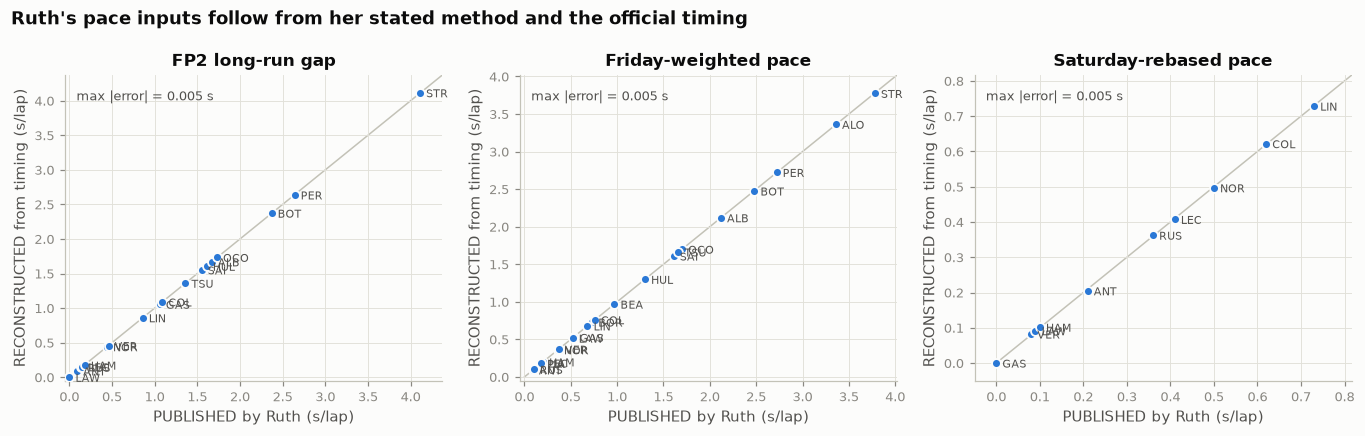

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.0))
panels = [("FP2 long-run gap", cmp_lr["gap s (PUBLISHED)"], cmp_lr["gap s (RECONSTRUCTED)"]),
          ("Friday-weighted pace", cmp_fw["FW (PUBLISHED)"], cmp_fw["FW (RECONSTRUCTED)"]),
          ("Saturday-rebased pace", sr_pub, sr_table.loc[sr_pub.index, "saturday_rebased_s"])]
for ax, (title, pub, rec) in zip(axes, panels):
    hi = max(pub.max(), rec.max()) * 1.05 + 0.05
    ax.plot([0, hi], [0, hi], color=AXIS, lw=1, zorder=1)
    ax.scatter(pub, rec, s=34, color=STRAT_COLOR["A"], edgecolor=SURFACE, linewidth=1.2, zorder=3)
    for d in pub.index:
        ax.annotate(d, (pub[d], rec.loc[d]), xytext=(4, -3), textcoords="offset points", fontsize=7, color=INK2)
    ax.set(title=title, xlabel="PUBLISHED by Ruth (s/lap)", ylabel="RECONSTRUCTED from timing (s/lap)",
           xlim=(-0.05, hi), ylim=(-0.05, hi))
    ax.text(0.03, 0.95, f"max |error| = {(pub - rec.loc[pub.index]).abs().max():.3f} s", transform=ax.transAxes,
            va="top", fontsize=8.5, color=INK2)
fig.suptitle("Ruth's pace inputs follow from her stated method and the official timing", fontweight="bold", x=0.01, ha="left")
fig.tight_layout(); save(fig, "04_pace_reproduction"); plt.show()

### 4.5 Comparing the two readings

The two readings disagree mainly about **Alpine (Gasly, Colapinto)** and **Red Bull (Verstappen, Lawson)**,
which are much faster on the Saturday reading, and about **Mercedes and Leclerc**, which are slower on it.

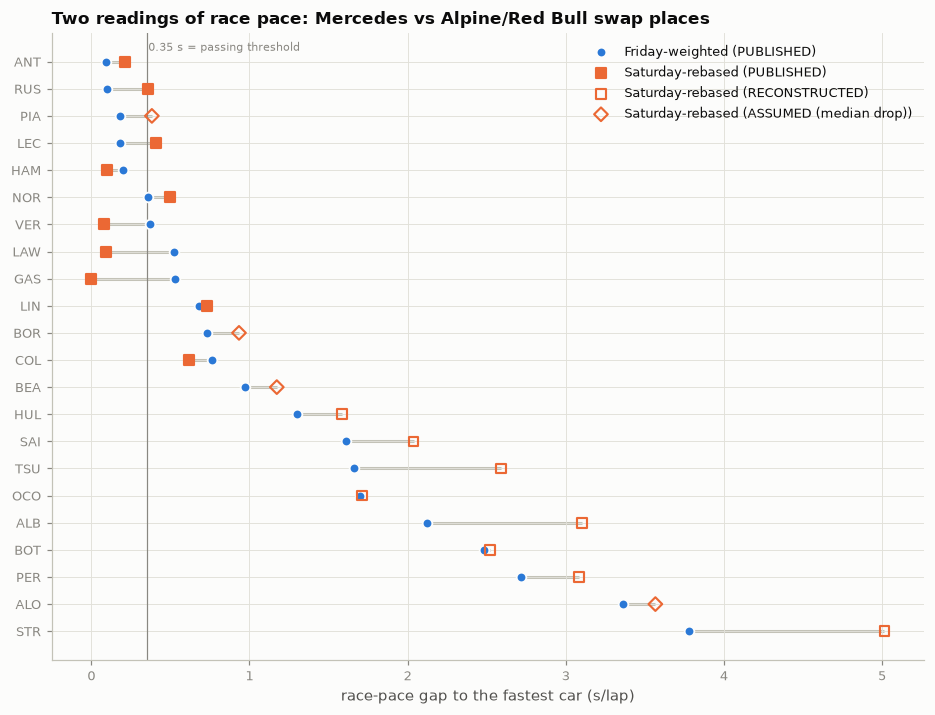

,ANT,RUS,GAS,VER,LAW,LEC,HAM,PIA,NOR
pace rank,,,,,,,,,
friday_weighted,1,2,9,7,8,3,5,3,6
saturday_rebased,5,6,1,2,3,8,4,7,9
blend_50_50,1,4,5,3,8,7,2,6,9
friday_weighted_independent,1,2,9,7,8,4,5,3,6


In [15]:
order = pace_df.index[::-1]
fig, ax = plt.subplots(figsize=(8.6, 6.6))
y = np.arange(len(order))
fw_v, sr_v = pace_df.loc[order, "friday_weighted"], pace_df.loc[order, "saturday_rebased"]
ax.hlines(y, np.minimum(fw_v, sr_v), np.maximum(fw_v, sr_v), color=AXIS, lw=2, zorder=1)
ax.scatter(fw_v, y, s=40, color=STRAT_COLOR["A"], marker="o", zorder=3, label="Friday-weighted (PUBLISHED)",
           edgecolor=SURFACE, linewidth=1.2)
status = pace_df.loc[order, "SR status"]
for st, mk, fc in [("PUBLISHED", "s", STRAT_COLOR["B"]), ("RECONSTRUCTED", "s", "none"),
                   ("ASSUMED (median drop)", "D", "none")]:
    sel = status == st
    ax.scatter(sr_v[sel], y[sel.to_numpy()], s=40, marker=mk, facecolor=fc, edgecolor=STRAT_COLOR["B"],
               linewidth=1.4, zorder=3, label=f"Saturday-rebased ({st})")
ax.set_yticks(y, order)
ax.set_xlabel("race-pace gap to the fastest car (s/lap)")
ax.set_title("Two readings of race pace: Mercedes vs Alpine/Red Bull swap places", loc="left")
ax.axvline(0.35, color=MUTED, lw=0.8)
ax.text(0.36, len(order) - 0.6, "0.35 s = passing threshold", fontsize=7.5, color=MUTED)
ax.legend(loc="upper right")
fig.tight_layout(); save(fig, "04_pace_readings"); plt.show()

ranks = pd.DataFrame({k: pd.Series(v).rank(method="min").astype(int) for k, v in PACE_SETS.items()
                      if not k.endswith("unrounded")})
display(ranks.loc[["ANT", "RUS", "GAS", "VER", "LAW", "LEC", "HAM", "PIA", "NOR"]].T.rename_axis("pace rank"))

### 4.6 Which reading did Ruth use for Antonelli?

The model description says *"pace per driver as above"*, and two readings appear above it. The evidence:

| Evidence | Points to |
|---|---|
| Image 2, the only complete 22-driver pace set, is printed directly beside the Antonelli analysis | Friday-weighted |
| *"Hard degradation flat after warm-up, as Friday's runs … say"* (Image 1 subtitle): Friday evidence is trusted for tyres | weakly Friday |
| *"On this reading [Friday] … Russell wins and Gasly finishes fifth (model)"*; *"On this one [Saturday] Gasly … wins from the front (model)"* | **both** readings were run through the model |
| Verstappen's plan A is *"the model's pick, P1 with no safety car"*: implausible on Friday pace (0.37 s, behind Russell's 0.10), plausible on Saturday pace (0.08 s) | the Verstappen section used Saturday (or a blend) |
| *"The truth is between the two"* | a blend is conceivable |

**Conclusion:** it is genuinely ambiguous. We do not guess silently. The **Friday-weighted** set is the
**baseline**, because it is the only complete published set and the one plotted with the Antonelli analysis.
**Saturday-rebased** and a **50/50 blend** are pre-registered alternatives (specified before any comparison with
Ruth's results) and are run on all 15 scenarios (§10.3). Unrounded variants of both readings are added to test rounding, together with an independent
extraction that does not apply the Bearman exception.

### 4.7 Limitations of the pace estimates

* **Fuel loads are unknown** (Ruth: *"the biggest unknown"*). The arithmetic above shows that five laps of fuel
  equals the passing threshold.
* **Compounds are mixed.** Ferrari's long runs were on softs and Mercedes' on hards, with no compound correction.
* **One number per driver** stands for the whole race: no driver-specific degradation, no thermal effects,
  although the article stresses rear overheating in 33 °C.
* **Rounding.** The published values have two decimals. Several pace *differences* are exactly 0.35 s, the passing
  threshold, so rounding alone can decide a pass (§10.4).
* **Degradation from Friday.** The same long runs can be used to estimate the hard's degradation; §10.2 shows
  why that estimate depends entirely on the assumed fuel effect.

---
## 5. Mathematical formulation

Each element below is presented in the same order:
1. **what** it represents;
2. **why** a strategy simulator needs it;
3. **where** its parameters come from;
4. **what it assumes**;
5. **what would happen** if it were omitted or changed;
6. where useful, a small numerical example.

Notation: car $i$, lap $k = 1,\dots,N$ with $N = 53$; $T_i(k)$ is the cumulative **elapsed** race time at the
end of lap $k$; $\kappa$ is a compound; $a$ is the tyre age in completed laps.

### 5.1 Lap-wise discretisation and elapsed race time

$$T_i(k) \;=\; T_i(k-1) \;+\; t_i(k) \;+\; L_i(k) \;+\; \epsilon_i(k), \qquad t_i(k) > 0,\; L_i(k) \ge 0,\; \epsilon_i(k) \ge 0,$$
$$\text{position}_i(k) = \operatorname{rank}_j\, T_j(k)$$

* **What:** the race is a sequence of laps. After each lap every car has an elapsed time, and running order is
  simply the ranking of those times. $t_i(k)$ is the lap time including traffic and Safety-Car effects;
  $L_i(k)$ is the pit loss charged at the end of an in-lap; $\epsilon_i(k)$ is the time a car loses backing off
  a car that has just rejoined from the pits.
* **Why:** this is Heilmeier's Eq. (1). Positions only need to be known at the line, so lap times are enough;
  no racing lines or track sectors are needed.
* **Every term is non-negative, so elapsed time can never decrease.**
* **Assumes:** what happens *inside* a lap matters only through its effect on the time at the line. All cars are
  compared over the same number of laps (a lapped car is not stopped at the leader's flag). Running
  order is race order: lap number first, then elapsed time, i.e. the order of *race distance*. A lapped car is
  simply a car far behind; under the Safety Car it is treated on the same race clock as everyone else (§5.12).

### 5.2 The clean-air lap time

$$t^{\text{clean}}_i(k) \;=\; t_{\text{ref}} \;+\; \Delta_i \;+\; \tau_{\kappa_i(k)}\big(a_i(k),\, w_i(k)\big) \;+\; f\,(N-k)$$

* **What:** the lap time car $i$ would do on an empty track: a reference lap, plus the car-and-driver pace gap,
  plus the tyre term, plus the fuel term. This is Heilmeier's Eq. (2), with $t_{base}+t_{car}+t_{driver}$
  collapsed into $t_{ref}+\Delta_i$, because Ruth's pace estimates combine car and driver.
* **Why:** every strategic trade-off (old vs new tyres, early vs late stops) is a comparison of clean-air lap
  times.
* **Parameters:** $t_{\text{ref}} = 84.0$ s (**ASSUMED**). In a race **without** a Safety Car it is a common
  offset that cancels in every position and gap (tested in §7). It does *not*
  cancel under a Safety Car: the Safety-Car and full-course-yellow lap times are multiples of it, and it sets how
  much of a lap a car still has to drive when the Safety Car comes out (§5.12). $\Delta_i$ comes from §4; $\tau$
  and $f$ are below.

### 5.3 The fuel term

$$t^{\text{fuel}}(k) = f\,(N-k), \qquad f = 0.07 \text{ s per lap of fuel (PUBLISHED)}$$

* **What:** the car is heavier at the start; each lap burns one lap of fuel, and the car gets 0.07 s quicker.
  This is Heilmeier's Eq. (6–7), with the mass sensitivity and per-lap consumption folded into one number.
* **Reference convention.** The term is measured *relative to the final lap*: lap 1 carries
  $52 \times 0.07 = 3.64$ s and lap 53 carries none. The physical fuel load at the start of lap $k$ is
  $N-k+1$ laps' worth, so the convention differs from it by the constant $f$. That constant is the same for
  every car and every lap, and cancels.
* **Key insight:** every car burns the same fuel on the same lap, so in a race **without** a Safety Car **this
  term is identical for all cars and cancels in every gap and position**. Setting $f=0$ or doubling it changes
  nothing there (tested in §7). Fuel matters in *pace estimation* (§4.7) and when *estimating degradation from
  practice* (§10.2). Under a Safety Car it is not exactly neutral: it lengthens every racing lap, so it
  changes how much of a lap a given time gap represents when the Safety Car comes out (a small effect).

### 5.4 The tyre term

$$\tau_\kappa(a, w) \;=\; o_\kappa \;+\; d_\kappa\, a \;+\; w_\kappa\,\mathbb{1}[w]$$

| compound | offset $o_\kappa$ (s) | degradation $d_\kappa$ (s/lap) | warm-up $w_\kappa$ (s) | life (laps) |
|---|---|---|---|---|
| Hard (C3) | 0 (reference) | 0.015 | 0.6 | 52 |
| Medium (C4) | −0.20 | 0.05 | 0 (ASSUMED) | 46 |
| Soft (C5) | −0.35 | 0.10 | 0 (ASSUMED) | 9 |

* **What:**
  - $o_\kappa$: a new tyre's speed relative to a new hard;
  - $d_\kappa\,a$: a linear loss with age;
  - $w_\kappa\,\mathbb{1}[w]$: the hard's *"needs a lap to come in"* penalty, paid on the set's warm-up lap.
* **Why:** this trade-off between a compound's initial speed and its degradation is the *performance* reason to
  stop, and what makes the undercut possible. It is not the only reason: FIA B6.3.6 requires
  two dry specifications, so every car must stop at least once in a dry race. Safety Cars also change the price
  of stopping (§5.12).
* **Parameters:** the offsets, degradation and warm-up are PUBLISHED. Heilmeier's linear form (their Eq. 5) is
  the one they recommend when data are scarce.
* **Warm-up policy.** The warm-up lap is the **first green-flag lap** driven on a newly fitted set: a lap that
  *starts* at racing speed on the shared race clock (before the deployment or after the restart). A hard fitted
  under the Safety Car is driven only at queue speed, which does not bring it up to temperature, so its warm-up
  is paid at the restart instead of disappearing into a neutralised lap. A lap interrupted by the deployment
  pays the warm-up on the part driven at racing speed and consumes it. Starting sets are warmed by the formation
  lap (no penalty on lap 1). Both choices are ASSUMED; the alternative is tested in §10.
* **Assumes:** linear degradation, with no cliff and no thermal effects; every driver degrades the same way;
  starting sets are new.
* **Example.** A medium at age 4 costs $-0.20 + 4 \times 0.05 = 0.00$ s, the same as a new
  hard. A medium and a hard **of the same age** differ by $-0.20 + 0.035a$. That is negative for ages 0–5, so
  the medium is quicker for the **first six laps** of a stint, and slower from the **seventh** (age 6:
  $+0.01$ s).
* **If changed:** Ruth's own sensitivity test raises the hard's degradation to 0.05 s/lap (§10.1). This is the
  parameter her argument rests on.

The closed form gives the **pure tyre cost** without simulating anything. For a one-stop race starting on
compound $\kappa_1$ and switching after in-lap $L$ to $\kappa_2$:

$$C(L) \;=\; \sum_{a=0}^{L-1}\big(o_{\kappa_1} + d_{\kappa_1}a\big) \;+\; \sum_{a=0}^{N-L-1}\big(o_{\kappa_2} + d_{\kappa_2}a\big) \;+\; w_{\kappa_2}$$

The cell below evaluates it. These are **analytic expectations, computed independently of the simulator**; §7
checks that the simulator reproduces them.

,pure tyre cost over 53 laps (s)
"A: M 1 lap, H 52 laps",20.29
"B: H 36 laps, M 17 laps",12.85
"C: M 20 laps, H 33 laps",14.02
"field leader: M 24, H 29",15.69
"field tail: M 14, H 39",13.46


Optimal medium->hard in-lap in clean air: lap 16 (cost 13.39 s)


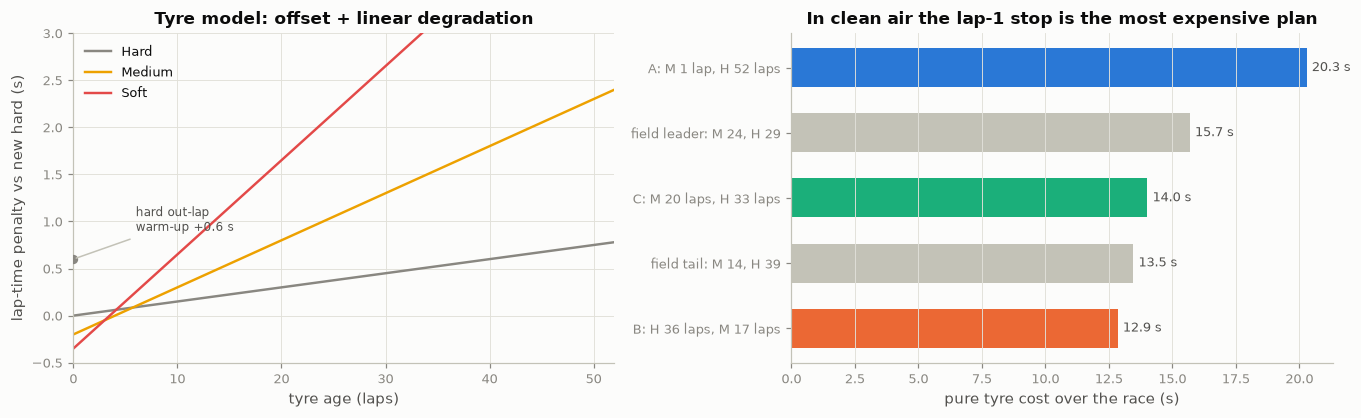

In [16]:
N = 53
TYRE = {"HARD": (0.0, 0.015, 0.6), "MEDIUM": (-0.20, 0.05, 0.0), "SOFT": (-0.35, 0.10, 0.0)}  # (o, d, w)


def stint_cost(compound: str, laps: int, fitted_in_pit: bool) -> float:
    o, d, w = TYRE[compound]
    return laps * o + d * laps * (laps - 1) / 2 + (w if fitted_in_pit else 0.0)


def one_stop_cost(start: str, in_lap: int, to: str) -> float:
    return stint_cost(start, in_lap, False) + stint_cost(to, N - in_lap, True)


plans = {"A: M 1 lap, H 52 laps": ("MEDIUM", 1, "HARD"), "B: H 36 laps, M 17 laps": ("HARD", 36, "MEDIUM"),
         "C: M 20 laps, H 33 laps": ("MEDIUM", 20, "HARD"), "field leader: M 24, H 29": ("MEDIUM", 24, "HARD"),
         "field tail: M 14, H 39": ("MEDIUM", 14, "HARD")}
costs = pd.Series({k: one_stop_cost(*v) for k, v in plans.items()}, name="pure tyre cost over 53 laps (s)")
display(costs.round(2).to_frame())
best_L = min(range(1, N), key=lambda L: one_stop_cost("MEDIUM", L, "HARD"))
print(f"Optimal medium->hard in-lap in clean air: lap {best_L} (cost {one_stop_cost('MEDIUM', best_L, 'HARD'):.2f} s)")

ages = np.arange(0, 53)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9))
for comp, (o, d, w) in TYRE.items():
    axes[0].plot(ages, o + d * ages, color=COMPOUND_COLOR[comp] if comp != "HARD" else MUTED, label=comp.title())
axes[0].scatter([0], [0.6], color=MUTED, s=26, zorder=3)
axes[0].annotate("hard out-lap\nwarm-up +0.6 s", (0, 0.6), xytext=(6, 0.9), fontsize=8, color=INK2,
                 arrowprops=dict(arrowstyle="-", color=AXIS))
axes[0].set(xlim=(0, 52), ylim=(-0.5, 3.0), xlabel="tyre age (laps)", ylabel="lap-time penalty vs new hard (s)",
            title="Tyre model: offset + linear degradation")
axes[0].legend(loc="upper left")
bars = costs.sort_values()
axes[1].barh(bars.index, bars.values, color=[STRAT_COLOR[k[0]] if k[0] in "ABC" else AXIS for k in bars.index],
             height=0.6)
for yv, v in enumerate(bars.values):
    axes[1].text(v + 0.2, yv, f"{v:.1f} s", va="center", fontsize=8.5, color=INK2)
axes[1].set(xlabel="pure tyre cost over the race (s)", title="In clean air the lap-1 stop is the most expensive plan")
axes[1].grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "05_tyre_model"); plt.show()

**What the numbers say.**
- In clean air the lap-1 stop (A) costs about **7 s more** tyre time than the hard start (B), because 52 laps
  on one hard accumulate $0.015 \times \sum_{a=0}^{51} a = 0.015 \times 1326 \approx 19.9$ s.
- The clean-air optimum for medium → hard is around lap 16.
- **A can only work through traffic:** running in clean air while the field sits in dirty-air trains, and
  jumping the field when it pits. This is Ruth's argument, so the traffic terms below are not details; they are
  the mechanism.

### 5.5 Car pace $\Delta_i$

A constant per-lap gap to the fastest car, taken from §4 (baseline: Friday-weighted). **Assumes** pace is the
same on every compound and does not change with fuel or temperature. **If changed:** §10.3 swaps the vector.

### 5.6 Starting offsets

$$T_i(0) = (s_i - 1)\, g_{\text{grid}}, \qquad T_{\text{ANT}}(0) = (22-1)\, g_{\text{grid}} + \delta_{\text{pit}},
\qquad g_{\text{grid}} \ge 0,\;\; \delta_{\text{pit}} \ge 0$$
$$\text{optional lap-1 loss: } \ell_i = (s_i - 1)\, g_{\text{lap1}} \quad(\text{slot 22 for the pit-lane starter; } g_{\text{lap1}} = 0 \text{ in the baseline})$$

* **What:** the elapsed time at which a car first crosses the start line. $s_i$ is the grid slot. The
  start has three separate components, each validated to be non-negative:
  1. the **grid headway** $g_{\text{grid}}$ per slot (baseline 0.117 s);
  2. the pit-lane starter's **release delay** $\delta_{\text{pit}}$ after the last grid slot (PUBLISHED: 6 s behind
     P22). It cannot be negative: a pit-lane starter is released only after the whole grid has passed;
  3. an optional **lap-1 time loss** per grid slot, TUM's own representation of the grid effect, added to lap 1
     like dirty air. It is zero in the baseline, which represents the same effect as a headway (using both
     would count it twice). It is a sensitivity in §10.7.
* **Parameter (ASSUMED conversion):** $g_{\text{grid}} = 0.117$ s. TUM fitted this value for Monza as a
  first-lap **time loss** per grid position, added to lap 1; we use it as a starting **headway**.
  - The two give the same end-of-lap-1 times only without interactions.
  - With our time-feasible passing rule they differ only through lap-1 dirty air: with TUM's form every car
    starts within 2 s, Antonelli included, while with headways he starts 8.5 s behind.
  - The resulting end-of-lap-1 spread is checked against Monza 2023–2025 in §7.3.
* **Not validated:** the 6 s pit-lane gap (no Monza pit-lane starter in 2023–2025). Its effect is isolated in
  §10.7 by changing *only* Antonelli's release delay.
* **If changed:** Antonelli's deficit when an early Safety Car comes decides how much of the field he gains
  when everyone else stops (§10.7).

### 5.7 Dirty air

$$t^{\text{eff}}_i(k) = t^{\text{clean}}_i(k) + 0.25\;\mathbb{1}\!\left[\,T_i(k-1) - T_{i^-}(k-1) \le 2.0\,\right]$$

* **What:** a car within 2 s of the car directly ahead ($i^-$) at the start of the lap loses 0.25 s (*"nobody's
  dirty air cooking your rears in 33 °C"*).
* **Why:** it creates the value of **clean air**, half of the lap-1-stop argument.
* **Parameters:** 0.25 s and 2 s are PUBLISHED. Measuring on the start-of-lap gap is ASSUMED.
* **If omitted:** trains become free, and the lap-1 stop loses part of its case (§10.4).

### 5.8 Overtaking: who may pass, and when the pass happens

Let $j$ be the car directly ahead of car $i$. Let $\hat T_i = T_i(k-1) + t^{\text{eff}}_i(k)$ be $i$'s
projected end-of-lap time, and $T_j(k)$ the car ahead's final time.

**Who may pass (PUBLISHED rule):**
$$\text{eligible}_{ij} \iff \min\!\big(T_i(k-1) - T_j(k-1),\; \hat T_i - T_j(k)\big) \le 1.2 \;\wedge\; t^{\text{clean}}_j(k) - t^{\text{clean}}_i(k) \ge 0.35$$

**When the pass happens (ASSUMED):**
$$\text{pass} \iff \text{eligible}_{ij} \;\wedge\; \hat T_i < T_j(k)$$

* **What:** an eligible car is never held up, but it takes the position only when its **own elapsed time is
  earlier**. Nobody's time is changed by the pass. This is how Heilmeier et al. decide overtakes: by comparing
  race times after the lap (they add a track-specific margin and a DRS gain, which Ruth's model does not have).
* **Why not an instant pass?** An instant-pass reading declares the pass as soon as the attacker is eligible and
  then **pushes the passed car back** behind the attacker. In a two-car example, a car 1.0 s behind and 0.4 s/lap
  faster projects to 90.85 s against the leader's 90.0 s; an instant pass would still be declared and the
  leader delayed to 91.35 s. That is an order change the elapsed times do not support, paid for by an arbitrary
  time loss of the passed car (§7.2 shows it).
* **Consequence (made explicit).** With time feasibility, Ruth's 1.2 s window is implied: a car that crosses
  during the lap was necessarily within 1.2 s. Passing therefore takes time: an attacker 0.40 s/lap faster in
  dirty air closes only 0.15 s/lap. Both instant-pass interpretations ("passed car yields" and
  "passer jumps", a tow gain for the attacker) are kept as sensitivities (§10.4), with optional duel losses
  (TUM Monza: 0.3 s each, +0.3 s for the passed car).
* **"Faster"** compares the two cars' intrinsic clean-air lap times (pace + tyres + fuel), not their
  traffic-affected times (ASSUMED; the alternative is in §10.4).
* **Example:** Antonelli (0.09) behind Norris (0.36) on equal tyres is 0.27 s faster: not eligible, ever,
  unless the tyres differ. Behind Stroll (3.78) he passes as soon as his elapsed time crosses Stroll's.

### 5.9 Being held up

$$T_i(k) = \max\!\left\{\, \hat T_i,\;\; T_j(k) + g_{\min} \right\} \quad\text{if } i \text{ is not eligible to pass } j, \qquad g_{\min} = 0.5 \text{ s}$$

* **What:** a car that may not pass *"sits at the pace of the car ahead"* (PUBLISHED rule) at the minimum
  following distance. That distance is not published; 0.5 s is TUM's fitted Monza value (evidence).
* **Why:** without it a slower car would be driven through, and track position would be worth nothing.
* **Example:** a train behind a slow car. Every car laps at that car's pace, 0.5 s apart.
* An eligible attacker may run closer than 0.5 s; a car that has just been passed may briefly be closer than
  0.5 s to its passer. Both are allowed and flagged in the lap records.
* **Blocked alongside.** An eligible attacker that beats its target's time but is then held by the car in front
  of both does **not** get the pass. It ends the lap alongside its target (gap 0, order unchanged), because a
  pass must leave it strictly earlier in time (tested in `test_traffic.py`).

### 5.10 Pit stops

$$L_i(k) = \begin{cases} 11\ \text{s} & \text{if car } i \text{ ends its in-lap } k \text{ at a race time } T \in [t_d, t_r) \text{ (Safety Car out)} \\ 22\ \text{s} & \text{otherwise} \end{cases}
\qquad \kappa_i(k+1) = \kappa', \;\; a_i(k+1) = 0,\;\; \text{warm-up due}$$

* **What:** the whole pit-lane time loss is added once, at the end of the in-lap, and the new set runs from the
  next lap (Heilmeier's Fig. 5 device). Values PUBLISHED; TUM's Monza files give about 22.6 s.
* **Price from the race clock.** Pit entry is at the line in this model, so the price depends on *when* the
  car reaches the line, not on the lap number. For the car directly behind the Safety Car this gives exactly
  laps $N, N+1, N+2$; a lapped car may get its cheap stop on a different lap number, and a
  car still on lap $N+2$ after the restart pays the green price. The price is fixed at pit entry.
* After the stops, a car that rejoins less than 0.5 s from another car is spaced to 0.5 s ($\epsilon \ge 0$).
  Only pairs involving a car that rejoined are checked, so a car legitimately attacking closer than 0.5 s on track
  is not pushed back.
* **Example (the undercut):** a car on a 20-lap-old medium pays $-0.20 + 20 \times 0.05 = 0.80$ s per lap; a
  fresh hard pays 0.60 s on its warm-up lap and then 0.015 s. Stopping first gains about 0.2 s on the out-lap and
  about 0.8 s on each following lap.
* **No double counting:** the loss is charged only to the in-lap (tested).

### 5.11 Ruth's Safety-Car pit rule

$$\text{cheap stop at the end of lap } k \iff T_i^{\text{line}}(k) \in [t_d, t_r) \;\wedge\; \text{no stop yet} \;\wedge\; N - k \le \ell_{\kappa'}$$

* **What (PUBLISHED):** *"anyone yet to stop takes the cheap one if their next compound can reach the flag"*.
  "Reach" means the remaining laps are within the next compound's life $\ell$ (§3.6).
* The rule is checked at **every** cheap-stop opportunity, i.e. every line crossing of the car inside the window,
  and the car stops at the first one at which it is eligible. A narrower reading (only the car's first crossing
  inside the window) is tested as a sensitivity; Ruth's text does not say which she meant.
* **Example:** Safety Car on lap 5, Antonelli on hards planning mediums on lap 36, medium life 46 laps. Laps
  left after laps 5/6/7 are 48/47/46, so he is first eligible at the end of **lap 7**, still inside the
  window: an 11 s stop on lap 7, then 46 laps on mediums. Under the narrower reading he would not stop cheaply
  and would pay 22 s on lap 36.

### 5.12 The Safety Car on a shared race clock

**Why a shared clock.** When the Safety Car comes out, the field is spread around the lap and over several lap
numbers: the leader may be completing lap 35 while a lapped car is still on lap 34. The neutralisation therefore
has to be applied by *race time*, not by lap number. Assigning it by lap number would let a car more than a lap
behind keep racing after the deployment and drive at Safety-Car pace after the restart.

**One clock for the whole field.** With $L_{sc} = 1.6\,t_{ref} = 134.4$ s, $L_{fcy} = 1.4\,t_{ref} =
117.6$ s, $D = 3$:

$$t_d = \min_i T^{\text{line}}_i(N) \quad\text{(the leader completes lap } N\text{)}, \qquad t_r = t_d + D\,L_{sc}, \qquad W = [t_d, t_r)$$

The Safety Car joins at the line in front of the leader at $t_d$, completes lap $N+j$ at $t_d + j\,L_{sc}$ and pulls
in at $t_r$; the whole field is released at $t_r$. Every car-lap $[S, E]$ is cut at $t_d$ and $t_r$ **by the time at
which it is actually driven**:

| part of the lap | pace | interactions |
|---|---|---|
| before $t_d$ | the car's own racing pace (traffic as in §5.7–5.9) | a pass stands only if it was **complete at $t_d$** |
| inside $W$ | full-course-yellow pace $L_{fcy}$, the same for every car (the FIA delta is not car-specific) | no overtaking; nobody completes lap $N+j$ before the Safety Car; on laps that **start** inside $W$, at least one queue spacing behind the car ahead |
| after $t_r$ | racing pace | no overtaking until the line (restart lap); racing from the next lap |

Within a lap, progress is uniform in time at the pace in force (every car's speed profile is a scaled copy of
the same lap, so a fraction of the lap time is a fraction of the distance). For a lap that is still running at
$t_d$, with racing end $\hat E$, the remaining fraction is $(\hat E - t_d)/(\hat E - S)$ and

$$E = t_d + \frac{\hat E - t_d}{\hat E - S}\,L_{fcy}.$$

For a lap that starts inside the window: $E = S + L_{fcy}$ if that is before $t_r$; otherwise
$E = t_r + \big(1 - \tfrac{t_r - S}{L_{fcy}}\big)\,t^{\text{clean}}$. Then, at the line,

$$E \;\ge\; \max\Big\{\,t_d + (k-N)\,L_{sc}\ \ (\text{Safety Car, } N<k\le N+D),\;\; E_{\text{ahead}} + g(E_{\text{ahead}})\Big\},$$

where $g$ is the time the car ahead needs to cover **one minimum following distance**: 0.8 s at Safety-Car pace
(the queue gap) and 0.5 s at racing pace. These are the same distance ($0.8/134.4 = 0.5/84$ of a lap), and $g$
is interpolated when the car ahead changes pace within that distance of $t_r$.

* **Queue formation by finite catch-up.** A car not yet in the queue gains on the Safety Car
  $1/L_{fcy} - 1/L_{sc}$ laps per second. Over the whole window that is
  $403.2 \times (1/117.6 - 1/134.4) = 3/7$ of a lap, **36.0 s at 84 s/lap**. A car more than about 36 s
  behind the car ahead in race distance when the Safety Car comes out never joins the queue, *whatever lap it is
  on*. §7.4 works this through with numbers.
* **The lap cut by the deployment.** Every car drives the rest of it at the same pace, so distances, and the
  order at $t_d$, are kept: nobody closes in and nobody is pushed back. The queue spacing is applied from the
  first lap that starts behind the Safety Car, so the queue forms during that lap.
* **Restart.** At $t_r$ every car returns to racing pace together. Distances are kept, so the queue's 0.8 s
  gaps at Safety-Car pace become about 0.5 s at racing pace. This restart spacing matters for Antonelli with a
  lap-1 Safety Car (§8.4, §10.7).
* **Lapped cars.** FIA B5.13.4c lets the Race Director *allow* lapped cars to pass the lead-lap cars and the
  Safety Car and rejoin the back of the queue. Ordering the queue by race distance corresponds to that procedure
  having been used. Neither the Race Director's decision nor the manoeuvre itself is simulated.
* **A fixed three-lap Safety Car (Ruth's).** FIA B5.13.5a keeps the Safety Car out "at least until … all remaining
  F1 Cars are queued". With a fixed $D = 3$, a car more than 36 s behind the car ahead restarts *without*
  having reached the queue (§7.4). That follows Ruth's specification, not the regulations.
* **Pit stops** are priced by the race time at which the in-lap ends (§5.10); a car that stops inside the
  window rejoins and catches the queue again. Alone on track, it loses nothing: it catches the Safety Car
  within a lap.
* **What is assumed, not derived:**
  - the deployment instant (the leader's line crossing);
  - uniform progress within a lap;
  - checking interactions only at the line;
  - a common restart instant;
  - the 1.6 / 1.4 lap factors and the 0.8 s queue gap (TUM 2014–2019 fits).

### 5.13 Result

$$\text{gap to winner} = T_{\text{ANT}}(N) - \min_i T_i(N), \qquad \text{position} = \operatorname{rank}\,T_{\text{ANT}}(N)$$

### 5.14 Order of events within one lap

0. Before the race: $t_d$ is computed by running the same engine without a Safety Car up to lap $N$ (everything
   before $t_d$ is green, so this is exact; the main run checks that its own first completion of lap $N$ equals it).
1. Start-of-lap order = cars sorted by $T(k-1)$ (ties keep the previous order). Front to back the field splits
   into cars whose lap starts **before $t_d$**, **inside the window**, and **after $t_r$**.
2. Cars starting before $t_d$ or after $t_r$: compute $t^{\text{clean}}$ (with any warm-up that is due), add dirty air
   from the start-of-lap gaps, and resolve front to back (§5.8–5.9). A lap still running at $t_d$ is cut there
   (§5.12). Cars starting inside the window: full-course-yellow pace, the Safety Car's line times, one queue
   spacing; racing pace after $t_r$ without overtaking. A car racing after $t_r$ may not pass a car still on its
   restart lap.
3. Every tyre ages by one lap; a lap that started at racing speed consumes any warm-up that was due.
4. End-of-lap pit stops (planned, or Ruth's Safety-Car rule), priced by the race time of the line crossing.
5. Re-order by elapsed time; space cars that rejoined from the pits.
6. Record the lap, including its start and line-crossing times and the seconds spent inside the window.

---
## 6. Simulator implementation

The simulator is a small Python package, `racesim/`, written cell by cell below with `%%writefile`. Each module
does one job:

| Module | Job | Section |
|---|---|---|
| `config.py` | load the YAML into a `ModelSpec`: parameters **and** every operative choice (strategies, field plan, pace sets, Safety-Car scenarios) and the validated fixed choices; reject unsupported values; fingerprints of the effective specification and of the code | 6.1 |
| `strategies.py` | `Strategy` / `Entry` objects; the field's pit-lap assignment | 6.2 |
| `lap_model.py` | clean-air lap time (§5.2–5.4) | 6.3 |
| `traffic.py` | dirty air, eligibility, time-feasible passing, being held, spacing after pit stops (§5.7–5.10) | 6.4 |
| `safety_car.py` | the Safety-Car window on the race clock, lap integration through it, the following gap, lap labels (§5.11–5.12) | 6.5 |
| `engine.py` | the lap loop (§5.14) on the shared race clock, logging, classification | 6.6 |
| `scenarios.py` | assemble the 22-car field from the specification; run the 3 × 5 matrix | 6.7 |
| `pace.py` | race-pace estimators and the degradation fit (written in §4) | 4 |

**Alternative readings.** Several modelling choices have a second plausible reading, kept as a sensitivity
option and used only in §10:
- `pass_resolution="passed_car_yields"` or `"passer_jumps"` (instant passes);
- `warmup_policy="first_lap_of_stint"`;
- `sc_eligibility="deployment_lap_only"`;
- `sc_deployment_remainder="own_lap_scaled"`;
- a lap-1 grid loss instead of a starting headway (`grid_lap1_loss_per_slot_s`).

Everything is **deterministic**; the only random numbers in the notebook are the seeded random permutations
of the field's pit laps in §10.5.

### 6.1 Configuration: `config.py`

`load_spec` turns the YAML register into a frozen `ModelSpec`. It holds the numerical `RaceParams` and every
operative modelling choice:
- the target car;
- its three strategies and its pit-lane start;
- the field's compounds, pit window and pit-lap assignment rule;
- the baseline and alternative pace sets;
- the Safety-Car scenarios.

Other notes:
- `variant()` returns a modified *copy* of the parameters, so the baseline cannot be altered by accident; the
  compound table is read-only (`MappingProxyType`).
- `effective_fingerprint()` hashes everything the simulator consumes: specification, pace vector, field pit
  laps and grid. A comment edit therefore does not change it, while any behavioural change does.
- `code_fingerprint()` hashes the simulator's source.
- Every YAML entry is either *operative* or *fixed*. A fixed entry (for example
  `safety_car.deployment_instant`) is read and validated: the code implements exactly one value and rejects
  any other instead of ignoring it. `validate_params()` also rejects unknown switch values, negative start
  components and combinations the engine does not implement, also for variants made in code.

In [17]:
%%writefile racesim/config.py
"""Load the YAML assumption register into typed, immutable model objects.

The YAML file stores every parameter as {value, status, source, note} (optionally `role`). `load_spec` turns it
into a `ModelSpec`: the numerical `RaceParams` *and* every operative modelling choice (the three Antonelli
strategies, the field's compounds, pit window and pit-lap assignment rule, the pace sets and the Safety-Car
scenarios). Nothing that changes simulator behaviour is hard-coded elsewhere, so the fingerprint of the effective
specification (`effective_fingerprint`) covers everything the simulator actually uses.

Every YAML entry is either OPERATIVE (read and used) or FIXED (`role: fixed`): read and validated, with any value
other than the one the code implements rejected. `validate_params` also rejects unknown switch values and
parameter values the engine does not support, so a variant can never be silently ignored.
"""
from __future__ import annotations

import dataclasses
import hashlib
import json
from dataclasses import dataclass
from pathlib import Path
from types import MappingProxyType
from typing import Any, Mapping

import pandas as pd
import yaml

from .strategies import PitStop, Strategy

# Pace sets the notebook can build from the data (section 4); configuration names are checked against this list.
KNOWN_PACE_SETS = ("friday_weighted", "saturday_rebased", "blend_50_50", "friday_weighted_unrounded",
                   "saturday_rebased_unrounded", "friday_weighted_independent")

# FIXED choices: the only value each key may take, because it is the only behaviour the code implements.
FIXED_CHOICES = {
    "safety_car.model": "global_timeline",                 # Safety Car on the shared race clock (safety_car.py)
    "tyres.starting_sets_new": True,                       # every car starts on a new set (age 0)
    "start.pit_lane_starter_slot_left_empty": True,        # published grid used unchanged; P20 stays empty
    "safety_car.deployment_instant": "leader_completes_lap_N",
    "pace.long_run_filter": "symmetric_2pct_green_only",   # data pipeline of notebook section 4
    "pace.bearman_exception": "source_matching",           # data pipeline of notebook section 4
}

_ALLOWED = {
    "sc_eligibility": ("every_cheap_lap", "deployment_lap_only"),
    "warmup_policy": ("first_green_lap", "first_lap_of_stint"),
    "pass_resolution": ("time_crossing", "passed_car_yields", "passer_jumps"),
    "pass_proximity": ("any_point_in_lap", "start_of_lap"),
    "pass_basis": ("intrinsic", "actual"),
    "sc_deployment_remainder": ("fcy_lap", "own_lap_scaled"),
}


@dataclass(frozen=True)
class Compound:
    """A dry tyre compound. All times are seconds relative to a NEW hard tyre."""
    name: str
    offset_s: float        # pace of a new set relative to a new hard (negative = faster)
    deg_s_per_lap: float   # linear time loss per lap of tyre age
    warmup_s: float        # extra time on the warm-up lap of a set fitted at a pit stop
    max_life_laps: int     # longest stint allowed (used by the Safety-Car pit rule)


@dataclass(frozen=True)
class RaceParams:
    """Every number and switch the race engine uses. Frozen: variants are made with `variant()`."""
    total_laps: int
    reference_lap_s: float
    sc_lap_factor: float           # queue (Safety-Car) lap = factor x reference lap
    fcy_lap_factor: float          # full-course-yellow (catch-up) lap = factor x reference lap
    fuel_s_per_lap: float
    compounds: Mapping[str, Compound]
    warmup_at_race_start: bool
    warmup_policy: str             # "first_green_lap" (baseline) | "first_lap_of_stint" (sensitivity)
    pit_loss_green_s: float
    pit_loss_sc_s: float
    dirty_air_window_s: float
    dirty_air_penalty_s: float
    pass_window_s: float
    pass_proximity: str            # "any_point_in_lap" | "start_of_lap"
    pass_min_advantage_s: float
    pass_basis: str                # "intrinsic" | "actual"
    pass_resolution: str           # "time_crossing" (baseline) | "passed_car_yields" | "passer_jumps" (sensitivities)
    duel_loss_attacker_s: float
    duel_loss_defender_s: float
    min_follow_gap_s: float
    tol: float
    grid_slot_gap_s: float         # starting HEADWAY per grid slot (elapsed time at the start line)
    pit_lane_start_gap_s: float    # pit-lane RELEASE DELAY after the last grid slot (>= 0)
    grid_lap1_loss_per_slot_s: float  # lap-1 TIME LOSS per grid slot (TUM's form); 0 = not used
    sc_duration_laps: int
    sc_eligibility: str            # "every_cheap_lap" (baseline) | "deployment_lap_only" (sensitivity)
    sc_queue_gap_s: float
    sc_opportunistic_stops: bool
    sc_deployment_remainder: str   # "fcy_lap" (baseline) | "own_lap_scaled": factor x own racing time (sensitivity)

    @property
    def sc_lap_s(self) -> float:
        """Lap time of the Safety Car (and of the car directly behind it)."""
        return self.sc_lap_factor * self.reference_lap_s

    @property
    def fcy_lap_s(self) -> float:
        """Lap time at the full-course-yellow delta pace: the fastest any car may lap while neutralised."""
        return self.fcy_lap_factor * self.reference_lap_s


def validate_params(p: RaceParams) -> RaceParams:
    """Reject unknown switch values and parameter combinations the engine does not implement."""
    for name, allowed in _ALLOWED.items():
        if getattr(p, name) not in allowed:
            raise ValueError(f"{name}={getattr(p, name)!r} is not supported; allowed: {allowed}")
    for name in ("grid_slot_gap_s", "pit_lane_start_gap_s", "grid_lap1_loss_per_slot_s", "min_follow_gap_s",
                 "sc_queue_gap_s", "pit_loss_green_s", "pit_loss_sc_s", "duel_loss_attacker_s",
                 "duel_loss_defender_s", "dirty_air_penalty_s"):
        if getattr(p, name) < 0:
            raise ValueError(f"{name}={getattr(p, name)} is negative: not a physical value of this model")
    if p.sc_duration_laps < 1 or p.sc_lap_factor <= 1 or p.fcy_lap_factor <= 1:
        raise ValueError("Safety-Car duration must be >= 1 lap and both neutralised lap factors > 1")
    return p


@dataclass(frozen=True)
class FieldPolicy:
    """How the 21 other cars race: one stop, start compound -> next compound, inside a pit window."""
    start_compound: str
    next_compound: str
    window: tuple[int, int]
    assignment: str                # see strategies.field_pit_laps


@dataclass(frozen=True)
class ModelSpec:
    """The complete effective model: parameters plus every operative modelling choice."""
    spec_id: str
    params: RaceParams
    target: str
    target_pit_lane_start: bool
    strategies: Mapping[str, Strategy]
    field: FieldPolicy
    pace_set: str
    sc_laps: tuple[int | None, ...]
    alternative_pace_sets: tuple[str, ...] = ()
    fixed: Mapping[str, Any] = dataclasses.field(default_factory=lambda: MappingProxyType({}))

    def with_params(self, params: RaceParams) -> "ModelSpec":
        return dataclasses.replace(self, params=validate_params(params))

    def with_strategies(self, strategies: Mapping[str, Strategy]) -> "ModelSpec":
        return dataclasses.replace(self, strategies=MappingProxyType(dict(strategies)))


def _get(node: dict[str, Any], key: str) -> Any:
    """Value of a {value, status, source, note} record."""
    if key not in node:
        raise KeyError(f"configuration key {key!r} is missing")
    return node[key]["value"]


def load_raw(path: str | Path) -> dict[str, Any]:
    with open(path, encoding="utf-8") as fh:
        return yaml.safe_load(fh)


def config_fingerprint(path: str | Path) -> str:
    """SHA-256 of the configuration file bytes (says nothing about *when* the file was written)."""
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def _params(raw: dict[str, Any]) -> RaceParams:
    t, tr, sc, st = raw["tyres"], raw["traffic"], raw["safety_car"], raw["start"]
    compounds = MappingProxyType({
        name: Compound(name=name, offset_s=_get(t[name], "offset_s"), deg_s_per_lap=_get(t[name], "deg_s_per_lap"),
                       warmup_s=_get(t[name], "warmup_s"), max_life_laps=_get(t[name], "max_life_laps"))
        for name in ("HARD", "MEDIUM", "SOFT")})
    return validate_params(RaceParams(
        total_laps=_get(raw["race"], "total_laps"),
        reference_lap_s=_get(raw["race"], "reference_lap_time_s"),
        sc_lap_factor=_get(raw["race"], "sc_lap_time_factor"),
        fcy_lap_factor=_get(raw["race"], "fcy_lap_time_factor"),
        fuel_s_per_lap=_get(raw["fuel"], "effect_s_per_lap"),
        compounds=compounds,
        warmup_at_race_start=_get(t, "warmup_at_race_start"),
        warmup_policy=_get(t, "warmup_policy"),
        pit_loss_green_s=_get(raw["pit"], "loss_green_s"),
        pit_loss_sc_s=_get(raw["pit"], "loss_safety_car_s"),
        dirty_air_window_s=_get(tr, "dirty_air_window_s"),
        dirty_air_penalty_s=_get(tr, "dirty_air_penalty_s"),
        pass_window_s=_get(tr, "pass_window_s"),
        pass_proximity=_get(tr, "pass_proximity_measure"),
        pass_min_advantage_s=_get(tr, "pass_min_advantage_s"),
        pass_basis=_get(tr, "pass_advantage_basis"),
        pass_resolution=_get(tr, "pass_resolution"),
        duel_loss_attacker_s=_get(tr, "duel_loss_attacker_s"),
        duel_loss_defender_s=_get(tr, "duel_loss_defender_s"),
        min_follow_gap_s=_get(tr, "min_follow_gap_s"),
        tol=_get(tr, "decision_tolerance_s"),
        grid_slot_gap_s=_get(st, "grid_slot_gap_s"),
        pit_lane_start_gap_s=_get(st, "pit_lane_start_gap_s"),
        grid_lap1_loss_per_slot_s=_get(st, "grid_lap1_loss_per_slot_s"),
        sc_duration_laps=_get(sc, "duration_laps"),
        sc_eligibility=_get(sc, "eligibility"),
        sc_queue_gap_s=_get(sc, "queue_gap_s"),
        sc_opportunistic_stops=_get(sc, "opportunistic_stops"),
        sc_deployment_remainder=_get(sc, "deployment_remainder_pace"),
    ))


def load_params(path: str | Path) -> RaceParams:
    return _params(load_raw(path))


def _fixed(raw: dict[str, Any]) -> dict[str, Any]:
    """Read every FIXED choice and reject any value other than the implemented one."""
    out = {}
    for dotted, required in FIXED_CHOICES.items():
        section, key = dotted.split(".")
        value = _get(raw[section], key)
        if value != required:
            raise ValueError(f"{dotted}={value!r} is not implemented; the only supported value is {required!r}")
        out[dotted] = value
    return out


def load_spec(path: str | Path) -> ModelSpec:
    """Parse the whole YAML into the effective model specification."""
    raw = load_raw(path)
    ant = raw["antonelli"]
    strategies = {}
    for key, s in ant["strategies"].items():
        stops = tuple(PitStop(int(lap), str(comp)) for lap, comp in _get(s, "stops"))
        strategies[key] = Strategy(start_compound=_get(s, "start_compound"), stops=stops, label=s.get("label", key))
    f = raw["field"]
    window = _get(f, "pit_window_laps")
    if not (isinstance(window, list) and len(window) == 2 and 1 <= int(window[0]) <= int(window[1])):
        raise ValueError(f"field.pit_window_laps must be [first, last] with 1 <= first <= last, not {window!r}")
    sc_laps = tuple(None if x is None else int(x) for x in _get(raw["scenarios"], "safety_car_laps"))
    pace_set = _get(raw["pace"], "baseline_set")
    alternatives = tuple(_get(raw["pace"], "alternative_sets"))
    for name in (pace_set, *alternatives):
        if name not in KNOWN_PACE_SETS:
            raise ValueError(f"unknown pace set {name!r}; known: {KNOWN_PACE_SETS}")
    return ModelSpec(
        spec_id=raw["meta"]["id"], params=_params(raw), target=raw["meta"]["target_driver"],
        target_pit_lane_start=_get(ant, "pit_lane_start"), strategies=MappingProxyType(strategies),
        field=FieldPolicy(start_compound=_get(f, "start_compound"), next_compound=_get(f, "second_compound"),
                          window=(int(window[0]), int(window[1])), assignment=_get(f, "pit_lap_assignment")),
        pace_set=pace_set, sc_laps=sc_laps, alternative_pace_sets=alternatives,
        fixed=MappingProxyType(_fixed(raw)))


def variant(params: RaceParams, **changes: Any) -> RaceParams:
    """Return a validated copy of `params` with some fields changed (the baseline is never mutated).

    Compound fields are changed with keys of the form 'HARD__deg_s_per_lap'.
    """
    compound_changes = {k: v for k, v in changes.items() if "__" in k}
    plain = {k: v for k, v in changes.items() if "__" not in k}
    compounds = dict(params.compounds)
    for key, value in compound_changes.items():
        name, attr = key.split("__", 1)
        compounds[name] = dataclasses.replace(compounds[name], **{attr: value})
    return validate_params(dataclasses.replace(params, compounds=MappingProxyType(compounds), **plain))


def _canonical(obj: Any) -> Any:
    """JSON-serialisable canonical form of the specification objects."""
    if dataclasses.is_dataclass(obj):
        return {f.name: _canonical(getattr(obj, f.name)) for f in dataclasses.fields(obj)}
    if isinstance(obj, Mapping):
        return {str(k): _canonical(v) for k, v in sorted(obj.items(), key=lambda kv: str(kv[0]))}
    if isinstance(obj, (list, tuple)):
        return [_canonical(v) for v in obj]
    if isinstance(obj, float):
        return round(obj, 12)
    return obj


def effective_fingerprint(spec: ModelSpec, pace: Mapping[str, float], field_laps: Mapping[str, int],
                          grid: pd.DataFrame) -> str:
    """SHA-256 of everything the simulator consumes: spec (incl. fixed choices and the alternative pace sets),
    pace vector, field pit laps and grid."""
    payload = {"spec": _canonical(spec), "pace": _canonical(dict(pace)), "field_laps": _canonical(dict(field_laps)),
               "grid": grid[["grid_slot", "driver"]].to_dict("records")}
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()


def code_fingerprint(paths: list[Path]) -> str:
    """SHA-256 over the source files of the simulator (sorted by name)."""
    h = hashlib.sha256()
    for path in sorted(paths, key=lambda p: p.name):
        h.update(path.name.encode() + b"\0" + path.read_bytes())
    return h.hexdigest()


def parameter_register(path: str | Path) -> pd.DataFrame:
    """Every {value, status, source, note} record in the YAML as one tidy table (role: operative | fixed)."""
    raw = load_raw(path)
    rows: list[dict[str, Any]] = []

    def walk(node: Any, prefix: str) -> None:
        if isinstance(node, dict) and "value" in node and "status" in node:
            rows.append({"parameter": prefix, "value": node["value"], "status": node["status"],
                         "role": node.get("role", "operative"), "source": node.get("source", ""),
                         "note": " ".join(str(node.get("note", "")).split())})
        elif isinstance(node, dict):
            for key, child in node.items():
                walk(child, f"{prefix}.{key}" if prefix else key)

    for section, node in raw.items():
        if section not in ("meta", "sources"):
            walk(node, section)
    return pd.DataFrame(rows)

Overwriting racesim/config.py


### 6.2 Strategies and the field's pit schedule: `strategies.py`

A strategy is a start compound plus a tuple of `PitStop(in_lap, compound)` objects. As in Heilmeier et al., the
engine executes strategies; it does not choose them. The one exception is Ruth's Safety-Car rule.

**The field's pit laps (ASSUMED within the PUBLISHED window, now read from the configuration).** Ruth:
*"stopping between laps 14 and 24 with the leaders latest"*. We interpolate linearly in starting order, from
lap 24 for the pole-sitter to lap 14 for the last car, rounding half-up:

$$L_r = 24 - \left\lfloor \frac{10\, r}{20} + \tfrac12 \right\rfloor, \qquad r = 0,\dots,20 \text{ (21 cars, Antonelli excluded)}$$

Other assignments (by pace, reversed, uniform, random) are sensitivity experiments (§10.5).

In [18]:
%%writefile racesim/strategies.py
"""Race strategies (start tyre + planned stops) and the competitor pit schedule.

Following Heilmeier et al. (2018), strategies are INPUTS to the race simulation: every car
arrives with a start compound and a list of planned in-laps. The only strategy decision the
engine takes by itself is Ruth's Safety-Car rule (see `engine.py`).
"""
from __future__ import annotations

import math
from dataclasses import dataclass
from typing import Sequence

import numpy as np


@dataclass(frozen=True)
class PitStop:
    in_lap: int     # the car pits at the END of this lap ...
    compound: str   # ... and starts lap in_lap + 1 on a new set of this compound


@dataclass(frozen=True)
class Strategy:
    start_compound: str
    stops: tuple[PitStop, ...]
    label: str = ""

    def compounds_used(self) -> set[str]:
        return {self.start_compound, *(s.compound for s in self.stops)}

    def uses_two_dry_specs(self) -> bool:
        """FIA 2026 Sporting Regulations B6.3.6: at least two dry specifications in the race."""
        return len(self.compounds_used()) >= 2


@dataclass(frozen=True)
class Entry:
    """One car in the race."""
    code: str
    pace_s: float             # race-pace gap per lap to the fastest car (Ruth's estimate)
    grid_slot: int | None     # None = pit-lane start
    strategy: Strategy


def one_stop(start: str, in_lap: int, to: str, label: str = "") -> Strategy:
    return Strategy(start_compound=start, stops=(PitStop(in_lap, to),), label=label)


def field_pit_laps(order: Sequence[str], first: int = 14, last: int = 24,
                   mode: str = "grid_linear", pace: dict[str, float] | None = None,
                   seed: int | None = None) -> dict[str, int]:
    """Assign each competitor an in-lap inside Ruth's window [first, last].

    mode
      grid_linear  leaders latest: linear in starting order from `last` (P1) to `first`
      pace_linear  the same interpolation, but ordered by race pace (fastest latest)
      reverse      leaders earliest (the opposite of Ruth's description)
      uniform      everyone stops on the middle lap of the window
      random       the grid_linear laps randomly permuted (requires `seed`)
    """
    codes = list(order)
    if mode == "pace_linear":
        if pace is None:
            raise ValueError("pace_linear needs the pace dictionary")
        codes = sorted(codes, key=lambda c: pace[c])
    n = len(codes)
    span = last - first
    laps = [last - math.floor(rank * span / (n - 1) + 0.5) for rank in range(n)]
    if mode == "reverse":
        laps = laps[::-1]
    elif mode == "uniform":
        laps = [math.floor((first + last) / 2 + 0.5)] * n
    elif mode == "random":
        if seed is None:
            raise ValueError("random mode needs a seed for reproducibility")
        laps = list(np.random.default_rng(seed).permutation(laps))
    elif mode not in ("grid_linear", "pace_linear"):
        raise ValueError(f"unknown mode {mode!r}")
    return {code: int(lap) for code, lap in zip(codes, laps)}

Overwriting racesim/strategies.py


### 6.3 Clean-air lap time: `lap_model.py`

A direct transcription of §5.2–5.4. Traffic is deliberately **not** in this function: keeping "what the car
could do" separate from "what the race lets it do" makes both testable on their own. Whether a lap is the
set's warm-up lap (`warm`) is decided by the engine's warm-up policy and passed in explicitly.

In [19]:
%%writefile racesim/lap_model.py
"""The clean-air lap-time model (Heilmeier et al. 2018, Eq. 2, in Ruth's parameterisation).

    t_lap = t_ref + pace_i + tyre(compound, age, warm) + fuel(lap)

Traffic (dirty air, being held up, overtaking) is NOT part of this function: it is added afterwards by
`traffic.resolve_racing_lap`, because it depends on the other cars. Whether the warm-up penalty applies on a
given lap (`warm`) is decided by the engine's warm-up policy, not here.
"""
from __future__ import annotations

from .config import Compound, RaceParams


def fuel_penalty(lap: int, total_laps: int, fuel_s_per_lap: float) -> float:
    """Fuel-mass time penalty of `lap` (1-based), measured relative to the final lap.

    Convention: lap k carries f*(N-k), so the penalty is 0 on lap N. The physical fuel load at the start of
    lap k is N-k+1 laps' worth; the convention differs from it by the constant f, which is identical for every
    car and therefore cancels in every gap and position.
    """
    return fuel_s_per_lap * (total_laps - lap)


def tyre_penalty(compound: Compound, age: int, warm: bool) -> float:
    """Time relative to a NEW hard tyre for a set that has already completed `age` laps.

    offset + linear degradation, plus the compound's warm-up penalty if this is the set's warm-up lap.
    """
    return compound.offset_s + compound.deg_s_per_lap * age + (compound.warmup_s if warm else 0.0)


def clean_air_lap_time(params: RaceParams, pace_s: float, compound: str, age: int, warm: bool, lap: int) -> float:
    """Lap time the car would do on an empty track."""
    return (params.reference_lap_s
            + pace_s
            + tyre_penalty(params.compounds[compound], age, warm)
            + fuel_penalty(lap, params.total_laps, params.fuel_s_per_lap))

Overwriting racesim/lap_model.py


### 6.4 Traffic: `traffic.py`

`resolve_racing_lap` takes the start-of-lap order, start times and clean-air lap times, and returns the
end-of-lap order and times. It sweeps **front to back**, so when car $i$ is processed every car ahead of it
already has its final time. That is what makes "sits at the pace of the car ahead" well defined.

In the baseline (`_time_crossing`):
1. dirty air from start-of-lap gaps (§5.7);
2. pass every car ahead whose end time the car beats and which it is eligible to pass (§5.8);
3. if it may not pass the car now ahead of it, hold it at 0.5 s (§5.9); otherwise leave its time unchanged.

No other car's time is modified. Duel losses, off by default, are the only exception (Heilmeier's
$t_{overtake}$).

`_instant_pass` implements the two instant-pass readings used as sensitivities (§10.4). `enforce_min_gap` spaces
cars that rejoined from the pits. An optional `extra` time (the lap-1 grid loss of
§5.6), which slows a car like dirty air and does not count in the "faster by 0.35 s" test.

In [20]:
%%writefile racesim/traffic.py
"""Car-to-car interaction on a green-flag lap: dirty air, overtaking, being held up.

Ruth's rules:
  * a car within 2 s of the car ahead loses 0.25 s/lap (dirty air);
  * a car passes when it is at least 0.35 s/lap faster and within 1.2 s;
  * otherwise it 'sits at the pace of the car ahead'.

Cars are processed front to back in their start-of-lap order (as in Heilmeier et al. 2018 / TUM), so every
car ahead of the current one already has its final end-of-lap time.

Pass resolution (how a permitted pass is turned into end-of-lap times):
  time_crossing      (baseline) a car that is eligible to pass is not held; it takes the position only when its
                     own elapsed time is earlier than the other car's. No time is created or transferred, so
                     every order change is time-feasible. A car that is not eligible is held at the minimum gap.
  passed_car_yields  (sensitivity) instant pass; the pass is declared at once and the passed car is pushed behind
                     the attacker.
  passer_jumps       (sensitivity) instant pass; the attacker's time is moved just ahead of the passed car (a tow
                     gain).
"""
from __future__ import annotations

from dataclasses import dataclass, field

from .config import RaceParams


@dataclass
class LapOutcome:
    order: list[str]                     # end-of-lap running order
    end_time: dict[str, float]           # end-of-lap cumulative race time
    dirty_air: dict[str, bool]
    held: dict[str, bool]                # lap time increased by the car directly ahead (held at the gap, or blocked)
    attacking: dict[str, bool] = field(default_factory=dict)   # eligible attacker closer than the min gap
    passes: list[tuple[str, str]] = field(default_factory=list)  # (attacker, passed car)
    pushed: dict[str, float] = field(default_factory=dict)      # time added to passed cars (instant-pass rules, duel loss)


def _dirty_air(order: list[str], start_time: dict[str, float], clean_lap: dict[str, float], p: RaceParams,
               extra: dict[str, float] | None = None):
    """Dirty air depends on the gap to the car directly ahead at the START of the lap. `extra` is a time loss
    that is not part of the car's intrinsic pace (the optional lap-1 grid loss); it slows the car like dirty air
    and does not enter the 'faster by 0.35 s' comparison."""
    dirty, eff = {}, {}
    for i, car in enumerate(order):
        gap_ahead = start_time[car] - start_time[order[i - 1]] if i > 0 else float("inf")
        dirty[car] = gap_ahead <= p.dirty_air_window_s + p.tol
        eff[car] = clean_lap[car] + (p.dirty_air_penalty_s if dirty[car] else 0.0)
        if extra:
            eff[car] += extra.get(car, 0.0)
    return dirty, eff


def eligible_to_pass(p: RaceParams, car: str, ahead: str, start_time: dict[str, float], clean_lap: dict[str, float],
                     eff_lap: dict[str, float], end: dict[str, float], projected: float) -> bool:
    """Ruth's rule: within the pass window during the lap AND faster by at least the threshold."""
    start_gap = start_time[car] - start_time[ahead]
    end_gap = projected - end[ahead]
    proximity = start_gap if p.pass_proximity == "start_of_lap" else min(start_gap, end_gap)
    if p.pass_basis == "intrinsic":
        advantage = clean_lap[ahead] - clean_lap[car]
    else:  # "actual": attacker's dirty-air lap vs the realised lap of the car ahead
        advantage = (end[ahead] - start_time[ahead]) - eff_lap[car]
    return proximity <= p.pass_window_s + p.tol and advantage >= p.pass_min_advantage_s - p.tol


def resolve_racing_lap(order: list[str], start_time: dict[str, float], clean_lap: dict[str, float],
                       p: RaceParams, extra: dict[str, float] | None = None) -> LapOutcome:
    """Resolve one green-flag lap for the cars in `order` (see module docstring)."""
    dirty, eff = _dirty_air(order, start_time, clean_lap, p, extra)
    if p.pass_resolution == "time_crossing":
        return _time_crossing(order, start_time, clean_lap, dirty, eff, p)
    return _instant_pass(order, start_time, clean_lap, dirty, eff, p)


def _time_crossing(order, start_time, clean_lap, dirty, eff, p) -> LapOutcome:
    new_order: list[str] = []
    end: dict[str, float] = {}
    held = {car: False for car in order}
    attacking = {car: False for car in order}
    passes: list[tuple[str, str]] = []
    pushed: dict[str, float] = {}

    for car in order:
        projected = start_time[car] + eff[car]
        pos, passed = len(new_order), []
        # 1) Pass every car ahead whose end time the attacker beats, as long as it is eligible to pass it.
        while pos > 0:
            ahead = new_order[pos - 1]
            duel = p.duel_loss_attacker_s if not passed else 0.0
            if (projected + duel < end[ahead] - p.tol
                    and eligible_to_pass(p, car, ahead, start_time, clean_lap, eff, end, projected)):
                projected += duel
                passed.append(ahead)
                pos -= 1
            else:
                break
        # 2) Final time behind the car now directly ahead: an ineligible follower is held at the minimum gap.
        #    A pass stands only if the attacker's FINAL time is still strictly earlier than the passed car's;
        #    otherwise (both end up held behind the same car) the pass is unwound, frontmost first.
        while True:
            t, is_held = projected, False
            if pos > 0:
                ahead = new_order[pos - 1]
                if eligible_to_pass(p, car, ahead, start_time, clean_lap, eff, end, projected):
                    t = max(projected, end[ahead])           # still behind (not crossed): no time is added
                else:
                    floor = end[ahead] + p.min_follow_gap_s
                    if projected < floor - p.tol:
                        t, is_held = floor, True
            if passed and t >= end[passed[-1]] - p.tol:
                passed.pop()
                pos += 1
                if not passed:
                    projected -= p.duel_loss_attacker_s
                continue
            break
        held[car] = is_held or t > projected + p.tol      # lap time increased by the car ahead (held or blocked)
        if pos > 0:
            attacking[car] = (not is_held) and t - end[new_order[pos - 1]] < p.min_follow_gap_s - p.tol
        passes.extend((car, victim) for victim in passed)
        new_order.insert(pos, car)
        end[car] = t
        # 3) Optional duel loss for the cars that were passed (Heilmeier's t_overtake,lose); keep the order valid.
        if passed and p.duel_loss_defender_s > 0:
            for victim in passed:
                end[victim] += p.duel_loss_defender_s
                pushed[victim] = pushed.get(victim, 0.0) + p.duel_loss_defender_s
            tail = sorted(new_order[pos + 1:], key=lambda c: end[c])
            new_order[pos + 1:] = tail
    return LapOutcome(order=new_order, end_time=end, dirty_air=dirty, held=held, attacking=attacking,
                      passes=passes, pushed=pushed)


def _instant_pass(order, start_time, clean_lap, dirty, eff, p) -> LapOutcome:
    """Instant-pass readings ('passed_car_yields', 'passer_jumps'), used as sensitivity variants."""
    new_order: list[str] = []
    end: dict[str, float] = {}
    held = {car: False for car in order}
    passes: list[tuple[str, str]] = []
    pushed: dict[str, float] = {}

    for car in order:
        projected = start_time[car] + eff[car]
        pos = len(new_order)
        while pos > 0:
            ahead = new_order[pos - 1]
            if eligible_to_pass(p, car, ahead, start_time, clean_lap, eff, end, projected):
                passes.append((car, ahead))
                pos -= 1
            else:
                break
        t = projected
        if pos > 0:
            floor = end[new_order[pos - 1]] + p.min_follow_gap_s
            if t < floor - p.tol:
                t, held[car] = floor, True
        if p.pass_resolution == "passer_jumps" and pos < len(new_order):
            t = max(min(t, end[new_order[pos]] - p.min_follow_gap_s),
                    end[new_order[pos - 1]] + p.min_follow_gap_s if pos > 0 else float("-inf"))
        new_order.insert(pos, car)
        end[car] = t
        for j in range(pos + 1, len(new_order)):
            need = end[new_order[j - 1]] + p.min_follow_gap_s
            if end[new_order[j]] < need - p.tol:
                pushed[new_order[j]] = pushed.get(new_order[j], 0.0) + need - end[new_order[j]]
                end[new_order[j]] = need
    return LapOutcome(order=new_order, end_time=end, dirty_air=dirty, held=held,
                      attacking={c: False for c in order}, passes=passes, pushed=pushed)


def enforce_min_gap(order: list[str], times: dict[str, float], gap: float, tol: float = 1e-9,
                    rejoined: set[str] | None = None) -> dict[str, float]:
    """Restore the minimum gap around cars that rejoined from the pits (Heilmeier: the minimum time gap must
    also be kept after the pit stops have been completed).

    Only pairs involving a car that pitted this lap - or a car that had to back off because of one - are
    checked, so a car legitimately attacking closer than the minimum gap on track is not pushed back.
    `rejoined=None` checks every pair (used with the instant-pass readings, whose traffic never leaves a car
    closer than the minimum gap). Only ever ADDS time; returns the time added.
    """
    added: dict[str, float] = {}
    affected = set(order) if rejoined is None else set(rejoined)
    for prev, car in zip(order, order[1:]):
        if prev not in affected and car not in affected:
            continue
        need = times[prev] + gap
        if times[car] < need - tol:
            added[car] = need - times[car]
            times[car] = need
            affected.add(car)
    return added

Overwriting racesim/traffic.py


### 6.5 Safety Car: `safety_car.py`

`SafetyCarWindow` holds the shared race clock: $t_d$, $t_r$ and the Safety Car's own line times.
- `free_lap_end` integrates one lap through the window, at racing pace outside it and full-course-yellow pace
  inside it.
- `follow_gap` returns the time for the car ahead to cover one minimum following distance.
- `lap_phase` labels a car-lap from its own times.
- `can_reach_flag` is the tyre-life test of Ruth's Safety-Car pit rule.

In [21]:
%%writefile racesim/safety_car.py
"""Safety-Car modelling (absent from Heilmeier et al. 2018; Ruth's rules, made explicit).

The Safety-Car period is a window of the SHARED race clock, identical for every car, whatever lap it is on:

  deployment   t_d = the instant the race leader completes lap N ('SC lap N'). The Safety Car joins the track at
               the line in front of the leader.
  restart      t_r = t_d + D * L_sc: the Safety Car completes D laps of its own (L_sc = sc_lap_factor x reference
               lap) and pulls in as it reaches the line. Racing resumes for the whole field at t_r.
  window       W = [t_d, t_r). Every car-lap is cut at t_d and t_r by its START time and its progress:
               * before t_d and after t_r a car moves at its own racing pace;
               * inside W at the full-course-yellow delta pace L_fcy = fcy_lap_factor x reference lap, the same for
                 every car (the FIA delta is not car-specific), unless it has caught the queue;
               * progress within a lap is uniform in time at the pace in force ("scaled-profile" assumption:
                 every car's speed profile is a scaled copy of the same lap, so time fractions are distance
                 fractions).
  line rules   (applied where cars are compared: at the line, as everywhere in this lap-wise model)
               * no car may complete lap N+j (1 <= j <= D) before the Safety Car does, at t_d + j L_sc;
               * no overtaking while neutralised: an order change during a lap that is cut at t_d stands only if
                 it was complete at t_d; a lap that starts inside W keeps the order it started in, also through the
                 restart until the car reaches the line (FIA: no overtaking before the line);
               * on the lap cut at t_d every car covers its remaining distance at the same pace, so distances are
                 kept and nobody closes in; the queue spacing is not imposed at that line (the queue forms during
                 the first full lap behind the Safety Car);
               * on laps that START inside W, minimum spacing at the line: the time the car ahead needs to cover
                 one minimum following distance. That is the queue gap g_sc (0.8 s) at Safety-Car pace and the
                 minimum gap g_min (0.5 s) at racing pace - the same distance, because 0.5 s x 1.6 = 0.8 s -
                 interpolated continuously when the car ahead crosses within one spacing of t_d or t_r
                 (`follow_gap`).
  pit price    a stop costs the Safety-Car price iff the car reaches the end of its in-lap inside W (pit entry
               ~ the line). The price is fixed at pit entry.
"""
from __future__ import annotations

import math
from dataclasses import dataclass

from .config import RaceParams


@dataclass(frozen=True)
class SafetyCar:
    """A Safety-Car scenario as Ruth specifies it: deployed on lap N, out for D laps."""
    deploy_lap: int     # 'SC lap N'
    duration_laps: int = 3


@dataclass(frozen=True)
class SafetyCarWindow:
    """The Safety-Car period on the shared race clock."""
    deploy_lap: int       # N
    duration_laps: int    # D
    t_deploy: float       # t_d, seconds of race time
    sc_lap_s: float       # L_sc

    @property
    def t_restart(self) -> float:
        return self.sc_line_time(self.deploy_lap + self.duration_laps)

    def sc_line_time(self, lap: int) -> float:
        """Instant the Safety Car completes `lap` (j = lap - N laps after picking up the leader). No car may
        complete that lap earlier. -inf for laps outside N+1..N+D (no constraint)."""
        j = lap - self.deploy_lap
        return self.t_deploy + j * self.sc_lap_s if 1 <= j <= self.duration_laps else -math.inf

    def neutral(self, t: float) -> bool:
        """Is the race neutralised at race time t? W = [t_d, t_r)."""
        return self.t_deploy <= t < self.t_restart

    def neutral_overlap(self, start: float, end: float) -> float:
        """Seconds of the interval [start, end] that lie inside the window."""
        return max(0.0, min(end, self.t_restart) - max(start, self.t_deploy))


def can_reach_flag(p: RaceParams, compound: str, in_lap: int) -> bool:
    """Ruth: a car takes the cheap stop only 'if their next compound can reach the flag'."""
    return p.total_laps - in_lap <= p.compounds[compound].max_life_laps


def free_lap_end(start: float, green_lap_s: float, w: SafetyCarWindow | None, fcy_lap_s: float) -> float:
    """End of a lap that starts at `start`, before any interaction at the line.

    The lap is covered uniformly in time at the pace in force: `green_lap_s` (the car's own racing lap time)
    outside the window, `fcy_lap_s` inside it. Works for every case: a lap entirely green or neutralised, cut
    at t_d, cut at t_r, or spanning the whole window.
    """
    if w is None:
        return start + green_lap_s
    t, done = start, 0.0
    for lo, hi, pace in ((-math.inf, w.t_deploy, green_lap_s), (w.t_deploy, w.t_restart, fcy_lap_s),
                         (w.t_restart, math.inf, green_lap_s)):
        if t >= hi:
            continue
        t = max(t, lo)
        finish = t + (1.0 - done) * pace
        if finish <= hi:
            return finish
        done += (hi - t) / pace
        t = hi
    raise AssertionError("unreachable")


def follow_gap(t_ahead: float, w: SafetyCarWindow | None, p: RaceParams) -> float:
    """Minimum time between the car ahead crossing the line at `t_ahead` and the next car crossing it.

    One minimum following DISTANCE, expressed as the time the car ahead needs to cover it: g_min at racing pace,
    g_sc at Safety-Car pace; if the car ahead changes pace within that spacing (it crosses less than one spacing
    before t_d or t_r), the time is the sum of the two parts, so the rule is continuous at both boundaries.
    """
    g_min, g_sc = p.min_follow_gap_s, p.sc_queue_gap_s
    if w is None:
        return g_min
    if w.t_deploy - g_min < t_ahead < w.t_deploy:            # still racing for s seconds, then neutralised
        s = w.t_deploy - t_ahead
        return s + (1.0 - s / g_min) * g_sc
    if w.neutral(t_ahead):
        s = w.t_restart - t_ahead
        return g_sc if s >= g_sc else s + (1.0 - s / g_sc) * g_min   # restart within one spacing
    return g_min


def lap_phase(start: float, end: float, w: SafetyCarWindow | None) -> str:
    """Label of one car-lap on the shared clock."""
    if w is None or end < w.t_deploy:
        return "GREEN"
    if start < w.t_deploy:
        return "SC_DEPLOYED"          # cut at t_d (or ends exactly at t_d: the leader's lap N)
    if start >= w.t_restart:
        return "GREEN"
    if end <= w.t_restart:
        return "SC"                   # entirely neutralised
    return "SC_RESTART"               # cut at t_r: neutralised, then racing pace, no overtaking before the line

Overwriting racesim/safety_car.py


### 6.6 The race engine: `engine.py`

`simulate_race` runs the per-lap event order of §5.14 for all 22 cars and records one row per car per lap. Each
row holds:
- position, elapsed time and lap time; gaps to the leader and to the car ahead;
- compound, tyre age and whether the warm-up was paid;
- dirty-air, held, attacking and pass counts;
- pit loss and the spacing adjustment after pit stops;
- the lap's start time, its line-crossing time (before any pit loss), its racing end time had it stayed green,
  the seconds it spent inside the Safety-Car window, and its label on the shared clock (`GREEN`, `SC_DEPLOYED`,
  `SC`, `SC_RESTART`).

The record satisfies the accounting identity of §5.1 with non-negative terms, which the tests check for every
car. Every second of every result can therefore be traced to a cause, and no car's clock can run backwards.

`_decide_stop` is the only place a strategy is modified: under a Safety Car, Ruth's rule brings a car's planned
stop forward to its first eligible line crossing inside the window (§5.11).

In [22]:
%%writefile racesim/engine.py
"""The lap-wise race engine: 22 cars, 53 laps, deterministic.

The Safety-Car period is a window [t_d, t_r) of the shared race clock (see `safety_car`). Order of events inside
every lap k:
  1. Start-of-lap order = cars sorted by elapsed time at the line (ties keep the previous order). The cars split,
     front to back, into those whose lap k starts before t_d (racing), inside the window (neutralised) and after
     t_r (racing again).
  2. Racing cars: clean-air lap times (lap_model) and traffic, front to back (traffic.resolve_racing_lap). A lap
     still running at t_d is cut there: its remaining distance is covered at the full-course-yellow pace (order
     and distances kept), and an order change stands only if it was complete at t_d. Laps that start inside the
     window: full-course-yellow pace until t_r, racing pace after it, in the order they started, never closer
     than the queue spacing and never ahead of the Safety Car. Cars racing after t_r may not pass a car still on
     its restart lap.
  3. Every tyre ages by one lap; a lap that started at racing speed consumes a due warm-up.
  4. End-of-lap pit stops, priced by the race time at which the car reaches the end of its in-lap.
  5. Re-order; restore the minimum following gap around cars rejoining from the pits (only ever adds time).
  6. Record the lap.
t_d is the time at which the leader completes lap N in the race as run up to that instant. Everything before t_d
is green, so it is computed exactly by running the same engine without a Safety Car up to lap N.

Accounting identity (tested): T_i(k) = T_i(k-1) + lap_time_i(k) + pit_loss_i(k) + gap_adjust_i(k), with every term
non-negative, so elapsed time can never decrease.
"""
from __future__ import annotations

import math
from dataclasses import dataclass, field
from typing import Iterable

import pandas as pd

from .config import RaceParams, validate_params
from .lap_model import clean_air_lap_time
from .safety_car import SafetyCar, SafetyCarWindow, can_reach_flag, follow_gap, free_lap_end, lap_phase
from .strategies import Entry, PitStop
from .traffic import enforce_min_gap, resolve_racing_lap

N_GRID_SLOTS = 22


@dataclass
class CarState:
    entry: Entry
    race_time: float
    compound: str
    tyre_age: int = 0              # laps completed on the current set
    warmup_pending: bool = False   # the current set still owes its warm-up lap
    next_stop: int = 0             # index of the next planned stop in entry.strategy.stops
    stops_made: int = 0

    def planned_stop(self) -> PitStop | None:
        stops = self.entry.strategy.stops
        return stops[self.next_stop] if self.next_stop < len(stops) else None


@dataclass
class RaceResult:
    laps: pd.DataFrame            # one row per car per lap (empty if record=False)
    classification: pd.DataFrame  # final order
    events: pd.DataFrame          # passes, pit stops, Safety-Car events
    window: SafetyCarWindow | None = None                            # the Safety-Car window on the race clock
    first_crossing: dict[int, float] = field(default_factory=dict)  # earliest line crossing of each lap

    def position(self, code: str) -> int:
        return int(self.classification.loc[code, "position"])

    def gap_to_winner(self, code: str) -> float:
        return float(self.classification.loc[code, "gap_to_winner_s"])


def start_offset(entry: Entry, p: RaceParams) -> float:
    """Elapsed time at which the car first crosses the start line (ASSUMED headway, see config):
    grid-slot headway, or the last slot's headway plus the pit-lane release delay for a pit-lane start.
    Both components are validated to be non-negative (a pit-lane starter cannot leave before the last grid car)."""
    if entry.grid_slot is None:
        return (N_GRID_SLOTS - 1) * p.grid_slot_gap_s + p.pit_lane_start_gap_s
    return (entry.grid_slot - 1) * p.grid_slot_gap_s


def lap1_grid_loss(entry: Entry, p: RaceParams) -> float:
    """Optional first-lap time loss per grid slot (TUM's representation of the grid-position effect). A pit-lane
    starter pays the loss of the last slot; its release delay is part of the start offset. 0 in the baseline."""
    slot = N_GRID_SLOTS if entry.grid_slot is None else entry.grid_slot
    return (slot - 1) * p.grid_lap1_loss_per_slot_s


def simulate_race(entries: Iterable[Entry], p: RaceParams, sc: SafetyCar | None = None,
                  record: bool = True) -> RaceResult:
    """Run one race, optionally with a Safety Car."""
    validate_params(p)
    return _simulate(list(entries), p, sc, record)


def _decide_stop(car: CarState, lap: int, p: RaceParams, cheap: bool,
                   first_cheap: bool) -> tuple[PitStop | None, bool]:
    """Does `car` pit at the end of `lap`? `cheap` = it reaches the end of the lap inside the Safety-Car window;
    `first_cheap` = this is the first time it does so (used by the 'deployment_lap_only' policy)."""
    stop = car.planned_stop()
    if stop is None or lap >= p.total_laps:
        return None, False
    if stop.in_lap == lap:                                     # planned stop
        return stop, cheap
    if (cheap and p.sc_opportunistic_stops and car.stops_made == 0 and stop.in_lap > lap
            and can_reach_flag(p, stop.compound, lap)
            and (p.sc_eligibility == "every_cheap_lap" or first_cheap)):
        return stop, True                                      # Ruth's rule: take the cheap one if it can reach the flag
    return None, False


def _simulate(entries: list[Entry], p: RaceParams, sc: SafetyCar | None, record: bool,
                       until_lap: int | None = None) -> RaceResult:
    cars = {e.code: CarState(entry=e, race_time=start_offset(e, p), compound=e.strategy.start_compound,
                             warmup_pending=p.warmup_at_race_start)
            for e in entries}
    lap1_extra = {e.code: lap1_grid_loss(e, p) for e in entries} if p.grid_lap1_loss_per_slot_s > 0 else None
    window = None
    if sc is not None and sc.deploy_lap <= p.total_laps:
        # Everything before t_d is green: the same engine without a Safety Car gives t_d exactly.
        before = _simulate(entries, p, None, record=False, until_lap=sc.deploy_lap)
        window = SafetyCarWindow(sc.deploy_lap, sc.duration_laps, before.first_crossing[sc.deploy_lap], p.sc_lap_s)
    slot = {c: (cars[c].entry.grid_slot or N_GRID_SLOTS + 1) for c in cars}
    order = sorted(cars, key=lambda c: (cars[c].race_time, slot[c]))
    last_lap = p.total_laps if until_lap is None else min(until_lap, p.total_laps)

    rows: list[dict] = []
    events: list[dict] = []
    first_crossing: dict[int, float] = {}
    cheap_seen = {c: False for c in cars}

    for lap in range(1, last_lap + 1):
        start = {c: cars[c].race_time for c in order}
        tyre_at_start = {c: (cars[c].compound, cars[c].tyre_age) for c in order}
        dirty = {c: False for c in order}
        held = {c: False for c in order}
        attacking = {c: False for c in order}
        warm = {c: False for c in order}
        green_end = {c: math.nan for c in order}
        pushed: dict[str, float] = {}
        passes: list[tuple[str, str]] = []
        end: dict[str, float] = {}

        # ---- 1. split the field by where its lap starts on the shared clock --------------------------------------
        if window is None:
            pre, win, post = list(order), [], []
        else:
            pre = [c for c in order if start[c] < window.t_deploy]
            win = [c for c in order if window.t_deploy <= start[c] < window.t_restart]
            post = [c for c in order if start[c] >= window.t_restart]

        def race(group: list[str]):
            """Racing lap for `group` (traffic among these cars only, front to back)."""
            for c in group:
                warm[c] = cars[c].warmup_pending and (cars[c].tyre_age == 0 if p.warmup_policy == "first_lap_of_stint"
                                                      else True)
            clean = {c: clean_air_lap_time(p, cars[c].entry.pace_s, cars[c].compound, cars[c].tyre_age, warm[c], lap)
                     for c in group}
            out = resolve_racing_lap(group, start, clean, p, extra=lap1_extra if lap == 1 else None)
            for c in group:
                end[c] = green_end[c] = out.end_time[c]
                dirty[c], held[c], attacking[c] = out.dirty_air[c], out.held[c], out.attacking.get(c, False)
            pushed.update(out.pushed)
            return out

        # ---- 2a. laps that start before t_d: race, then cut at t_d ---------------------------------------------
        new_order: list[str] = []
        if pre:
            out = race(pre)
            new_order, lap_passes = list(out.order), list(out.passes)
            if window is not None and any(end[c] > window.t_deploy for c in pre):
                # Rest of the lap at the full-course-yellow pace. Every such car then moves at the same pace, so
                # distances (and the order at t_d) are kept: no overtaking, no closing in. The queue spacing is NOT
                # imposed at this line - the queue forms during the first full lap behind the Safety Car.
                for c in pre:
                    if end[c] > window.t_deploy and p.sc_deployment_remainder == "fcy_lap":
                        end[c] = free_lap_end(start[c], end[c] - start[c], window, p.fcy_lap_s)
                    elif end[c] > window.t_deploy:          # sensitivity option: factor x own remaining racing time
                        end[c] = window.t_deploy + p.fcy_lap_factor * (end[c] - window.t_deploy)
                new_order = sorted(new_order, key=lambda c: end[c])          # = running order at t_d
                lap_passes = [(a, v) for a, v in lap_passes if end[a] < end[v] - p.tol]   # complete before t_d
            passes.extend(lap_passes)

        # ---- 2b. laps that start inside the window: neutralised, then racing pace after t_r, no overtaking ------
        for c in win:
            tau = clean_air_lap_time(p, cars[c].entry.pace_s, cars[c].compound, cars[c].tyre_age, False, lap)
            free = free_lap_end(start[c], tau, window, p.fcy_lap_s)
            need = window.sc_line_time(lap)
            if new_order:
                ahead = new_order[-1]
                need = max(need, end[ahead] + follow_gap(end[ahead], window, p))
            end[c] = max(free, need)
            held[c] = need > free + p.tol
            new_order.append(c)

        # ---- 2c. laps that start after t_r: race; no pass on a car still on its restart lap ---------------------
        if post:
            out = race(post)
            post_order = list(out.order)
            if new_order and new_order[-1] in win:
                lead = new_order[-1]
                chain = [lead] + post_order
                times = {c: end[c] for c in chain}
                for c in enforce_min_gap(chain, times, p.min_follow_gap_s, p.tol, rejoined={lead}):
                    end[c], held[c] = times[c], True
            new_order += post_order
            passes.extend(out.passes)

        for attacker, victim in passes:
            events.append({"lap": lap, "type": "pass", "car": attacker, "other": victim})
        if window is not None and lap == window.deploy_lap:
            events.append({"lap": lap, "type": "sc_deployed", "car": new_order[0], "other": f"t={window.t_deploy:.3f}"})
        if window is not None and lap == window.deploy_lap + window.duration_laps:
            events.append({"lap": lap, "type": "sc_restart", "car": "", "other": f"t={window.t_restart:.3f}"})
        first_crossing[lap] = min(end.values())
        lap_time = {c: end[c] - start[c] for c in new_order}

        # ---- 3. tyre ageing and warm-up bookkeeping -------------------------------------------------------------
        racing = set(pre) | set(post)
        for c in new_order:
            cars[c].race_time = end[c]
            cars[c].tyre_age += 1
            if p.warmup_policy == "first_lap_of_stint" or c in racing:
                cars[c].warmup_pending = False      # a lap started at racing speed consumes a due warm-up

        # ---- 4. pit stops, priced by the race time at which the in-lap ends ------------------------------------
        pit_loss = {c: 0.0 for c in new_order}
        for c in new_order:
            cheap = window is not None and window.neutral(end[c])
            first_cheap = cheap and not cheap_seen[c]
            cheap_seen[c] = cheap_seen[c] or cheap
            stop, at_sc_price = _decide_stop(cars[c], lap, p, cheap, first_cheap)
            if stop is None:
                continue
            loss = p.pit_loss_sc_s if at_sc_price else p.pit_loss_green_s
            events.append({"lap": lap, "type": "pit", "car": c, "other": f"{cars[c].compound}->{stop.compound}",
                           "loss_s": loss, "safety_car_price": at_sc_price, "planned_in_lap": stop.in_lap,
                           "pit_entry_s": end[c]})
            car = cars[c]
            car.race_time += loss
            car.compound, car.tyre_age, car.warmup_pending = stop.compound, 0, True
            car.next_stop += 1
            car.stops_made += 1
            pit_loss[c] = loss

        # ---- 5. re-order; minimum gap after pit stops -----------------------------------------------------------
        order = sorted(new_order, key=lambda c: cars[c].race_time)
        times = {c: cars[c].race_time for c in order}
        rejoined = None if p.pass_resolution != "time_crossing" else {c for c in order if pit_loss[c] > 0}
        gap_adjust = enforce_min_gap(order, times, p.min_follow_gap_s, p.tol, rejoined=rejoined)
        for c in order:
            cars[c].race_time = times[c]

        # ---- 6. record ----------------------------------------------------------------------------------------
        if record:
            leader_time = cars[order[0]].race_time
            passes_made = {c: 0 for c in order}
            times_passed = {c: 0 for c in order}
            for attacker, victim in passes:
                passes_made[attacker] += 1
                times_passed[victim] += 1
            for pos, c in enumerate(order, start=1):
                rows.append({
                    "lap": lap, "car": c, "position": pos, "race_time_s": cars[c].race_time,
                    "lap_time_s": lap_time[c], "gap_to_leader_s": cars[c].race_time - leader_time,
                    "gap_ahead_s": cars[c].race_time - cars[order[pos - 2]].race_time if pos > 1 else 0.0,
                    "compound": tyre_at_start[c][0], "tyre_age": tyre_at_start[c][1], "warmup_applied": warm[c],
                    "dirty_air": dirty[c], "held_up": held[c], "attacking": attacking[c],
                    "passes_made": passes_made[c], "times_passed": times_passed[c],
                    "overtaken_loss_s": pushed.get(c, 0.0), "pit_loss_s": pit_loss[c],
                    "gap_adjust_s": gap_adjust.get(c, 0.0),
                    "track_status": lap_phase(start[c], end[c], window),
                    "lap_start_s": start[c], "line_time_s": end[c], "green_end_s": green_end[c],
                    "neutral_s": window.neutral_overlap(start[c], end[c]) if window is not None else 0.0,
                })

    winner_time = cars[order[0]].race_time
    classification = pd.DataFrame(
        [{"car": c, "position": i, "race_time_s": cars[c].race_time,
          "gap_to_winner_s": cars[c].race_time - winner_time,
          "grid_slot": cars[c].entry.grid_slot, "pace_s": cars[c].entry.pace_s,
          "stops": cars[c].stops_made, "final_compound": cars[c].compound}
         for i, c in enumerate(order, start=1)]).set_index("car")
    return RaceResult(laps=pd.DataFrame(rows), classification=classification, events=pd.DataFrame(events),
                      window=window, first_crossing=first_crossing)

Overwriting racesim/engine.py


### 6.7 Scenarios: `scenarios.py`

Builds the 22-car field **from the specification**: Antonelli with one of his configured strategies from the pit
lane, everyone else on the configured field plan. It also runs the 3 × 5 matrix. The start tyre of strategy A
is **medium** (ASSUMED: FIA B6.3.6 forbids hard-only, and medium is the field's start tyre); soft is tested in
§10.

In [23]:
%%writefile racesim/scenarios.py
"""Assemble the 22-car field for one scenario and run Ruth's 3 x 5 Antonelli matrix.

Every operative choice (target car, its strategies and pit-lane start, the field's compounds, pit window and
pit-lap assignment, the Safety-Car scenarios) comes from the `ModelSpec` loaded from the YAML configuration.
"""
from __future__ import annotations

from typing import Mapping, Sequence

import pandas as pd

from .config import ModelSpec, RaceParams
from .engine import RaceResult, simulate_race
from .safety_car import SafetyCar
from .strategies import Entry, Strategy, field_pit_laps, one_stop


def field_laps_for(spec: ModelSpec, grid: pd.DataFrame, mode: str | None = None,
                   pace: Mapping[str, float] | None = None, seed: int | None = None) -> dict[str, int]:
    """In-lap of every car other than the target, inside the configured window."""
    order = [d for d in grid.sort_values("grid_slot")["driver"] if d != spec.target]
    first, last = spec.field.window
    return field_pit_laps(order, first, last, mode=mode or spec.field.assignment,
                          pace=dict(pace) if pace else None, seed=seed)


def build_field(spec: ModelSpec, grid: pd.DataFrame, pace: Mapping[str, float], target_strategy: Strategy,
                field_laps: Mapping[str, int]) -> list[Entry]:
    """22 entries: the target car with `target_strategy`, every other car on the configured field plan."""
    entries = []
    for row in grid.itertuples():
        if row.driver == spec.target:
            entries.append(Entry(spec.target, pace[spec.target], None if spec.target_pit_lane_start else row.grid_slot,
                                 target_strategy))
        else:
            entries.append(Entry(row.driver, pace[row.driver], row.grid_slot,
                                 one_stop(spec.field.start_compound, field_laps[row.driver], spec.field.next_compound)))
    return entries


def run_scenario(spec: ModelSpec, grid: pd.DataFrame, pace: Mapping[str, float], strategy: Strategy | str,
                 sc_lap: int | None, field_laps: Mapping[str, int], record: bool = True,
                 params: RaceParams | None = None) -> RaceResult:
    p = params or spec.params
    strat = spec.strategies[strategy] if isinstance(strategy, str) else strategy
    sc = SafetyCar(sc_lap, p.sc_duration_laps) if sc_lap is not None else None
    return simulate_race(build_field(spec, grid, pace, strat, field_laps), p, sc, record=record)


def run_matrix(spec: ModelSpec, grid: pd.DataFrame, pace: Mapping[str, float],
               params: RaceParams | None = None, strategies: Mapping[str, Strategy] | None = None,
               sc_laps: Sequence[int | None] | None = None, field_laps: Mapping[str, int] | None = None,
               record: bool = False) -> tuple[pd.DataFrame, dict[tuple[str, str], RaceResult]]:
    """Target car's finishing position, gap and race time for every (strategy, safety-car) pair."""
    strategies = strategies or spec.strategies
    sc_laps = spec.sc_laps if sc_laps is None else sc_laps
    field_laps = field_laps or field_laps_for(spec, grid)
    rows, results = [], {}
    for key, strat in strategies.items():
        for sc_lap in sc_laps:
            res = run_scenario(spec, grid, pace, strat, sc_lap, field_laps, record=record, params=params)
            sc_label = "none" if sc_lap is None else str(sc_lap)
            results[(key, sc_label)] = res
            cls = res.classification
            rows.append({"strategy": key, "sc_lap": sc_label, "position": res.position(spec.target),
                         "gap_to_winner_s": round(res.gap_to_winner(spec.target), 2),
                         "race_time_s": round(float(cls.loc[spec.target, "race_time_s"]), 3),
                         "winner": cls.index[0]})
    return pd.DataFrame(rows), results

Overwriting racesim/scenarios.py


In [24]:
# Import the freshly written package (reload so re-running the notebook always uses the current files)
import racesim
import racesim.strategies, racesim.config, racesim.lap_model, racesim.traffic, racesim.safety_car
import racesim.engine, racesim.scenarios
for mod in (racesim.strategies, racesim.config, racesim.lap_model, racesim.traffic, racesim.safety_car,
            racesim.engine, racesim.scenarios, racesim.pace):
    importlib.reload(mod)

from racesim.config import (load_spec, variant, parameter_register, config_fingerprint, code_fingerprint,
                            effective_fingerprint, validate_params)
from racesim.strategies import Entry, Strategy, PitStop, one_stop, field_pit_laps
from racesim.lap_model import clean_air_lap_time, tyre_penalty, fuel_penalty
from racesim.traffic import resolve_racing_lap
from racesim.safety_car import SafetyCar, SafetyCarWindow, can_reach_flag, follow_gap, free_lap_end, lap_phase
from racesim.engine import simulate_race, start_offset
from racesim.scenarios import build_field, field_laps_for, run_matrix, run_scenario

SPEC = load_spec(CONFIG)
P0, TARGET = SPEC.params, SPEC.target
STRATS = SPEC.strategies
FIELD_LAPS = field_laps_for(SPEC, grid)
FW = PACE_SETS[SPEC.pace_set]
SC_ORDER = ["none" if s is None else str(s) for s in SPEC.sc_laps]
print("switches:", {k: getattr(P0, k) for k in ("sc_eligibility", "warmup_policy", "pass_resolution", "sc_deployment_remainder")})
# FIXED choices: validated by the loader; the pace pipeline of section 4 implements exactly these two
assert SPEC.fixed["pace.long_run_filter"] == "symmetric_2pct_green_only" and SPEC.fixed["pace.bearman_exception"] == "source_matching"
assert all(name in PACE_SETS for name in (SPEC.pace_set, *SPEC.alternative_pace_sets))
print("fixed choices:", dict(SPEC.fixed))
print("pace sets: baseline", SPEC.pace_set, "| pre-registered alternatives", SPEC.alternative_pace_sets)
print("Antonelli strategies:", {k: (s.start_compound, [(p.in_lap, p.compound) for p in s.stops]) for k, s in STRATS.items()})
display(pd.DataFrame({"grid slot": grid.set_index("driver").loc[list(FIELD_LAPS), "grid_slot"],
                      "planned in-lap (ASSUMED)": pd.Series(FIELD_LAPS)}).T)

switches: {'sc_eligibility': 'every_cheap_lap', 'warmup_policy': 'first_green_lap', 'pass_resolution': 'time_crossing', 'sc_deployment_remainder': 'fcy_lap'}
fixed choices: {'safety_car.model': 'global_timeline', 'tyres.starting_sets_new': True, 'start.pit_lane_starter_slot_left_empty': True, 'safety_car.deployment_instant': 'leader_completes_lap_N', 'pace.long_run_filter': 'symmetric_2pct_green_only', 'pace.bearman_exception': 'source_matching'}
pace sets: baseline friday_weighted | pre-registered alternatives ('saturday_rebased', 'blend_50_50')
Antonelli strategies: {'A': ('MEDIUM', [(1, 'HARD')]), 'B': ('HARD', [(36, 'MEDIUM')]), 'C': ('MEDIUM', [(20, 'HARD')])}


,GAS,RUS,LEC,HAM,VER,PIA,COL,NOR,LIN,BOR,...,HUL,SAI,OCO,TSU,BOT,PER,ALO,STR,ALB,LAW
grid slot,1,2,3,4,5,6,7,8,9,10,...,12,13,14,15,16,17,18,19,21,22
planned in-lap (ASSUMED),24,23,23,22,22,21,21,20,20,19,...,18,18,17,17,16,16,15,15,14,14


**A worked example: one lap of Antonelli, decomposed.** Lap times for Strategy A as computed by
`clean_air_lap_time`. Note the out-lap after the stop (lap 2), where the hard pays its 0.6 s warm-up.

In [25]:
rows = []
for lap, comp, age, warm in [(1, "MEDIUM", 0, False), (2, "HARD", 0, True), (3, "HARD", 1, False), (53, "HARD", 51, False)]:
    rows.append({"lap": lap, "compound": comp, "tyre age": age, "t_ref": P0.reference_lap_s, "pace Δ": FW["ANT"],
                 "tyre τ": tyre_penalty(P0.compounds[comp], age, warm),
                 "fuel f(N-k)": fuel_penalty(lap, P0.total_laps, P0.fuel_s_per_lap),
                 "clean-air lap (s)": clean_air_lap_time(P0, FW["ANT"], comp, age, warm, lap)})
display(pd.DataFrame(rows).set_index("lap").round(3))

,compound,tyre age,t_ref,pace Δ,tyre τ,fuel f(N-k),clean-air lap (s)
lap,,,,,,,
1,MEDIUM,0,84.0,0.09,-0.200,3.64,87.530
2,HARD,0,84.0,0.09,0.600,3.57,88.260
3,HARD,1,84.0,0.09,0.015,3.50,87.605
53,HARD,51,84.0,0.09,0.765,0.00,84.855


---
## 7. Verification and testing

Before comparing anything with Ruth, the simulator must behave correctly in situations whose answer we know.
Passing these checks is **necessary but not sufficient**: it shows the code implements the rules as specified,
not that the rules describe a real Formula 1 race (§11).

### 7.1 Analytic checks, narrated

**(a)–(e)** An isolated car must:
- follow the closed form $t_k = 84.0 + \Delta + 0.015(k-1) + 0.07(53-k)$ exactly;
- get faster as fuel burns;
- accumulate degradation linearly;
- pay exactly 22 s for a green-flag stop. Under the Safety Car it is charged 11 s at the line, and then,
  being alone, catches the Safety Car within a lap, so its race time is unchanged;
- reproduce the analytic tyre costs of §5.4.

(a) max |simulated - closed form| over 53 laps: 4.26e-13 s
(b) fuel only: every lap is quicker by [-0.07] s
(c) degradation only (medium): every lap is slower by [0.05] s
(d) a green-flag stop costs exactly 22.000000 s; under the Safety Car the charge is 11.0 s, and the race time changes by 0.000000 s
(e) simulated vs analytic tyre cost (section 5.4), max difference: 2.18e-12 s


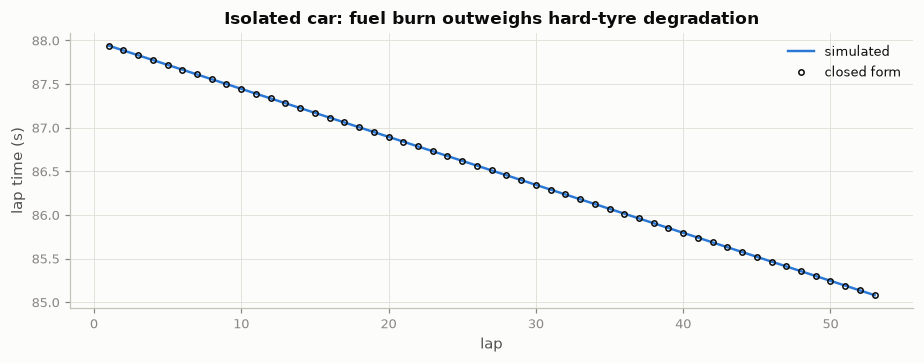

In [26]:
solo = simulate_race([Entry("X", 0.30, 1, Strategy("HARD", ()))], P0)
k = np.arange(1, 54)
closed = 84.0 + 0.30 + 0.015 * (k - 1) + 0.07 * (53 - k)
err = np.abs(solo.laps["lap_time_s"].to_numpy() - closed).max()
fuel_only = simulate_race([Entry("X", 0.0, 1, Strategy("HARD", ()))], variant(P0, HARD__deg_s_per_lap=0.0)).laps["lap_time_s"]
deg_only = simulate_race([Entry("X", 0.0, 1, Strategy("MEDIUM", ()))], variant(P0, fuel_s_per_lap=0.0)).laps["lap_time_s"]
print(f"(a) max |simulated - closed form| over 53 laps: {err:.2e} s")
print(f"(b) fuel only: every lap is quicker by {np.unique(np.round(np.diff(fuel_only), 10))} s")
print(f"(c) degradation only (medium): every lap is slower by {np.unique(np.round(np.diff(deg_only), 10))} s")

flat = variant(P0, fuel_s_per_lap=0.0, HARD__deg_s_per_lap=0.0, HARD__warmup_s=0.0)
T = lambda strat, sc=None: simulate_race([Entry("X", 0.0, 1, strat)], flat, sc).classification.loc["X", "race_time_s"]
sc_stop = simulate_race([Entry("X", 0.0, 1, one_stop("HARD", 20, "HARD"))], flat, SafetyCar(20))
print(f"(d) a green-flag stop costs exactly {T(one_stop('HARD', 20, 'HARD')) - T(Strategy('HARD', ())):.6f} s; "
      f"under the Safety Car the charge is {sc_stop.laps['pit_loss_s'].sum():.1f} s, and the race time changes by "
      f"{T(one_stop('HARD', 20, 'HARD'), SafetyCar(20)) - T(Strategy('HARD', ()), SafetyCar(20)):.6f} s")

def sim_tyre_cost(start, in_lap, to):
    r = simulate_race([Entry("X", 0.0, 1, one_stop(start, in_lap, to))], variant(P0, pit_loss_green_s=0.0))
    return r.classification.loc["X", "race_time_s"] - sum(84.0 + 0.07 * (53 - kk) for kk in range(1, 54))
sim_costs = pd.Series({kname: sim_tyre_cost(*v) for kname, v in plans.items()})
print(f"(e) simulated vs analytic tyre cost (section 5.4), max difference: {(sim_costs - costs).abs().max():.2e} s")

fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.plot(k, solo.laps["lap_time_s"], color=STRAT_COLOR["A"], label="simulated")
ax.plot(k, closed, color=INK, lw=0, marker="o", ms=3.5, mfc="none", label="closed form")
ax.set(xlabel="lap", ylabel="lap time (s)", title="Isolated car: fuel burn outweighs hard-tyre degradation")
ax.legend(); fig.tight_layout(); save(fig, "07_isolated_car"); plt.show()

### 7.2 Passing: a two-car example and a decision map

A two-car example, resolved by hand and by two readings of Ruth's rule:
- leader at 0 s with a 90.0 s lap;
- follower 1.0 s behind, 0.40 s/lap faster, in dirty air, so it projects to $1.0 + 89.6 + 0.25 = 90.85$ s.

An instant-pass reading declares the pass and delays the leader. The time-crossing rule used here lets the
follower close without being held, and changes the order only when the elapsed times cross.

,order after the lap,leader's end time (s),follower's end time (s),time added to the passed car (s)
rule,,,,
instant pass (passed car yields),F L,91.35,90.85,1.35
time crossing (baseline),L F,90.00,90.85,0.00


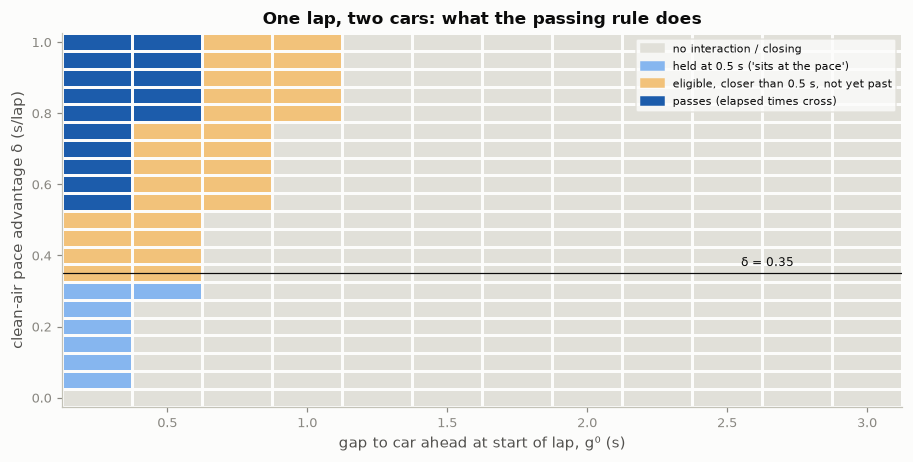

In [27]:
rows = []
for label, p in [("instant pass (passed car yields)", variant(P0, pass_resolution="passed_car_yields")),
                 ("time crossing (baseline)", P0)]:
    out = resolve_racing_lap(["L", "F"], {"L": 0.0, "F": 1.0}, {"L": 90.0, "F": 89.6}, p)
    rows.append({"rule": label, "order after the lap": " ".join(out.order), "leader's end time (s)": round(out.end_time["L"], 3),
                 "follower's end time (s)": round(out.end_time["F"], 3), "time added to the passed car (s)": round(out.pushed.get("L", 0.0), 3)})
display(pd.DataFrame(rows).set_index("rule"))

gaps = np.round(np.arange(0.25, 3.01, 0.25), 2)
deltas = np.round(np.arange(0.0, 1.01, 0.05), 2)
outcome = np.zeros((len(deltas), len(gaps)))
for a_, dlt in enumerate(deltas):
    for b_, g0 in enumerate(gaps):
        out = resolve_racing_lap(["L", "F"], {"L": 0.0, "F": g0}, {"L": 90.0, "F": 90.0 - dlt}, P0)
        outcome[a_, b_] = 3 if out.order[0] == "F" else (1 if out.held["F"] else (2 if out.attacking["F"] else 0))
fig, ax = plt.subplots(figsize=(8.4, 4.3))
cmap = matplotlib.colors.ListedColormap(["#e1e0d9", "#86b6ef", "#f2c27a", "#1c5cab"])
ax.pcolormesh(gaps, deltas, outcome, cmap=cmap, vmin=-0.5, vmax=3.5, shading="nearest", edgecolors=SURFACE, linewidth=0.8)
ax.set(xlabel="gap to car ahead at start of lap, g⁰ (s)", ylabel="clean-air pace advantage δ (s/lap)",
       title="One lap, two cars: what the passing rule does")
ax.grid(False)
labels = ["no interaction / closing", "held at 0.5 s ('sits at the pace')", "eligible, closer than 0.5 s, not yet past", "passes (elapsed times cross)"]
ax.legend(handles=[matplotlib.patches.Patch(color=c, label=l) for c, l in zip(cmap.colors, labels)], loc="upper right",
          frameon=True, facecolor=SURFACE, edgecolor=GRID, fontsize=7.5)
ax.axhline(0.35, color=INK, lw=0.8); ax.text(2.55, 0.37, "δ = 0.35", fontsize=8)
fig.tight_layout(); save(fig, "07_pass_decision_map"); plt.show()

**Reading the map.**
- Below δ = 0.35 the follower may never pass. It is held at 0.5 s once it would arrive closer than that.
- Above 0.35 it is never held. It passes in this lap only if its elapsed time actually beats the leader's,
  which requires $g^0 + 0.25 < δ$ when it starts within 2 s.
- Otherwise it is either closing (grey) or attacking closer than the minimum gap (orange).

With this rule, passing needs *time*. A car 0.40 s/lap faster that starts 0.5 s behind needs about
five laps in dirty air to get by. That is slower than real Monza passing with the tow, and the main
physical cost of a rule that never invents time. The instant-pass variants in §10.4 show what the tow
interpretation would give.

### 7.3 The lap-1 spread against Monza 2023–2025

,cars,slope s per grid slot,last grid car,its gap at end of lap 1 (s),largest gap at end of lap 1 (s)
2023,19,0.490,STR (P20),9.69,9.69
2024,20,0.460,ZHO (P20),8.99,8.99
2025,19,0.418,GAS (P20),8.55,8.55
SIMULATED (2026 field),21,0.350,LAW (slot 22),3.70,7.70


Antonelli (pit-lane start) ends lap 1 8.08 s behind the leader, in position 22.


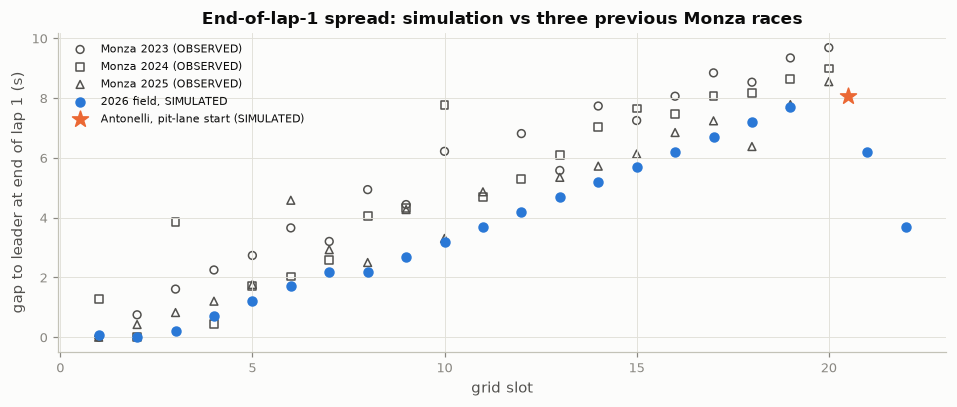

In [28]:
lap1 = run_scenario(SPEC, grid, FW, "C", None, FIELD_LAPS).laps.query("lap == 1").merge(grid[["driver", "grid_slot"]], left_on="car", right_on="driver")
lap1["gap"] = lap1["race_time_s"] - lap1["race_time_s"].min()
grid_cars = lap1[lap1.car != TARGET]
sim_row = {"cars": len(grid_cars), "slope s per grid slot": round(np.polyfit(grid_cars.grid_slot, grid_cars.gap, 1)[0], 3),
           "last grid car": f"LAW (slot 22)", "its gap at end of lap 1 (s)": round(float(grid_cars.sort_values("grid_slot").gap.iloc[-1]), 2),
           "largest gap at end of lap 1 (s)": round(float(grid_cars.gap.max()), 2)}
display(pd.concat([LAP1_HIST, pd.DataFrame([sim_row], index=["SIMULATED (2026 field)"])]))
print(f"Antonelli (pit-lane start) ends lap 1 {float(lap1.loc[lap1.car == TARGET, 'gap'].iloc[0]):.2f} s behind the leader, "
      f"in position {int(lap1.loc[lap1.car == TARGET, 'position'].iloc[0])}.")

fig, ax = plt.subplots(figsize=(8.8, 3.8))
for (year, g), mk in zip(lap1_hist.groupby("year"), ["o", "s", "^"]):
    ax.scatter(g.GridPosition, g.gap_to_leader_end_lap1_s, marker=mk, s=26, facecolor="none", edgecolor=INK2, label=f"Monza {year} (OBSERVED)")
ax.scatter(grid_cars.grid_slot, grid_cars.gap, s=34, color=STRAT_COLOR["A"], label="2026 field, SIMULATED", zorder=3)
ax.scatter([20.5], lap1.loc[lap1.car == TARGET, "gap"], marker="*", s=120, color=STRAT_COLOR["B"], label="Antonelli, pit-lane start (SIMULATED)", zorder=4)
ax.set(xlabel="grid slot", ylabel="gap to leader at end of lap 1 (s)", title="End-of-lap-1 spread: simulation vs three previous Monza races")
ax.legend(fontsize=7.5); fig.tight_layout(); save(fig, "07_lap1_spread"); plt.show()

**Reading the check.**
- In 2023–2025 the field left lap 1 spread at about 0.42–0.49 s per grid slot, with the last car 8.6–9.7 s
  behind.
- The simulated 2026 field is spread somewhat **less**: the slowest grid car is about 7.7 s back. Fast cars from
  the back (Lawson, Albon) also gain places, which flattens the per-slot slope.
- The simulated lap-1 spread is therefore plausible in size but, if anything, **compressed**. Antonelli's
  simulated deficit after lap 1 (about 8 s) is consequently more likely an under- than an over-estimate.
- This is a consistency check across different seasons and fields, not a calibration. The headway conversion
  stays labelled as an assumption, and the pit-lane gap remains unvalidated.

### 7.4 The shared race clock: a worked numerical example

Five cars on an otherwise empty track, simplified so that every number can be checked by hand:
- no fuel effect, no degradation, no dirty air, every car on hards with pace 0, so every racing lap takes exactly
  84.0 s;
- A leads; B, C and D start 1, 10 and 40 s behind; E starts **100 s** behind, more than a lap;
- Safety Car on lap 5.

**Hand calculation.**
* $t_d = 5 \times 84 = 420.0$ s (A completes lap 5). $t_r = 420 + 3 \times 134.4 = 823.2$ s.
* **Deployment (cut laps).** At $t_d$, a car $x$ seconds of racing behind A has $x/84$ of its lap left, and drives it
  at $117.6$ s/lap: it reaches the line at $420 + 1.4x$.
  - B: 421.4 s; C: 434.0 s; D: 476.0 s.
  - E is on a **different lap**: at $t_d$ it is 16 s from the end of its **lap 4**, which it completes at
    $420 + 16 \times 1.4 = 442.4$ s.
* **Window.** The Safety Car's lines are at $554.4,\ 688.8,\ 823.2$ s. A follows it; B follows A at 0.8 s.
  - C, starting lap 6 at 434.0, would finish it at 551.6, so it is caught: 556.0 s.
  - D (593.6, 711.2) never catches the queue.
* **Restart, mid-lap for cars not in the queue.** D starts lap 8 at 711.2. By $t_r$ it has covered
  $112/117.6$ of the lap; the rest takes $4.0$ s at racing pace, so it reaches the line at $827.2$ s.
  - E reaches $t_r$ on its own lap 8 and completes it at $887.2$ s.
  - The queue (A, B, C) crosses the line 0.5 s apart: one spacing at racing pace.
* **Result.** A car that misses the queue gains $3/7$ of a lap $= 36.0$ s **whatever lap it is on**:
  - D: $40 \to 4.0$ s; E: $100 \to 64.0$ s;
  - queued cars end 0.5 s per place behind.

The table compares the simulator's line-crossing times with these numbers; the figure shows each car's laps on
the shared clock.

,,lap start (s),line crossing (s),hand calculation (s),phase on the shared clock,seconds inside the window
car,lap,,,,,
A,5,336.0,420.0,420.0,SC_DEPLOYED,0.0
B,5,337.0,421.4,421.4,SC_DEPLOYED,1.4
C,5,346.0,434.0,434.0,SC_DEPLOYED,14.0
D,5,376.0,476.0,476.0,SC_DEPLOYED,56.0
E,4,352.0,442.4,442.4,SC_DEPLOYED,22.4
A,6,420.0,554.4,554.4,SC,134.4
B,6,421.4,555.2,555.2,SC,133.8
C,6,434.0,556.0,556.0,SC,122.0
D,6,476.0,593.6,593.6,SC,117.6


,start gap (s),simulated gap at the flag (s),"hand: max(gap - 36, 0.5 x queue place)"
A,0,0.0,0.0
B,1,0.5,0.5
C,10,1.0,1.0
D,40,4.0,4.0
E,100,64.0,64.0


t_d = 420.0 s, t_r = 823.2 s; neutralised seconds per car (all 403.2 s): {'A': 403.2, 'B': 403.2, 'C': 403.2, 'D': 403.2, 'E': 403.2}


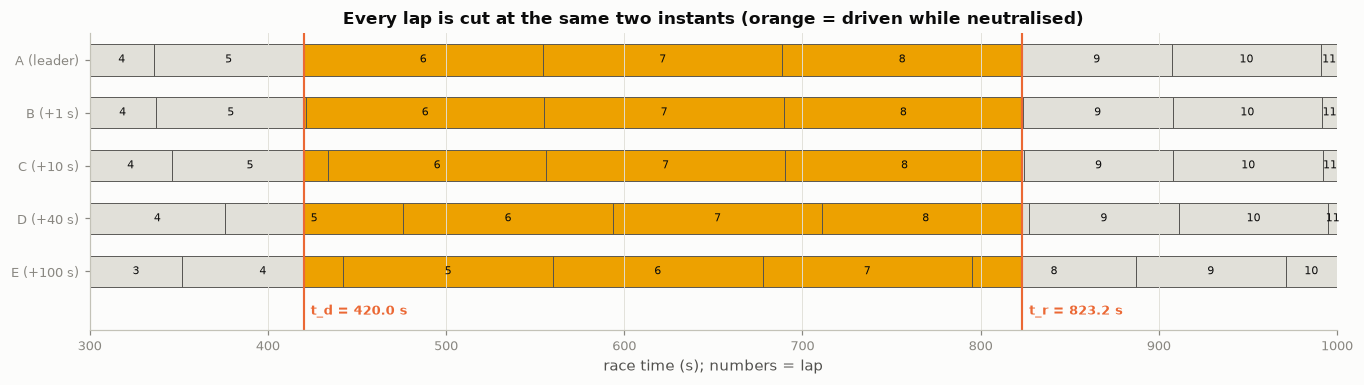

In [29]:
ex_p = variant(P0, fuel_s_per_lap=0.0, HARD__deg_s_per_lap=0.0, HARD__warmup_s=0.0, dirty_air_penalty_s=0.0, grid_slot_gap_s=1.0)
ex_entries = [Entry(c, 0.0, slot, Strategy("HARD", ())) for c, slot in [("A", 1), ("B", 2), ("C", 11), ("D", 41), ("E", 101)]]
ex = simulate_race(ex_entries, ex_p, SafetyCar(5))
hand = {("A", 5): 420.0, ("B", 5): 421.4, ("C", 5): 434.0, ("D", 5): 476.0, ("E", 4): 442.4,
        ("A", 6): 554.4, ("B", 6): 555.2, ("C", 6): 556.0, ("D", 6): 593.6, ("E", 5): 560.0,
        ("A", 8): 823.2, ("B", 8): 823.7, ("C", 8): 824.2, ("D", 8): 827.2, ("E", 8): 887.2}
X = ex.laps.set_index(["car", "lap"])
ex_tab = pd.DataFrame([{"car": c, "lap": k, "lap start (s)": X.loc[(c, k), "lap_start_s"], "line crossing (s)": X.loc[(c, k), "line_time_s"],
                        "hand calculation (s)": v, "phase on the shared clock": X.loc[(c, k), "track_status"],
                        "seconds inside the window": X.loc[(c, k), "neutral_s"]} for (c, k), v in hand.items()]).set_index(["car", "lap"])
display(ex_tab.round(3))
assert np.allclose(ex_tab["line crossing (s)"], ex_tab["hand calculation (s)"], atol=1e-9)
fin = pd.DataFrame({"start gap (s)": [0, 1, 10, 40, 100],
                    "simulated gap at the flag (s)": ex.classification.loc[list("ABCDE"), "gap_to_winner_s"].to_numpy(),
                    "hand: max(gap - 36, 0.5 x queue place)": [0, 0.5, 1.0, 4.0, 64.0]}, index=list("ABCDE"))
display(fin.round(3))
print(f"t_d = {ex.window.t_deploy:.1f} s, t_r = {ex.window.t_restart:.1f} s; neutralised seconds per car (all 403.2 s):",
      ex.laps.groupby("car")["neutral_s"].sum().round(3).to_dict())

fig, ax = plt.subplots(figsize=(12.5, 3.6))
t_d, t_r = ex.window.t_deploy, ex.window.t_restart
for yi, c in enumerate("ABCDE"):
    for r_ in ex.laps[ex.laps.car == c].sort_values("lap").itertuples():
        start, end = r_.lap_start_s, r_.line_time_s
        if end < 300 or start > 1000:
            continue
        cuts = sorted({start, end, *[t for t in (t_d, t_r) if start < t < end]})       # split the lap at t_d and t_r
        for a_, b_ in zip(cuts, cuts[1:]):
            ax.barh(yi, b_ - a_, left=a_, height=0.6, color=COMPOUND_COLOR["MEDIUM"] if t_d <= a_ < t_r else GRID,
                    edgecolor=INK2, linewidth=0.6)
        ax.text((max(start, 300) + min(end, 1000)) / 2, yi, str(r_.lap), ha="center", va="center", fontsize=7, color=INK)
for t, lab in ((t_d, "t_d"), (t_r, "t_r")):
    ax.axvline(t, color=STRAT_COLOR["B"], lw=1.4)
    ax.text(t + 4, 4.75, f"{lab} = {t:.1f} s", color=STRAT_COLOR["B"], ha="left", va="center", fontsize=8.5, fontweight="bold")
ax.set_yticks(range(5), ["A (leader)", "B (+1 s)", "C (+10 s)", "D (+40 s)", "E (+100 s)"])
ax.set(xlim=(300, 1000), ylim=(5.1, -0.5), xlabel="race time (s); numbers = lap",
       title="Every lap is cut at the same two instants (orange = driven while neutralised)")
ax.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "07_shared_clock_example"); plt.show()

**Reading the example.**
* **Hand calculation matches.** Every line-crossing time equals the hand calculation to machine precision (the cell
  asserts it), and every car spends exactly $t_r - t_d = 403.2$ s neutralised.
* **Different laps, same instants.** E is on lap 4 when the Safety Car comes out and on lap 8 when it goes in.
  Its neutralised period still starts and ends at the same instants as everyone else's.
* **Why race time and not lap number.** A rule by lap number (laps 6–8 neutralised for every car) would make E
  race after the deployment and drive at Safety-Car pace long after the restart. The shared clock rules this
  out: the time a car spends neutralised does not depend on which lap it is on.

### 7.5 The automated test suite (`tests/`)

The same properties, and more, are encoded as `pytest` tests with **independent, hand-calculated expectations**
wherever possible:

| File | What it checks |
|---|---|
| `test_lap_model.py` | fuel linearity and convention; tyre offsets, degradation and explicit warm-up; the six-lap medium/hard crossover; closed-form lap times; fuel burn; degradation; a stop costs exactly 22 s and is charged once; tyre-age reset; one green warm-up |
| `test_traffic.py` | a two-car example (no time is taken from the leader); passing when times cross; held at 0.5 s; exactly 0.35 is eligible; dirty air only within 2 s; hand-calculated 3- and 4-car cases; **no pass when both cars end up held behind the same car**; a fast car through a train; **a car's time is only ever increased by a car in front** (50 random laps); trains; closing then passing; **12 random 22-car races with random stops and Safety Cars, every pass strictly time-feasible**; instant-pass variants stay physical; order and spacing after simultaneous stops |
| `test_sc_timeline.py` | hand-calculated shared-clock cases: lap integration through the window; the following gap and its continuity; **two close cars**; **several gaps with finite catch-up and cars that never reach the queue**; **cars more than a lap behind and a restart with cars on different laps**; **an outcome that depends only on race time, not lap number** (361 starting gaps); **a pass in progress at the deployment is cancelled**; **a car on its restart lap cannot be passed**; **no spreading at the deployment line**; the car actually ahead at the line; **pit stops just before the deployment, inside the window and just after the restart**; Ruth's rule at each window crossing; warm-up after a Safety-Car stop; tyre-life test; a cheap stop charged once; no second stop; elapsed time through a late Safety Car; 12 random races checked against every shared-clock invariant; lap-1 loss vs headway |
| `test_config.py` | **every YAML entry is operative or fixed** (each entry is perturbed in turn); fixed entries reject other values; unsupported values rejected (including a negative pit-lane release delay); supported alternatives accepted; the Student-t quantile |
| `test_race.py` | configured pit window and "leaders latest"; two dry specifications (FIA B6.3.6); starting offsets incl. the empty P20 slot; all 15 scenarios complete with lap/car conservation, monotonic time, the gap rule, **every shared-clock invariant** and time-feasible passes; determinism; common-mode invariance (no Safety Car); YAML changes change behaviour and the effective fingerprint, comment edits do not |
| `test_pace.py` | symmetric and one-sided filters select the same laps; the literal rule finds Bearman; FP2 chart, Friday-weighted and Saturday-rebased values within half a rounding unit; push laps are valid laps; the degradation estimator recovers a known slope and its fuel dependence |

In [30]:
%%writefile tests/conftest.py
"""Shared fixtures (the model specification, the published grid and pace, tiny synthetic races) and independent
invariant checks (physical and model-internal)."""
from __future__ import annotations

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import pytest

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))

from racesim.config import load_spec, variant  # noqa: E402
from racesim.lap_model import clean_air_lap_time  # noqa: E402
from racesim.safety_car import follow_gap, lap_phase  # noqa: E402
from racesim.strategies import Entry, Strategy, one_stop  # noqa: E402

CONFIG = ROOT / "config" / "monza_2026.yaml"


@pytest.fixture(scope="session")
def spec():
    return load_spec(CONFIG)


@pytest.fixture(scope="session")
def params(spec):
    return spec.params


@pytest.fixture(scope="session")
def grid():
    return pd.read_csv(ROOT / "data" / "published" / "starting_grid.csv")


@pytest.fixture(scope="session")
def fw_pace():
    df = pd.read_csv(ROOT / "data" / "published" / "ruth_friday_weighted_pace.csv")
    return df.set_index("driver")["pace_gap_s"].to_dict()


@pytest.fixture
def flat_params(params):
    """No degradation, no warm-up, no fuel: lap time = reference + pace + compound offset."""
    return variant(params, fuel_s_per_lap=0.0, HARD__deg_s_per_lap=0.0, HARD__warmup_s=0.0,
                   MEDIUM__deg_s_per_lap=0.0, SOFT__deg_s_per_lap=0.0)


def no_stop(compound: str = "HARD") -> Strategy:
    return Strategy(start_compound=compound, stops=())


def car(code: str, pace: float, slot: int | None, strategy: Strategy | None = None) -> Entry:
    return Entry(code, pace, slot, strategy or no_stop())


def per_car_steps(laps: pd.DataFrame) -> np.ndarray:
    """Change of every car's elapsed race time from one completed lap to the next (incl. start offset)."""
    out = []
    for _, g in laps.sort_values(["car", "lap"]).groupby("car"):
        t = g["race_time_s"].to_numpy()
        out.append(np.diff(t))
    return np.concatenate(out) if out else np.array([])


def check_physical(res, p) -> None:
    """Independent invariants every simulated race must satisfy."""
    L = res.laps
    cars = set(res.classification.index)
    # conservation: every car completes exactly laps 1..N once; no car appears or disappears
    for c, g in L.groupby("car"):
        assert sorted(g["lap"]) == list(range(1, p.total_laps + 1)), f"lap set of {c}"
    assert set(L["car"]) == cars
    for lap, g in L.groupby("lap"):
        g = g.sort_values("position")
        assert list(g["position"]) == list(range(1, len(cars) + 1)), f"positions lap {lap}"
        assert (np.diff(g["race_time_s"].to_numpy()) >= -1e-9).all(), f"order vs time lap {lap}"
    # elapsed time never decreases and every lap takes a physically positive time
    assert (per_car_steps(L) > 0).all(), "elapsed race time decreased"
    assert (L["lap_time_s"] > 0).all()
    for col in ("pit_loss_s", "gap_adjust_s"):
        assert (L[col] >= -1e-12).all(), f"negative {col}"
    # accounting identity
    for _, g in L.sort_values(["car", "lap"]).groupby("car"):
        inc = g[["lap_time_s", "pit_loss_s", "gap_adjust_s"]].sum(axis=1).to_numpy()
        t = g["race_time_s"].to_numpy()
        assert np.allclose(np.diff(t), inc[1:], atol=1e-9)


def check_passes_time_feasible(res) -> None:
    """Every recorded pass must leave the attacker STRICTLY earlier than the passed car at the end of that lap
    (times taken before that lap's pit losses and post-pit spacing)."""
    passes = res.events[res.events["type"] == "pass"] if len(res.events) else res.events
    if passes is None or len(passes) == 0:
        return
    L = res.laps.set_index(["lap", "car"])
    t = L["race_time_s"] - L["pit_loss_s"] - L["gap_adjust_s"]
    for ev in passes.itertuples():
        assert t.loc[(ev.lap, ev.car)] < t.loc[(ev.lap, ev.other)], f"lap {ev.lap}: {ev.car} recorded passing {ev.other}"


def check_timeline(res, p) -> None:
    """Invariants of the shared race clock. Labels: [P] physical requirement, [M] property of this model.

    1 [P] coherent lap progress: every lap starts where the previous one (plus pit loss and spacing) ended,
          and takes a positive time;
    2 [M] one deployment and one restart instant for the whole field: t_d = the first completion of lap N,
          t_r = t_d + D L_sc; every lap's label and neutralised seconds follow from its own times and the window;
    3 [P] speed limits: no lap is covered faster than the car's clean-air pace outside the window and the
          full-course-yellow pace inside it;
    4 [P] no car completes lap N+j before the Safety Car;
    5 [M] the pit price is set by the race time at which the in-lap ends;
    6 [P] no overtaking while neutralised: an order change on a lap cut by the deployment was complete at t_d;
          no car passes another that is still on its restart lap or behind the Safety Car;
    7 [M] spacing at the line for laps that start inside the window (time for the car ahead to cover one
          spacing); on the lap cut at t_d, the distances at t_d are kept (nobody closes in or is pushed back);
    8 [P] every car on track through the window spends the whole window neutralised, in laps or in the pits,
          whatever lap it is on (no advantage or loss from lap-index differences).
    """
    w = res.window
    L = res.laps.sort_values(["car", "lap"])
    for _, g in L.groupby("car"):                                                          # 1
        start, line, t = (g[c].to_numpy() for c in ("lap_start_s", "line_time_s", "race_time_s"))
        assert np.allclose(start[1:], t[:-1], atol=1e-9, rtol=0)
        assert np.allclose(t, line + g["pit_loss_s"].to_numpy() + g["gap_adjust_s"].to_numpy(), atol=1e-9, rtol=0)
        assert (line > start).all()
    if w is None:
        assert (L["track_status"] == "GREEN").all()
        return
    t_d, t_r = w.t_deploy, w.t_restart                                                     # 2
    assert t_r == pytest.approx(t_d + p.sc_duration_laps * p.sc_lap_s, abs=1e-9)
    assert L[L.lap == w.deploy_lap]["line_time_s"].min() == t_d
    for r in L.itertuples():
        assert r.track_status == lap_phase(r.lap_start_s, r.line_time_s, w)
        assert r.neutral_s == pytest.approx(w.neutral_overlap(r.lap_start_s, r.line_time_s), abs=1e-9)
    pace = res.classification["pace_s"]
    for r in L.itertuples():                                                               # 3
        if p.sc_deployment_remainder != "fcy_lap":
            break                                          # sensitivity option 'own_lap_scaled' is not bound by L_fcy
        tau = clean_air_lap_time(p, pace[r.car], r.compound, int(r.tyre_age), bool(r.warmup_applied), int(r.lap))
        green_time = r.line_time_s - r.lap_start_s - r.neutral_s
        assert green_time / tau + r.neutral_s / p.fcy_lap_s >= 1 - 1e-9, (r.car, r.lap)
    for j in range(1, p.sc_duration_laps + 1):                                             # 4
        k = w.deploy_lap + j
        if k <= p.total_laps:
            assert (L[L.lap == k]["line_time_s"] >= t_d + j * p.sc_lap_s - 1e-9).all()
    if len(res.events):                                                                    # 5
        for ev in res.events[res.events.type == "pit"].itertuples():
            assert ev.safety_car_price == w.neutral(ev.pit_entry_s)
            assert ev.loss_s == (p.pit_loss_sc_s if ev.safety_car_price else p.pit_loss_green_s)
    for _, g in L.groupby("lap"):                                                          # 6
        rows = list(g.itertuples())
        for a in rows:
            for b in rows:
                if not (a.lap_start_s < b.lap_start_s and b.line_time_s < a.line_time_s):
                    continue                                       # b did not overtake a on this lap
                assert b.track_status in ("GREEN", "SC_DEPLOYED"), (b.car, a.car, b.lap)
                assert a.track_status not in ("SC", "SC_RESTART"), (b.car, a.car, b.lap)
                if b.track_status == "SC_DEPLOYED" and a.line_time_s > t_d:
                    x = lambda r: (t_d - r.lap_start_s) / (r.green_end_s - r.lap_start_s)
                    assert x(b) >= x(a) - 1e-9, (b.car, a.car, b.lap)    # already ahead at t_d
        seq = sorted(rows, key=lambda r: r.line_time_s)                                   # 7
        for a, b in zip(seq, seq[1:]):
            if b.track_status in ("SC", "SC_RESTART"):
                assert b.line_time_s - a.line_time_s >= follow_gap(a.line_time_s, w, p) - 1e-9, (a.car, b.car, b.lap)
            elif (b.track_status == "SC_DEPLOYED" and a.track_status == "SC_DEPLOYED" and a.line_time_s > t_d
                  and p.sc_deployment_remainder == "fcy_lap"):
                xa = (t_d - a.lap_start_s) / (a.green_end_s - a.lap_start_s)       # fractions of the lap done at t_d
                xb = (t_d - b.lap_start_s) / (b.green_end_s - b.lap_start_s)
                assert b.line_time_s - a.line_time_s == pytest.approx((xa - xb) * p.fcy_lap_s, abs=1e-9)
    for _, g in L.groupby("car"):                                                          # 8
        if g["lap_start_s"].iloc[0] <= t_d and g["race_time_s"].iloc[-1] >= t_r:
            parked = sum(w.neutral_overlap(a, b) for a, b in zip(g["line_time_s"], g["race_time_s"]))
            assert g["neutral_s"].sum() + parked == pytest.approx(t_r - t_d, abs=1e-6)


__all__ = ["car", "no_stop", "one_stop", "per_car_steps", "check_physical", "check_passes_time_feasible",
           "check_timeline"]

Overwriting tests/conftest.py


In [31]:
%%writefile tests/test_lap_model.py
"""Isolated-car tests: the lap-time equation must match hand calculation exactly."""
from __future__ import annotations

import numpy as np
import pytest

from conftest import car, no_stop, one_stop
from racesim.config import variant
from racesim.engine import simulate_race
from racesim.lap_model import clean_air_lap_time, fuel_penalty, tyre_penalty


def test_fuel_penalty_is_linear_and_zero_on_last_lap():
    assert fuel_penalty(1, 53, 0.07) == pytest.approx(52 * 0.07)
    assert fuel_penalty(53, 53, 0.07) == pytest.approx(0.0)
    assert np.allclose(np.diff([fuel_penalty(k, 53, 0.07) for k in range(1, 54)]), -0.07)


def test_tyre_penalty_offsets_degradation_and_warmup(params):
    H, M, S = (params.compounds[c] for c in ("HARD", "MEDIUM", "SOFT"))
    assert tyre_penalty(H, 0, False) == pytest.approx(0.0)
    assert tyre_penalty(H, 0, True) == pytest.approx(0.6)
    assert tyre_penalty(H, 3, True) == pytest.approx(0.645)     # warm-up deferred to a later (green) lap
    assert tyre_penalty(H, 20, False) == pytest.approx(0.30)
    assert tyre_penalty(M, 0, True) == pytest.approx(-0.20)      # no medium warm-up
    assert tyre_penalty(M, 10, False) == pytest.approx(0.30)
    assert tyre_penalty(S, 5, False) == pytest.approx(0.15)


def test_medium_vs_hard_crossover_is_after_six_laps(params):
    """Same-age medium minus hard = -0.20 + 0.035 a: negative for ages 0..5, positive from age 6."""
    H, M = params.compounds["HARD"], params.compounds["MEDIUM"]
    diff = [tyre_penalty(M, a, False) - tyre_penalty(H, a, False) for a in range(10)]
    assert all(d < 0 for d in diff[:6]) and all(d > 0 for d in diff[6:])


def test_isolated_car_lap_times_match_closed_form(params):
    """Single car on hards, no stop: t_k = t_ref + pace + 0.015 (k-1) + 0.07 (53-k)."""
    res = simulate_race([car("X", 0.3, 1)], params)
    k = np.arange(1, 54)
    expected = 84.0 + 0.3 + 0.015 * (k - 1) + 0.07 * (53 - k)
    assert np.allclose(res.laps.set_index("lap")["lap_time_s"].to_numpy(), expected, atol=1e-12)
    assert clean_air_lap_time(params, 0.3, "HARD", 0, False, 1) == pytest.approx(expected[0])


def test_isolated_car_gets_faster_as_fuel_burns(params):
    lt = simulate_race([car("X", 0.0, 1)], variant(params, HARD__deg_s_per_lap=0.0)).laps["lap_time_s"].to_numpy()
    assert np.allclose(np.diff(lt), -0.07)


def test_tyre_degradation_accumulates(params):
    lt = simulate_race([car("X", 0.0, 1, no_stop("MEDIUM"))], variant(params, fuel_s_per_lap=0.0)).laps["lap_time_s"].to_numpy()
    assert np.allclose(np.diff(lt), 0.05)
    assert lt[0] == pytest.approx(84.0 - 0.20)


def test_pit_stop_costs_exactly_the_pit_loss_once(flat_params):
    base = simulate_race([car("X", 0.0, 1, no_stop("HARD"))], flat_params)
    stop = simulate_race([car("X", 0.0, 1, one_stop("HARD", 20, "HARD"))], flat_params)
    diff = stop.classification.loc["X", "race_time_s"] - base.classification.loc["X", "race_time_s"]
    assert diff == pytest.approx(22.0)
    assert stop.laps["pit_loss_s"].sum() == pytest.approx(22.0)
    assert stop.laps.set_index("lap").loc[20, "pit_loss_s"] == pytest.approx(22.0)


def test_tyre_age_resets_and_green_warmup_applies_once(params):
    res = simulate_race([car("X", 0.0, 1, one_stop("MEDIUM", 10, "HARD"))], params)
    laps = res.laps.set_index("lap")
    assert list(laps.loc[1:10, "tyre_age"]) == list(range(10))
    assert list(laps.loc[11:14, "tyre_age"]) == [0, 1, 2, 3]
    assert list(laps["warmup_applied"]).count(True) == 1 and laps.loc[11, "warmup_applied"]
    assert laps.loc[11, "lap_time_s"] == pytest.approx(84.0 + 0.6 + 0.07 * (53 - 11))
    assert laps.loc[12, "lap_time_s"] == pytest.approx(84.0 + 0.015 + 0.07 * (53 - 12))

Overwriting tests/test_lap_model.py


In [32]:
%%writefile tests/test_traffic.py
"""Hand-calculated traffic cases (2, 3 and 4 cars) and randomised field invariants.

Expected values are computed by hand from the rules, independently of the implementation.
Baseline rules: dirty air +0.25 s within 2.0 s (start-of-lap gap); a car may pass only if it is at least
0.35 s/lap faster in clean air; a pass happens only when its elapsed time is earlier (time crossing); a car
that may not pass is held 0.5 s behind the car ahead.
"""
from __future__ import annotations

import numpy as np
import pytest

from conftest import car, check_passes_time_feasible, check_physical, no_stop, one_stop
from racesim.config import variant
from racesim.engine import simulate_race
from racesim.safety_car import SafetyCar
from racesim.traffic import resolve_racing_lap


def lap(p, starts: dict, clean: dict):
    order = sorted(starts, key=starts.get)
    return resolve_racing_lap(order, starts, clean, p)


def test_two_car_example_no_time_is_taken_from_the_leader(params):
    """F 1.0 s behind, 0.40 s faster, dirty air: projected 1.0 + 89.6 + 0.25 = 90.85 > 90.0, so no pass this
    lap and nobody is delayed (an instant-pass reading would declare a pass and delay the leader to 91.35 s)."""
    out = lap(params, {"L": 0.0, "F": 1.0}, {"L": 90.0, "F": 89.6})
    assert out.order == ["L", "F"] and not out.passes
    assert out.end_time == pytest.approx({"L": 90.0, "F": 90.85})
    assert not out.held["F"] and not out.pushed


def test_pass_happens_when_times_cross(params):
    """F 0.2 s behind, 0.5 s faster: projected 0.2 + 89.5 + 0.25 = 89.95 < 90.0 -> F ahead; times unchanged."""
    out = lap(params, {"L": 0.0, "F": 0.2}, {"L": 90.0, "F": 89.5})
    assert out.order == ["F", "L"] and out.passes == [("F", "L")]
    assert out.end_time == pytest.approx({"F": 89.95, "L": 90.0})


def test_ineligible_car_is_held_at_min_gap(params):
    """F 0.5 s behind, 0.30 s faster: would arrive at 0.5 + 89.7 + 0.25 = 90.45 < 90.5 -> held at 90.5."""
    out = lap(params, {"L": 0.0, "F": 0.5}, {"L": 90.0, "F": 89.7})
    assert out.order == ["L", "F"] and out.held["F"]
    assert out.end_time["F"] == pytest.approx(90.5)


def test_exactly_threshold_is_eligible(params):
    """0.35 s faster counts as 'at least 0.35': not held even when it ends closer than 0.5 s."""
    out = lap(params, {"L": 0.0, "F": 0.5}, {"L": 90.0, "F": 89.65})
    assert not out.held["F"] and out.end_time["F"] == pytest.approx(90.4) and out.attacking["F"]


def test_dirty_air_only_within_two_seconds(params):
    near = lap(params, {"L": 0.0, "F": 1.9}, {"L": 90.0, "F": 90.0})
    far = lap(params, {"L": 0.0, "F": 2.1}, {"L": 90.0, "F": 90.0})
    assert near.dirty_air["F"] and not far.dirty_air["F"] and not near.dirty_air["L"]
    assert near.end_time["F"] == pytest.approx(1.9 + 90.25)


def test_three_cars_pass_one_attack_the_next(params):
    """L 0.0/90.0; M 0.5/90.4 (dirty -> 91.15); F 1.0/89.5 (dirty -> 90.75).
    F crosses M (90.75 < 91.15, 0.9 s faster) but not L (90.75 > 90.0); F is 0.5 s faster than L -> not held."""
    out = lap(params, {"L": 0.0, "M": 0.5, "F": 1.0}, {"L": 90.0, "M": 90.4, "F": 89.5})
    assert out.order == ["L", "F", "M"] and out.passes == [("F", "M")]
    assert out.end_time == pytest.approx({"L": 90.0, "F": 90.75, "M": 91.15})
    assert not out.pushed                                  # the passed car loses nothing


def test_four_car_train_is_held_at_min_gaps(params):
    """Each car 0.30 s faster than the car ahead (< 0.35, may not pass) and 0.5 s behind it:
    B would arrive at 0.5 + 89.7 + 0.25 = 90.45 < 90.5 -> held at 90.5; C at 1.0 + 89.4 + 0.25 = 90.65 < 91.0
    -> held at 91.0; D at 1.5 + 89.1 + 0.25 = 90.85 < 91.5 -> held at 91.5."""
    starts = {"A": 0.0, "B": 0.5, "C": 1.0, "D": 1.5}
    clean = {"A": 90.0, "B": 89.7, "C": 89.4, "D": 89.1}
    out = lap(params, starts, clean)
    assert out.order == ["A", "B", "C", "D"]
    assert [out.end_time[c] for c in "ABCD"] == pytest.approx([90.0, 90.5, 91.0, 91.5])
    assert all(out.held[c] for c in "BCD")


def test_fast_car_passes_a_train_in_one_lap_only_if_times_cross(params):
    """A ends 90.0; B (slower, dirty air) ends 0.5 + 90.2 + 0.25 = 90.95; F (3 s/lap faster, dirty air)
    projects 1.0 + 87.0 + 0.25 = 88.25 and crosses both: F, A, B with nobody's time changed."""
    out = lap(params, {"A": 0.0, "B": 0.5, "F": 1.0}, {"A": 90.0, "B": 90.2, "F": 87.0})
    assert out.order == ["F", "A", "B"] and len(out.passes) == 2
    assert out.end_time == pytest.approx({"F": 88.25, "A": 90.0, "B": 90.95})


def test_no_pass_when_both_end_up_held_behind_the_same_car(params):
    """A 0.0/90.0. V 0.1/90.05 (slower than A) would arrive at 0.1 + 90.05 + 0.25 = 90.40 < 90.50 -> held at 90.50.
    F 0.5/89.69 is 0.36 s faster than V (eligible) but only 0.31 s faster than A (not eligible). F would arrive at
    0.5 + 89.69 + 0.25 = 90.44, earlier than V's 90.50, but it must be held at 90.50 behind A, which is not earlier
    than V: no time-feasible pass. Expected order A, V, F with F alongside V (gap 0, attacking)."""
    out = lap(params, {"A": 0.0, "V": 0.1, "F": 0.5}, {"A": 90.0, "V": 90.05, "F": 89.69})
    assert out.order == ["A", "V", "F"] and not out.passes
    assert out.end_time == pytest.approx({"A": 90.0, "V": 90.5, "F": 90.5})
    assert out.held["V"] and out.held["F"] and out.attacking["F"]       # F is blocked alongside V


def test_time_crossing_never_takes_time_from_another_car(params):
    """Property over 50 random 8-car laps: no car ever ends earlier than its own projection; a car that is not
    held ends exactly at its projection; a held car ends exactly at, or 0.5 s behind, a car that finishes ahead
    of it (the car that blocked it; a later attacker may still slot in between). So a car's time can only be
    increased by a car in front, never by a follower."""
    rng = np.random.default_rng(7)
    for _ in range(50):
        n = 8
        starts = {f"C{i}": float(s) for i, s in enumerate(np.cumsum(rng.uniform(0.0, 1.5, n)))}
        clean = {c: 90.0 + float(rng.uniform(0, 2)) for c in starts}
        out = lap(params, starts, clean)
        for i, c in enumerate(out.order):
            proj = starts[c] + clean[c] + (0.25 if out.dirty_air[c] else 0.0)
            assert out.end_time[c] >= proj - 1e-9
            if not out.held[c]:
                assert out.end_time[c] == pytest.approx(proj)
            else:
                ahead_times = [out.end_time[x] for x in out.order[:i]]
                assert any(abs(out.end_time[c] - t) < 1e-9 or abs(out.end_time[c] - t - params.min_follow_gap_s) < 1e-9
                           for t in ahead_times)


def test_slower_car_never_passes_and_train_forms(flat_params):
    res = simulate_race([car("L", 0.30, 1), car("F", 0.00, 2)], flat_params)   # only 0.30 faster
    f = res.laps[res.laps.car == "F"]
    assert (f["position"] == 2).all()
    assert np.allclose(f["gap_ahead_s"].iloc[1:], flat_params.min_follow_gap_s)


def test_faster_car_closes_then_passes(flat_params):
    """0.40 s faster from 2.46 s back: closes at 0.40 s/lap in clean air, at 0.15 s/lap in dirty air, then passes."""
    res = simulate_race([car("L", 0.40, 1), car("F", 0.00, 22)], flat_params)
    pos_f = res.laps[res.laps.car == "F"].set_index("lap")["position"]
    assert pos_f.iloc[0] == 2 and pos_f.iloc[-1] == 1


@pytest.mark.parametrize("seed", range(12))
def test_random_races_with_stops_and_safety_cars_stay_physical(params, seed):
    """Randomised 22-car races with random one-stop strategies and a random Safety Car."""
    rng = np.random.default_rng(seed)
    comps = ["SOFT", "MEDIUM", "HARD"]
    entries = []
    for i in range(22):
        a, b = rng.choice(3, 2, replace=False)
        entries.append(car(f"C{i:02d}", float(rng.uniform(0, 3)), i + 1,
                           one_stop(comps[a], int(rng.integers(5, 45)), comps[b])))
    sc = SafetyCar(int(rng.integers(1, 45))) if seed % 3 else None
    res = simulate_race(entries, params, sc)
    check_physical(res, params)
    check_passes_time_feasible(res)


@pytest.mark.parametrize("resolution", ["passed_car_yields", "passer_jumps"])
def test_instant_pass_variants_keep_order(params, resolution):
    p = variant(params, pass_resolution=resolution)
    rng = np.random.default_rng(99)
    res = simulate_race([car(f"C{i}", float(rng.uniform(0, 3)), i + 1) for i in range(22)], p)
    check_physical(res, p)


def test_simultaneous_stops_keep_order_and_spacing(params):
    """Two cars 0.6 s apart pit on the same green lap with the same loss: the order is kept and the
    rejoining gap is at least the minimum gap (pit-lane congestion/double-stacking is not modelled)."""
    entries = [car("A", 0.0, 1, one_stop("MEDIUM", 10, "HARD")), car("B", 0.0, 6, one_stop("MEDIUM", 10, "HARD"))]
    res = simulate_race(entries, params)
    lap10 = res.laps[res.laps.lap == 10].sort_values("position")
    assert list(lap10["car"]) == ["A", "B"]
    assert lap10["gap_ahead_s"].iloc[1] >= params.min_follow_gap_s - 1e-9
    check_physical(res, params)

Overwriting tests/test_traffic.py


In [33]:
%%writefile tests/test_sc_timeline.py
"""Safety Car on the shared race clock: focused boundary cases with HAND-DERIVED expectations.

Common set-up for the hand calculations (unless a test says otherwise): no fuel effect, no degradation, no warm-up,
no dirty air, every car on hards with pace 0, so every racing lap takes exactly t_ref = 84.0 s; a grid slot is 1 s
of starting headway. Then:
    L_sc  = 1.6 x 84 = 134.4 s     (Safety-Car lap)          L_fcy = 1.4 x 84 = 117.6 s (full-course-yellow lap)
    SC on lap 5:  t_d = 5 x 84 = 420.0 s (leader completes lap 5),  t_r = 420 + 3 x 134.4 = 823.2 s.
Distance argument used throughout: inside the window a car not yet in the queue gains on the Safety Car
403.2 x (1/117.6 - 1/134.4) = 3/7 lap = 36.0 s at 84 s/lap.
"""
from __future__ import annotations

import numpy as np
import pytest

from conftest import car, check_passes_time_feasible, check_physical, check_timeline, no_stop, one_stop
from racesim.config import variant
from racesim.engine import simulate_race
from racesim.safety_car import SafetyCar, SafetyCarWindow, can_reach_flag, follow_gap, free_lap_end

T_D, T_R = 420.0, 823.2


@pytest.fixture
def clock(params):
    """84.0 s racing laps for pace 0 on hards, 1 s headway per grid slot, no dirty air."""
    return variant(params, fuel_s_per_lap=0.0, HARD__deg_s_per_lap=0.0, HARD__warmup_s=0.0, MEDIUM__deg_s_per_lap=0.0,
                   SOFT__deg_s_per_lap=0.0, dirty_air_penalty_s=0.0, grid_slot_gap_s=1.0)


def line(res, code: str, lap: int) -> float:
    L = res.laps
    return float(L[(L.car == code) & (L.lap == lap)]["line_time_s"].iloc[0])


def status(res, code: str) -> list[str]:
    L = res.laps
    return list(L[L.car == code].sort_values("lap")["track_status"])


def gap_at_flag(res, code: str, ref: str = "A") -> float:
    c = res.classification
    return float(c.loc[code, "race_time_s"] - c.loc[ref, "race_time_s"])


# ---- building blocks -------------------------------------------------------------------------------------------

def test_free_lap_end_by_hand():
    w = SafetyCarWindow(deploy_lap=5, duration_laps=3, t_deploy=T_D, sc_lap_s=134.4)
    assert free_lap_end(100.0, 84.0, w, 117.6) == pytest.approx(184.0)                  # entirely green
    assert free_lap_end(T_D - 42.0, 84.0, w, 117.6) == pytest.approx(T_D + 58.8)        # half a lap left at t_d
    assert free_lap_end(T_D + 10.0, 84.0, w, 117.6) == pytest.approx(T_D + 127.6)       # entirely neutralised
    assert free_lap_end(T_R - 58.8, 84.0, w, 117.6) == pytest.approx(T_R + 42.0)        # half a lap left at t_r
    short = SafetyCarWindow(deploy_lap=5, duration_laps=1, t_deploy=100.0, sc_lap_s=20.0)  # window [100, 120)
    # 0.5 lap green by t=100, + 20/117.6 lap in the window, remaining (0.5 - 20/117.6) x 84 = 27.714286 s
    assert free_lap_end(58.0, 84.0, short, 117.6) == pytest.approx(120.0 + (0.5 - 20 / 117.6) * 84.0)


def test_follow_gap_is_one_spacing_and_continuous(params):
    """0.8 s at Safety-Car pace and 0.5 s at racing pace are the same distance; the time needed by the car ahead
    to cover it is interpolated when it changes pace within that spacing."""
    w = SafetyCarWindow(deploy_lap=5, duration_laps=3, t_deploy=T_D, sc_lap_s=134.4)
    assert 0.8 / 134.4 == pytest.approx(0.5 / 84.0)
    expected = {T_D - 1.0: 0.5, T_D - 0.5: 0.5, T_D - 0.25: 0.25 + 0.5 * 0.8, T_D: 0.8, T_D + 100: 0.8,
                T_R - 0.8: 0.8, T_R - 0.4: 0.4 + 0.5 * 0.5, T_R: 0.5, T_R + 5: 0.5}
    for t, g in expected.items():
        assert follow_gap(t, w, params) == pytest.approx(g), t
    ts = np.linspace(T_D - 2, T_D + 2, 4001).tolist() + np.linspace(T_R - 2, T_R + 2, 4001).tolist()
    vals = np.array([follow_gap(t, w, params) for t in ts])
    assert np.abs(np.diff(vals)).max() < 2e-3                                              # no jump


# ---- 1. two close cars, deployment mid-lap, restart -------------------------------------------------------------

def test_two_close_cars_by_hand(params):
    """L (pace 0, slot 1) and F (pace 0.2, 0.6 s behind, dirty air 0.25 s); SC on lap 2.
    Lap 1: F = 0.6 + 84.45 = 85.05. Lap 2: L = 168 = t_d; F would end at 85.05 + 84.45 = 169.5, i.e. 1.5/84.45 of
    a lap from the line at t_d, covered at 117.6 s/lap: 168 + 1.5 x 117.6/84.45 = 170.088810.
    Laps 3-5: L on the Safety Car's line times 302.4, 436.8, 571.2 (= t_r); F 0.8 s behind, and 0.5 s behind at the
    restart line (one spacing at racing pace). Lap 6 racing: 655.2 and 571.7 + 84.45 = 656.15."""
    p = variant(params, fuel_s_per_lap=0.0, HARD__deg_s_per_lap=0.0, HARD__warmup_s=0.0, grid_slot_gap_s=0.6)
    res = simulate_race([car("L", 0.0, 1), car("F", 0.2, 2)], p, SafetyCar(2))
    assert res.window.t_deploy == pytest.approx(168.0) and res.window.t_restart == pytest.approx(571.2)
    assert line(res, "F", 1) == pytest.approx(85.05)
    L = res.laps.set_index(["car", "lap"])
    assert L.loc[("F", 2), "green_end_s"] == pytest.approx(169.5)
    assert line(res, "F", 2) == pytest.approx(168 + 1.5 * 117.6 / 84.45)
    assert [line(res, "L", k) for k in (3, 4, 5, 6)] == pytest.approx([302.4, 436.8, 571.2, 655.2])
    assert [line(res, "F", k) for k in (3, 4, 5, 6)] == pytest.approx([303.2, 437.6, 571.7, 656.15])
    assert status(res, "L")[:6] == ["GREEN", "SC_DEPLOYED", "SC", "SC", "SC", "GREEN"]
    assert status(res, "F")[:6] == ["GREEN", "SC_DEPLOYED", "SC", "SC", "SC_RESTART", "GREEN"]
    for c in "LF":
        assert res.laps[res.laps.car == c]["neutral_s"].sum() == pytest.approx(403.2)
    check_physical(res, p)
    check_timeline(res, p)


def test_close_cars_are_not_spread_at_the_deployment_line_by_hand(clock):
    """SC on lap 1. B (pace 0) starts 0.3 s behind A (pace 0.5) and passes it on lap 1: B 84.3 = t_d. A is then
    0.2/84.5 of a lap from the line and covers it at 117.6 s/lap: 84.3 + 0.2 x 117.6/84.5 = 84.578343 - only
    0.278 s behind, NOT pushed to the 0.8 s queue spacing (the queue has not formed yet; distances are kept).
    Lap 2 is the first full lap behind the Safety Car: B 84.3 + 134.4 = 218.7, A one spacing behind, 219.5."""
    p = variant(clock, grid_slot_gap_s=0.3)
    res = simulate_race([car("A", 0.5, 1), car("B", 0.0, 2)], p, SafetyCar(1))
    assert res.window.t_deploy == pytest.approx(84.3)
    assert line(res, "A", 1) == pytest.approx(84.3 + 0.2 * 117.6 / 84.5)
    assert [line(res, "B", 2), line(res, "A", 2)] == pytest.approx([218.7, 219.5])
    passes = res.events[res.events.type == "pass"]
    assert list(zip(passes.lap, passes.car, passes.other)) == [(1, "B", "A")]          # complete at t_d: stands
    check_physical(res, p)
    check_timeline(res, p)
    check_passes_time_feasible(res)


# ---- 2. several gaps: finite catch-up, some cars never reach the queue -------------------------------------------

def test_multiple_gaps_catch_up_by_hand(clock):
    """Gaps at the start: B 1, C 10, D 40, E 70 s. Lap 5 is cut at t_d = 420: a car x s behind finishes it at
    420 + 1.4x. C reaches the queue on lap 6; D and E never do and restart mid-lap (at t_r) with
    40 - 36 = 4.0 s and 70 - 36 = 34.0 s. Queue cars restart one spacing (0.5 s) apart."""
    entries = [car("A", 0.0, 1), car("B", 0.0, 2), car("C", 0.0, 11), car("D", 0.0, 41), car("E", 0.0, 71)]
    res = simulate_race(entries, clock, SafetyCar(5))
    expected = {5: [420.0, 421.4, 434.0, 476.0, 518.0],
                6: [554.4, 555.2, 556.0, 593.6, 635.6],
                7: [688.8, 689.6, 690.4, 711.2, 753.2],
                8: [823.2, 823.7, 824.2, 827.2, 857.2],
                9: [907.2, 907.7, 908.2, 911.2, 941.2]}
    for lap, times in expected.items():
        assert [line(res, c, lap) for c in "ABCDE"] == pytest.approx(times), lap
    assert [gap_at_flag(res, c) for c in "BCDE"] == pytest.approx([0.5, 1.0, 4.0, 34.0])
    L = res.laps.set_index(["car", "lap"])
    assert bool(L.loc[("C", 6), "held_up"]) and not L.loc[("D", 6), "held_up"]          # C caught, D not
    check_physical(res, clock)
    check_timeline(res, clock)


# ---- 3. cars more than one lap apart; restart with cars on different laps ----------------------------------------

def test_lapped_cars_use_the_same_clock_by_hand(clock):
    """X starts 100 s and Y 150 s behind A (more than a lap). The deployment cuts X's and Y's LAP 4 (not lap 5):
    X: 352 -> 436 green becomes 420 + 16 x 1.4 = 442.4; Y: 402 -> 486 becomes 420 + 66 x 1.4 = 512.4.
    Then neutralised laps of 117.6 s. At t_r = 823.2 X is on lap 8 and Y on lap 7:
    X lap 8 from 795.2: 28/117.6 lap by t_r, rest 64.0 s at racing pace -> 887.2;
    Y lap 7 from 747.6: 75.6/117.6 lap by t_r, rest 30.0 s -> 853.2, and Y's lap 8 is a racing lap (937.2)
    although A's lap 8 was a Safety-Car lap. Both gain exactly 36.0 s, like any car that misses the queue."""
    res = simulate_race([car("A", 0.0, 1), car("X", 0.0, 101), car("Y", 0.0, 151)], clock, SafetyCar(5))
    assert [line(res, "X", k) for k in range(4, 10)] == pytest.approx([442.4, 560.0, 677.6, 795.2, 887.2, 971.2])
    assert [line(res, "Y", k) for k in range(4, 9)] == pytest.approx([512.4, 630.0, 747.6, 853.2, 937.2])
    assert status(res, "X")[3:9] == ["SC_DEPLOYED", "SC", "SC", "SC", "SC_RESTART", "GREEN"]
    assert status(res, "Y")[3:8] == ["SC_DEPLOYED", "SC", "SC", "SC_RESTART", "GREEN"]
    lap8 = res.laps[res.laps.lap == 8].set_index("car")["track_status"].to_dict()
    assert lap8 == {"A": "SC", "X": "SC_RESTART", "Y": "GREEN"}                           # same lap, three phases
    assert gap_at_flag(res, "X") == pytest.approx(64.0) and gap_at_flag(res, "Y") == pytest.approx(114.0)
    for c in "AXY":
        assert res.laps[res.laps.car == c]["neutral_s"].sum() == pytest.approx(403.2)
    check_physical(res, clock)
    check_timeline(res, clock)


def test_own_lap_deployment_option(params):
    """Sensitivity option 'own_lap_scaled': the rest of the cut lap takes 1.4 x the car's own remaining racing time
    instead of the driver-independent 117.6 s/lap. Two-car case of test_two_close_cars_by_hand:
    F's lap 2 = 168 + 1.4 x 1.5 = 170.1 instead of 170.088810; everything else unchanged."""
    p = variant(params, fuel_s_per_lap=0.0, HARD__deg_s_per_lap=0.0, HARD__warmup_s=0.0, grid_slot_gap_s=0.6,
                sc_deployment_remainder="own_lap_scaled")
    res = simulate_race([car("L", 0.0, 1), car("F", 0.2, 2)], p, SafetyCar(2))
    assert line(res, "F", 2) == pytest.approx(170.1)
    assert [line(res, "F", k) for k in (3, 4, 5)] == pytest.approx([303.2, 437.6, 571.7])
    check_timeline(res, p)


def test_outcome_depends_on_race_time_not_lap_index(clock):
    """A car starting s seconds behind (20 <= s <= 200, crossing several lap boundaries relative to t_d) finishes
    max(s - 36, 0.5) s behind: continuous and monotonic in s, with no step where its lap index changes."""
    for s in np.arange(20.0, 200.01, 0.5):
        p = variant(clock, grid_slot_gap_s=float(s))
        res = simulate_race([car("A", 0.0, 1), car("X", 0.0, 2)], p, SafetyCar(5), record=False)
        assert gap_at_flag(res, "X") == pytest.approx(max(s - 36.0, 0.5), abs=1e-6), s


def test_pass_in_progress_at_deployment_is_cancelled_and_restart_lap_car_is_protected(clock):
    """Two lapped cars behind leader A (t_d = 420, t_r = 823.2): W (pace 3.0, 87 s laps, 195.5 s back) and P
    (pace 0, 84 s laps, 204.2 s back), so P gains 3 s/lap.
    Lap 3 (cut by t_d): racing would put P ahead at the line (456.2 < 456.5), but at t_d W has 36.5/87 of the lap
    left and P 36.2/84 (more), so W is still ahead: the pass is cancelled. W: 420 + 36.5/87 x 117.6 = 469.337931,
    P: 420 + 36.2/84 x 117.6 = 470.68. Laps 4-5 at 117.6 s. Lap 6: W 822.137931 (< t_r); P restarts in that lap:
    705.88 + 117.32 s neutralised + 0.2 s racing = 823.4. Lap 7: W is on its restart lap (starts in the window):
    823.2 + (1 - 1.062069/117.6) x 87 = 909.414286; P starts after t_r and would finish 907.4, but may not pass a
    car still on its restart lap: held to 909.914286."""
    p = variant(clock, grid_slot_gap_s=0.1)
    entries = [car("A", 0.0, 1), car("W", 3.0, 1956), car("P", 0.0, 2043)]
    res = simulate_race(entries, p, SafetyCar(5))
    assert res.window.t_deploy == pytest.approx(420.0)
    L = res.laps.set_index(["car", "lap"])
    assert L.loc[("P", 3), "green_end_s"] < L.loc[("W", 3), "green_end_s"]              # racing alone: P ahead
    assert line(res, "W", 3) == pytest.approx(420 + 36.5 / 87 * 117.6)
    assert line(res, "P", 3) == pytest.approx(420 + 36.2 / 84 * 117.6)
    assert res.events[(res.events.type == "pass") & (res.events.lap == 3)].empty
    assert line(res, "W", 6) == pytest.approx(420 + 36.5 / 87 * 117.6 + 3 * 117.6)
    assert line(res, "P", 6) == pytest.approx(823.4)
    w7 = 823.2 + (1 - (823.2 - line(res, "W", 6)) / 117.6) * 87.0
    assert line(res, "W", 7) == pytest.approx(909.414286, abs=1e-6) and w7 == pytest.approx(909.414286, abs=1e-6)
    assert line(res, "P", 7) == pytest.approx(w7 + 0.5) and bool(L.loc[("P", 7), "held_up"])
    assert (L.loc[("W", 7), "track_status"], L.loc[("P", 7), "track_status"]) == ("SC_RESTART", "GREEN")
    check_physical(res, p)
    check_timeline(res, p)
    check_passes_time_feasible(res)


def test_first_neutralised_car_follows_the_car_actually_ahead_at_the_line(clock):
    """t_d = 420 (A). Three lapped cars: V is held 0.5 s behind U from lap 1; R (0.5 s/lap faster) passes V on lap 4.
    Lap 4 ends at 419.6 (U) and 419.9 (R), before t_d; V's would end at 420.1, so the deployment cuts V's LAP 4:
    420 + 0.1 x 1.4 = 420.14 (a first hand calculation missed this and expected 420.1).
    Lap 5: racing alone, R would pass U, but only at t = 470 > t_d, so U stays ahead: U 420 + 83.6/84 x 117.6 =
    537.04, R 420 + 83.4/83.5 x 117.6 = 537.459162. V's lap 5 starts inside the window: free 420.14 + 117.6 =
    537.74, but it must stay one queue spacing behind the car really ahead at the line (R, not U): 538.259162.
    After the restart (lap 8: U 870.8, R one racing-pace spacing behind, 871.3) R, 0.5 s/lap faster, ends lap 9
    exactly alongside U (954.8; a pass needs a strictly earlier time) and passes it on lap 10 (1038.3 < 1038.8)."""
    p = variant(clock, grid_slot_gap_s=0.1)
    entries = [car("A", 0.0, 1), car("U", 0.0, 837), car("V", 0.0, 841), car("R", -0.5, 860)]
    res = simulate_race(entries, p, SafetyCar(5))
    assert [line(res, c, 4) for c in ("U", "R", "V")] == pytest.approx([419.6, 419.9, 420.0 + 0.1 * 1.4])
    assert line(res, "U", 5) == pytest.approx(420 + 83.6 / 84 * 117.6)
    assert line(res, "R", 5) == pytest.approx(420 + 83.4 / 83.5 * 117.6)
    assert line(res, "V", 5) == pytest.approx(420 + 83.4 / 83.5 * 117.6 + 0.8)
    passes = res.events[res.events.type == "pass"]
    assert list(zip(passes.lap, passes.car, passes.other)) == [(4, "R", "V"), (10, "R", "U")]
    assert [line(res, "U", 8), line(res, "R", 8)] == pytest.approx([870.8, 871.3])
    assert [line(res, "U", 9), line(res, "R", 9)] == pytest.approx([954.8, 954.8])
    check_physical(res, p)
    check_timeline(res, p)
    check_passes_time_feasible(res)


# ---- 4. pit stops just before deployment, during the window and just after the restart --------------------------

def test_pit_price_follows_the_race_clock_by_hand(clock):
    """Planned stops (Ruth's opportunistic rule off). In-lap end times and prices, derived by hand:
      P1 (83 s back, in-lap 4) 419.0 < t_d          -> 22 s   just before the deployment
      P2 (85 s back, in-lap 4) 420 + 1.4 = 421.4    -> 11 s   same LAP as P1, other side of t_d
      P3 (2 s back, in-lap 6)  queued, 556.0        -> 11 s   during the neutralisation
      P6 (100 s back, in-lap 7) 795.2 < t_r         -> 11 s
      P5 (150 s back, in-lap 7) 853.2 > t_r         -> 22 s   same LAP as P6, after the restart
      A (leader, in-lap 8) exactly t_r = 823.2      -> 22 s   the Safety Car has gone in
      Q (1 s back, in-lap 8) 823.7                  -> 22 s   just after the restart
    A rule by lap number (laps 5, 6, 7 cheap) would instead charge P2 22 s and P5 11 s."""
    p = variant(clock, sc_opportunistic_stops=False)
    entries = [car("A", 0.0, 1, one_stop("HARD", 8, "HARD")), car("Q", 0.0, 2, one_stop("HARD", 8, "HARD")),
               car("P3", 0.0, 3, one_stop("HARD", 6, "HARD")), car("P1", 0.0, 84, one_stop("HARD", 4, "HARD")),
               car("P2", 0.0, 86, one_stop("HARD", 4, "HARD")), car("P6", 0.0, 101, one_stop("HARD", 7, "HARD")),
               car("P5", 0.0, 151, one_stop("HARD", 7, "HARD"))]
    res = simulate_race(entries, p, SafetyCar(5))
    pits = res.events[res.events.type == "pit"].set_index("car")
    expected = {"P1": (4, 419.0, 22.0), "P2": (4, 421.4, 11.0), "P3": (6, 556.0, 11.0), "P6": (7, 795.2, 11.0),
                "P5": (7, 853.2, 22.0), "A": (8, 823.2, 22.0), "Q": (8, 823.7, 22.0)}
    for c, (lap, entry, loss) in expected.items():
        assert int(pits.loc[c, "lap"]) == lap, c
        assert float(pits.loc[c, "pit_entry_s"]) == pytest.approx(entry), c
        assert float(pits.loc[c, "loss_s"]) == loss, c
    check_physical(res, p)
    check_timeline(res, p)


@pytest.mark.parametrize("policy, life, lap, loss", [("every_cheap_lap", 45, 36, 22.0), ("every_cheap_lap", 46, 7, 11.0),
                                                     ("every_cheap_lap", 48, 5, 11.0), ("deployment_lap_only", 46, 36, 22.0)])
def test_ruths_rule_at_each_window_crossing(params, policy, life, lap, loss):
    """Leader X (hard, medium planned for lap 36), SC on lap 5: X crosses the line inside the window at the end of
    laps 5, 6 and 7 (t_d, t_d + L_sc, t_d + 2 L_sc; lap 8 ends at t_r). Laps left 48/47/46."""
    p = variant(params, MEDIUM__max_life_laps=life, sc_eligibility=policy)
    res = simulate_race([car("X", 0.0, 1, one_stop("HARD", 36, "MEDIUM")), car("Y", 0.3, 2)], p, SafetyCar(5))
    pit = res.events[(res.events.type == "pit") & (res.events.car == "X")].iloc[0]
    assert pit["lap"] == lap and pit["loss_s"] == loss
    check_timeline(res, p)


@pytest.mark.parametrize("policy, expected", [("first_green_lap", [14]), ("first_lap_of_stint", [])])
def test_warmup_after_a_safety_car_stop_is_paid_on_the_first_racing_lap(params, policy, expected):
    """Leader X fits hards at t_d (end of lap 10) and rejoins behind Y; laps 11-13 start inside the window; the
    first lap that starts at racing speed is lap 14."""
    p = variant(params, warmup_policy=policy)
    res = simulate_race([car("X", 0.0, 1, one_stop("MEDIUM", 10, "HARD")), car("Y", 0.3, 2)], p, SafetyCar(10))
    x = res.laps[res.laps.car == "X"].set_index("lap")
    assert list(x.index[x["warmup_applied"]]) == expected
    check_timeline(res, p)


# ---- 5. whole-race invariants ------------------------------------------------------------------------------------

@pytest.mark.parametrize("seed", range(12))
def test_random_races_satisfy_the_timeline_invariants(params, seed):
    """22 random cars, random one-stop plans, random starting spreads (some cars lapped), a Safety Car on a
    random lap (1-50), dirty air and passing on."""
    rng = np.random.default_rng(1000 + seed)
    p = variant(params, grid_slot_gap_s=float(rng.choice([0.117, 2.0, 6.0])))
    entries = []
    for i in range(22):
        start, nxt = rng.choice(["MEDIUM", "HARD"]), "HARD"
        strat = one_stop(str(start), int(rng.integers(2, 45)), nxt if start == "MEDIUM" else "MEDIUM")
        entries.append(car(f"R{i:02d}", float(rng.uniform(0.0, 3.5)), i + 1, strat))
    res = simulate_race(entries, p, SafetyCar(int(rng.integers(1, 51))))
    check_physical(res, p)
    check_timeline(res, p)
    check_passes_time_feasible(res)


def test_lap1_grid_loss_and_headway_differ_only_through_lap1_interactions(params):
    """Two representations of a 4 s grid deficit (slot 5, 1 s per slot): as a starting headway, C starts 4 s back
    in clean air (88.0); as TUM's lap-1 loss, C starts alongside, in dirty air, and loses 4 s on lap 1 (88.25)."""
    flat = variant(params, fuel_s_per_lap=0.0, HARD__deg_s_per_lap=0.0)
    headway = variant(flat, grid_slot_gap_s=1.0)
    loss = variant(flat, grid_slot_gap_s=0.0, grid_lap1_loss_per_slot_s=1.0)
    solo_h = simulate_race([car("C", 0.0, 5)], headway)
    solo_l = simulate_race([car("C", 0.0, 5)], loss)
    assert line(solo_h, "C", 1) == pytest.approx(88.0) and line(solo_l, "C", 1) == pytest.approx(88.0)
    duo_h = simulate_race([car("A", 0.0, 1), car("C", 0.0, 5)], headway)
    duo_l = simulate_race([car("A", 0.0, 1), car("C", 0.0, 5)], loss)
    assert line(duo_h, "C", 1) == pytest.approx(88.0) and line(duo_l, "C", 1) == pytest.approx(88.25)


# ---- 6. pit-stop bookkeeping under the Safety Car -----------------------------------------------------------------

def test_can_reach_flag(params):
    assert can_reach_flag(params, "HARD", 1)          # 52 laps left, hard life 52
    assert not can_reach_flag(params, "MEDIUM", 5)    # 48 > 46
    assert not can_reach_flag(params, "MEDIUM", 6)    # 47 > 46
    assert can_reach_flag(params, "MEDIUM", 7)        # 46 <= 46


def test_elapsed_time_never_decreases_through_a_late_safety_car(params):
    """A car about 100 s behind (lapped) when a Safety Car comes out on lap 35."""
    entries = [car("F", 0.0, 1), car("M", 1.0, 2), car("S", 3.8, 3)]
    res = simulate_race(entries, params, SafetyCar(35))
    check_physical(res, params)
    check_timeline(res, params)


def test_cheap_stop_is_charged_once_at_sc_price(params):
    """Eight cars planning a stop on lap 30; SC on lap 10. Every car ends its lap 10 inside the window and a hard
    can reach the flag from lap 10 (43 laps), so all eight stop at the end of lap 10, at the Safety-Car price, once."""
    entries = [car(f"C{i}", 0.5 * i, i + 1, one_stop("MEDIUM", 30, "HARD")) for i in range(8)]
    res = simulate_race(entries, params, SafetyCar(10))
    pits = res.events[res.events.type == "pit"]
    assert len(pits) == 8 and (pits["lap"] == 10).all() and (pits["loss_s"] == params.pit_loss_sc_s).all()
    assert np.allclose(res.laps.groupby("car")["pit_loss_s"].sum(), params.pit_loss_sc_s)
    check_timeline(res, params)


def test_car_that_already_stopped_does_not_stop_again(params):
    res = simulate_race([car("X", 0.0, 1, one_stop("MEDIUM", 1, "HARD")), car("Y", 0.3, 2)], params, SafetyCar(20))
    assert list(res.events[(res.events.type == "pit") & (res.events.car == "X")]["lap"]) == [1]

Overwriting tests/test_sc_timeline.py


In [34]:
%%writefile tests/test_config.py
"""Configuration contract: every YAML entry is either OPERATIVE (changing it changes the effective specification)
or FIXED (changing it is rejected); unsupported switch values and parameter values are rejected, never silently
ignored."""
from __future__ import annotations

import copy

import pytest
import yaml

from conftest import CONFIG
from racesim.config import FIXED_CHOICES, _canonical, load_spec, parameter_register, variant
from racesim.pace import t975


def _records(node, prefix=""):
    if isinstance(node, dict) and "value" in node and "status" in node:
        yield prefix, node
    elif isinstance(node, dict):
        for k, v in node.items():
            yield from _records(v, f"{prefix}.{k}" if prefix else k)


def _perturb(v):
    if isinstance(v, bool):
        return not v
    if isinstance(v, int):
        return v + 1
    if isinstance(v, float):
        return v + 0.5
    if isinstance(v, str):
        return v + "_changed"
    if isinstance(v, list):
        return v[:-1] if len(v) > 1 else v + v + [0]
    if v is None:
        return 1
    raise TypeError(type(v))


def test_every_yaml_entry_is_operative_or_fixed(tmp_path):
    raw = yaml.safe_load(CONFIG.read_text())
    base = _canonical(load_spec(CONFIG))
    paths = [p for section, node in raw.items() if section not in ("meta", "sources") for p, _ in _records(node, section)]
    assert len(paths) == len(parameter_register(CONFIG)) > 50
    for path in paths:
        mutated = copy.deepcopy(raw)
        node = mutated
        for part in path.split("."):
            node = node[part]
        node["value"] = _perturb(node["value"])
        f = tmp_path / "m.yaml"
        f.write_text(yaml.safe_dump(mutated))
        try:
            spec = load_spec(f)
        except (ValueError, KeyError, TypeError):
            continue                                                   # rejected: fixed or validated
        assert _canonical(spec) != base, f"{path} was changed but nothing the simulator uses changed"


def test_fixed_entries_are_labelled_and_reject_other_values(tmp_path):
    raw = yaml.safe_load(CONFIG.read_text())
    reg = parameter_register(CONFIG).set_index("parameter")
    assert set(reg.index[reg["role"] == "fixed"]) == set(FIXED_CHOICES)
    for dotted, required in FIXED_CHOICES.items():
        section, key = dotted.split(".")
        mutated = copy.deepcopy(raw)
        mutated[section][key]["value"] = _perturb(required)
        f = tmp_path / "m.yaml"
        f.write_text(yaml.safe_dump(mutated))
        with pytest.raises(ValueError, match="not implemented"):
            load_spec(f)
    assert dict(load_spec(CONFIG).fixed) == FIXED_CHOICES


def test_alternative_pace_sets_are_operative(spec):
    assert spec.pace_set == "friday_weighted" and spec.alternative_pace_sets == ("saturday_rebased", "blend_50_50")


@pytest.mark.parametrize("change, message", [
    ({"sc_eligibility": "sometimes"}, "not supported"),
    ({"pass_resolution": "instant"}, "not supported"),
    ({"sc_deployment_remainder": "own_lap"}, "not supported"),
    ({"pit_lane_start_gap_s": -2.043}, "negative"),
    ({"grid_slot_gap_s": 0.5, "pit_lane_start_gap_s": 8.457 - 21 * 0.5}, "negative"),   # outside the probe domain
    ({"sc_duration_laps": 0}, "duration"),
    ({"fcy_lap_factor": 1.0}, "factors > 1"),
])
def test_unsupported_values_and_combinations_are_rejected(params, change, message):
    with pytest.raises(ValueError, match=message):
        variant(params, **change)


def test_supported_values_are_accepted(params):
    variant(params, sc_eligibility="deployment_lap_only", sc_deployment_remainder="own_lap_scaled")
    variant(params, pass_resolution="passer_jumps", warmup_policy="first_lap_of_stint")
    variant(params, sc_duration_laps=2)
    variant(params, grid_slot_gap_s=0.0, grid_lap1_loss_per_slot_s=0.117)
    variant(params, grid_slot_gap_s=0.4, pit_lane_start_gap_s=8.457 - 21 * 0.4)    # 0.057 s >= 0: valid


def test_student_t_quantile_comes_from_scipy():
    assert t975(35) == pytest.approx(2.0301, abs=1e-4)       # pooled degradation fit (35 degrees of freedom)
    assert t975(10) == pytest.approx(2.2281, abs=1e-4)
    assert t975(1) == pytest.approx(12.706, abs=1e-3)

Overwriting tests/test_config.py


In [35]:
%%writefile tests/test_race.py
"""Full 22-car race: completion, conservation, legality, determinism, invariances and configuration integrity."""
from __future__ import annotations

import numpy as np
import pandas as pd
import pytest
import yaml

from conftest import ROOT, check_passes_time_feasible, check_physical, check_timeline
from racesim.config import effective_fingerprint, load_spec, variant
from racesim.engine import start_offset
from racesim.scenarios import build_field, field_laps_for, run_matrix, run_scenario


def test_field_pit_laps_follow_the_configured_window(spec, grid):
    laps = field_laps_for(spec, grid)
    assert len(laps) == 21 and spec.target not in laps
    assert min(laps.values()) == spec.field.window[0] and max(laps.values()) == spec.field.window[1]
    assert laps["GAS"] == 24 and laps["LAW"] == 14                      # leaders latest


def test_every_strategy_uses_two_dry_specifications(spec, grid, fw_pace):
    for strat in spec.strategies.values():
        assert strat.uses_two_dry_specs()
        for e in build_field(spec, grid, fw_pace, strat, field_laps_for(spec, grid)):
            assert e.strategy.uses_two_dry_specs()


def test_starting_offsets(spec, grid, fw_pace):
    entries = {e.code: e for e in build_field(spec, grid, fw_pace, spec.strategies["A"], field_laps_for(spec, grid))}
    p = spec.params
    assert start_offset(entries["GAS"], p) == 0.0
    assert start_offset(entries["LAW"], p) == pytest.approx(21 * 0.117)
    assert start_offset(entries["ANT"], p) - start_offset(entries["LAW"], p) == pytest.approx(6.0)
    assert start_offset(entries["ALB"], p) == pytest.approx(20 * 0.117)  # P20 left empty


@pytest.mark.parametrize("key", ["A", "B", "C"])
@pytest.mark.parametrize("sc_lap", [None, 1, 5, 20, 35])
def test_all_scenarios_complete_and_stay_physical(spec, grid, fw_pace, key, sc_lap):
    res = run_scenario(spec, grid, fw_pace, key, sc_lap, field_laps_for(spec, grid))
    check_physical(res, spec.params)
    check_timeline(res, spec.params)
    check_passes_time_feasible(res)
    assert (res.classification["stops"] == 1).all()                      # one-stop race for everyone
    # green-flag gaps: at least the minimum gap unless the follower is attacking or has just been passed
    L = res.laps.sort_values(["lap", "position"])
    green = L[L.track_status == "GREEN"]
    small = green[(green["position"] > 1) & (green["gap_ahead_s"] < spec.params.min_follow_gap_s - 1e-9)]
    assert (small["attacking"] | (small["times_passed"] > 0) | (small["passes_made"] > 0)).all()


def test_simulation_is_deterministic(spec, grid, fw_pace):
    a, _ = run_matrix(spec, grid, fw_pace)
    b, _ = run_matrix(spec, grid, fw_pace)
    pd.testing.assert_frame_equal(a, b)


@pytest.mark.parametrize("change", [{"reference_lap_s": 80.0}, {"fuel_s_per_lap": 0.0}, {"fuel_s_per_lap": 0.12}])
def test_common_mode_parameters_do_not_change_outcomes(spec, grid, fw_pace, change):
    """Reference lap and fuel effect are identical for all cars on green laps. Under the Safety Car the queue
    and catch-up lap times scale with the reference lap, so only green-flag runs are compared exactly."""
    base, _ = run_matrix(spec, grid, fw_pace, sc_laps=(None,))
    alt, _ = run_matrix(spec, grid, fw_pace, params=variant(spec.params, **change), sc_laps=(None,))
    assert (base["position"] == alt["position"]).all()
    assert np.allclose(base["gap_to_winner_s"], alt["gap_to_winner_s"], atol=0.011)


def _write_modified(tmp_path, mutate) -> object:
    raw = yaml.safe_load((ROOT / "config" / "monza_2026.yaml").read_text())
    mutate(raw)
    path = tmp_path / "modified.yaml"
    path.write_text(yaml.safe_dump(raw))
    return load_spec(path)


def test_yaml_strategy_change_changes_behaviour_and_fingerprint(spec, grid, fw_pace, tmp_path):
    def move_b(raw):
        raw["antonelli"]["strategies"]["B"]["stops"]["value"] = [[30, "MEDIUM"]]
    spec2 = _write_modified(tmp_path, move_b)
    assert spec2.strategies["B"].stops[0].in_lap == 30
    laps = field_laps_for(spec, grid)
    fp1 = effective_fingerprint(spec, fw_pace, laps, grid)
    fp2 = effective_fingerprint(spec2, fw_pace, laps, grid)
    assert fp1 != fp2
    r1 = run_scenario(spec, grid, fw_pace, "B", None, laps, record=False).classification.loc["ANT", "race_time_s"]
    r2 = run_scenario(spec2, grid, fw_pace, "B", None, laps, record=False).classification.loc["ANT", "race_time_s"]
    assert r1 != r2


def test_yaml_window_change_changes_field_laps(spec, grid, tmp_path):
    def widen(raw):
        raw["field"]["pit_window_laps"]["value"] = [12, 26]
    spec2 = _write_modified(tmp_path, widen)
    assert field_laps_for(spec2, grid)["GAS"] == 26 and field_laps_for(spec2, grid)["LAW"] == 12


def test_descriptive_text_does_not_change_effective_fingerprint(spec, grid, fw_pace, tmp_path):
    def edit_note(raw):
        raw["race"]["total_laps"]["note"] = "edited note only"
    spec2 = _write_modified(tmp_path, edit_note)
    laps = field_laps_for(spec, grid)
    assert effective_fingerprint(spec, fw_pace, laps, grid) == effective_fingerprint(spec2, fw_pace, laps, grid)

Overwriting tests/test_race.py


In [36]:
%%writefile tests/test_pace.py
"""Ruth's pace estimators reproduced from timing; filter definitions; the degradation estimator."""
from __future__ import annotations

import numpy as np
import pandas as pd
import pytest

from conftest import ROOT
from racesim.pace import (fp2_long_runs, friday_weighted, fuel_corrected_degradation, push_laps, quali_gaps,
                          saturday_rebased)

PUB = ROOT / "data" / "published"
TIM = ROOT / "data" / "timing"
HALF_UNIT = 0.0051       # Ruth publishes hundredths: agreement within half a rounding unit (+ float slack)


@pytest.fixture(scope="module")
def timing():
    return pd.read_csv(TIM / "fp2_laps.csv"), pd.read_csv(TIM / "quali_results.csv")


def test_symmetric_and_one_sided_filters_select_the_same_runs(timing):
    laps, _ = timing
    a = fp2_long_runs(laps, symmetric=True, green_only=True)
    b = fp2_long_runs(laps, symmetric=False, green_only=False)
    assert list(a.index) == list(b.index)
    assert all(x == y for x, y in zip(a["lap_numbers"], b["lap_numbers"]))


def test_bearman_is_found_by_the_literal_rule(timing):
    laps, _ = timing
    assert "BEA" in fp2_long_runs(laps).index            # source-matching exception documented in the notebook


def test_fp2_long_runs_match_ruth_chart(timing):
    laps, _ = timing
    ours = fp2_long_runs(laps, exclude=("BEA",))
    ruth = pd.read_csv(PUB / "ruth_fp2_long_runs.csv").set_index("driver")
    assert set(ours.index) == set(ruth.index)
    assert (ours.loc[ruth.index, "gap_s"] - ruth["gap_s"]).abs().max() <= HALF_UNIT
    assert (ours.loc[ruth.index, "clean_laps"] == ruth["clean_laps"]).all()


def test_push_laps_are_valid_laps(timing):
    laps, _ = timing
    push = push_laps(laps)
    raw_min = laps.groupby("Driver")["LapTime_s"].min()
    assert np.allclose(push.loc[raw_min.index], raw_min)  # every fastest lap is green and accurately timed


def test_friday_weighted_matches_ruth_graphic(timing):
    laps, quali = timing
    fw = friday_weighted(fp2_long_runs(laps, exclude=("BEA",))["gap_s"], quali_gaps(quali))
    ruth = pd.read_csv(PUB / "ruth_friday_weighted_pace.csv").set_index("driver")["pace_gap_s"]
    assert (fw.loc[ruth.index] - ruth).abs().max() <= HALF_UNIT


def test_saturday_rebased_matches_ruth_text(timing):
    laps, quali = timing
    sr = saturday_rebased(quali_gaps(quali), fp2_long_runs(laps, exclude=("BEA",))["mean_lap_s"], push_laps(laps))
    ruth = pd.read_csv(PUB / "ruth_saturday_rebased_pace.csv").set_index("driver")["pace_gap_s"]
    assert (sr.loc[ruth.index, "saturday_rebased_s"] - ruth).abs().max() <= HALF_UNIT


def test_degradation_estimator_recovers_a_known_slope():
    """Synthetic stint: d = 0.02 s/lap, fuel 0.07 s/lap, small noise -> slope -0.05, d_hat ~ 0.02."""
    rng = np.random.default_rng(3)
    x = np.arange(1, 18)
    y = 86.0 + (0.02 - 0.07) * x + rng.normal(0, 0.05, x.size)
    fit = fuel_corrected_degradation(x, y, fuel_s_per_lap=0.07)
    assert fit["deg_ci_low"] < 0.02 < fit["deg_ci_high"]
    assert abs(fit["deg_hat"] - 0.02) < 0.01
    # the estimate shifts one-for-one with the assumed fuel effect (non-identifiability within a stint)
    assert fuel_corrected_degradation(x, y, 0.09)["deg_hat"] - fit["deg_hat"] == pytest.approx(0.02)

Overwriting tests/test_pace.py


In [37]:
proc = subprocess.run([sys.executable, "-m", "pytest", "tests", "-q", "-p", "no:cacheprovider", "--no-header", "-rA", "--color=no"],
                      capture_output=True, text=True, cwd=ROOT)
lines = proc.stdout.strip().splitlines()
passed = [l for l in lines if l.startswith("PASSED")]
failed = [l for l in lines if l.startswith(("FAILED", "ERROR"))]
(TAB / "pytest_report.txt").write_text(proc.stdout + proc.stderr)
functions = {l.split(" ", 1)[1].split("[")[0] for l in passed + failed}
print(f"pytest exit code {proc.returncode}: {len(passed)} passed, {len(failed)} failed "
      f"({len(functions)} test functions, parameterised into {len(passed) + len(failed)} cases)")
for l in failed:
    print("   ", l)
print(lines[-1] if lines else proc.stderr[-2000:])
assert proc.returncode == 0, "The test suite failed - the notebook stops here (see outputs/tables/pytest_report.txt)."
by_file = pd.Series([l.split("::")[0].replace("PASSED ", "") for l in passed]).value_counts().rename("cases passed")
display(by_file.to_frame())

pytest exit code 0: 113 passed, 0 failed (64 test functions, parameterised into 113 cases)
113 passed in 6.23s


,cases passed
tests/test_sc_timeline.py,34
tests/test_traffic.py,27
tests/test_race.py,25
tests/test_config.py,12
tests/test_lap_model.py,8
tests/test_pace.py,7


### 7.6 Invariants in every scenario: what is physical, what is a model property

The checks below are the same functions the test suite uses (`tests/conftest.py`), applied to all 15
scenarios. Each invariant is labelled:
- **physical**: any real race must satisfy it;
- **model**: a property of *this* model's simplifications, which a different but valid model need not share.

Passing them shows the implementation is coherent. It does not show the race is realistic (§11).

In [38]:
sys.path.insert(0, str(ROOT / "tests"))
import conftest as checks
importlib.reload(checks)

INVARIANTS = pd.DataFrame([
    ("I1", "physical", "every car completes laps 1..53 exactly once; positions are a permutation"),
    ("I2", "physical", "a car's elapsed time never decreases; every lap takes a positive time"),
    ("I3", "model", "accounting identity T(k) = T(k-1) + lap time + pit loss + spacing (bookkeeping)"),
    ("I4", "physical", "every recorded pass is strictly time-feasible (the attacker is earlier at the line)"),
    ("I5", "model", "one deployment t_d and one restart t_r for the whole field; each lap's label and neutralised seconds follow from its own times"),
    ("I6", "physical", "speed limits: no lap faster than the car's clean-air pace outside the window and the full-course-yellow pace inside it"),
    ("I7", "physical", "no car completes lap N+j before the Safety Car does"),
    ("I8", "model", "the pit price is set by the race time at which the in-lap ends"),
    ("I9", "physical", "no overtaking while neutralised; a pass on a lap cut at t_d was complete at t_d; no pass of a car on its restart lap"),
    ("I10", "model", "queue spacing at the line on laps started inside the window; distances kept on the lap cut at t_d"),
    ("I11", "physical", "every car on track through the window spends exactly t_r - t_d neutralised (laps or pits), whatever its lap number"),
], columns=["id", "kind", "invariant"]).set_index("id")

_, sim_results = run_matrix(SPEC, grid, FW, record=True)
failures = {}
for key, res in sim_results.items():
    for name, fn in [("check_physical", lambda r: checks.check_physical(r, P0)), ("check_timeline", lambda r: checks.check_timeline(r, P0)),
                     ("check_passes_time_feasible", checks.check_passes_time_feasible)]:
        try:
            fn(res)
        except AssertionError as err:
            failures[(key, name)] = str(err)[:200]
INVARIANTS["checked by"] = ["check_physical", "check_physical", "check_physical", "check_passes_time_feasible"] + ["check_timeline"] * 7
INVARIANTS["holds in all 15 scenarios"] = not failures
display(INVARIANTS)
assert not failures, failures
print(f"All {len(INVARIANTS)} invariants hold in all 15 scenarios. "
      "Physical invariants are necessary for realism, not sufficient; model invariants only show internal coherence.")

,kind,invariant,checked by,holds in all 15 scenarios
id,,,,
I1,physical,every car completes laps 1..53 exactly once; positions are a permutation,check_physical,True
I2,physical,a car's elapsed time never decreases; every lap takes a positive time,check_physical,True
I3,model,accounting identity T(k) = T(k-1) + lap time + pit loss + spacing (bookkeeping),check_physical,True
I4,physical,every recorded pass is strictly time-feasible (the attacker is earlier at the line),check_passes_time_feasible,True
I5,model,one deployment t_d and one restart t_r for the whole field; each lap's label and neutralised seconds follow from its own times,check_timeline,True
I6,physical,speed limits: no lap faster than the car's clean-air pace outside the window and the full-course-yellow pace inside it,check_timeline,True
I7,physical,no car completes lap N+j before the Safety Car does,check_timeline,True
I8,model,the pit price is set by the race time at which the in-lap ends,check_timeline,True
I9,physical,no overtaking while neutralised; a pass on a lap cut at t_d was complete at t_d; no pass of a car on its restart lap,check_timeline,True


All 11 invariants hold in all 15 scenarios. Physical invariants are necessary for realism, not sufficient; model invariants only show internal coherence.


**Lapped cars in a full scenario.** A Safety Car on lap 35 with Antonelli on the lap-1-stop plan. Alonso and
Stroll are a lap down when it comes out. The table shows, for each car, the lap running at the deployment
instant and at the restart instant, with its label on the shared clock.

In [39]:
a35 = sim_results[("A", "35")]
w = a35.window
rows = []
for car in ["RUS", "ALO", "STR"]:
    g = a35.laps[a35.laps.car == car].sort_values("lap")
    dep = g[(g.lap_start_s <= w.t_deploy) & (g.line_time_s >= w.t_deploy)].iloc[0]
    res_ = g[(g.lap_start_s <= w.t_restart) & (g.line_time_s >= w.t_restart)].iloc[0]
    rows.append({"car": car, "lap running at t_d": int(dep.lap), "its label": dep.track_status,
                 "lap running at t_r": int(res_.lap), "its label ": res_.track_status,
                 "seconds neutralised (laps)": round(float(g.neutral_s.sum()), 1)})
print(f"t_d = {w.t_deploy:.3f} s, t_r = {w.t_restart:.3f} s")
display(pd.DataFrame(rows).set_index("car"))

t_d = 3061.257 s, t_r = 3464.457 s


,lap running at t_d,its label,lap running at t_r,its label,seconds neutralised (laps)
car,,,,,
RUS,35,SC_DEPLOYED,38,SC,403.2
ALO,34,SC_DEPLOYED,38,SC_RESTART,403.2
STR,34,SC_DEPLOYED,37,SC_RESTART,403.2


Russell's lap 35 ends exactly at the deployment instant. Alonso's and Stroll's lap **34** is cut by the same
instant, and the restart cuts their laps 38 and 37: the same two instants apply to every car, whatever lap it is
on, and each of them spends the whole 403.2 s window neutralised.

---
## 8. Reconstruction of Ruth's 15 scenarios

### 8.1 Configuration and fingerprints: what can and cannot be verified

The hash checks below establish **identity**: the configuration file, the simulator code and the complete
effective specification (parameters, operative and fixed choices, pace vector, field pit laps and grid) match
the hashes recorded in `config/FINGERPRINT.txt`.

They do **not** establish **when** anything was written. The configuration and the model were developed with
Ruth's published predictions known, so the comparison below is **not a blind test**. Modelling choices are
justified by physics, regulations and fidelity to her published rules (§5, `config/monza_2026.yaml`), not by
agreement with her numbers.

In [40]:
def recorded(path: Path, key: str) -> str:
    for line in path.read_text().splitlines():
        if line.startswith(f"{key}="):
            return line.split("=", 1)[1].strip()
    raise KeyError(key)

fp = ROOT / "config" / "FINGERPRINT.txt"
cur = {"yaml_sha256": config_fingerprint(CONFIG),
       "code_sha256": code_fingerprint(sorted((ROOT / "racesim").glob("*.py"))),
       "effective_spec_sha256": effective_fingerprint(SPEC, FW, FIELD_LAPS, grid)}
checks = pd.DataFrame([{"check": f"{key.replace('_sha256', '')} = recorded hash", "result": value == recorded(fp, key)}
                       for key, value in cur.items()]).set_index("check")
display(checks)
assert checks["result"].all(), "A recorded artefact has changed!"
print("Effective specification:", cur["effective_spec_sha256"][:16], "| code:", cur["code_sha256"][:16])

,result
check,
yaml = recorded hash,True
code = recorded hash,True
effective_spec = recorded hash,True


Effective specification: 454f4b22ed827b54 | code: 6f284056ee763daf


The full register follows: every parameter with its value, evidential status, **role** (operative or fixed)
and reasoning.

In [41]:
register = parameter_register(CONFIG)
register["value"] = register["value"].astype(str)
print("Parameter status counts:", register["status"].value_counts().to_dict(), "| roles:", register["role"].value_counts().to_dict())
display(register.set_index("parameter"))

Parameter status counts: {'published': 30, 'assumed': 23, 'evidence': 7} | roles: {'operative': 54, 'fixed': 6}


,value,status,role,source,note
parameter,,,,,
race.total_laps,53,published,operative,ruth_article,"'53 laps, 22 cars'."
race.reference_lap_time_s,84.0,assumed,operative,none,"Clean-air lap of a car with pace gap 0 on a new hard tyre with an empty tank. In a race WITHOUT a Safety Car it is a common offset that cancels in every position and gap (verified by an invariance test). It does NOT cancel under a Safety Car: the Safety-Car and full-course-yellow lap times are multiples of it, and it converts racing-speed time into lap distance."
race.sc_lap_time_factor,1.6,evidence,operative,tum_monza_params,Lap time of the Safety Car (and of the car directly behind it) = factor x reference lap (TUM 'mult_t_lap_sc').
race.fcy_lap_time_factor,1.4,evidence,operative,tum_monza_params,"Full-course-yellow delta pace (TUM 'mult_t_lap_fcy'): the fastest lap a car may do while the race is neutralised. Used for every neutralised part of a lap, including the rest of the lap during which the Safety Car is deployed, and identical for every car (the FIA delta is not car-specific). Because it is faster than the Safety Car (1.4 < 1.6), cars catch the queue at 0.2 x 84 = 16.8 s per lap."
fuel.effect_s_per_lap,0.07,published,operative,ruth_article,"Lap time falls 0.07 s for each lap of fuel burnt. Identical for every car, so in a race without a Safety Car it changes absolute lap times only (verified by an invariance test). Under a Safety Car it also changes how much distance a car covers before and after the neutralisation, so it is not exactly neutral there."
tyres.HARD.offset_s,0.0,published,operative,ruth_article,Reference compound.
tyres.HARD.deg_s_per_lap,0.015,published,operative,ruth_article,'hard 0.015 s/lap'.
tyres.HARD.warmup_s,0.6,published,operative,ruth_article,'hard 0.6s slower on its first lap'.
tyres.HARD.max_life_laps,52,published,operative,ruth_article,"Ruth's explicit premise: the lap-1 stop 'needs the hard to do 52 laps, which last year it did' (Ocon ran 51 laps on the hard at Monza 2025, confirmed in 2025 timing)."


### 8.2 Running the 15 scenarios

Every scenario's full lap-by-lap record (22 cars × 53 laps) and its event log are saved to
`outputs/lap_by_lap/`, and the 15 results to `outputs/tables/antonelli_15_scenarios.csv`.

In [42]:
sim_matrix, sim_results = run_matrix(SPEC, grid, FW, record=True)
for (s, sc), res in sim_results.items():
    res.laps.to_csv(LAPS / f"{s}_sc-{sc}.csv", index=False)
    res.events.to_csv(LAPS / f"{s}_sc-{sc}_events.csv", index=False)
sim_matrix.to_csv(TAB / "antonelli_15_scenarios.csv", index=False)


def as_grid(m: pd.DataFrame, col: str = "position") -> pd.DataFrame:
    return m.pivot(index="strategy", columns="sc_lap", values=col)[SC_ORDER]


sim_grid, sim_gaps = as_grid(sim_matrix), as_grid(sim_matrix, "gap_to_winner_s")
display(pd.concat({"Ruth (PUBLISHED)": ruth_grid, "SIMULATED": sim_grid}, axis=1))
display(pd.concat({"Ruth gap (s)": ruth_gaps, "SIMULATED gap (s)": sim_gaps}, axis=1))

Ruth (PUBLISHED)               SIMULATED             
sc_lap               none  1   5  20 35      none  1   5 20 35
strategy                                                      
A                       4  9  11  10  4         3  8   8  8  3
B                       6  9  10   8  1         3  3  10  3  1
C                       8  9   9   8  8         8  8   8  8  8

Ruth gap (s)                        SIMULATED gap (s)                            
sc_lap           none     1     5    20   35              none      1      5     20     35
strategy                                                                                  
A                 4.4  21.6  24.4  18.7  4.3             14.92  28.43  27.01  20.03   7.30
B                 6.4  21.5  22.1  14.1  0.0              9.73  18.57  39.69  14.97   0.00
C                 9.8  21.6  19.7   9.7  9.9             30.16  28.43  26.97  19.82  12.49

In [43]:
def score(matrix: pd.DataFrame) -> dict:
    m = ruth.merge(matrix, on=["strategy", "sc_lap"], suffixes=("_ruth", "_sim"))
    d = m["position_sim"] - m["position_ruth"]
    return {"exact": int((d == 0).sum()), "within ±1 (incl. exact)": int((d.abs() <= 1).sum()),
            "MAE (places)": round(d.abs().mean(), 2), "max |error|": int(d.abs().max()),
            "mean signed (sim−Ruth)": round(d.mean(), 2),
            "gap MAE (s)": round((m["gap_to_winner_s_sim"] - m["gap_to_winner_s_ruth"]).abs().mean(), 1),
            "Spearman ρ": round(m["position_sim"].rank().corr(m["position_ruth"].rank()), 2)}

### 8.3 Mechanism diagnostics

For every scenario:
- Antonelli's position after lap 1;
- his **queue position at the restart** (end of the leader's last lap behind the Safety Car, $N_{SC}+3$) and his
  position **after the first green lap** ($N_{SC}+4$);
- cars passed, laps held up or in dirty air;
- his stops, with lap and price;
- the car directly ahead at the flag, and the gap to it. A gap of 0.50 s means stuck behind it.

In [44]:
def diagnostics(results: dict) -> pd.DataFrame:
    rows = []
    for (s, sc), res in results.items():
        L = res.laps
        a = L[L.car == TARGET].set_index("lap")
        cls = res.classification
        pos = int(cls.loc[TARGET, "position"])
        sc_l = None if sc == "none" else int(sc)
        ev = res.events
        stops = ev[(ev["type"] == "pit") & (ev["car"] == TARGET)]
        rows.append({"strategy": s, "sc_lap": sc, "position": pos, "winner": cls.index[0],
                     "pos after lap 1": int(a.loc[1, "position"]),
                     "queue pos at restart (end N+3)": int(a.loc[sc_l + 3, "position"]) if sc_l else None,
                     "pos after 1st green lap (N+4)": int(a.loc[sc_l + 4, "position"]) if sc_l else None,
                     "cars passed": int(a["passes_made"].sum()), "laps held up": int(a["held_up"].sum()),
                     "laps in dirty air": int(a["dirty_air"].sum()),
                     "stops (lap, s)": ", ".join(f"L{int(r.lap)} {r.loss_s:.0f}s" for r in stops.itertuples()),
                     "car directly ahead at flag": cls.index[pos - 2] if pos > 1 else "-",
                     "gap to it (s)": round(float(a.loc[53, "gap_ahead_s"]), 2)})
    return pd.DataFrame(rows).set_index(["strategy", "sc_lap"])

diag = diagnostics(sim_results)
display(diag)
print("A/SC1 and C/SC1 lap records identical in this implementation:", sim_results[("A", "1")].laps.equals(sim_results[("C", "1")].laps))

position winner  pos after lap 1  queue pos at restart (end N+3)  pos after 1st green lap (N+4)  cars passed  laps held up  laps in dirty air stops (lap, s)  \
strategy sc_lap                                                                                                                                                                 
A        none           3    RUS               22                             NaN                            NaN            8             0                  9         L1 22s   
         1              8    RUS               22                            22.0                           18.0           14            32                 46         L1 11s   
         5              8    RUS               22                            22.0                           17.0           14            24                 42         L1 22s   
         20             8    RUS               22                            10.0                            9.0           10             5                 37         L1 22s   
         35             3    RUS               22                             3.0                            3.0            8             3                 15         L1 22s   
B        none           3    RUS               22                             NaN                            NaN           19             0                 18        L36 22s   
         1              3    RUS                3                             3.0                            2.0            6             3                 15        L36 22s   
         5             10    RUS               22                            15.0                           12.0           16            12                 30         L7 11s   
         20             3    RUS               22                             3.0                            2.0           20             2                 28        L20 11s   
         35             1    ANT               22                             1.0                            1.0           19             3                 18        L35 11s   
C        none           8    RUS               22                             NaN                            NaN           14            36                 51        L20 22s   
         1              8    RUS               22                            22.0                           18.0           14            32                 46         L1 11s   
         5              8    RUS               22                            13.0                           12.0           14            42                 49         L5 11s   
         20             8    RUS               22                             8.0                            8.0           14            38                 48        L20 11s   
         35             8    RUS               22                             8.0                            8.0           14            37                 48        L20 22s   

                car directly ahead at flag  gap to it (s)  
strategy sc_lap                                            
A        none                          LEC           9.07  
         1                             NOR           0.50  
         5                             NOR           0.54  
         20                            NOR           0.70  
         35                            LEC           4.35  
B        none                          LEC           3.88  
         1                             LEC          10.90  
         5                             LIN           0.45  
         20                            LEC           6.51  
         35                              -           0.00  
C        none                          VER           0.50  
         1                             NOR           0.50  
         5                             NOR           0.50  
         20                            NOR           0.50  
         35                            VER     

A/SC1 and C/SC1 lap records identical in this implementation: True


### 8.4 Comparison with Ruth's published predictions

In [45]:
EXPLAIN = {
 ("A", "none"): "After the lap-1 stop ANT runs in clean air, passes 8 cars on track (each pass needs his elapsed time to beat theirs) and jumps the rest "
                "as they stop on laps 14-24. Russell and Leclerc stay ahead. Ruth's P4 with only 4.4 s suggests a more compact lead group in her model.",
 ("A", "1"):    "All 21 rivals also take the 11 s stop at the end of lap 1, so the lap-1 stop is no longer special: ANT restarts last on equal hards, "
                "recovers to P8 and is stuck behind Norris (0.27 s/lap faster < 0.35). Identical to C/SC1 in our implementation.",
 ("A", "5"):    "The field stops for 11 s at lap 5 while ANT has paid 22 s; he restarts P22 and recovers to P8, stuck behind Norris.",
 ("A", "20"):   "The cars due to stop on laps 20-24 get the cheap stop; ANT restarts P10 and finishes P8, 0.7 s behind Norris.",
 ("A", "35"):   "All stops are done: the Safety Car only compresses gaps, so the lap-1 stop keeps its no-SC position (Ruth: same, P4 = P4). "
                "The lapped Alonso and Stroll are neutralised at the same instants as Russell (section 7.6).",
 ("B", "none"): "ANT passes 19 cars on durable hards, stops on lap 36 and recovers on fresh mediums to P3 behind Russell and Leclerc. "
                "He ties A on position but is about 5 s quicker. Ruth: P6.",
 ("B", "1"):    "UNRESOLVED (Ruth P9). Everyone else stops for 11 s at the end of lap 1. ANT, 8.28 s of racing behind the leader when the Safety Car comes out, "
                "reaches the line 11.10 s behind; only Russell and Gasly (less than 0.1 s ahead) stay ahead after their stops, so he restarts P3 on hards he keeps "
                "to lap 36. At the restart the queue's gaps are 0.5 s at racing pace and Gasly pays the hard warm-up on new tyres, so ANT passes him on the "
                "first green lap; he finishes P3 behind Russell and Leclerc. A 2 s longer pit-lane delay or TUM's duel losses give P8 (section 10.7).",
 ("B", "5"):    "Exact match. On lap 7 a medium can reach the flag (46 laps), so ANT takes the cheap stop then and must run 46 laps on mediums. He restarts P15, "
                "is P8 by lap 13, but on the last lap Lindblad, on 48-lap-old hards now faster than his worn mediums, passes him (0.45 s at the flag): "
                "a sub-second duel.",
 ("B", "20"):   "A medium can reach the flag from lap 20 (33 laps): ANT stops cheaply on the deployment lap and restarts P3 on fresh mediums, P2 after the "
                "first green lap, and finishes P3, 6.5 s behind Leclerc. Ruth: P8.",
 ("B", "35"):   "Exact match. ANT has not stopped; when the Safety Car comes his lead exceeds the 11 s stop, so he pits, rejoins first and restarts "
                "on fresh mediums against 11-21-lap-old hards.",
 ("C", "none"): "Exact match. The conventional plan keeps ANT in phase with the field: 36 laps held up, finishing stuck behind Verstappen.",
 ("C", "1"):    "The planned lap-20 stop is brought forward to the lap-1 Safety Car (the hard reaches the flag), so the race is identical to A/SC1 in our "
                "implementation. Ruth's identical published numbers for A/SC1 and C/SC1 are compatible with that, but do not prove it.",
 ("C", "5"):    "Stops with the field on lap 5 at the Safety-Car price, restarts P13, finishes stuck behind Norris. Ruth: P9.",
 ("C", "20"):   "Exact match. The Safety Car falls on his planned stop lap; he stops cheaply with the front-runners and ends stuck behind Norris.",
 ("C", "35"):   "Exact match. Late Safety Car after all stops: only gaps change, so C keeps its no-SC position (Ruth: P8 = P8).",
}
comp = ruth.merge(sim_matrix, on=["strategy", "sc_lap"], suffixes=("", "_sim"))
comparison = pd.DataFrame({
    "Strategy": comp["strategy"].map(STRAT_NAME), "SC": comp["sc_lap"].map(SC_TITLE),
    "Ruth pos": comp["position"], "simulated pos": comp["position_sim"], "Δ (sim − Ruth)": comp["position_sim"] - comp["position"],
    "Ruth gap s": comp["gap_to_winner_s"], "simulated gap s": comp["gap_to_winner_s_sim"], "simulated winner": comp["winner"],
    "Explanation": [EXPLAIN[(s, c)] for s, c in zip(comp["strategy"], comp["sc_lap"])]})
comparison.to_csv(TAB / "comparison_with_ruth.csv", index=False)
display(comparison.style.hide(axis="index").set_properties(subset=["Explanation"], **{"text-align": "left", "min-width": "430px"})
        .format({"Ruth gap s": "{:.1f}", "simulated gap s": "{:.1f}", "Δ (sim − Ruth)": "{:+d}"}))

Strategy,SC,Ruth pos,simulated pos,Δ (sim − Ruth),Ruth gap s,simulated gap s,simulated winner,Explanation
"A · box lap 1, hard",No safety car,4,3,-1,4.4,14.9,RUS,"After the lap-1 stop ANT runs in clean air, passes 8 cars on track (each pass needs his elapsed time to beat theirs) and jumps the rest as they stop on laps 14-24. Russell and Leclerc stay ahead. Ruth's P4 with only 4.4 s suggests a more compact lead group in her model."
"A · box lap 1, hard",SC lap 1,9,8,-1,21.6,28.4,RUS,"All 21 rivals also take the 11 s stop at the end of lap 1, so the lap-1 stop is no longer special: ANT restarts last on equal hards, recovers to P8 and is stuck behind Norris (0.27 s/lap faster < 0.35). Identical to C/SC1 in our implementation."
"A · box lap 1, hard",SC lap 5,11,8,-3,24.4,27.0,RUS,"The field stops for 11 s at lap 5 while ANT has paid 22 s; he restarts P22 and recovers to P8, stuck behind Norris."
"A · box lap 1, hard",SC lap 20,10,8,-2,18.7,20.0,RUS,"The cars due to stop on laps 20-24 get the cheap stop; ANT restarts P10 and finishes P8, 0.7 s behind Norris."
"A · box lap 1, hard",SC lap 35,4,3,-1,4.3,7.3,RUS,"All stops are done: the Safety Car only compresses gaps, so the lap-1 stop keeps its no-SC position (Ruth: same, P4 = P4). The lapped Alonso and Stroll are neutralised at the same instants as Russell (section 7.6)."
"B · start hard, medium L36",No safety car,6,3,-3,6.4,9.7,RUS,"ANT passes 19 cars on durable hards, stops on lap 36 and recovers on fresh mediums to P3 behind Russell and Leclerc. He ties A on position but is about 5 s quicker. Ruth: P6."
"B · start hard, medium L36",SC lap 1,9,3,-6,21.5,18.6,RUS,"UNRESOLVED (Ruth P9). Everyone else stops for 11 s at the end of lap 1. ANT, 8.28 s of racing behind the leader when the Safety Car comes out, reaches the line 11.10 s behind; only Russell and Gasly (less than 0.1 s ahead) stay ahead after their stops, so he restarts P3 on hards he keeps to lap 36. At the restart the queue's gaps are 0.5 s at racing pace and Gasly pays the hard warm-up on new tyres, so ANT passes him on the first green lap; he finishes P3 behind Russell and Leclerc. A 2 s longer pit-lane delay or TUM's duel losses give P8 (section 10.7)."
"B · start hard, medium L36",SC lap 5,10,10,+0,22.1,39.7,RUS,"Exact match. On lap 7 a medium can reach the flag (46 laps), so ANT takes the cheap stop then and must run 46 laps on mediums. He restarts P15, is P8 by lap 13, but on the last lap Lindblad, on 48-lap-old hards now faster than his worn mediums, passes him (0.45 s at the flag): a sub-second duel."
"B · start hard, medium L36",SC lap 20,8,3,-5,14.1,15.0,RUS,"A medium can reach the flag from lap 20 (33 laps): ANT stops cheaply on the deployment lap and restarts P3 on fresh mediums, P2 after the first green lap, and finishes P3, 6.5 s behind Leclerc. Ruth: P8."
"B · start hard, medium L36",SC lap 35,1,1,+0,0.0,0.0,ANT,"Exact match. ANT has not stopped; when the Safety Car comes his lead exceeds the 11 s stop, so he pits, rejoins first and restarts on fresh mediums against 11-21-lap-old hards."


In [46]:
def best_plan(matrix: pd.DataFrame) -> pd.Series:
    # One objective throughout: lowest position, then smallest gap to the winner; exact ties reported as 'A=B'.
    out = {}
    for sc, g in matrix.groupby("sc_lap"):
        g = g.sort_values(["position", "gap_to_winner_s"])
        top = g[(g.position == g.position.iloc[0]) & (g.gap_to_winner_s == g.gap_to_winner_s.iloc[0])]
        out[sc] = "=".join(top.strategy)
    return pd.Series(out).reindex(SC_ORDER)


def claims(matrix: pd.DataFrame, matrix_hard005: pd.DataFrame | None = None) -> dict:
    # Ruth's qualitative claims, written as testable statements.
    g = matrix.pivot(index="strategy", columns="sc_lap", values="position")
    out = {
        "C1 lap-1 stop best plan, no SC": bool(best_plan(matrix)["none"] == "A"),
        "C2 lap-1 stop unaffected by a lap-35 SC (±1)": bool(abs(g.loc["A", "35"] - g.loc["A", "none"]) <= 1),
        "C3 SC on lap 1/5/20 costs the lap-1 stop ≥4 places": bool(min(g.loc["A", s] for s in ["1", "5", "20"]) - g.loc["A", "none"] >= 4),
        "C4 hard start wins with a lap-35 SC": bool(g.loc["B", "35"] == 1),
        "C5 conventional plan within 1 place in all worlds": bool(g.loc["C"].max() - g.loc["C"].min() <= 1),
    }
    if matrix_hard005 is not None:
        h = matrix_hard005.pivot(index="strategy", columns="sc_lap", values="position")
        out["C6 hard deg 0.05: lap-1 stop drops ≥4 and hard start best (no SC)"] = bool(
            h.loc["A", "none"] - g.loc["A", "none"] >= 4 and best_plan(matrix_hard005)["none"] == "B")
    return out


hard005, _ = run_matrix(SPEC, grid, FW, params=variant(P0, HARD__deg_s_per_lap=0.05))
display(pd.DataFrame({"simulation vs Ruth": score(sim_matrix)}).T)
plans_tbl = pd.DataFrame({"Ruth (PUBLISHED)": best_plan(ruth), "SIMULATED": best_plan(sim_matrix)})
plans_tbl.index = [SC_TITLE[s] for s in plans_tbl.index]
print("Best of the three plans in each world (one objective: position, then gap to the winner):")
display(plans_tbl.T)
cl_ruth = claims(ruth)
cl = pd.DataFrame({"holds in Ruth's grid": pd.Series(cl_ruth), "holds in the simulation": pd.Series(claims(sim_matrix, hard005))})
display(cl)
sim_none = sim_matrix[sim_matrix.sc_lap == "none"].set_index("strategy")
print(f"No SC: A P{sim_none.loc['A', 'position']} (+{sim_none.loc['A', 'gap_to_winner_s']:.1f} s) vs "
      f"B P{sim_none.loc['B', 'position']} (+{sim_none.loc['B', 'gap_to_winner_s']:.1f} s): B is "
      f"{sim_none.loc['A', 'race_time_s'] - sim_none.loc['B', 'race_time_s']:.1f} s quicker over the race.")

,exact,within ±1 (incl. exact),MAE (places),max |error|,mean signed (sim−Ruth),gap MAE (s),Spearman ρ
simulation vs Ruth,5.0,10.0,1.6,6.0,-1.6,6.4,0.74


Best of the three plans in each world (one objective: position, then gap to the winner):


,No safety car,SC lap 1,SC lap 5,SC lap 20,SC lap 35
Ruth (PUBLISHED),A,B,C,C,B
SIMULATED,B,B,C,B,B


,holds in Ruth's grid,holds in the simulation
"C1 lap-1 stop best plan, no SC",True,False
C2 lap-1 stop unaffected by a lap-35 SC (±1),True,True
C3 SC on lap 1/5/20 costs the lap-1 stop ≥4 places,True,True
C4 hard start wins with a lap-35 SC,True,True
C5 conventional plan within 1 place in all worlds,True,True
C6 hard deg 0.05: lap-1 stop drops ≥4 and hard start best (no SC),NaN,True


No SC: A P3 (+14.9 s) vs B P3 (+9.7 s): B is 5.2 s quicker over the race.


**Reading the comparison.**
* **Exact positions.** The simulation matches Ruth in 5 cells (B/SC5, B/SC35, C/none, C/SC20, C/SC35) and is
  within one place in 10 (exact matches included). Mean absolute error is 1.60 places, the largest error 6
  (B/SC1). Gaps to the winner remain poorly matched (mean absolute error 6.4 s).
* **Structure.** Five of the six qualitative claims hold. C1 fails: with no Safety Car the lap-1 stop and the
  hard start tie at P3, and the hard start is about 5 s quicker overall.
* **Best plan per world (one objective).** The simulation agrees with Ruth in three of the five worlds (SC laps 1,
  5 and 35):
  - no SC: the simulation gives B, Ruth gives A;
  - SC lap 1: Ruth's grid has a three-way tie at P9, broken by gap in favour of B; the simulation gives B;
  - SC lap 5: both give C;
  - SC lap 20: the simulation gives B; Ruth gives C;
  - SC lap 35: both give B.
* **A/SC1 = C/SC1.** In our implementation the two races are identical lap by lap: under the SC rule, C's lap-20
  stop is brought forward to lap 1. Ruth also publishes identical outcomes (P9, +21.6 s) for these two cells.
  That is *compatible* with her model containing the same rule, but **does not prove it**: we have only her two
  outcome numbers, not her traces.

### 8.5 Ruth's other published model outputs (a check on the field model)

The article reports two outcomes of her model that do not depend on Antonelli's strategy:
* Friday-weighted reading: *"Russell wins and Gasly finishes fifth"*;
* Saturday-rebased reading: *"Gasly … wins from the front … with Russell fifth"*.

In [47]:
rows = []
for set_name in ["friday_weighted", "saturday_rebased"]:
    for s in "ABC":
        cls = run_scenario(SPEC, grid, PACE_SETS[set_name], s, None, FIELD_LAPS, record=False).classification
        rows.append({"pace set": set_name, "ANT plan": s, "winner": cls.index[0],
                     "Russell": int(cls.loc["RUS", "position"]), "Gasly": int(cls.loc["GAS", "position"]),
                     "top 6": " ".join(cls.index[:6])})
secondary = pd.DataFrame(rows).set_index(["pace set", "ANT plan"])
display(secondary)
print("PUBLISHED: Friday-weighted -> RUS wins, GAS P5;  Saturday-rebased -> GAS wins, RUS P5.")

winner  Russell  Gasly                    top 6
pace set         ANT plan                                                
friday_weighted  A           RUS        1      6  RUS LEC ANT HAM PIA GAS
                 B           RUS        1      6  RUS LEC ANT HAM PIA GAS
                 C           RUS        1      5  RUS LEC HAM PIA GAS NOR
saturday_rebased A           GAS        3      1  GAS LAW RUS HAM ANT LEC
                 B           GAS        3      1  GAS LAW RUS HAM VER ANT
                 C           GAS        3      1  GAS LAW RUS HAM VER LEC

PUBLISHED: Friday-weighted -> RUS wins, GAS P5;  Saturday-rebased -> GAS wins, RUS P5.


**Field-level check.**
- Friday-weighted: the simulation reproduces both statements, Russell winning and Gasly finishing **fifth or
  sixth** (fifth with Antonelli on the conventional plan).
- Saturday-rebased: Gasly wins. Russell is 3rd rather than 5th.

This is independent support for the traffic rules at the level of the whole field. It is a check on two
published numbers, not a validation.

---
## 9. Visual analysis

### 9.1 The 3 × 5 grid: Ruth and the simulation

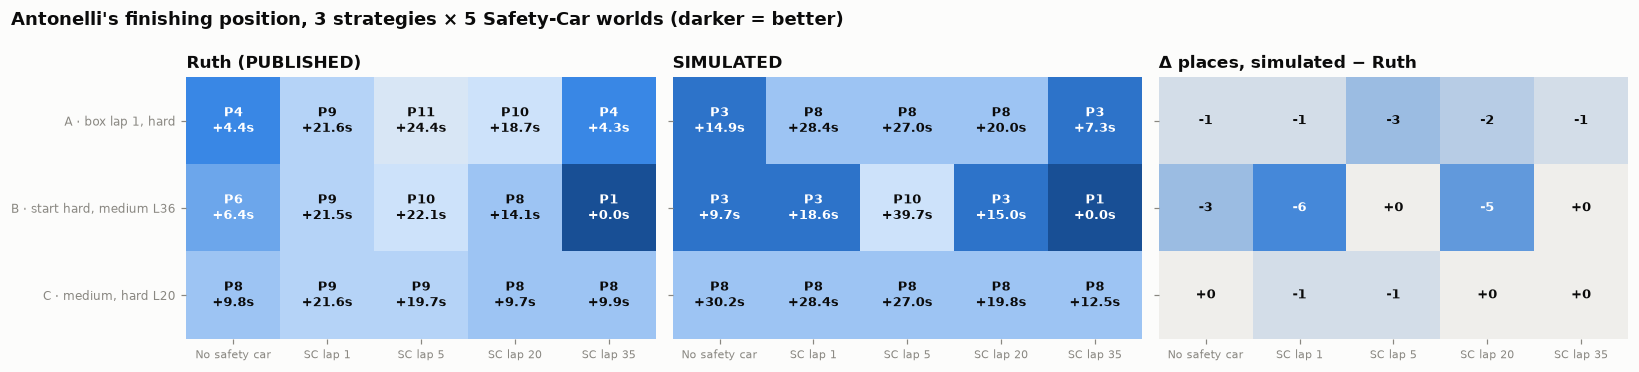

In [48]:
def grid_heatmap(ax, values: pd.DataFrame, gaps: pd.DataFrame | None, title: str, cmap, vmin, vmax, fmt, show_y=True):
    ax.imshow(values.to_numpy(dtype=float), cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    for r_ in range(values.shape[0]):
        for c_ in range(values.shape[1]):
            v = values.iat[r_, c_]
            norm = (v - vmin) / (vmax - vmin)
            dark = (norm < 0.45) if cmap is POS_CMAP else (abs(v) >= 4)
            txt = fmt(v) + (f"\n+{gaps.iat[r_, c_]:.1f}s" if gaps is not None else "")
            ax.text(c_, r_, txt, ha="center", va="center", fontsize=8.5, color="white" if dark else INK, fontweight="bold")
    ax.set_xticks(range(5), [SC_TITLE[s] for s in SC_ORDER], fontsize=7.5)
    ax.set_yticks(range(3), [STRAT_NAME[s] for s in values.index] if show_y else [""] * 3, fontsize=8)
    ax.set_title(title, loc="left"); ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)

POS_CMAP = matplotlib.colors.LinearSegmentedColormap.from_list("positions", ["#184f95", "#3987e5", "#86b6ef", "#cde2fb", "#f0efec"])
DIV_CMAP = matplotlib.colors.LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
fig, axes = plt.subplots(1, 3, figsize=(15, 3.4))
grid_heatmap(axes[0], ruth_grid, ruth_gaps, "Ruth (PUBLISHED)", POS_CMAP, 1, 13, lambda v: f"P{int(v)}")
grid_heatmap(axes[1], sim_grid, sim_gaps, "SIMULATED", POS_CMAP, 1, 13, lambda v: f"P{int(v)}", show_y=False)
grid_heatmap(axes[2], sim_grid - ruth_grid, None, "Δ places, simulated − Ruth", DIV_CMAP, -7, 7, lambda v: f"{int(v):+d}", show_y=False)
fig.suptitle("Antonelli's finishing position, 3 strategies × 5 Safety-Car worlds (darker = better)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "09_grid_comparison"); plt.show()

#### What the scenario grid tells us

In this baseline reconstruction, the lap-one stop and hard start both finish P3 without a Safety Car, but the
hard start is 5.19 seconds quicker. Ranking by finishing position first and winner gap second, the hard start
is preferred in four of the five scenarios. The conventional plan finishes P8 throughout; its 0.04-second
advantage over the lap-one stop in the SC-lap-5 scenario is effectively a near-tie, not a robust strategic
distinction.

These conclusions depend on the assumptions. Raising Hard degradation from 0.015 to 0.05 s/lap moves the
lap-one stop from P3 to P8 in the no-SC race, while the hard start finishes P5 and remains preferred. Traffic,
starting offsets and restart rules also affect the comparison. These are conditional model outputs, not
validated race predictions.

### 9.2 Antonelli's position, lap by lap

Each panel is one Safety-Car world; the shaded band marks the leader's three laps behind the Safety Car, and the
markers show pit stops. In the SC-lap-1 panel A and C coincide (C is drawn on top).

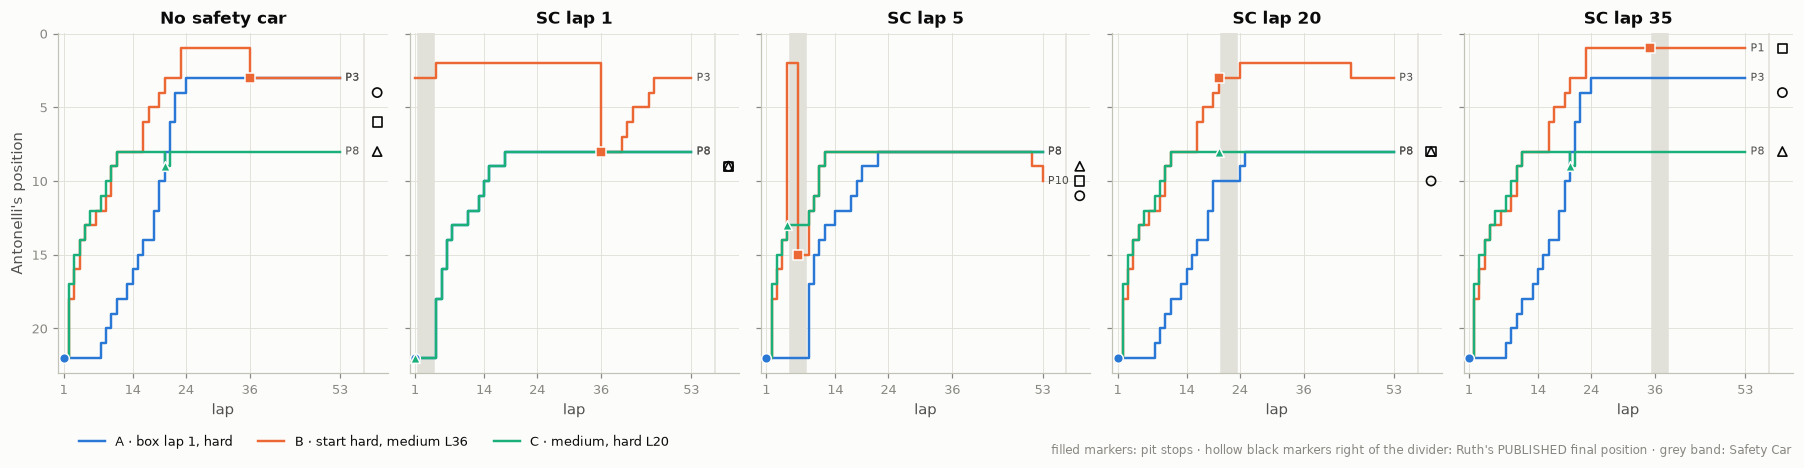

In [49]:
fig, axes = plt.subplots(1, 5, figsize=(16.5, 4.0), sharey=True)
for ax, sc in zip(axes, SC_ORDER):
    if sc != "none":
        ax.axvspan(int(sc) + 0.5, int(sc) + 3.5, color=GRID, zorder=0)
    for s in "ABC":
        a = sim_results[(s, sc)].laps.query("car == @TARGET")
        ax.step(a["lap"], a["position"], where="post", color=STRAT_COLOR[s], lw=1.6, label=STRAT_NAME[s])
        pits = a[a["pit_loss_s"] > 0]
        ax.scatter(pits["lap"], pits["position"], marker=STRAT_MARKER[s], s=40, color=STRAT_COLOR[s],
                   edgecolor=SURFACE, linewidth=1.0, zorder=4)
        ax.text(54, a["position"].iloc[-1], f"P{a['position'].iloc[-1]}", color=INK2, fontsize=7.5, va="center")
        rp = ruth_grid.loc[s, sc]
        ax.scatter([60], [rp], marker=STRAT_MARKER[s], s=36, facecolor="none", edgecolor=INK, linewidth=1.1, zorder=4)
    ax.axvline(57.5, color=GRID, lw=1)
    ax.set(title=SC_TITLE[sc], xlabel="lap", xlim=(0, 62))
    ax.set_xticks([1, 14, 24, 36, 53])
axes[0].invert_yaxis(); axes[0].set_ylabel("Antonelli's position")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower left", ncol=3, bbox_to_anchor=(0.04, -0.06))
fig.text(0.99, -0.045, "filled markers: pit stops · hollow black markers right of the divider: Ruth's PUBLISHED final position · grey band: Safety Car",
         ha="right", fontsize=8, color=MUTED)
fig.tight_layout(); save(fig, "09_position_by_lap"); plt.show()

**What the panels show.**
* **No SC.**
  - A drops to last at its lap-1 stop, gains through the slow cars, and jumps the front-runners in their pit
    window.
  - B gains steadily on track until its lap-36 stop.
  - C flat-lines in a train.
* **SC lap 1.** B rises to P3 when the field stops (only Russell and Gasly stay ahead), passes Gasly on the first
  green lap and stays on the podium.
* **SC lap 5.** B's lap-7 cheap stop onto mediums drops it into the pack.
* **SC lap 35.** B is leading when the Safety Car comes, stops for 11 s instead of 22 s, and wins.

### 9.3 Race traces: gaps to a virtual car

As in Heilmeier et al. (Fig. 7), each car's elapsed time is plotted against a virtual car that laps at the
winner's average green-flag pace, and at the Safety-Car pace on the laps the **winner** spent behind the Safety
Car. Other cars' Safety-Car laps can carry other lap numbers (lapped cars), so the reference must not be
built from every car's labels.

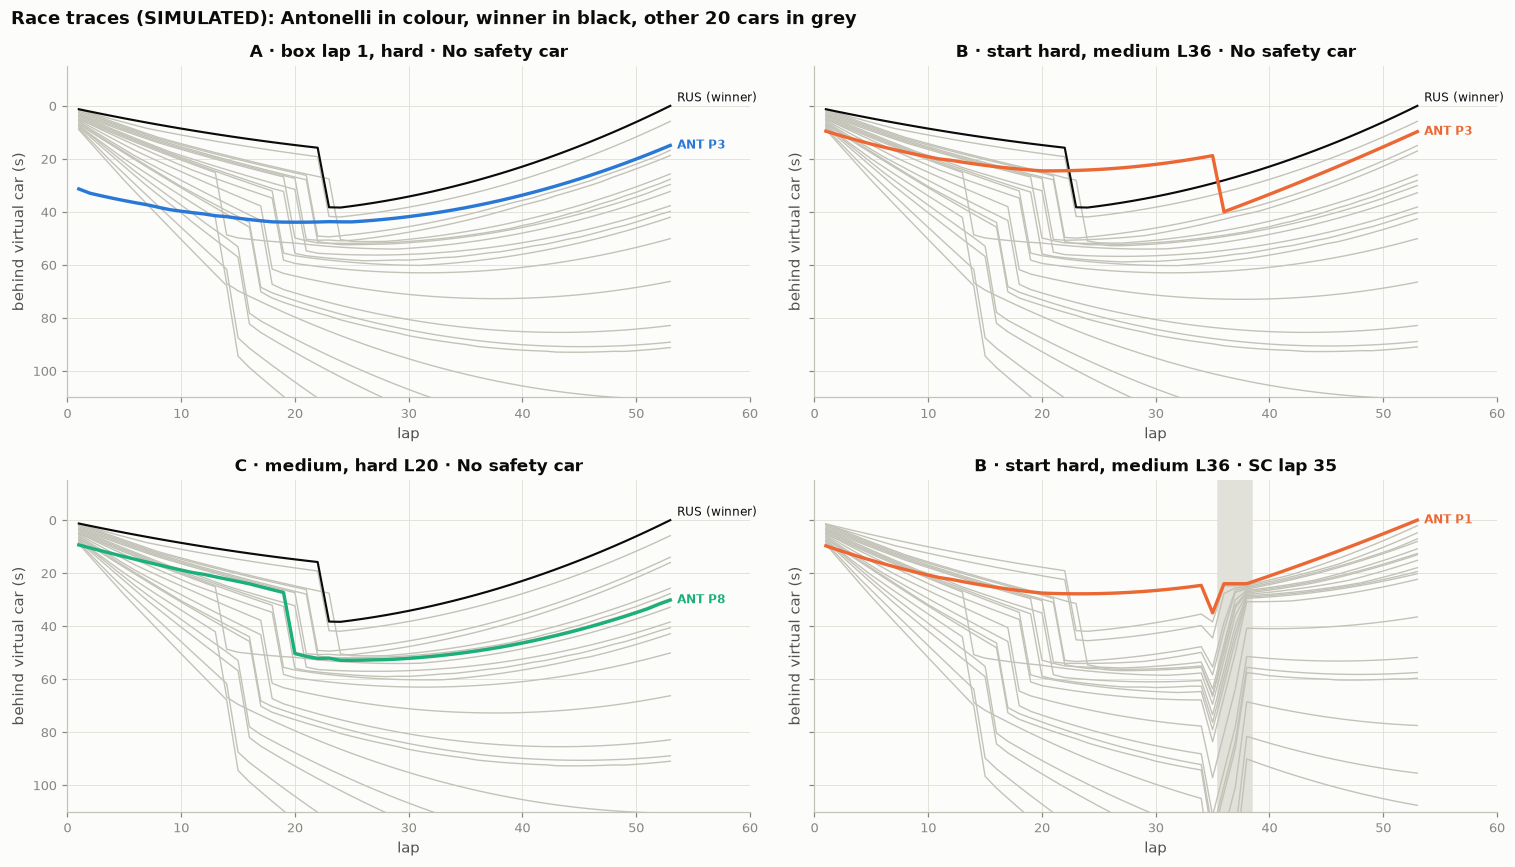

In [50]:
def race_trace(ax, res, title: str, strategy: str):
    L = res.laps
    winner = res.classification.index[0]
    neutral = set(L.loc[(L.car == winner) & (L.track_status == "SC"), "lap"])          # the winner's own laps
    avg_green = (res.classification.loc[winner, "race_time_s"] - len(neutral) * P0.sc_lap_s) / (53 - len(neutral))
    ref = np.cumsum([P0.sc_lap_s if k_ in neutral else avg_green for k_ in range(1, 54)])
    for car, g in L.groupby("car"):
        y = g["race_time_s"].to_numpy() - ref[g["lap"].to_numpy() - 1]
        if car == TARGET:
            ax.plot(g["lap"], y, color=STRAT_COLOR[strategy], lw=2.2, zorder=5)
            ax.text(53.6, y[-1], f"ANT P{res.position(TARGET)}", color=STRAT_COLOR[strategy], fontsize=8, va="center", fontweight="bold")
        elif car == winner:
            ax.plot(g["lap"], y, color=INK, lw=1.4, zorder=4)
            ax.text(53.6, y[-1] - 3, f"{car} (winner)", color=INK, fontsize=8, va="center")
        else:
            ax.plot(g["lap"], y, color=AXIS, lw=0.9, zorder=2)
    if neutral:
        ax.axvspan(min(neutral) - 0.5, max(neutral) + 0.5, color=GRID, zorder=0)
    ax.set(title=title, xlim=(0, 60), ylim=(110, -15), xlabel="lap", ylabel="behind virtual car (s)")

fig, axes = plt.subplots(2, 2, figsize=(14, 8.0), sharey=True)
for ax, (s, sc) in zip(axes.flat, [("A", "none"), ("B", "none"), ("C", "none"), ("B", "35")]):
    race_trace(ax, sim_results[(s, sc)], f"{STRAT_NAME[s]} · {SC_TITLE[sc]}", s)
fig.suptitle("Race traces (SIMULATED): Antonelli in colour, winner in black, other 20 cars in grey", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "09_race_traces"); plt.show()

In the lap-35 panel the Safety-Car mechanics are visible:
- the dip at lap 35 is the deployment: everyone behind the leader drives the rest of the lap at the slower
  full-course-yellow pace, so time gaps grow by about 117.6/86 ≈ 1.4×;
- over the three neutralised laps every grey line converges onto the leader at a finite rate as the queue
  forms;
- the lapped cars (the lowest grey lines) are neutralised at the same instants as the leader. Because
  they are on other lap numbers, their kink appears one lap earlier on this lap-based axis.

### 9.4 Tyre stints and pit timing

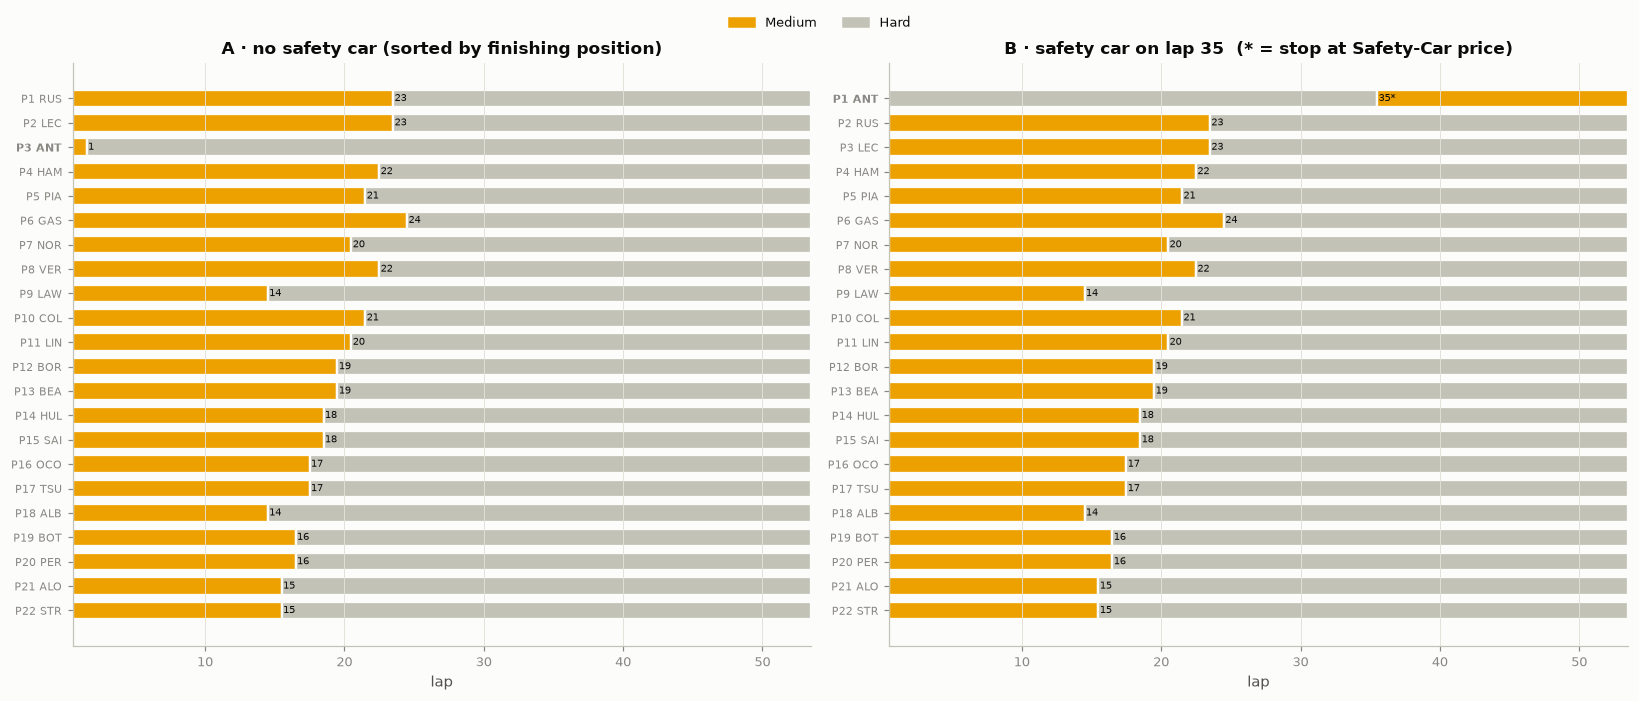

In [51]:
def stint_chart(ax, res, title: str):
    L = res.laps
    order = list(res.classification.index)
    for yi, car in enumerate(order):
        g = L[L.car == car].sort_values("lap")
        start = 1
        for comp, chunk in g.groupby((g["compound"] != g["compound"].shift()).cumsum()):
            c = chunk["compound"].iloc[0]
            ax.barh(yi, len(chunk), left=chunk["lap"].iloc[0] - 0.5, color=COMPOUND_COLOR[c], height=0.72,
                    edgecolor=SURFACE, linewidth=1.5)
        pits = g[g.pit_loss_s > 0]
        for _, r_ in pits.iterrows():
            ax.text(r_["lap"] + 0.6, yi, f"{int(r_['lap'])}" + ("*" if r_["pit_loss_s"] < 15 else ""), va="center", fontsize=6.5, color=INK)
    ax.set_yticks(range(len(order)), [f"P{i+1} {c}" for i, c in enumerate(order)], fontsize=7.5)
    ax.get_yticklabels()[order.index(TARGET)].set_fontweight("bold")
    ax.invert_yaxis(); ax.set(xlim=(0.5, 53.5), xlabel="lap", title=title); ax.grid(axis="y", visible=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
stint_chart(axes[0], sim_results[("A", "none")], "A · no safety car (sorted by finishing position)")
stint_chart(axes[1], sim_results[("B", "35")], "B · safety car on lap 35  (* = stop at Safety-Car price)")
handles = [matplotlib.patches.Patch(color=COMPOUND_COLOR[c], label=c.title()) for c in ["SOFT", "MEDIUM", "HARD"]]
fig.legend(handles=handles[1:], loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.03))
fig.tight_layout(); save(fig, "09_tyre_stints"); plt.show()

### 9.5 Gaps to the winner: Ruth and the simulation

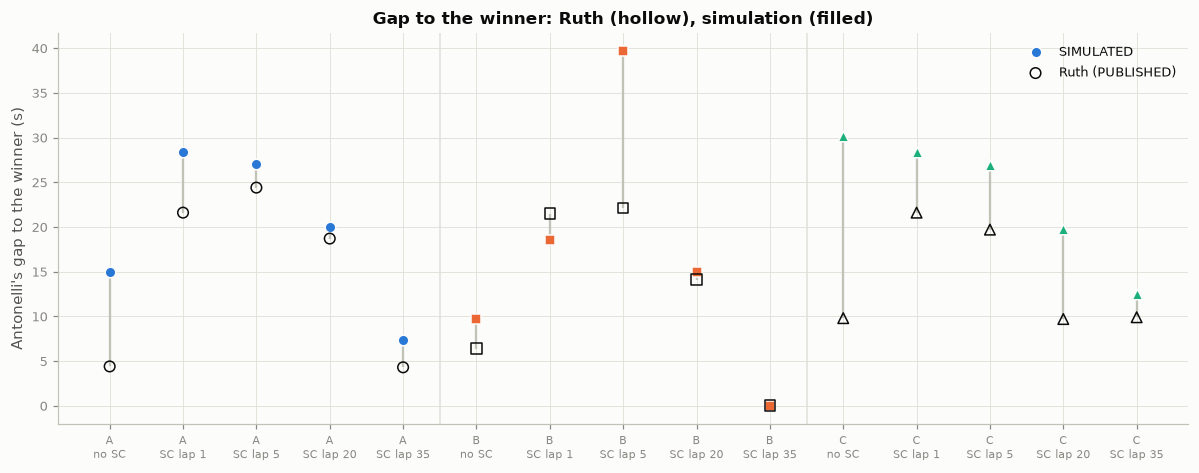

In [52]:
fig, ax = plt.subplots(figsize=(11, 4.4))
labels = [f"{s}\n{SC_TITLE[sc].replace('No safety car', 'no SC')}" for s in "ABC" for sc in SC_ORDER]
for i, (s, sc) in enumerate([(s, sc) for s in "ABC" for sc in SC_ORDER]):
    ax.vlines(i, ruth_gaps.loc[s, sc], sim_gaps.loc[s, sc], color=AXIS, lw=1.5)
    ax.scatter(i, sim_gaps.loc[s, sc], marker=STRAT_MARKER[s], s=48, color=STRAT_COLOR[s], zorder=4, edgecolor=SURFACE,
               label="SIMULATED" if i == 0 else None)
    ax.scatter(i, ruth_gaps.loc[s, sc], marker=STRAT_MARKER[s], s=48, facecolor="none", edgecolor=INK, zorder=5,
               label="Ruth (PUBLISHED)" if i == 0 else None)
ax.set_xticks(range(15), labels, fontsize=7.5)
ax.set(ylabel="Antonelli's gap to the winner (s)", title="Gap to the winner: Ruth (hollow), simulation (filled)")
for xv in (4.5, 9.5):
    ax.axvline(xv, color=GRID, lw=1)
ax.legend(loc="upper right"); fig.tight_layout(); save(fig, "09_gap_comparison"); plt.show()

### 9.6 Where does the time go? A decomposition of the no-SC races

Using the accounting identity, Antonelli's deficit to the winner splits exactly into:
- start offset;
- car pace ($53\,\Delta$);
- tyre cost (offsets, degradation and warm-up);
- traffic (actual minus clean-air lap time: dirty air plus being held);
- spacing after pit stops;
- pit losses.

Fuel and the reference lap cancel.

In [53]:
def decompose(res, car: str) -> pd.Series:
    L = res.laps[res.laps.car == car].sort_values("lap").reset_index(drop=True)
    green = (L["track_status"] != "SC").to_numpy()
    tyre = np.array([tyre_penalty(P0.compounds[c], int(a), bool(w)) for c, a, w in zip(L["compound"], L["tyre_age"], L["warmup_applied"])])
    clean = np.array([clean_air_lap_time(P0, res.classification.loc[car, "pace_s"], c, int(a), bool(w), int(k))
                      for c, a, w, k in zip(L["compound"], L["tyre_age"], L["warmup_applied"], L["lap"])])
    traffic = np.where(green, L["lap_time_s"].to_numpy() - clean, 0.0)
    start = L["race_time_s"].iloc[0] - L.loc[0, ["lap_time_s", "pit_loss_s", "gap_adjust_s"]].sum()
    return pd.Series({"start offset": start, "car pace (53·Δ)": res.classification.loc[car, "pace_s"] * green.sum(),
                      "tyres": float(tyre[green].sum()), "traffic (dirty air + held)": float(traffic.sum()),
                      "pit loss": L["pit_loss_s"].sum(), "spacing after pit stops": L["gap_adjust_s"].sum()})

dec = {}
for s in "ABC":
    res = sim_results[(s, "none")]
    w = res.classification.index[0]
    dec[f"{s}: ANT − {w}"] = decompose(res, TARGET) - decompose(res, w)
dec = pd.DataFrame(dec)
dec.loc["TOTAL = gap to winner"] = dec.sum()
display(dec.round(2))

,A: ANT − RUS,B: ANT − RUS,C: ANT − RUS
start offset,8.34,8.34,8.34
car pace (53·Δ),-0.53,-0.53,-0.53
tyres,5.11,-2.33,-1.15
traffic (dirty air + held),2.00,4.25,22.39
pit loss,0.00,0.00,0.00
spacing after pit stops,0.00,0.00,1.12
TOTAL = gap to winner,14.92,9.73,30.16


**The trade-off in seconds** (rows sum exactly to the simulated gap):
- **A** pays the pit-lane start and about 5 s more tyre cost than Russell (52 laps on one hard), but little in
  traffic.
- **B** has cheaper tyres than Russell and loses a few seconds in traffic.
- **C** has tyres close to Russell's but loses heavily in traffic, held up for most of the race.

The lap-1 stop's case rests on **avoided traffic loss exceeding extra tyre cost**, exactly as Ruth argues. Under
time-feasible passing, which makes passes slow, the hard start also avoids most traffic, which is why the two plans tie.

---
## 10. Sensitivity analysis

Two kinds of experiment are kept strictly apart:
* **§10.1 Ruth's own sensitivity claim**, reproduced exactly as she states it;
* **§10.2–10.9 our independent experiments**, which vary the assumptions *we* had to make, plus Ruth's
  parameters within plausible ranges.

All are run with the baseline model unless stated otherwise.

In [54]:
VARIANTS: list[dict] = []          # every variant matrix, for the robustness summary in 10.8


def run_variant(label: str, family: str, params=None, pace_set=None, field_laps=None, strategies=None,
                keep: bool = True) -> pd.DataFrame:
    params = params or P0
    pace_vec = pace_set or FW
    m, _ = run_matrix(SPEC, grid, pace_vec, params=params, strategies=strategies or STRATS, field_laps=field_laps or FIELD_LAPS)
    if keep:
        VARIANTS.append({"label": label, "family": family, "matrix": m, "params": params, "pace": pace_vec,
                         "field_laps": field_laps or FIELD_LAPS, "strategies": strategies or STRATS})
    return m

### 10.1 Ruth's stated sensitivity: hard degradation 0.05 s/lap

*"If the hard degrades linearly at 0.05 s/lap instead, the lap one stop drops to P10 with no safety car and the
hard start wins. That assumption is the whole argument."* We change only the hard's degradation, for every car.

In [55]:
show = pd.concat({"baseline (0.015)": sim_grid, "hard 0.05": as_grid(hard005), "change": as_grid(hard005) - sim_grid}, axis=1)
display(show)
a0, a1 = sim_grid.loc["A", "none"], as_grid(hard005).loc["A", "none"]
print("PUBLISHED: lap-1 stop P4 -> P10 (−6 places), hard start becomes best.")
print(f"SIMULATED: lap-1 stop P{a0} -> P{a1} ({a0 - a1:+d} places); best plan with no SC: {best_plan(hard005)['none']}")
print(f"Hard ageing cost of A's 52-lap stint: {0.015 * 1326:.2f} s at 0.015 -> {0.05 * 1326:.2f} s at 0.05 "
      f"(+{0.035 * 1326:.2f} s); every rival's hard stint gets slower too.")

baseline (0.015)              hard 0.05               change            
sc_lap               none  1   5 20 35      none  1   5  20 35   none  1  5 20 35
strategy                                                                         
A                       3  8   8  8  3         8  8  12  10  8      5  0  4  2  5
B                       3  3  10  3  1         5  1   2   7  1      2 -2 -8  4  0
C                       8  8   8  8  8         8  8   8   8  8      0  0  0  0  0

PUBLISHED: lap-1 stop P4 -> P10 (−6 places), hard start becomes best.
SIMULATED: lap-1 stop P3 -> P8 (-5 places); best plan with no SC: B
Hard ageing cost of A's 52-lap stint: 19.89 s at 0.015 -> 66.30 s at 0.05 (+46.41 s); every rival's hard stint gets slower too.


**Ruth's claim is reproduced in direction and nearly in size.** The lap-1 stop falls five places (six in her
grid), and the hard start becomes the best plan with no Safety Car.

The arithmetic: A's 52 laps on one hard accumulate $d \times 1326$ s of
degradation. That is 19.9 s at 0.015 s/lap and 66.3 s at 0.05 s/lap, **46.4 s more**. Every rival's hard stint
also gets slower, which is why the comparison has to be simulated rather than read off.

### 10.2 Where does the lap-1 stop stop working? A fine sweep

The sweep uses:
- a **0.0005 s/lap** grid from 0.010 to 0.040;
- positions, gaps and race times;
- **one objective** throughout: lowest position, then smallest gap to the winner.

position           gap_to_winner_s               best plan
strategy        A    B    C               A      B      C          
hard_deg                                                           
0.0100        3.0  3.0  8.0           11.22   8.76  30.21         B
0.0125        3.0  3.0  8.0           12.95   9.00  30.32         B
0.0150        3.0  3.0  8.0           14.92   9.73  30.16         B
0.0175        3.0  3.0  8.0           16.65  11.72  30.27         B
0.0180        3.0  3.0  8.0           16.85  12.32  30.26         B
0.0185        3.0  4.0  8.0           17.29  15.49  30.05         A
0.0215        3.0  4.0  8.0           20.72  15.81  30.28         A
0.0220        4.0  4.0  8.0           21.41  15.84  30.26         B
0.0250        5.0  5.0  8.0           25.09  17.07  30.19         B
0.0300        5.0  5.0  8.0           29.29  16.55  30.16         B
0.0345        8.0  4.0  8.0           35.05  15.80  30.08         B
0.0400        8.0  5.0  8.0           38.95  18.83  30.07         B

Best plan changes at (sampled) degradation values: {0.01: 'B', 0.0185: 'A', 0.022: 'B'}


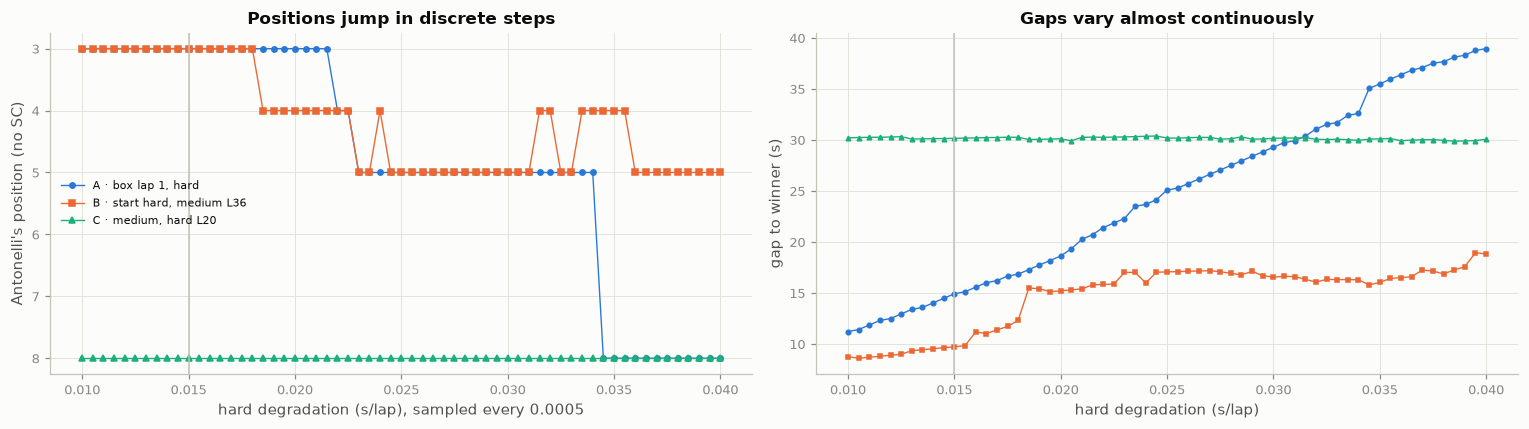

In [56]:
def deg_sweep(params, pace_vec, degs) -> pd.DataFrame:
    rows = []
    for dval in degs:
        m, _ = run_matrix(SPEC, grid, pace_vec, params=variant(params, HARD__deg_s_per_lap=float(dval)), sc_laps=(None,))
        for r_ in m.itertuples():
            rows.append({"hard_deg": round(float(dval), 4), "strategy": r_.strategy, "position": r_.position,
                         "gap_to_winner_s": r_.gap_to_winner_s, "race_time_s": r_.race_time_s, "sc_lap": "none"})
    return pd.DataFrame(rows)

fine = np.round(np.arange(0.010, 0.04001, 0.0005), 4)
sweep = deg_sweep(P0, FW, fine)
sweep.to_csv(TAB / "hard_degradation_fine_sweep.csv", index=False)
best_by_deg = sweep.groupby("hard_deg")[["strategy", "position", "gap_to_winner_s", "sc_lap"]].apply(lambda g: best_plan(g)["none"])
wide = sweep.pivot(index="hard_deg", columns="strategy", values=["position", "gap_to_winner_s"])
wide["best plan"] = best_by_deg
targets = [0.010, 0.0125, 0.015, 0.0175, 0.018, 0.0185, 0.0215, 0.022, 0.025, 0.03, 0.0345, 0.04]
display(wide[np.isclose(wide.index.to_numpy()[:, None], targets).any(axis=1)])
changes = best_by_deg[best_by_deg != best_by_deg.shift()]
print("Best plan changes at (sampled) degradation values:", {float(k): v for k, v in changes.items()})

fig, axes = plt.subplots(1, 2, figsize=(14, 4.0))
for s in "ABC":
    g = sweep[sweep.strategy == s]
    axes[0].plot(g.hard_deg, g.position, marker=STRAT_MARKER[s], ms=3.5, lw=0.9, color=STRAT_COLOR[s], label=STRAT_NAME[s])
    axes[1].plot(g.hard_deg, g.gap_to_winner_s, marker=STRAT_MARKER[s], ms=3.0, lw=0.9, color=STRAT_COLOR[s], label=STRAT_NAME[s])
for ax in axes:
    ax.axvline(0.015, color=AXIS, lw=1)
axes[0].invert_yaxis(); axes[0].set(xlabel="hard degradation (s/lap), sampled every 0.0005", ylabel="Antonelli's position (no SC)",
                                    title="Positions jump in discrete steps")
axes[1].set(xlabel="hard degradation (s/lap)", ylabel="gap to winner (s)", title="Gaps vary almost continuously")
axes[0].legend(loc="center left", fontsize=7.5)
fig.tight_layout(); save(fig, "10_hard_deg_fine_sweep"); plt.show()

**Findings (our experiment).**
* At Ruth's 0.015 s/lap the lap-1 stop and the hard start are **tied at P3**, with the hard start about 5 s
  quicker. Under the single objective the hard start is preferred over the whole range 0.010–0.018 s/lap.
* The lap-1 stop is preferred only in a narrow band, 0.0185–0.0215 s/lap, where the hard start loses a
  position. That band appears because a car crosses the 0.35 s passing threshold, not because the lap-1 stop
  gets better.
* Positions move in **discrete jumps**, while gaps vary almost smoothly (right panel). The "best plan" therefore
  depends on how ties and near-ties at the passing threshold are resolved.
* Conclusion: there is no well-defined degradation "threshold" for the lap-1 stop in this model. A coarse,
  position-only sweep would suggest one; the fine sweep of positions and gaps shows that it does not exist.

The same question under alternative assumptions (coarser grid, every 0.0025 s/lap):

In [57]:
alts = {"baseline (Friday pace)": (P0, FW), "Saturday-rebased pace": (P0, PACE_SETS["saturday_rebased"]),
        "50/50 blended pace": (P0, PACE_SETS["blend_50_50"]),
        "instant pass (passed car yields)": (variant(P0, pass_resolution="passed_car_yields"), FW),
        "instant pass (passer jumps)": (variant(P0, pass_resolution="passer_jumps"), FW),
        "dirty air 0.10 s": (variant(P0, dirty_air_penalty_s=0.10), FW),
        "pass threshold 0.30": (variant(P0, pass_min_advantage_s=0.30), FW), "pass threshold 0.40": (variant(P0, pass_min_advantage_s=0.40), FW)}
coarse = np.round(np.arange(0.0, 0.06001, 0.0025), 4)
rows = {}
for name, (p_, pv) in alts.items():
    sw_ = deg_sweep(p_, pv, coarse)
    bb = sw_.groupby("hard_deg")[["strategy", "position", "gap_to_winner_s", "sc_lap"]].apply(lambda g: best_plan(g)["none"])
    rows[name] = {**{f"{d:.4f}": bb.loc[d] for d in coarse}}
alt_tbl = pd.DataFrame(rows).T
display(alt_tbl)
print("Best plan (no SC) by hard degradation; columns are s/lap. 'A=B' would denote an exact tie.")

,0.0000,0.0025,0.0050,0.0075,0.0100,0.0125,0.0150,0.0175,0.0200,0.0225,...,0.0375,0.0400,0.0425,0.0450,0.0475,0.0500,0.0525,0.0550,0.0575,0.0600
baseline (Friday pace),A,A,A,B,B,B,B,B,A,B,...,B,B,B,B,B,B,B,B,B,B
Saturday-rebased pace,A,A,A,A,A,A,A,A,B,B,...,B,B,B,B,B,B,B,B,B,B
50/50 blended pace,A=B,A,A,A,A,A,A,A,A,B,...,B,B,B,B,B,B,B,B,B,B
instant pass (passed car yields),A,A,A,A,A,A,A,B,B,B,...,B,B,B,B,B,B,B,C,C,C
instant pass (passer jumps),A=B,A,A=B,A,A,A,A,A,B,B,...,B,B,B,B,B,B,B,B,B,B
dirty air 0.10 s,A,A,A,A,B,B,B,B,B,B,...,B,B,B,B,B,B,B,B,B,B
pass threshold 0.30,A,A,A,A,A,A,B,B,B,B,...,B,B,B,B,B,B,B,B,B,B
pass threshold 0.40,A,A,A,A,B,B,B,A,A,A,...,B,B,B,B,B,B,B,B,B,B


Best plan (no SC) by hard degradation; columns are s/lap. 'A=B' would denote an exact tie.


Across reasonable alternatives, the switch from "lap-1 stop best" to "hard start best" happens somewhere between
about 0.008 and 0.023 s/lap, and at Ruth's 0.015 either plan can be best. **The robust statement is Ruth's own:
the lap-1 stop needs a nearly flat hard.** "How flat" cannot be pinned down more precisely than "within about
±0.01 s/lap of her value" without knowing her traffic model.

### 10.2b What do the Friday long runs say about hard degradation?

Ruth reads the Friday runs as showing the hard *"flat after warm-up"*. Here we estimate the degradation rate
directly.

Within one stint, tyre age and fuel burnt both rise by one per lap. The fitted slope of lap time against tyre
age is therefore $b = d - f$, and the degradation estimate is $\hat d = \hat b + f$. **It depends one-for-one on
the assumed fuel effect $f$; the stint alone cannot separate them.** The intervals below are 95 % OLS
intervals for $\hat b$ (independent errors), shifted by $f$, with the exact Student-t quantile (from SciPy;
2.030 for the pooled fit's 35 degrees of freedom). They do not include
uncertainty in $f$ or in track evolution.

In [58]:
hard_runs = lr_literal[lr_literal["compound"] == "HARD"]
rows = []
for drv, run in hard_runs.iterrows():
    g = fp2_laps[(fp2_laps.Driver == drv) & (fp2_laps.Stint == run.stint) & fp2_laps.LapNumber.isin(run.lap_numbers)]
    for f in (0.05, 0.07, 0.09):
        fit = pace.fuel_corrected_degradation(g.TyreLife.to_numpy(), g.LapTime_s.to_numpy(), f)
        rows.append({"driver": drv, "fuel effect f (s/lap)": f, "clean laps": fit["n_laps"],
                     "raw slope b (s/lap)": round(fit["slope_s_per_lap"], 4), "SE(b)": round(fit["slope_se"], 4),
                     "d̂ = b + f": round(fit["deg_hat"], 3), "95% CI low": round(fit["deg_ci_low"], 3), "95% CI high": round(fit["deg_ci_high"], 3),
                     "residual sd (s)": round(fit["resid_sd_s"], 3), "lag-1 resid. corr.": round(fit["resid_lag1_corr"], 2)})
deg_fits = pd.DataFrame(rows).set_index(["driver", "fuel effect f (s/lap)"])
display(deg_fits)

# pooled fit over the three longest hard runs, with one intercept per driver, at f = 0.07
long3 = [d for d in hard_runs.sort_values("clean_laps", ascending=False).index[:3]]
X, y = [], []
for j, drv in enumerate(long3):
    run = hard_runs.loc[drv]
    g = fp2_laps[(fp2_laps.Driver == drv) & (fp2_laps.Stint == run.stint) & fp2_laps.LapNumber.isin(run.lap_numbers)]
    for age, t in zip(g.TyreLife, g.LapTime_s):
        X.append([1.0 if i == j else 0.0 for i in range(len(long3))] + [age]); y.append(t)
X, y = np.array(X), np.array(y)
beta, *_ = np.linalg.lstsq(X, y, rcond=None)
resid = y - X @ beta
dof = len(y) - X.shape[1]
cov = (resid @ resid / dof) * np.linalg.inv(X.T @ X)
b, se = beta[-1], np.sqrt(cov[-1, -1])
print(f"Student-t quantile for {dof} degrees of freedom: t = {pace.t975(dof):.4f} (SciPy)")
print(f"Pooled ({', '.join(long3)}; {len(y)} laps, one intercept per driver): b = {b:+.4f} ± {pace.t975(dof) * se:.4f} s/lap (95%) "
      f"-> with f = 0.07, d̂ = {b + 0.07:.3f} s/lap [{b + 0.07 - pace.t975(dof) * se:.3f}, {b + 0.07 + pace.t975(dof) * se:.3f}]")
print(f"For d̂ to equal Ruth's 0.015 s/lap the fuel effect would have to be about {0.015 - b:.3f} s/lap "
      f"(or track evolution would have to slow laps by ~{0.07 - (0.015 - b):.3f} s/lap).")

clean laps  raw slope b (s/lap)   SE(b)  d̂ = b + f  95% CI low  95% CI high  residual sd (s)  lag-1 resid. corr.
driver fuel effect f (s/lap)                                                                                                                   
LAW    0.05                           12               0.0291  0.0240       0.079       0.026        0.133            0.287                0.07
       0.07                           12               0.0291  0.0240       0.099       0.046        0.153            0.287                0.07
       0.09                           12               0.0291  0.0240       0.119       0.066        0.173            0.287                0.07
ANT    0.05                           17               0.0181  0.0233       0.068       0.018        0.118            0.471                0.11
       0.07                           17               0.0181  0.0233       0.088       0.038        0.138            0.471                0.11
       0.09                           17               0.0181  0.0233       0.108       0.058        0.158            0.471                0.11
RUS    0.05                           10              -0.0010  0.0450       0.049      -0.055        0.153            0.409               -0.48
       0.07                           10              -0.0010  0.0450       0.069      -0.035        0.173            0.409               -0.48
       0.09                           10              -0.0010  0.0450       0.089      -0.015        0.193            0.409               -0.48
NOR    0.05                            5               0.0989  0.0570       0.149      -0.032        0.330            0.219               -0.86
       0.07                            5               0.0989  0.0570       0.169      -0.012        0.350            0.219               -0.86
       0.09                            5               0.0989  0.0570       0.189       0.008        0.370            0.219               -0.86
GAS    0.05                            8              -0.0911  0.0514      -0.041      -0.167        0.085            0.333               -0.12
       0.07                            8              -0.0911  0.0514      -0.021      -0.147        0.105            0.333               -0.12
       0.09                            8              -0.0911  0.0514      -0.001      -0.127        0.125            0.333               -0.12

Student-t quantile for 35 degrees of freedom: t = 2.0301 (SciPy)
Pooled (ANT, LAW, RUS; 39 laps, one intercept per driver): b = +0.0181 ± 0.0321 s/lap (95%) -> with f = 0.07, d̂ = 0.088 s/lap [0.056, 0.120]
For d̂ to equal Ruth's 0.015 s/lap the fuel effect would have to be about -0.003 s/lap (or track evolution would have to slow laps by ~0.073 s/lap).


**What this does and does not show.**
* The raw lap times of the three long hard runs are roughly flat or slightly rising over the stint
  ($\hat b$ near 0 to +0.03 s/lap).
* "Flat" raw lap times **while burning fuel** mean the tyre is losing time. With Ruth's own fuel effect
  (0.07 s/lap), the implied hard degradation is roughly **0.07–0.10 s/lap**, with wide intervals. That is well
  above her model value of 0.015 and even above her pessimistic 0.05.
* The estimate is only as good as the assumed fuel effect. The pooled raw slope is already above 0.015 s/lap
  *before* any fuel correction. For $\hat d$ to be 0.015 s/lap, the fuel effect would have to be about zero,
  or laps would have to be getting slower by ~0.07 s/lap for another reason (track or air temperature, engine
  modes).
* Residuals are autocorrelated for some runs (Russell, Norris), so the OLS intervals are approximate.
* **Track evolution** (a rubbering-in track usually gets *faster*) would push the implied degradation *higher*,
  not lower.
* Within-stint fits cannot settle the question, and nothing here is a measurement of race degradation. What
  can be said is that **the Friday data, read with Ruth's own fuel correction, do not support "flat"**. They
  point the other way, which reinforces her warning that the lap-1 stop's case *"is one you find out about on
  Sunday, not before"*.

### 10.3 Race-pace inputs (pre-registered alternatives, rounding, independent extraction)

The two pre-registered alternatives are read from the configuration (`pace.alternative_sets`). Every other pace
vector below is labelled as an additional sensitivity.

In [59]:
PRE_REGISTERED = list(SPEC.alternative_pace_sets)                     # read from the configuration
ADDITIONAL = [n for n in ("friday_weighted_unrounded", "saturday_rebased_unrounded", "friday_weighted_independent")
              if n not in PRE_REGISTERED]
pace_results = {}
for name in [SPEC.pace_set, *PRE_REGISTERED, *ADDITIONAL]:
    pace_results[name] = run_variant(f"pace: {name}", "pace", pace_set=PACE_SETS[name], keep=name != SPEC.pace_set)
for w in [0.25, 0.75]:
    vec = {d: (1 - w) * FW[d] + w * PACE_SETS["saturday_rebased"][d] for d in FW}
    pace_results[f"blend w={w}"] = run_variant(f"pace: blend w={w}", "pace", pace_set=vec)
print("baseline:", SPEC.pace_set, "| pre-registered alternatives (configuration):", PRE_REGISTERED,
      "| additional sensitivities, NOT pre-registered:", ADDITIONAL + ["blend w=0.25", "blend w=0.75"])
display(pd.concat({k: as_grid(v) for k, v in pace_results.items()}, axis=0))
display(pd.DataFrame({k: score(v) for k, v in pace_results.items()}).T)

baseline: friday_weighted | pre-registered alternatives (configuration): ['saturday_rebased', 'blend_50_50'] | additional sensitivities, NOT pre-registered: ['friday_weighted_unrounded', 'saturday_rebased_unrounded', 'friday_weighted_independent', 'blend w=0.25', 'blend w=0.75']


sc_lap                                none   1   5  20  35
                            strategy                      
friday_weighted             A            3   8   8   8   3
                            B            3   3  10   3   1
                            C            8   8   8   8   8
saturday_rebased            A            5  10  10  11   5
                            B            6   8  12   8   2
                            C           10  10  10  10  10
blend_50_50                 A            3  10  10   9   3
                            B            5   7  12   7   1
                            C            9  10  10   9   9
friday_weighted_unrounded   A            2   8   8   8   2
                            B            3   2  10   2   1
                            C            8   8   8   8   8
saturday_rebased_unrounded  A            5  10  10  11   5
                            B            6   8  12   9   2
                            C           10  10  10  10  10
friday_weighted_independent A            2   8   8   8   2
                            B            3   2  10   2   1
                            C            8   8   8   8   8
blend w=0.25                A            1  11  11   9   1
                            B            2   5  10   7   1
                            C            9  11  11   9   9
blend w=0.75                A            4  10  10   9   4
                            B            7   7  12   7   2
                            C           10  10  10   9  10

,exact,within ±1 (incl. exact),MAE (places),max |error|,mean signed (sim−Ruth),gap MAE (s),Spearman ρ
friday_weighted,5.0,10.0,1.60,6.0,-1.60,6.4,0.74
saturday_rebased,2.0,11.0,1.13,2.0,0.87,15.4,0.83
blend_50_50,1.0,13.0,1.07,2.0,0.00,4.4,0.84
friday_weighted_unrounded,5.0,8.0,1.87,7.0,-1.87,6.4,0.72
saturday_rebased_unrounded,1.0,11.0,1.20,2.0,0.93,15.3,0.82
friday_weighted_independent,5.0,8.0,1.87,7.0,-1.87,6.4,0.72
blend w=0.25,3.0,8.0,1.67,4.0,-0.47,4.2,0.81
blend w=0.75,2.0,11.0,1.13,2.0,0.47,10.0,0.74


**Findings on pace.**
- The pace reading moves the level of Antonelli's results more than any single traffic parameter. On
  Saturday-rebased pace he is only the 5th-fastest car, and most cells drop by one to three places.
- *Post-hoc observation (not adopted):* the 50/50 blend of the two readings comes closest to Ruth on both
  positions and gaps of all pace sets: 13 of 15 within one place, MAE 1.07 places, gap MAE 4.4 s.
  That is consistent with her remark that *"the truth is between the two"*, but it was found by looking at
  her numbers, so it is not evidence of what she used.
- Rounding the published values to 0.01 s, or applying the Bearman exception, changes individual cells. Results
  that hinge on a single pace difference sitting exactly at the 0.35 s threshold (next section) cannot be
  resolved from the published inputs.

### 10.4 Traffic and passing assumptions

In [60]:
fw_codes = list(FW)
knife = [(a, b, FW[b] - FW[a], PACE_SETS["friday_weighted_unrounded"][b] - PACE_SETS["friday_weighted_unrounded"][a])
         for a in fw_codes for b in fw_codes if abs(FW[b] - FW[a] - 0.35) < 0.006]
display(pd.DataFrame(knife, columns=["faster car", "slower car", "published Δ (s)", "unrounded Δ (s)"]).round(3))

traffic_variants = {
    "pass threshold 0.30": variant(P0, pass_min_advantage_s=0.30),
    "pass threshold 0.40": variant(P0, pass_min_advantage_s=0.40),
    "dirty air 0.10 s": variant(P0, dirty_air_penalty_s=0.10),
    "dirty air 0.40 s": variant(P0, dirty_air_penalty_s=0.40),
    "dirty air off": variant(P0, dirty_air_penalty_s=0.0),
    "min follow gap 0.3 s": variant(P0, min_follow_gap_s=0.3),
    "min follow gap 0.8 s": variant(P0, min_follow_gap_s=0.8),
    "pass basis: actual lap times": variant(P0, pass_basis="actual"),
    "instant pass, passed car yields": variant(P0, pass_resolution="passed_car_yields"),
    "instant pass, passer jumps (tow gain)": variant(P0, pass_resolution="passer_jumps"),
    "duel losses (TUM: 0.3 s each, +0.3 s passed car)": variant(P0, duel_loss_attacker_s=0.3, duel_loss_defender_s=0.6),
}
traffic_tbl = {k: run_variant(f"traffic: {k}", "traffic", params=v, keep=k != "dirty air off") for k, v in traffic_variants.items()}
display(pd.concat({k: as_grid(v) for k, v in traffic_tbl.items()}, axis=0))
display(pd.DataFrame({k: score(v) for k, v in traffic_tbl.items()}).T)

,faster car,slower car,published Δ (s),unrounded Δ (s)
0,PIA,GAS,0.35,0.348
1,LEC,GAS,0.35,0.343


sc_lap                                                     none  1   5  20  35
                                                 strategy                     
pass threshold 0.30                              A            4  8   8   8   4
                                                 B            4  4  10   4   1
                                                 C            8  8   8   8   8
pass threshold 0.40                              A            2  8  12   9   2
                                                 B            2  2  10   2   1
                                                 C            8  8   8   8   8
dirty air 0.10 s                                 A            3  8   8   8   3
                                                 B            3  3  10   3   1
                                                 C            8  8   8   8   8
dirty air 0.40 s                                 A            3  8   8   8   3
                                                 B            4  3   8   3   2
                                                 C            8  8   8   8   8
dirty air off                                    A            3  8   8   8   3
                                                 B            3  3  12   3   1
                                                 C            6  8   8   8   6
min follow gap 0.3 s                             A            3  8   8   8   3
                                                 B            3  3  10   3   1
                                                 C            5  8   8   8   5
min follow gap 0.8 s                             A            3  8   8   8   3
                                                 B            3  3  10   3   1
                                                 C            8  8   8   8   8
pass basis: actual lap times                     A            1  8   8   8   1
                                                 B            3  4  10   7   1
                                                 C            4  8   8   8   4
instant pass, passed car yields                  A            2  8   8   7   2
                                                 B            3  3  12   9   1
                                                 C            5  8   8   8   5
instant pass, passer jumps (tow gain)            A            1  8   8   2   1
                                                 B            3  3  12   3   1
                                                 C            5  8   8   8   5
duel losses (TUM: 0.3 s each, +0.3 s passed car) A            1  8   8   8   1
                                                 B            4  8  12   8   1
                                                 C            8  8   8   8   8

,exact,within ±1 (incl. exact),MAE (places),max |error|,mean signed (sim−Ruth),gap MAE (s),Spearman ρ
pass threshold 0.30,7.0,10.0,1.27,5.0,-1.27,6.9,0.74
pass threshold 0.40,5.0,10.0,1.73,7.0,-1.60,7.5,0.84
dirty air 0.10 s,5.0,10.0,1.60,6.0,-1.60,4.6,0.74
dirty air 0.40 s,3.0,9.0,1.73,6.0,-1.60,8.2,0.69
dirty air off,2.0,7.0,2.00,6.0,-1.73,4.2,0.81
min follow gap 0.3 s,3.0,8.0,2.00,6.0,-2.00,5.2,0.81
min follow gap 0.8 s,5.0,10.0,1.60,6.0,-1.60,7.6,0.74
pass basis: actual lap times,3.0,7.0,2.07,5.0,-2.07,7.6,0.87
"instant pass, passed car yields",2.0,6.0,2.07,6.0,-1.67,6.6,0.70
"instant pass, passer jumps (tow gain)",2.0,5.0,2.80,8.0,-2.53,6.8,0.68


**Findings on traffic.**
* **The knife edge.** On the published (rounded) pace, Leclerc and Piastri are *exactly* 0.35 s/lap faster than
  Gasly; unrounded, they are 0.343 and 0.348 s faster. Whether they may pass him depends on rounding.
* **How a permitted pass is resolved** (time crossing vs instant pass with either car absorbing the difference)
  is the most influential traffic choice. It is also the one Ruth's sentence *"a car passes when it's at least
  0.35 s/lap faster and within 1.2 s"* leaves most open. The two instant-pass readings are themselves far
  apart.
* **What "faster" means** (intrinsic vs traffic-affected lap time) also moves several cells.
* Dirty air and the minimum gap mostly move gaps and one or two places.

### 10.5 Competitor pit schedules (structured alternatives and seeded random permutations)

sc_lap                                none  1   5  20  35
                            strategy                     
by pace (fastest latest)    A            3  8   8   9   3
                            B            3  3  10   3   1
                            C            6  8   8   8   6
reversed (leaders earliest) A            5  8   8   6   5
                            B            4  3  10   3   1
                            C            8  8   8   1   8
everyone on lap 19          A            3  8   8   3   3
                            B            3  3  10   3   1
                            C            8  8   8   1   8

mean   min   25%   50%    75%   max
strategy sc_lap                                      
A        none     3.37   3.0   3.0   3.0   4.00   5.0
         1        8.00   8.0   8.0   8.0   8.00   8.0
         5        8.00   8.0   8.0   8.0   8.00   8.0
         20       6.04   3.0   5.0   6.0   7.00  11.0
         35       3.37   3.0   3.0   3.0   4.00   5.0
B        none     3.58   3.0   3.0   4.0   4.00   5.0
         1        3.00   3.0   3.0   3.0   3.00   3.0
         5       10.00  10.0  10.0  10.0  10.00  10.0
         20       3.54   1.0   3.0   4.0   4.00   7.0
         35       1.30   1.0   1.0   1.0   2.00   2.0
C        none     6.74   4.0   6.0   7.0   7.25   8.0
         1        8.00   8.0   8.0   8.0   8.00   8.0
         5        8.00   8.0   8.0   8.0   8.00   8.0
         20       4.92   1.0   4.0   5.0   6.00   8.0
         35       6.74   4.0   6.0   7.0   7.25   8.0

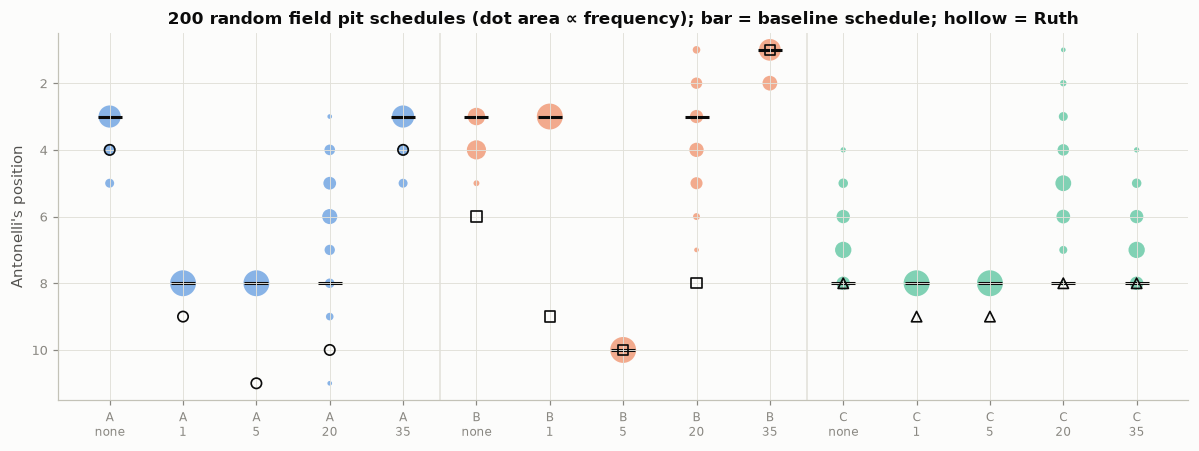

In [61]:
field_variants = {"by pace (fastest latest)": field_laps_for(SPEC, grid, "pace_linear", pace=FW),
                  "reversed (leaders earliest)": field_laps_for(SPEC, grid, "reverse"),
                  "everyone on lap 19": field_laps_for(SPEC, grid, "uniform")}
field_tbl = {k: run_variant(f"field: {k}", "field schedule", field_laps=v) for k, v in field_variants.items()}
display(pd.concat({k: as_grid(v) for k, v in field_tbl.items()}, axis=0))

mc_rows = []
for seed in range(200):
    m, _ = run_matrix(SPEC, grid, FW, field_laps=field_laps_for(SPEC, grid, "random", seed=seed))
    mc_rows.append(m.assign(seed=seed))
mc = pd.concat(mc_rows)
mc.to_csv(TAB / "field_schedule_permutations.csv", index=False)
cells_idx = [(s, sc) for s in "ABC" for sc in SC_ORDER]
mc_summary = mc.groupby(["strategy", "sc_lap"])["position"].describe()[["mean", "min", "25%", "50%", "75%", "max"]].reindex(cells_idx)
display(mc_summary.round(2))

fig, ax = plt.subplots(figsize=(11, 4.2))
for i, (s, sc) in enumerate(cells_idx):
    counts = mc[(mc.strategy == s) & (mc.sc_lap == sc)]["position"].value_counts()
    ax.scatter([i] * len(counts), counts.index, s=8 + counts.values * 1.4, color=STRAT_COLOR[s], alpha=0.55, edgecolor="none")
    ax.scatter(i, sim_grid.loc[s, sc], marker="_", s=260, color=INK, linewidth=2)
    ax.scatter(i, ruth_grid.loc[s, sc], marker=STRAT_MARKER[s], s=46, facecolor="none", edgecolor=INK, linewidth=1.1, zorder=4)
ax.set_xticks(range(15), [f"{s}\n{sc}" for s, sc in cells_idx], fontsize=8)
ax.invert_yaxis(); ax.set(ylabel="Antonelli's position", title="200 random field pit schedules (dot area ∝ frequency); bar = baseline schedule; hollow = Ruth")
for xv in (4.5, 9.5):
    ax.axvline(xv, color=GRID, lw=1)
fig.tight_layout(); save(fig, "10_field_schedule_permutations"); plt.show()

**Findings on field schedules.**
* With a Safety Car on lap 1 or 5 every rival stops under it, so the field's planned laps are irrelevant.
* With a Safety Car on lap 20 **who has already stopped** decides the outcome, and positions spread widely.
* With no Safety Car, the pit cycle determines which train Antonelli meets.
* The random permutations describe sensitivity to one unknown input. They are not a Monte Carlo forecast: the
  200 schedules are permutations of Ruth's window, not draws from a calibrated probability distribution.

### 10.6 Safety-Car timing: a strategy map

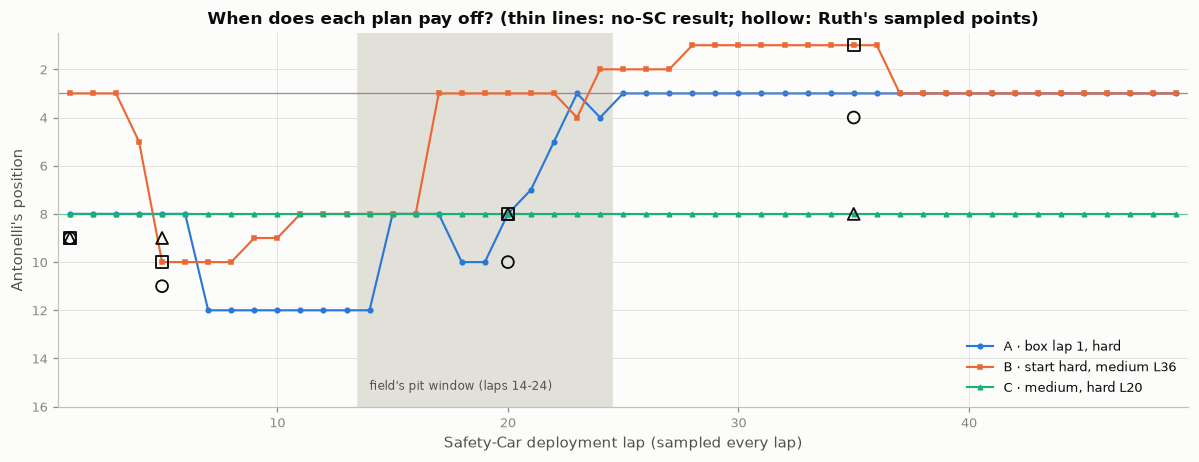

sc_lap,1,2,3,4,5,6,7,8,9,10,...,40,41,42,43,44,45,46,47,48,49
strategy,,,,,,,,,,,,,,,,,,,,,
A,8,8,8,8,8,8,12,12,12,12,...,3,3,3,3,3,3,3,3,3,3
B,3,3,3,5,10,10,10,10,9,9,...,3,3,3,3,3,3,3,3,3,3
C,8,8,8,8,8,8,8,8,8,8,...,8,8,8,8,8,8,8,8,8,8


In [62]:
sc_sweep = []
for s in "ABC":
    for sc in range(1, 50):
        r_ = run_scenario(SPEC, grid, FW, s, sc, FIELD_LAPS, record=False)
        sc_sweep.append({"strategy": s, "sc_lap": sc, "position": r_.position(TARGET), "gap": r_.gap_to_winner(TARGET)})
sc_sweep = pd.DataFrame(sc_sweep)
sc_sweep.to_csv(TAB / "sc_timing_sweep.csv", index=False)
fig, ax = plt.subplots(figsize=(11, 4.3))
ax.axvspan(13.5, 24.5, color=GRID, zorder=0); ax.text(14, 15.3, "field's pit window (laps 14-24)", fontsize=8, color=INK2)
for s in "ABC":
    g = sc_sweep[sc_sweep.strategy == s]
    ax.plot(g["sc_lap"], g["position"], color=STRAT_COLOR[s], label=STRAT_NAME[s], lw=1.4, marker=STRAT_MARKER[s], ms=3)
    for sc in ["1", "5", "20", "35"]:
        ax.scatter(int(sc), ruth_grid.loc[s, sc], marker=STRAT_MARKER[s], s=60, facecolor="none", edgecolor=INK, zorder=5, linewidth=1.2)
    ax.axhline(sim_grid.loc[s, "none"], color=STRAT_COLOR[s], lw=0.8, alpha=0.6)
ax.set_ylim(16, 0.5); ax.set(xlabel="Safety-Car deployment lap (sampled every lap)", ylabel="Antonelli's position", xlim=(0.5, 49.5),
                            title="When does each plan pay off? (thin lines: no-SC result; hollow: Ruth's sampled points)")
ax.legend(loc="lower right"); fig.tight_layout(); save(fig, "10_sc_timing_map"); plt.show()
display(sc_sweep.pivot(index="strategy", columns="sc_lap", values="position"))

**Reading the strategy map.**
* **A (lap-1 stop).**
  - Back at its no-SC result (P3) for a Safety Car on lap 23 or from lap 25 onwards, once the field has stopped.
  - Much worse for any Safety Car before or during the field's window: P8 for laps 1–6, P12 for laps 7–14.
    That is Ruth's "safety-car card", lap by lap.
* **B (hard start)** has distinct regimes:
  - a Safety Car on laps 1–3 lets it gain when the field stops (P3; lap 4: P5);
  - from lap 5 the cheap-stop window reaches lap 7, when a medium can reach the flag. Ruth's rule then makes
    Antonelli stop for mediums that must last up to 46 laps (P8–P10: a trap);
  - from a Safety Car on lap 17 onwards it is back on or next to the podium (P1–P4);
  - a Safety Car on laps 28–36, between the field's stops and its own, puts it in front.
* **C** finishes P8 for *every* deployment lap: the conventional plan is completely insensitive to Safety-Car
  timing.
* Ruth's five sampled laps fall on steep parts of these curves: moving "lap 5" or "lap 20" by two or three laps
  can change a position by several places.

### 10.7 The early-Safety-Car discrepancy

With an early Safety Car the hard start is where the simulation differs most from Ruth's numbers. Changing the
grid spacing changes the *whole field's* traffic, not just Antonelli's deficit, so here each mechanism is varied
**on its own**, with the baseline as the reference:

* **(a) Antonelli's start deficit only**: his pit-lane release delay is changed; the field is untouched.
* **(b) Field spacing only**: the grid headway is changed, with Antonelli's absolute start held fixed at 8.457 s.
  That is possible only while his release delay $8.457 - 21\,g_{\text{grid}}$ is non-negative, i.e.
  $g_{\text{grid}} \le 0.403$ s/slot. A headway of 0.5 s/slot would need a pit-lane starter released **2.0 s
  before** the last grid car; the model rejects it and it is not interpreted.
* **(c) How the grid effect is represented**: a starting headway (baseline) or TUM's lap-1 time loss.
* **(d) Mechanisms**:
  - the deployment-lap pace and the eligibility rule;
  - warm-up;
  - pass resolution, pass basis and duel losses;
  - catch-up pace, queue gap and the minimum gap (which also sets the restart spacing);
  - medium life, dirty air and pass threshold.
* **(e) Rival strategies**: field schedules, including 100 random ones, and pace sets.

For each case the tables give:
- Antonelli's deficit when the Safety Car comes out: the racing-speed time he still has to drive, and the time
  at which he reaches the line;
- his queue position at the restart;
- his final position.

In [63]:
def early_probe(p, sc: int, pace_vec=None, field_laps=None) -> dict:
    r_ = run_scenario(SPEC, grid, pace_vec or FW, "B", sc, field_laps or FIELD_LAPS, params=p)
    L = r_.laps
    a = L[L.car == TARGET].set_index("lap")
    t_d = r_.window.t_deploy
    racing, at_line = a.loc[sc, "green_end_s"] - t_d, a.loc[sc, "line_time_s"] - t_d
    return {"deficit at racing speed (s)": round(float(racing), 2), "deficit at the line (s)": round(float(at_line), 2),
            "queue pos at restart": int(a.loc[sc + 3, "position"]), "final": r_.position(TARGET)}

def probe_table(cases: dict) -> pd.DataFrame:
    rows = []
    for name, (p, kw) in cases.items():
        row = {"case": name}
        for sc in (1, 5):
            for key, val in early_probe(p, sc, **kw).items():
                row[(f"SC lap {sc}", key)] = val
        rows.append(row)
    out = pd.DataFrame(rows).set_index("case")
    out.columns = pd.MultiIndex.from_tuples(out.columns)
    return out

print("(a) Antonelli's pit-lane release delay only (field unchanged); Ruth: P9 (SC lap 1), P10 (SC lap 5)")
display(probe_table({f"release delay {g:g} s": (variant(P0, pit_lane_start_gap_s=float(g)), {}) for g in [0, 2, 4, 6, 8, 10, 12, 15]}))
print("(b) field grid headway only, Antonelli's absolute start fixed at 8.457 s (valid only for headways <= 0.403 s/slot)")
cases_b = {}
for gg in [0.05, 0.117, 0.2, 0.3, 0.4, 0.5]:
    delay = 8.457 - 21 * gg
    try:
        cases_b[f"grid headway {gg:g} s/slot (release delay {delay:.3f} s)"] = (variant(P0, grid_slot_gap_s=gg, pit_lane_start_gap_s=delay), {})
    except ValueError as err:
        print(f"    grid headway {gg:g} s/slot needs a release delay of {delay:.3f} s -> REJECTED, not interpreted ({err})")
display(probe_table(cases_b))
print("(c) the grid effect as a starting headway (baseline) or as TUM's lap-1 time loss (same 0.117 s per slot)")
display(probe_table({"headway 0.117 s/slot (baseline)": (P0, {}),
                     "lap-1 loss 0.117 s/slot, no headway": (variant(P0, grid_slot_gap_s=0.0, grid_lap1_loss_per_slot_s=0.117), {})}))

(a) Antonelli's pit-lane release delay only (field unchanged); Ruth: P9 (SC lap 1), P10 (SC lap 5)


SC lap 1                                                                       SC lap 5                                                   
                   deficit at racing speed (s) deficit at the line (s) queue pos at restart final deficit at racing speed (s) deficit at the line (s) queue pos at restart final
case                                                                                                                                                                            
release delay 0 s                         4.20                    5.51                    1     3                        7.23                    9.68                   14    10
release delay 2 s                         4.53                    6.06                    1     3                        7.23                    9.68                   14    10
release delay 4 s                         6.28                    8.42                    1     3                        7.69                   10.30                   14    10
release delay 6 s                         8.28                   11.10                    3     3                        9.69                   12.98                   15    10
release delay 8 s                        10.28                   13.78                    7     8                       11.44                   15.33                   17    10
release delay 10 s                       12.28                   16.46                   14     8                       13.44                   18.01                   21    10
release delay 12 s                       14.28                   19.14                   19     8                       15.19                   20.35                   22    10
release delay 15 s                       17.28                   23.16                   22     8                       18.19                   24.37                   22    10

(b) field grid headway only, Antonelli's absolute start fixed at 8.457 s (valid only for headways <= 0.403 s/slot)
    grid headway 0.5 s/slot needs a release delay of -2.043 s -> REJECTED, not interpreted (pit_lane_start_gap_s=-2.0429999999999993 is negative: not a physical value of this model)


SC lap 1                                                                       SC lap 5                          \
                                                  deficit at racing speed (s) deficit at the line (s) queue pos at restart final deficit at racing speed (s) deficit at the line (s)   
case                                                                                                                                                                                   
grid headway 0.05 s/slot (release delay 7.407 s)                         8.35                   11.19                    4     3                        9.76                   13.07   
grid headway 0.117 s/slot (release delay 6.000 s)                        8.28                   11.10                    3     3                        9.69                   12.98   
grid headway 0.2 s/slot (release delay 4.257 s)                          8.22                   11.01                    2     3                        9.36                   12.54   
grid headway 0.3 s/slot (release delay 2.157 s)                          8.22                   11.01                    2     3                        9.26                   12.40   
grid headway 0.4 s/slot (release delay 0.057 s)                          8.84                   11.77                    3     3                       10.73                   14.38   

                                                                              
                                                  queue pos at restart final  
case                                                                          
grid headway 0.05 s/slot (release delay 7.407 s)                    16    10  
grid headway 0.117 s/slot (release delay 6.000 s)                   15    10  
grid headway 0.2 s/slot (release delay 4.257 s)                     15    10  
grid headway 0.3 s/slot (release delay 2.157 s)                     15    10  
grid headway 0.4 s/slot (release delay 0.057 s)                     18    10

(c) the grid effect as a starting headway (baseline) or as TUM's lap-1 time loss (same 0.117 s per slot)


SC lap 1                                                                       SC lap 5                                                   
                                    deficit at racing speed (s) deficit at the line (s) queue pos at restart final deficit at racing speed (s) deficit at the line (s) queue pos at restart final
case                                                                                                                                                                                             
headway 0.117 s/slot (baseline)                            8.28                    11.1                    3     3                        9.69                   12.98                   15    10
lap-1 loss 0.117 s/slot, no headway                        8.28                    10.8                    1     3                        9.69                   12.98                   15    10

In [64]:
mech = {"baseline": P0,
        "deployment lap: 1.4 x own racing time": variant(P0, sc_deployment_remainder="own_lap_scaled"),
        "eligibility: first window crossing only": variant(P0, sc_eligibility="deployment_lap_only"),
        "warm-up: first lap of stint": variant(P0, warmup_policy="first_lap_of_stint"),
        "pass: instant, passed car yields": variant(P0, pass_resolution="passed_car_yields"),
        "pass: instant, passer jumps": variant(P0, pass_resolution="passer_jumps"),
        "pass basis: actual lap times": variant(P0, pass_basis="actual"),
        "duel losses (TUM)": variant(P0, duel_loss_attacker_s=0.3, duel_loss_defender_s=0.6),
        "catch-up pace factor 1.3": variant(P0, fcy_lap_factor=1.3), "catch-up pace factor 1.5": variant(P0, fcy_lap_factor=1.5),
        "queue gap 0.5 s": variant(P0, sc_queue_gap_s=0.5), "queue gap 1.2 s": variant(P0, sc_queue_gap_s=1.2),
        "min gap 0.8 s (also restart spacing)": variant(P0, min_follow_gap_s=0.8),
        "min gap 0.3 s (also restart spacing)": variant(P0, min_follow_gap_s=0.3),
        "medium life 30 laps": variant(P0, MEDIUM__max_life_laps=30), "dirty air off": variant(P0, dirty_air_penalty_s=0.0),
        "pass threshold 0.30": variant(P0, pass_min_advantage_s=0.30), "pass threshold 0.40": variant(P0, pass_min_advantage_s=0.40)}
print("(d) one mechanism at a time")
mech_tbl = probe_table({k: (v, {}) for k, v in mech.items()})
display(mech_tbl.xs("final", axis=1, level=1).join(mech_tbl.xs("queue pos at restart", axis=1, level=1), rsuffix=" restart"))

rows = {}
for name, fl in [("grid order (baseline)", FIELD_LAPS), ("pace order", field_laps_for(SPEC, grid, "pace_linear", pace=FW)),
                 ("reversed", field_laps_for(SPEC, grid, "reverse")), ("everyone lap 19", field_laps_for(SPEC, grid, "uniform"))]:
    rows[f"field: {name}"] = {f"SC lap {sc}": early_probe(P0, sc, field_laps=fl)["final"] for sc in (1, 5)}
for name in ["saturday_rebased", "blend_50_50", "friday_weighted_unrounded"]:
    rows[f"pace: {name}"] = {f"SC lap {sc}": early_probe(P0, sc, pace_vec=PACE_SETS[name])["final"] for sc in (1, 5)}
mc_early = pd.DataFrame([{f"SC lap {sc}": run_scenario(SPEC, grid, FW, "B", sc, field_laps_for(SPEC, grid, "random", seed=sd), record=False).position(TARGET)
                          for sc in (1, 5)} for sd in range(100)])
rows["field: 100 random schedules (range)"] = {c: f"{mc_early[c].min()}-{mc_early[c].max()}" for c in mc_early}
print("(e) rival strategies and pace")
display(pd.DataFrame(rows).T)

(d) one mechanism at a time


,SC lap 1,SC lap 5,SC lap 1 restart,SC lap 5 restart
case,,,,
baseline,3,10,3,15
deployment lap: 1.4 x own racing time,3,10,4,16
eligibility: first window crossing only,3,5,3,2
warm-up: first lap of stint,3,10,3,15
"pass: instant, passed car yields",3,12,2,15
"pass: instant, passer jumps",3,12,1,14
pass basis: actual lap times,4,10,2,14
duel losses (TUM),8,12,3,17
catch-up pace factor 1.3,3,10,1,15


(e) rival strategies and pace


,SC lap 1,SC lap 5
field: grid order (baseline),3,10
field: pace order,3,10
field: reversed,3,10
field: everyone lap 19,3,10
pace: saturday_rebased,8,12
pace: blend_50_50,7,12
pace: friday_weighted_unrounded,2,10
field: 100 random schedules (range),3-3,10-10


**What the isolated experiments establish, and what they do not.**
1. **Lead inheritance is explained.**
   - With a lap-1 Safety Car, Antonelli is 8.28 s of racing behind the leader at the deployment and reaches the
     line 11.10 s behind.
   - After their 11 s stops only the cars that reached the line less than 0.10 s after the leader (Russell,
     Gasly) stay ahead: queue P3, final P3.
2. **Antonelli's own deficit matters a great deal (a).** With the field untouched, a release delay of 8 s or more
   instead of 6 s gives a final **P8** with a lap-1 Safety Car, next to Ruth's P9; 0–6 s gives P3. The lap-5 cell
   is P10, Ruth's number, for every delay.
3. **Field spacing is not a clean lever (b).** Within the valid range (headway up to 0.403 s/slot with
   Antonelli's start fixed), the lap-1 cell stays P3 while the queue position at the restart moves between 2
   and 4. Larger headways would need a negative release delay and are rejected.
4. **Headway or lap-1 loss (c).** Representing the grid effect as TUM's lap-1 loss instead of a starting headway
   changes Antonelli's restart place but not his final positions. He restarts P1 instead of P3: the loss is
   spread over lap 1, so he reaches the line 10.80 s behind the leader, less than one 11 s stop.
5. **Mechanisms (d).**
   - The lap-1 cell flips with: TUM's duel losses (P8), the "actual lap time" pass basis (P4), and the pass
     threshold (0.30: P4; 0.40: P2).
   - The lap-5 cell is driven by the eligibility rule and the medium's tyre life (P5 instead of P10, if
     Antonelli does not take the cheap stop on lap 7) and by the pass resolution (P12 with instant passes).
6. **Rival pit schedules play no part (e).** Every rival stops under an early Safety Car; all 100 random schedules
   give identical results. Pace inputs move the lap-1 cell a lot: Saturday-rebased P8, the 50/50 blend P7.

**Conclusion.** The disagreement for B under a lap-1 Safety Car is *compatible* with several choices Ruth did
not publish:
- a larger effective pit-lane deficit;
- explicit duel losses;
- a different pace reading.

The experiments cannot tell which of these, if any, her model contains. **The cause of the remaining
disagreement is unresolved**; we do not identify a primary cause.

### 10.8 Robustness summary

All the one-at-a-time variants above (pace, traffic and passing, field schedules), plus the structural Safety-Car
and start variants below, are pooled. Ruth's own counterfactual (hard 0.05) and the extreme "dirty air off" case
are excluded. For each scenario we report the range across variants, the share within ±1 place of the baseline
result, and the share within ±1 of Ruth's.

**These shares describe this particular, uneven set of one-at-a-time variants. They are not probabilities or
confidence levels.**

In [65]:
struct_variants = {
    "deployment lap: 1.4 x own racing time": dict(params=variant(P0, sc_deployment_remainder="own_lap_scaled")),
    "eligibility: first window crossing only": dict(params=variant(P0, sc_eligibility="deployment_lap_only")),
    "warm-up: first lap of stint": dict(params=variant(P0, warmup_policy="first_lap_of_stint")),
    "catch-up pace factor 1.3": dict(params=variant(P0, fcy_lap_factor=1.3)),
    "catch-up pace factor 1.5": dict(params=variant(P0, fcy_lap_factor=1.5)),
    "SC queue gap 0.5 s": dict(params=variant(P0, sc_queue_gap_s=0.5)),
    "SC queue gap 1.2 s": dict(params=variant(P0, sc_queue_gap_s=1.2)),
    "medium life 30 laps": dict(params=variant(P0, MEDIUM__max_life_laps=30)),
    "grid headway 0.25 s/slot": dict(params=variant(P0, grid_slot_gap_s=0.25)),
    "pit-lane release delay 10 s": dict(params=variant(P0, pit_lane_start_gap_s=10.0)),
    "grid effect as TUM lap-1 loss": dict(params=variant(P0, grid_slot_gap_s=0.0, grid_lap1_loss_per_slot_s=0.117)),
    "hard warm-up also at race start": dict(params=variant(P0, warmup_at_race_start=True)),
    "A starts on soft": dict(strategies={**STRATS, "A": one_stop("SOFT", 1, "HARD", STRATS["A"].label)}),
    "B stops on lap 35": dict(strategies={**STRATS, "B": one_stop("HARD", 35, "MEDIUM", STRATS["B"].label)}),
}
struct_tbl = {k: run_variant(f"structure: {k}", "structure", **v) for k, v in struct_variants.items()}
display(pd.concat({k: as_grid(v) for k, v in struct_tbl.items()}, axis=0))

print(f"{len(VARIANTS)} variants pooled")
long = pd.concat([v["matrix"].assign(variant=v["label"], family=v["family"]) for v in VARIANTS])
rob = []
for s, sc in cells_idx:
    vals = long[(long.strategy == s) & (long.sc_lap == sc)]["position"]
    b_, rp = sim_grid.loc[s, sc], ruth_grid.loc[s, sc]
    share = ((vals - b_).abs() <= 1).mean()
    rob.append({"strategy": s, "sc_lap": sc, "Ruth": rp, "baseline": b_, "min": vals.min(),
                "median": vals.median(), "max": vals.max(), "share within ±1 of baseline": round(share, 2),
                "share within ±1 of Ruth": round(((vals - rp).abs() <= 1).mean(), 2),
                "verdict": "robust" if share >= 0.8 else ("moderately sensitive" if share >= 0.5 else "fragile")})
rob = pd.DataFrame(rob).set_index(["strategy", "sc_lap"])
rob.to_csv(TAB / "robustness_by_cell.csv")
display(rob)

claim_rows = []
for v in VARIANTS:
    m_h, _ = run_matrix(SPEC, grid, v["pace"], params=variant(v["params"], HARD__deg_s_per_lap=0.05), strategies=v["strategies"],
                        field_laps=v["field_laps"], sc_laps=(None,))
    claim_rows.append(claims(v["matrix"], m_h))
claim_support = pd.DataFrame(claim_rows).mean().rename("share of variants where the claim holds").round(2)
display(pd.DataFrame({"Ruth's grid": pd.Series(cl_ruth), "baseline": cl["holds in the simulation"], "share of variants": claim_support}))

sc_lap                                            none  1   5  20  35
                                        strategy                     
deployment lap: 1.4 x own racing time   A            3  8   8   8   3
                                        B            3  3  10   3   1
                                        C            8  8   8   8   8
eligibility: first window crossing only A            3  8   8   8   3
                                        B            3  3   5   3   1
                                        C            8  8   8   8   8
warm-up: first lap of stint             A            3  8   8  10   3
                                        B            3  3  10   3   1
                                        C            8  8   8   8   8
catch-up pace factor 1.3                A            3  8   8   8   3
                                        B            3  3  10   3   1
                                        C            8  8   8   8   8
catch-up pace factor 1.5                A            3  8   8  10   3
                                        B            3  3  10   3   1
                                        C            8  8   8   8   8
SC queue gap 0.5 s                      A            3  8   8   8   3
                                        B            3  3  10   3   1
                                        C            8  8   8   8   8
SC queue gap 1.2 s                      A            3  8   8   8   3
                                        B            3  3  10   3   1
                                        C            8  8   8   8   8
medium life 30 laps                     A            3  8   8   8   3
                                        B            3  3   5   9   1
                                        C            8  8   8   8   8
grid headway 0.25 s/slot                A            3  8   8   8   3
                                        B            4  8  10   3   2
                                        C            8  8   8   8   8
pit-lane release delay 10 s             A            3  8   8   8   3
                                        B            5  8  10   8   2
                                        C            8  8   8   8   8
grid effect as TUM lap-1 loss           A            3  8   8   8   3
                                        B            3  3  10   3   1
                                        C            8  8   8   8   8
hard warm-up also at race start         A            3  8   8   8   3
                                        B            3  3  10   3   1
                                        C            8  8   8   8   8
A starts on soft                        A            3  8   8   8   3
                                        B            3  3  10   3   1
                                        C            8  8   8   8   8
B stops on lap 35                       A            3  8   8   8   3
                                        B            3  3  10   3   1
                                        C            8  8   8   8   8

34 variants pooled


Ruth  baseline  min  median  max  share within ±1 of baseline  share within ±1 of Ruth               verdict
strategy sc_lap                                                                                                              
A        none       4         3    1     3.0    5                         0.79                     0.76  moderately sensitive
         1          9         8    8     8.0   11                         0.85                     0.97                robust
         5         11         8    8     8.0   12                         0.82                     0.18                robust
         20        10         8    2     8.0   11                         0.79                     0.26  moderately sensitive
         35         4         3    1     3.0    5                         0.79                     0.76  moderately sensitive
B        none       6         3    2     3.0    7                         0.85                     0.15                robust
         1          9         3    2     3.0    8                         0.76                     0.15  moderately sensitive
         5         10        10    5    10.0   12                         0.71                     0.71  moderately sensitive
         20         8         3    2     3.0    9                         0.71                     0.29  moderately sensitive
         35         1         1    1     1.0    2                         1.00                     1.00                robust
C        none       8         8    4     8.0   10                         0.76                     0.76  moderately sensitive
         1          9         8    8     8.0   11                         0.85                     0.97                robust
         5          9         8    8     8.0   11                         0.85                     0.97                robust
         20         8         8    1     8.0   10                         0.88                     0.88                robust
         35         8         8    4     8.0   10                         0.76                     0.76  moderately sensitive

,Ruth's grid,baseline,share of variants
"C1 lap-1 stop best plan, no SC",True,False,0.41
C2 lap-1 stop unaffected by a lap-35 SC (±1),True,True,1.00
C3 SC on lap 1/5/20 costs the lap-1 stop ≥4 places,True,True,0.91
C4 hard start wins with a lap-35 SC,True,True,0.82
C5 conventional plan within 1 place in all worlds,True,True,0.76
C6 hard deg 0.05: lap-1 stop drops ≥4 and hard start best (no SC),NaN,True,1.00


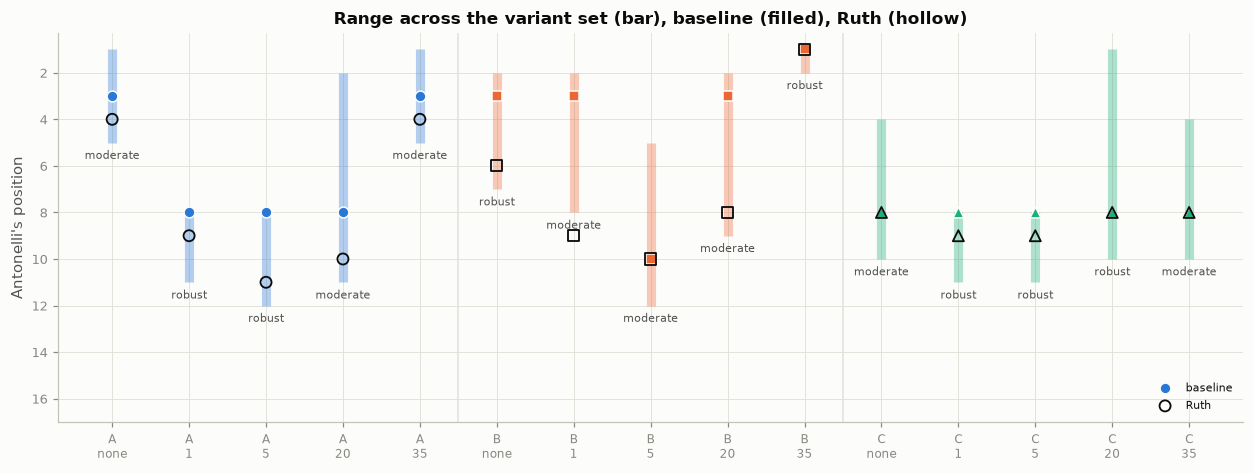

In [66]:
fig, ax = plt.subplots(figsize=(11.5, 4.4))
for i, (s, sc) in enumerate(cells_idx):
    r_ = rob.loc[(s, sc)]
    ax.vlines(i, r_["min"], r_["max"], color=STRAT_COLOR[s], lw=6, alpha=0.35)
    ax.scatter(i, r_["baseline"], marker=STRAT_MARKER[s], s=50, color=STRAT_COLOR[s], edgecolor=SURFACE, zorder=5, label="baseline" if i == 0 else None)
    ax.scatter(i, r_["Ruth"], marker=STRAT_MARKER[s], s=52, facecolor="none", edgecolor=INK, linewidth=1.2, zorder=6, label="Ruth" if i == 0 else None)
    ax.text(i, r_["max"] + 0.7, {"robust": "robust", "moderately sensitive": "moderate", "fragile": "fragile"}[r_["verdict"]],
            ha="center", fontsize=7, color=INK2)
ax.set_xticks(range(15), [f"{s}\n{sc}" for s, sc in cells_idx], fontsize=8)
ax.invert_yaxis(); ax.set(ylabel="Antonelli's position", ylim=(17, 0.3),
                          title="Range across the variant set (bar), baseline (filled), Ruth (hollow)")
for xv in (4.5, 9.5):
    ax.axvline(xv, color=GRID, lw=1)
ax.legend(loc="lower right", fontsize=7.5); fig.tight_layout(); save(fig, "10_robustness"); plt.show()

**Reading the robustness results.**
* **Cells.**
  - Robust (within one place of the baseline in at least 80 % of the 34 variants): seven cells (A/SC1, A/SC5, B/no SC,
    B/SC35, C/SC1, C/SC5, C/SC20).
  - Moderately sensitive: eight cells.
  - Fragile: none. The most sensitive cell, B with a lap-1 Safety Car, is within one place of the baseline in
    76 % of the variants.

  The sensitive cells are those that depend on the passing definition, the pace reading or the pit cycle.
* **Robust in our model ≠ agreeing with Ruth.** Compare the two share columns.
* **Claims.**
  - Holding in nearly all variants: the late-SC immunity of the lap-1 stop (100 %), the cost of an early or
    mid Safety Car (91 %) and Ruth's own degradation effect (100 %).
  - Depending on assumptions: "hard start *wins* with a lap-35 Safety Car" (82 %; a podium is robust) and
    "conventional plan insensitive" (76 %).
  - Holding in fewer than half: "lap-1 stop best in a quiet race" (41 %).
* Every variant shares the same lap-wise architecture and fixed rival strategies, so this summary cannot reveal
  errors common to all of them.

### 10.9 A warning about matching (post-hoc diagnostic, not a model choice)

It is tempting to pick whichever variant best matches Ruth's 15 numbers. The table ranks all variants by
agreement **only to show how weak that evidence would be**:
- dozens of variants are compared against 15 integer targets;
- several distinct mechanisms produce similar scores;
- the baseline model was developed with Ruth's numbers known.

The best-matching variant here is a **10 s pit-lane release delay** (13 of 15 within one place, MAE 0.87): it
moves B with a lap-1 Safety Car to P8, next to Ruth's P9. Ruth published 6 s, there is no Monza evidence for
either value, and the match was found by looking at her numbers. **None of these variants is adopted.**

In [67]:
match = pd.DataFrame([{"variant": v["label"], "family": v["family"], **score(v["matrix"])} for v in VARIANTS])
match = pd.concat([pd.DataFrame([{"variant": "baseline model", "family": "-", **score(sim_matrix)}]), match])
display(match.sort_values(["MAE (places)", "exact"], ascending=[True, False]).set_index("variant").head(14))

,family,exact,within ±1 (incl. exact),MAE (places),max |error|,mean signed (sim−Ruth),gap MAE (s),Spearman ρ
variant,,,,,,,,
structure: pit-lane release delay 10 s,structure,5,13,0.87,3,-0.73,8.8,0.82
pace: blend_50_50,pace,1,13,1.07,2,0.00,4.4,0.84
pace: saturday_rebased,pace,2,11,1.13,2,0.87,15.4,0.83
pace: blend w=0.75,pace,2,11,1.13,2,0.47,10.0,0.74
pace: saturday_rebased_unrounded,pace,1,11,1.20,2,0.93,15.3,0.82
traffic: pass threshold 0.30,traffic,7,10,1.27,5,-1.27,6.9,0.74
"traffic: duel losses (TUM: 0.3 s each, +0.3 s passed car)",traffic,5,9,1.27,3,-1.00,8.1,0.82
structure: grid headway 0.25 s/slot,structure,4,11,1.27,5,-1.13,7.7,0.82
structure: warm-up: first lap of stint,structure,6,11,1.47,6,-1.47,7.0,0.77


---
## 11. Discussion and limitations

### 11.1 What was reproduced, approximated, or could not be determined

| Item | Ruth (PUBLISHED) | Simulation | Verdict |
|---|---|---|---|
| FP2 long-run chart, Friday-weighted and Saturday-rebased pace | 18 / 22 / 10 values | ✓ (≤ 0.005 s) | **Reproduced** from public timing |
| Lap-1 stop best plan with no SC | A P4 > B P6 > C P8 | A P3 = B P3 > C P8 (B 5 s quicker) | **Not reproduced** (tie) |
| Lap-1 stop unaffected by a lap-35 SC | P4 = P4 | P3 = P3 | **Reproduced** |
| Early or mid SC costs the lap-1 stop | P9–P11 | P8 | **Approximated** (−5 places) |
| A/SC1 and C/SC1 give the same outcome | P9 +21.6 s twice | identical | **Same outcome**; identical race only shown in our implementation |
| Hard start wins with SC lap 35 | P1 | P1 | **Reproduced** in the baseline; P1–P2 across variants |
| Hard start with SC lap 1 / 5 | P9 / P10 | P3 / P10 | **SC 5 reproduced; SC 1 not (cause unresolved)** |
| Hard start with SC lap 20 | P8 | P3 | **Not reproduced** |
| Conventional "P8 or P9 whatever happens" | 8–9 | 8 everywhere | **Reproduced** |
| Hard deg 0.05 → lap-1 stop down, hard start best | −6 places | −5 | **Reproduced** (her own sensitivity) |
| Field: Friday → Russell wins, Gasly 5th | ✓ / P5 | ✓ / P5–6 | **Reproduced** |
| Field: Saturday → Gasly wins, Russell 5th | ✓ / P5 | ✓ / P3 | **Partly** |
| Gaps to the winner | 0–24 s | mean abs. error 6.4 s | **Not reproduced** |
| Which pace set Ruth used for Antonelli | — | — | **Cannot be determined** |
| Grid/pit-lane spacing, pass resolution, SC catch-up and restart, eligibility timing, field pit laps | — | — | **Cannot be determined**: unpublished |

### 11.2 Why the remaining discrepancies arise

1. **Passing semantics.** Ruth's rule says *when* a car may pass, not *how* the race times change when it does.
   Time-feasible crossing (used here) and instant passing are two readings. They differ by up to six places in
   some cells (§10.4).
2. **The early Safety Car.** B's result depends on several things, mostly unpublished (§10.7):
   - Antonelli's deficit, relative to the 11 s stop, at the moment the Safety Car comes out;
   - how the field restarts (spacing, and whether rivals pay a warm-up on that lap);
   - duel losses and the pass definition;
   - the eligibility timing and the tyre life.
3. **Trains and the 0.35 s threshold.** Many results are "the position behind a car that cannot be passed".
   The pace values are rounded to 0.01 s, so some pace differences sit exactly on the threshold.
4. **A free leader.** Russell leads unchallenged in clean air in most runs, so gaps to the winner are large.
   Ruth's smaller gaps suggest a more contested lead group.
5. **The pace reading.** Saturday-rebased pace changes the level of all results by several places (§10.3).

### 11.3 Limitations of the simulator

* **Deterministic and race-agnostic.** No start incidents, retirements, driver errors or lap-1 shuffling beyond
  the passing rule. The real race had a lap-1 retirement and a red flag (§13).
* **Starting model.** A converted lap-1 loss is used as a headway (TUM's own form is a sensitivity). There is no
  launch or pit-exit release model, and the pit-lane delay is not validated (§7.3).
* **Fixed rival strategies.** The field never reacts. Every recommendation is conditional on this opponent
  policy, while Ruth stresses that *"the value of a strategy is … what it does against what everyone else is
  doing"*.
* **Tyres.** Linear and identical for every driver; no thermal degradation; no tyre cooling behind the Safety
  Car except the hard warm-up policy. Friday data suggest degradation may be much higher than modelled (§10.2b).
* **Passing.** One global threshold. No tow or overtake-mode gain in the baseline, so passes take longer in dirty
  air than they do in reality at Monza. No team orders.
* **Safety Car.** One shared race clock, but still a *lap-wise* model:
  - cars are compared only at the line, and progress within a lap is assumed uniform in time (no track
    positions, no sectors). A car that catches the queue mid-lap is spaced at the next line;
  - the deployment instant is fixed at the leader's line crossing; the restart is one common instant $t_r$ (no
    "Safety Car in this lap" procedure, no leader-controlled restart);
  - the duration is fixed at three Safety-Car laps (Ruth's specification). Cars more than about 36 s behind the
    car ahead restart without having reached the queue; under FIA B5.13.5a the Safety Car would stay out longer;
  - lapped cars are queued in race-distance order, as if the unlapping procedure (B5.13.4c) had been used. The
    manoeuvre itself is not simulated;
  - the pit price is fixed at pit entry (a lump sum at the line); no pit-lane congestion or double stacking;
  - the pace and spacing values are TUM fits for 2014–2019 cars: full-course-yellow 1.4, Safety Car 1.6, queue
    gap 0.8 s. The restart spacing (0.5 s) follows from them;
  - no VSC or red flag.

  The Safety-Car treatment is internally consistent; it has not been validated against real Safety-Car traces.
* **Pace inputs.** One number per driver from Friday long runs with unknown fuel and mixed compounds; rounding
  matters at the passing threshold.
* **No independent validation.** Nothing in this notebook tests the model's predictions against observed race
  outcomes; the post-race epilogue (§13) is a single, different race and is not a validation.

### 11.4 Matching is not the same as being the same model

Agreement on a cell does not show that our model *is* Ruth's.
- B/SC35 = P1 arises in our model through a specific event order (stop before the queue forms), and the same
  position can arise through other mechanisms.
- The model was developed with Ruth's numbers known, so its agreement with them is not a blind test.
- Several modelling choices were dictated by physical consistency, which her model may or may not share.

The defensible claim is narrower: **the rules she published, completed with documented choices, reproduce the
logic of her recommendation and most of its qualitative pattern. Her exact numbers are approximated in about two
thirds of the cells. The remaining differences trace to choices her article does not determine.**

---
## 12. Conclusions

### 12.1 Answer to the research question

> *Can we independently reconstruct enough of Ruth's unpublished model to obtain similar Antonelli strategy
> predictions, and understand precisely why those strategies succeed or fail in different Safety-Car scenarios?*

**Partly.**
* **Inputs.** Her inputs are reconstructible from public timing to within the rounding of her published
  numbers.
* **Logic.** Her rules, made executable with explicit choices and made physically consistent (including a
  shared race clock for the Safety Car), reproduce most of the strategic logic:
  - the lap-1 stop is immune to a late Safety Car and badly exposed to an early or mid-race one;
  - a late Safety Car hands the race to the hard starter;
  - the conventional plan is insensitive;
  - the whole case collapses if the hard degrades like a medium.
* **Why, per scenario.** For each of the 15 scenarios we can name the mechanism that sets Antonelli's position in
  *our* model:
  - clean air vs trains;
  - who takes the cheap Safety-Car stop and when;
  - his deficit, at the deployment instant, compared with the 11 s stop;
  - how the field restarts;
  - which car he finishes stuck behind.
* **Limits.** We **cannot** say which mechanism produces her lap-1 Safety-Car number for the hard start (P3 in our model,
  P9 in hers), and we cannot reproduce her gaps to the winner.
* **The quiet race.** Whether the lap-1 stop beats the hard start in a race without a Safety Car turns out to be
  a near-tie that depends on the passing model and on hard degradation within about ±0.01 s/lap. That
  strengthens Ruth's own caveat.

### 12.2 From five worlds to an illustrative expected outcome

Ruth calls the Safety-Car risk at Monza *"a coin flip"*. Taking that literally (P(SC) = 0.5), with the deployment
lap uniform over laps 1–49 (both **ASSUMED** for illustration), the strategy map of §10.6 turns into an expected
finishing position for each plan. This is an illustration of method under an assumed Safety-Car distribution: it is not a forecast, and it is not
a Monte Carlo simulation of race uncertainty.

In [68]:
p_sc = 0.5
ev = []
for s in "ABC":
    g = sc_sweep[sc_sweep.strategy == s]["position"]
    pos_none = sim_grid.loc[s, "none"]
    dist = pd.concat([pd.Series([pos_none]), g])
    weights = np.r_[1 - p_sc, np.full(len(g), p_sc / len(g))]
    ev.append({"plan": STRAT_NAME[s], "no-SC position": pos_none,
               "expected position": round(float(np.dot(weights, dist)), 2),
               "P(top 5)": round(float(weights[(dist <= 5).to_numpy()].sum()), 2),
               "P(worse than P8)": round(float(weights[(dist > 8).to_numpy()].sum()), 2)})
display(pd.DataFrame(ev).set_index("plan"))

,no-SC position,expected position,P(top 5),P(worse than P8)
plan,,,,
"A · box lap 1, hard",3,4.46,0.79,0.10
"B · start hard, medium L36",3,3.52,0.88,0.06
"C · medium, hard L20",8,8.00,0.00,0.00


### 12.3 A limited scan of one-stop plans

Every one-stop plan for Antonelli (medium → hard and hard → medium, stopping on any lap from 1 to 52) is scored in
a quiet race and by expected position under the coin-flip Safety-Car model (deployment laps sampled every third
lap).

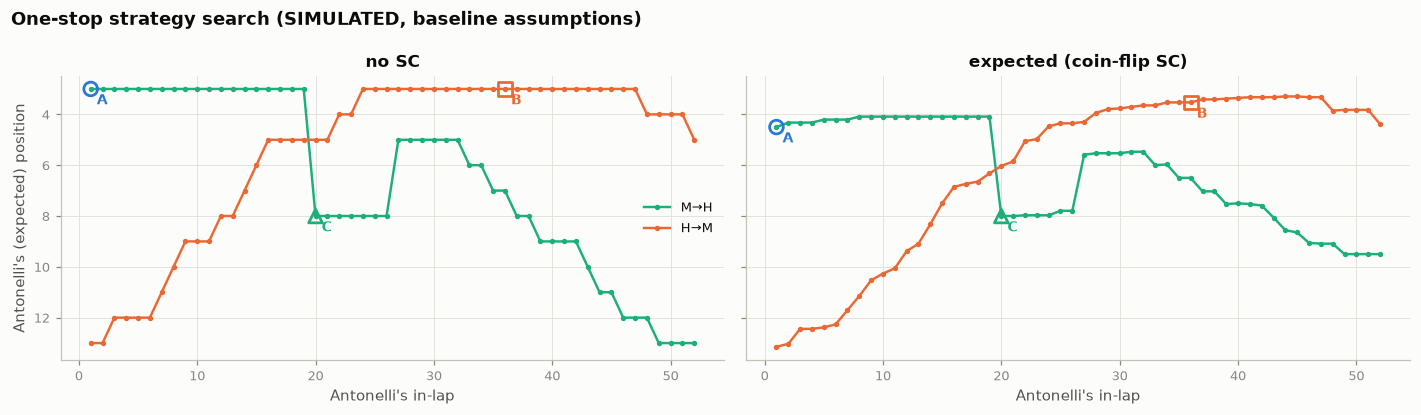

in_lap  no SC  expected (coin-flip SC)
                     plan                                        
best in a quiet race H→M       24      3                 4.470588
                     M→H        1      3                 4.500000
best in expectation  H→M       44      3                 3.294118
                     M→H        8      3                 4.088235

In [69]:
search = []
sc_grid_laps = list(range(1, 50, 3))
for start, to in [("MEDIUM", "HARD"), ("HARD", "MEDIUM")]:
    for L in range(1, 53):
        strat = one_stop(start, L, to)
        pos_none = run_scenario(SPEC, grid, FW, strat, None, FIELD_LAPS, record=False).position(TARGET)
        pos_sc = [run_scenario(SPEC, grid, FW, strat, sc, FIELD_LAPS, record=False).position(TARGET) for sc in sc_grid_laps]
        search.append({"plan": f"{start[0]}→{to[0]}", "in_lap": L, "no SC": pos_none,
                       "expected (coin-flip SC)": 0.5 * pos_none + 0.5 * np.mean(pos_sc)})
search = pd.DataFrame(search)
search.to_csv(TAB / "strategy_search.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, col in zip(axes, ["no SC", "expected (coin-flip SC)"]):
    for plan, color in [("M→H", STRAT_COLOR["C"]), ("H→M", STRAT_COLOR["B"])]:
        g = search[search.plan == plan]
        ax.plot(g["in_lap"], g[col], color=color, label=plan, marker="o", ms=2.5)
    for s, (lap, plan) in {"A": (1, "M→H"), "B": (36, "H→M"), "C": (20, "M→H")}.items():
        yv = search[(search.plan == plan) & (search.in_lap == lap)][col].iloc[0]
        ax.scatter(lap, yv, marker=STRAT_MARKER[s], s=80, facecolor="none", edgecolor=STRAT_COLOR[s], linewidth=1.8, zorder=5)
        ax.annotate(s, (lap, yv), xytext=(4, -10), textcoords="offset points", fontsize=9, color=STRAT_COLOR[s], fontweight="bold")
    ax.set(title=col, xlabel="Antonelli's in-lap")
axes[0].invert_yaxis(); axes[0].set_ylabel("Antonelli's (expected) position"); axes[0].legend(loc="center right")
fig.suptitle("One-stop strategy search (SIMULATED, baseline assumptions)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "12_strategy_search"); plt.show()
best = search.loc[search.groupby("plan")[["no SC"]].idxmin().values.ravel()]
best_ev = search.loc[search.groupby("plan")["expected (coin-flip SC)"].idxmin()]
display(pd.concat({"best in a quiet race": best.set_index("plan"), "best in expectation": best_ev.set_index("plan")}))

The search shows which regions of the plan space are good *in this model*, and how different the answer can be
for a quiet race and for an expected outcome:
- in a quiet race, several medium → hard and hard → medium plans tie at P3;
- under the coin-flip Safety-Car model, the late hard → medium stops have the best expected position;
- the coin-flip model (first table) also prefers the hard start (B) to the lap-1 stop (A). Because §10.2 showed that the A-versus-B comparison is a near-tie
sensitive to degradation and passing, the precise optimum should not be read as a recommendation.

### 12.4 Further work

The concluding section, *Project Roadmap and Future Work*, sets out the extensions that would build on this
analysis: a broader strategy optimisation, a Monte Carlo treatment of uncertainty, and an independent validation
on historical races.

---
## 13. Epilogue: what actually happened (ACTUAL, post-race, quarantined)

> **Data-integrity note.** Everything in this section comes from `data/post_race/`. Nothing in it was used to
> build, calibrate or choose between any part of the model. (During the source review a web search also showed
> the headline result; it was set aside at that point.)

In [70]:
POST = ROOT / "data" / "post_race"
actual = pd.read_csv(POST / "race_results_fastf1.csv").set_index("Abbreviation")
stints = pd.read_csv(POST / "race_stints.csv")
rc = pd.read_csv(POST / "race_control.csv")
pits = pd.read_csv(POST / "pit_stops.csv")
print("ACTUAL classification (top 10) and grid positions:")
display(actual[["TeamName", "GridPosition", "Position", "Status"]].head(10))
print("ACTUAL tyre stints, Antonelli and Russell:")
display(stints[stints.name_acronym.isin(["ANT", "RUS"])][["name_acronym", "stint_number", "compound", "lap_start", "lap_end"]]
        .set_index(["name_acronym", "stint_number"]))
events = rc[rc.message.str.contains("RED FLAG|SAFETY CAR DEPLOYED|VSC DEPLOYED|VSC ENDING|STANDING START|RACE START", na=False)]
print("ACTUAL race-control events:")
display(events[["lap_number", "message"]].drop_duplicates("message").set_index("lap_number"))

ACTUAL classification (top 10) and grid positions:


,TeamName,GridPosition,Position,Status
Abbreviation,,,,
ANT,Mercedes,19.0,1.0,Finished
RUS,Mercedes,2.0,2.0,Finished
VER,Red Bull,5.0,3.0,Finished
NOR,McLaren,8.0,4.0,Finished
PIA,McLaren,6.0,5.0,Finished
HAM,Ferrari,4.0,6.0,Finished
GAS,Alpine F1 Team,1.0,7.0,Finished
LIN,RB F1 Team,9.0,8.0,Finished
COL,Alpine F1 Team,7.0,9.0,Finished


ACTUAL tyre stints, Antonelli and Russell:


compound  lap_start  lap_end
name_acronym stint_number                             
RUS          1              MEDIUM          1        3
ANT          1                HARD          1        3
             2              MEDIUM          4       28
             3              MEDIUM         29       53
RUS          2                HARD          4       53

ACTUAL race-control events:


,message
lap_number,
1,RACE START
3,SAFETY CAR DEPLOYED
3,RED FLAG - RACE SUSPENDED
4,STANDING START
28,VSC DEPLOYED
29,VSC ENDING
53,CHEQUERED FLAG


**None of Ruth's five worlds happened.**
* A Safety Car on **lap 3** turned into a **red flag**. Under a red flag every car may change tyres *for free*:
  no pit loss at all, gaps erased, and here a standing restart.
* A **VSC** followed on lap 28.
* Antonelli did not start from the pit lane. He lined up **P19 on the grid** (the confirmed grid at the back
  differs from the provisional one Ruth used).
* He started on the **hard**, the opening move of Ruth's Strategy B. He switched to mediums during the red flag
  and took a second, cheap stop under the VSC on lap 28.
* He **won**, 3.9 s ahead of Russell.

What can and cannot be concluded:
* The race **cannot validate or falsify** the 15 predictions: it was a different world (red flag + VSC) and a
  different starting position.
* It does illustrate the article's central point, that the value of a plan is decided by when the race is
  neutralised. The hard start kept a free stop "in his pocket", and a red flag is the cheapest neutralisation of
  all. In our model's terms, an early red flag is an early neutralisation with a **0 s** pit loss and a standing
  restart, a regime this model does not simulate.
* As a loose, single-race check on the two pace readings, the cell below compares each reading's ranking with the
  actual finishing order of the classified cars. This is **not** used anywhere else.

In [71]:
finishers = actual[actual["Status"].isin(["Finished", "Lapped"])]["Position"]
rows = []
for name in ["friday_weighted", "saturday_rebased", "blend_50_50"]:
    pace_rank = pd.Series(PACE_SETS[name]).reindex(finishers.index).rank()
    rows.append({"pace reading": name, "rank correlation with ACTUAL finishing order (finishers)":
                 round(pace_rank.corr(finishers.rank()), 2)})
display(pd.DataFrame(rows).set_index("pace reading"))
print("Top-3 by pace:", {n: " ".join(pd.Series(PACE_SETS[n]).sort_values().index[:3]) for n in ["friday_weighted", "saturday_rebased"]},
      "| ACTUAL podium:", " ".join(actual.index[:3]))

,rank correlation with ACTUAL finishing order (finishers)
pace reading,
friday_weighted,0.90
saturday_rebased,0.74
blend_50_50,0.86


Top-3 by pace: {'friday_weighted': 'ANT RUS PIA', 'saturday_rebased': 'GAS VER LAW'} | ACTUAL podium: ANT RUS VER


The Friday-weighted reading, the one Ruth was suspicious of, ranks the actual finishers at least as well as the
Saturday-rebased one, and its fastest two cars (both Mercedes) finished first and second. One race with a red
flag and a retirement on lap 1 is very weak evidence. It is reported only as a
separately labelled post-race illustration.

---
## 14. Reproducibility record

Package versions, a SHA-256 manifest of the configuration, input data, simulator and tests (also saved to
`outputs/tables/file_manifest.csv`), and the record of the most recent clean-room run of this notebook.

In [72]:
from importlib.metadata import version

pkgs = ["numpy", "pandas", "scipy", "matplotlib", "PyYAML", "pytest", "ipykernel", "nbclient", "nbconvert"]
print(f"Python {platform.python_version()} on {platform.system()} {platform.machine()}")
print(" | ".join(f"{p} {version(p)}" for p in pkgs))
manifest = []
for path in sorted([CONFIG, ROOT / "config" / "FINGERPRINT.txt", *PUB.glob("*.csv"), *TIM.glob("*.csv"), *HIST.glob("*.csv"), *(ROOT / "racesim").glob("*.py"),
                    *(ROOT / "tests").glob("*.py")]):
    manifest.append({"file": str(path.relative_to(ROOT)), "bytes": path.stat().st_size,
                     "sha256 (first 16)": hashlib.sha256(path.read_bytes()).hexdigest()[:16]})
manifest = pd.DataFrame(manifest).set_index("file")
manifest.to_csv(TAB / "file_manifest.csv")
display(manifest)
print(f"Figures written: {len(list(FIG.glob('*.png')))} · tables written: {len(list(TAB.glob('*')))} · "
      f"lap-by-lap files: {len(list(LAPS.glob('*.csv')))}")
cleanroom = OUT / "reproducibility" / "cleanroom_check.txt"
print(cleanroom.read_text() if cleanroom.exists() else "No clean-room record found.")

Python 3.13.2 on Darwin arm64
numpy 2.5.3 | pandas 2.3.3 | scipy 1.18.1 | matplotlib 3.11.2 | PyYAML 6.0.3 | pytest 9.1.1 | ipykernel 7.4.0 | nbclient 0.11.0 | nbconvert 7.17.1


,bytes,sha256 (first 16)
file,,
config/FINGERPRINT.txt,1125,cca6fa3e97192a3c
config/monza_2026.yaml,20846,6fab5ef64f28b43c
data/historical/monza_2025_race_stints.csv,936,bd1e5549876c02f9
data/historical/monza_lap1_gaps_2023_2025.csv,1678,5e1d952921e6ca77
data/published/ruth_antonelli_scenarios.csv,737,377d23448f5db03a
data/published/ruth_fp2_long_runs.csv,437,4acd7edd8a9f4ca1
data/published/ruth_friday_weighted_pace.csv,355,577efbd7e0e09f90
data/published/ruth_push_to_longrun_drop.csv,68,b239fe9faf7cccfc
data/published/ruth_saturday_rebased_pace.csv,108,139adcb621516c75


Figures written: 17 · tables written: 10 · lap-by-lap files: 30
Clean-room reproducibility check, run 2026-10-08, runtime 87 s
environment: fresh virtual environment built only from requirements.txt (Python 3.13.2: numpy 2.5.3, pandas 2.3.3,
             scipy 1.18.1, matplotlib 3.11.2), kernel race-sim-ruth registered inside that environment;
             project copied WITHOUT .venv, outputs/, racesim/ and tests/ (the notebook regenerated them);
             network blocked for the run (HTTP(S) proxies pointed at a closed local port); the notebook code makes
             no network calls (all inputs are read from data/).
code cells executed: 72; cells with errors: 0
cells whose outputs differ from the delivered notebook (after masking interpreter paths and object ids): none in
             content. Differences found and explained: the interpreter path (environment cell); "Writing" instead
             of "Overwriting" in the 16 %%writefile cells (the clean copy had no racesim/ or tes

---
# Project Roadmap and Future Work

This research project is organised in five phases. The first two have been completed in this notebook. The
remaining three are proposed extensions: they describe how the simulator could be developed into a tool for
broader strategy search, for reasoning under uncertainty, and for testing predictions against real races.

### Phase 1 — Deterministic Race Simulation (Completed)

The first phase established the foundation of the project:
- a **deterministic, lap-by-lap Formula 1 race simulator**, written as a small, documented Python package and
  generated from this notebook;
- a **complete field** of 22 drivers over the 53 laps of the 2026 Italian Grand Prix;
- explicit models of driver and car pace, fuel burn, tyre compounds and degradation, dirty air, overtaking and
  being held up, pit stops, and Safety-Car periods on a shared race clock;
- a reconstruction of **Ruth Buscombe's 15 published Antonelli scenarios** (three strategies × five Safety-Car
  worlds), with a mechanism-level explanation of each result;
- a comparison of the simulated finishing positions and gaps with her predictions (§8);
- **automated tests** with hand-derived expectations, analytic checks and invariants that verify the simulator's
  internal consistency (§7).

This phase is complete **within the scope of the implemented, simplified model**. The simulator reproduces the
rules it was given and behaves consistently with them; it has **not** been physically validated against real
Formula 1 race behaviour.

### Phase 2 — Sensitivity Analysis (Completed)

The second phase asked how the strategic conclusions change when the uncertain modelling assumptions change
(§10). The experiments carried out are:
- **tyre degradation**, above all the hard compound: Ruth's own 0.05 s/lap counterfactual, a fine sweep from
  0.010 to 0.040 s/lap, a coarser sweep under alternative pace and traffic assumptions, and fuel-corrected
  degradation estimates from the Friday long runs (§10.1–10.2b);
- **race-pace estimates**: the Friday-weighted and Saturday-rebased readings, blends of the two, unrounded values
  and an independent extraction (§10.3);
- **starting assumptions**: Antonelli's pit-lane release delay, the grid headway with his start held fixed, and
  a lap-1 time loss in place of a headway (§10.7);
- **traffic and overtaking**: the passing threshold, dirty air, the minimum following gap, the definition of
  "faster", instant-pass readings and duel losses (§10.4);
- **competitor pit schedules**: structured alternatives and 200 seeded random permutations of the field's pit
  laps within Ruth's window (§10.5);
- **Safety-Car timing and mechanics**: every deployment lap from 1 to 49 for each plan (§10.6), and isolated
  changes to the catch-up pace, queue gap, deployment-lap pace, cheap-stop eligibility and tyre life (§10.7);
- a **robustness summary** that pools 34 one-at-a-time variants and records how often each of Ruth's claims
  survives (§10.8).

These experiments separate robust conclusions from fragile ones. The immunity of the lap-1 stop to a late Safety
Car, its exposure to an early or mid-race one, and the decisive role of hard-tyre degradation hold across almost
every variant. Whether the lap-1 stop beats the hard start in a quiet race, and where the hard start finishes
after a lap-1 Safety Car, turn on details that Ruth did not publish: the passing definition, restart spacing,
start deficits and pace rounding at the 0.35 s threshold. Sensitivity analysis explores **specified changes to
model assumptions**. The shares it reports describe a particular set of variants; they are **not** probabilities
of real-world race outcomes.

### Phase 3 — Broader Strategy Optimisation (Future Work)

Ruth's analysis compares three predefined strategies. The simulator could instead be used to **search the
strategy space systematically**, so that promising strategies are found rather than specified by hand:
- a wider range of pit-stop laps;
- different starting compounds and alternative compound sequences;
- additional one-stop and two-stop strategies;
- legal and practical constraints: the two-compound rule, tyre-life limits, pit-lane rules and the sets actually
  available to each driver;
- **competitor responses**: rivals who react to Antonelli's stops and to Safety Cars, which can change the best
  plan entirely.

Possible optimisation objectives include the best finishing position, the minimum race time, the maximum
championship points, and reduced strategic downside risk (for example, the worst plausible result rather than
the typical one). Each objective can favour a different strategy, so the choice of objective is itself a
strategic decision.

This phase has **not yet been implemented**. Section 12.3 contains only a limited first step: a scan of
single-stop plans with two compound orders for Antonelli, against rivals whose strategies are fixed. Two-stop
plans, other compound sequences, explicit constraints, reacting competitors and alternative objectives are all
outside the current notebook.

### Phase 4 — Monte Carlo Race Simulation (Future Work)

The current simulator is deterministic: a given set of inputs always produces the same race. A Monte Carlo
extension would carry the uncertainty in those inputs through to the strategic conclusions. Candidate uncertain
quantities include driver and car race pace, tyre degradation, fuel-related performance, Safety-Car timing and
duration, pit-stop losses, and the outcomes of traffic and overtaking.

The basic workflow would be:
1. define **justified probability distributions** for the uncertain inputs;
2. sample one plausible set of race conditions;
3. run the race simulator under those conditions;
4. repeat the process many times;
5. analyse the resulting **distribution** of strategic outcomes.

Possible outputs include the expected finishing position and expected championship points, the probability of a
podium or a victory, the probability that one strategy outperforms another, and measures of downside risk with
uncertainty intervals.

Such probabilities are only as meaningful as the distributions behind them. Running thousands of simulations
does not by itself produce calibrated real-world predictions: the distributions must be defensible, their
dependencies (for example between pace and degradation) modelled, and the resulting probabilities checked
against observed outcomes, which is the task of Phase 5.

**Monte Carlo simulation has not yet been implemented in this project.** The Safety-Car scenario analysis and
the parameter sensitivity experiments are deterministic studies of specified alternatives, not Monte Carlo
simulation. The seeded random permutations of rival pit laps (§10.5) probe sensitivity to a single unknown input
and are not drawn from a calibrated distribution. The expected positions in §12.2 average over an assumed
illustrative Safety-Car distribution; they are not calibrated probabilities.

### Phase 5 — Independent Validation (Future Work)

Neither internal software correctness nor agreement with Ruth's published predictions establishes that the
simulator forecasts real races well. The tests show that the code implements its rules correctly; the comparison
with Ruth shows how far two models agree; neither compares predictions with what actually happened.

A validation framework would use **historical Formula 1 races**:
- select multiple historical race weekends, across circuits and conditions;
- construct each prediction using **only information available before that race** (practice and qualifying
  timing, published regulations, prior-season evidence);
- keep the actual race outcomes **completely separate** from model construction, calibration and selection;
- compare the predictions with these held-out observations;
- evaluate finishing positions, timing (gaps and lap times), and the quality of strategy recommendations;
- examine model failures, calibration, robustness, and generalisation across circuits, tyre allocations and
  weather.

Four kinds of evidence need to be kept distinct:
- **reproducing another model's published outputs**, which tests whether two models agree, not whether either
  is right;
- **testing internal simulator consistency**, which shows that the code does what its rules say;
- **evaluating counterfactual strategies**, which compares what-if plans *within* the model's assumptions;
- **independently validating predictions against observed outcomes**, which is the only one of the four that
  tests forecasting validity.

This phase has **not yet been completed**. The post-race epilogue (§13) looks at a single race that unfolded
differently from all of Ruth's scenarios; it is an illustration, not a validation.

### Roadmap summary

| Phase | Research focus | Status |
|---|---|---|
| 1 | Deterministic Race Simulation | Completed |
| 2 | Sensitivity Analysis | Completed |
| 3 | Broader Strategy Optimisation | Future Work |
| 4 | Monte Carlo Simulation | Future Work |
| 5 | Independent Validation | Future Work |

This notebook establishes an interpretable foundation: a transparent, tested simulation of a published
strategy model, and a sensitivity analysis that shows which of its conclusions are robust and which rest on
undisclosed choices. Its value lies in making every assumption explicit and every result traceable to a
mechanism, not in the precision of any single prediction. The future phases would build on that foundation in
three directions: expanding the strategy search space beyond three hand-picked plans, carrying uncertainty
through to probabilistic statements about outcomes, and, most importantly, assessing predictive validity
against races the model has not seen. Only the last of these can show whether a simulator of this kind
forecasts well, rather than merely reasoning consistently.